# ETL y análisis exploratorio de datos del TFM
**Predicción del flujo turístico en Mallorca mediante modelos de inteligencia artificial y variables externas**

Este notebook documenta y ejecuta la extracción, limpieza e integración de las fuentes del proyecto. Los Excel originales permanecen intactos. Cada ejecución genera el dataset maestro y evidencias de calidad en `outputs/etl/`.

## 1. Alcance y decisiones metodológicas
La variable objetivo es el número mensual de turistas cuyo destino principal es Mallorca, para el agregado de residencia «Mundo (excluida Illes Balears)». No se suman países y agregados porque se solapan. El periodo de estudio es octubre de 2015–diciembre de 2025: 123 meses antes de crear retardos. Los datos anteriores a 2025 se destinan al entrenamiento y validación temporal; 2025 se reserva para la evaluación final.

Las variables externas candidatas incluyen cuatro índices de Google Trends, además de pasajeros y operaciones del aeropuerto de Palma, viajeros hoteleros, pernoctaciones, estancia media y ocupación. Las estadísticas aeroportuarias incluyen llegadas y salidas; los viajeros de hoteles y los turistas de FRONTUR son poblaciones distintas. No se interpretan como medidas equivalentes ni como relaciones causales.

La meteorología observada de Palma-Aeropuerto se integra desde AEMET, conservando los huecos y los ceros. Temperatura media y precipitación son candidatos iniciales bajo una regla de disponibilidad supuesta de t−2, con sensibilidad t−3. La estación de Palma-Puerto se conserva separada como alternativa espacial. Los modelos existentes aún no utilizan meteorología.

## 2. Reproducción
Desde la raíz del repositorio: `python -m pip install -r requirements.txt` y `jupyter lab`. Abrir este notebook y ejecutar **Restart Kernel and Run All Cells**. Requiere las carpetas originales `Datasets/Tráfico aéreo`, `Datasets/Alojamiento` , `Datasets/Google Trends`, `Datasets/Meteorologia/AEMET` y `Datasets/Dataset Principal.xlsx`. Las rutas son relativas al proyecto. No requiere red ni claves de API para procesar las descargas actuales.

El resultado se guarda al final, únicamente si pasan las comprobaciones estructurales. Los ausentes documentados no impiden exportar; permanecen identificados para decidir su tratamiento en la fase de modelización.

In [1]:
from pathlib import Path
import hashlib
import importlib.metadata
import json
import platform
import re
import unicodedata
import pandas as pd
from openpyxl import load_workbook
import xlrd

# Si se ejecuta desde otra carpeta, indicar aquí la raíz del repositorio.
PROJECT_ROOT = Path.cwd()
assert (PROJECT_ROOT / "Datasets").is_dir(), "Ejecutar desde la raíz del repositorio."
DATA_ROOT = PROJECT_ROOT / "Datasets"
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "etl"
START, END = "2015-10-01", "2025-12-01"
EXPECTED = pd.date_range(START, END, freq="MS")
AIR_EXPECTED = pd.date_range("2015-01-01", END, freq="MS")
versions = {p: importlib.metadata.version(p) for p in ["pandas", "openpyxl", "xlrd"]}
print("Python:", platform.python_version(), "Dependencias:", versions)
print("Periodo:", EXPECTED.min().date(), "a", EXPECTED.max().date(), "Meses:", len(EXPECTED))

Python: 3.11.9 Dependencias: {'pandas': '3.0.3', 'openpyxl': '3.1.5', 'xlrd': '2.0.2'}
Periodo: 2015-10-01 a 2025-12-01 Meses: 123


## 3. Fuentes y trazabilidad
| Fuente | Archivo o carpeta | Selección | Unidad |
|---|---|---|---|
| IBESTAT / FRONTUR | Dataset Principal.xlsx | Mallorca, TURISTAS, 5000_XIB | Personas |
| AENA | Tráfico aéreo / año / informe mensual | PALMA DE MALLORCA, pasajeros y operaciones | Movimientos de pasajeros / aterrizajes y despegues |
| IBESTAT / ocupación hotelera | Alojamiento / Grado de ocupación… | Mallorca, categoría HOTEL | Porcentaje |
| IBESTAT / demanda hotelera | Alojamiento / Viajeros entrados… | Mallorca, residencia _T (Total) | Viajeros / noches / noches por viajero |
| AEMET | Meteorologia/AEMET / JSON mensuales y metadatos | B278 principal; B228 alternativa separada | °C, mm, %, horas diarias, km/h y días |

Fuentes de descarga: [AENA](https://www.aena.es/es/estadisticas/informes-mensuales.html), [IBESTAT](https://ibestat.es/edatos/apps/catalogo/es/dataset/?groups=turismo) y [AEMET OpenData](https://opendata.aemet.es/centrodedescargas/productosAEMET).

Se registra una huella SHA-256 por archivo para identificar exactamente las descargas empleadas. La huella no acredita la exactitud estadística; permite detectar cambios en los archivos. La fecha de descarga de AEMET consta en su registro; para las fuentes anteriores sin fecha acreditada no se inventa una.

In [2]:
tourism_path = DATA_ROOT / "Dataset Principal.xlsx"
occupancy_path = DATA_ROOT / "Alojamiento" / "Grado de ocupación hotelera por categoría, isla y mes.xlsx"
hotel_path = DATA_ROOT / "Alojamiento" / "Viajeros entrados, pernoctaciones y estancia media en establecimientos hoteleros.xlsx"
air_paths = sorted((DATA_ROOT / "Tráfico aéreo").rglob("*.xls*"))
GT_SPECS = {
    "Mallorca-Alemania.csv": ("gt_mallorca_alemania", "Mallorca", "Alemania"),
    "Majorca-Alemania.csv": ("gt_majorca_alemania", "Majorca", "Alemania"),
    "Mallorca-Reino Unido.csv": ("gt_mallorca_reino_unido", "Mallorca", "Reino Unido"),
    "Majorca-Reino Unido.csv": ("gt_majorca_reino_unido", "Majorca", "Reino Unido"),
}
gt_paths = [DATA_ROOT / "Google Trends" / name for name in GT_SPECS]
METEO_ROOT = DATA_ROOT / "Meteorologia" / "AEMET"
meteo_paths = sorted(p for p in METEO_ROOT.iterdir() if p.suffix in [".json", ".csv"])
assert meteo_paths, "Faltan las descargas locales de AEMET."
source_paths = [tourism_path, occupancy_path, hotel_path, *air_paths, *gt_paths, *meteo_paths]
assert air_paths, "No se encontraron informes AENA."
assert all(p.is_file() for p in source_paths), "Falta una fuente requerida."
manifest = pd.DataFrame([{
    "archivo": p.relative_to(PROJECT_ROOT).as_posix(),
    "bytes": p.stat().st_size,
    "sha256": hashlib.sha256(p.read_bytes()).hexdigest(),
} for p in source_paths])
manifest["tipo"] = ["fuente_previa" if "Meteorologia/AEMET/" not in name else
    ("derivado_local" if "mensual_limpio_" in name or "/anuales_" in name else
     "metadatos_o_control" if "metadatos" in name or name.endswith("descarga.json") else "respuesta_original_AEMET")
    for name in manifest.archivo]
print("Archivos incluidos:", len(manifest), "Informes AENA:", len(air_paths))
display(manifest.head())

Archivos incluidos: 162 Informes AENA: 132


,archivo,bytes,sha256,tipo
0,Datasets/Dataset Principal.xlsx,1037932,8a18c2790a0c0d0b496ab62c092ac745ae06e9f3e43318...,fuente_previa
1,Datasets/Alojamiento/Grado de ocupación hotele...,2672908,866acd274fce591e3bf4bde3f257aa1d770b6099b88266...,fuente_previa
2,"Datasets/Alojamiento/Viajeros entrados, pernoc...",23509480,72642b8433108c8e0aea303f2e6d58108b401ce365ae29...,fuente_previa
3,Datasets/Tráfico aéreo/2015/01.Enero-Definitiv...,45568,3d0914977fe6558e36a6419f0a823ca9ad706d58f227b1...,fuente_previa
4,Datasets/Tráfico aéreo/2015/02.Febrero-Definit...,59392,d3b751957fffb7717a7ef2e3fff540abcd565fc76fbee8...,fuente_previa


## 4. Reglas comunes de limpieza
Se seleccionan los periodos con código `AAAA-Mmm`; las filas anuales se excluyen. Cada tabla filtrada debe tener una sola fila por mes. Las conversiones numéricas rechazan textos inesperados, en lugar de ocultarlos como ausentes. Los vacíos permanecen como valores ausentes; un cero numérico permanece como cero.

Se conservan los estados de observación de la fuente: `A` = valor normal, `P` = valor provisional, `U` = baja fiabilidad y `O` = valor no disponible. Un valor ausente y su estado se revisan por separado. El ETL no interpola, no normaliza, no elimina la pandemia y no calcula medias con el conjunto de evaluación.

In [3]:
def number(values):
    clean = values.replace(r"^\s*$", pd.NA, regex=True)
    return pd.to_numeric(clean, errors="raise")

def select_monthly(frame, filters):
    required = {"TIME_PERIOD_CODE", "OBS_VALUE", "ESTADO_OBSERVACION_CODE", *filters}
    assert required <= set(frame.columns), f"Faltan columnas: {required - set(frame.columns)}"
    mask = frame["TIME_PERIOD_CODE"].astype(str).str.fullmatch(r"\d{4}-M\d{2}")
    for column, value in filters.items():
        mask &= frame[column].eq(value)
    selected = frame.loc[mask].copy()
    assert not selected.empty, f"Selección vacía: {filters}"
    selected["fecha"] = pd.to_datetime(selected["TIME_PERIOD_CODE"].str.replace("-M", "-", regex=False), format="%Y-%m")
    selected["valor"] = number(selected["OBS_VALUE"])
    assert not selected["fecha"].duplicated().any(), f"Meses duplicados: {filters}"
    return selected.sort_values("fecha").set_index("fecha")

def source_series(selected, name):
    return selected[["valor", "ESTADO_OBSERVACION_CODE"]].rename(columns={
        "valor": name, "ESTADO_OBSERVACION_CODE": name + "_estado"
    })

## 5. Extracción de la variable objetivo
Se utiliza el agregado total disponible de Mallorca. Las tasas de variación se excluyen: no son recuentos de turistas y su importación presenta problemas de escala. Los valores provisionales y los ceros de baja fiabilidad se conservan con su estado. La evaluación posterior deberá explicar esta limitación de calidad y el uso de una descarga revisada, no de las versiones históricas disponibles en cada fecha.

In [4]:
tourism_raw = pd.read_excel(tourism_path, sheet_name=0, engine="openpyxl")
tourism_selected = select_monthly(tourism_raw, {
    "TERRITORIO_CODE": "ES532", "MEDIDAS_CODE": "TURISTAS", "LUGAR_RESIDENCIA_CODE": "5000_XIB"
})
tourism = source_series(tourism_selected, "turistas")
assert tourism.reindex(EXPECTED)["turistas"].notna().all(), "Faltan turistas en el periodo de estudio."
print("Histórico objetivo:", tourism.index.min().date(), "a", tourism.index.max().date())
display(tourism.loc[START:END].head())

Histórico objetivo: 2015-10-01 a 2026-08-01


,turistas,turistas_estado
fecha,,
2015-10-01,872479.0,A
2015-11-01,172354.0,A
2015-12-01,129772.0,A
2016-01-01,150340.0,A
2016-02-01,220405.0,A


## 6. Extracción de AENA y revisión de formatos
Los informes antiguos son `.xls` y los recientes `.xlsx`. Las hojas y las columnas cambian entre años. Se ignoran las hojas técnicas «Mozart Reports», se identifica la hoja estadística y se comprueba el mes y año de su cabecera frente al nombre del archivo. Se detiene la lectura antes del bloque acumulado, cuando aparece.

Los tres bloques horizontales corresponden a pasajeros, operaciones y mercancías. Se localiza Palma en cada bloque y se toma el primer número a su derecha, admitiendo las columnas vacías de las versiones antiguas. Se comprueban los rótulos y el orden de los bloques; se excluyen mercancías y porcentajes de variación. Se registra archivo, hoja y posición de cada cifra extraída. Cualquier formato inesperado detiene la ejecución.

In [5]:
def norm(value):
    text = unicodedata.normalize("NFKD", str(value))
    return "".join(c for c in text if not unicodedata.combining(c)).upper().strip()

MONTH_NAMES = ["ENERO", "FEBRERO", "MARZO", "ABRIL", "MAYO", "JUNIO", "JULIO", "AGOSTO", "SEPTIEMBRE", "OCTUBRE", "NOVIEMBRE", "DICIEMBRE"]

def air_sheets(path):
    if path.suffix.lower() == ".xls":
        book = xlrd.open_workbook(path)
        return [(s.name, [s.row_values(i) for i in range(s.nrows)]) for s in book.sheets()
                if s.name != "Mozart Reports" and "ACUMUL" not in norm(s.name)]
    book = load_workbook(path, read_only=True, data_only=True)
    try:
        return [(s.title, list(s.values)) for s in book
                if s.title != "Mozart Reports" and "ACUMUL" not in norm(s.title)]
    finally:
        book.close()

def extract_air(path):
    year = int(path.parent.name)
    month = int(re.match(r"\d+", path.name).group())
    assert 1 <= month <= 12
    candidates = []
    for name, rows in air_sheets(path):
        header = " ".join(norm(v) for row in rows[:10] for v in row if v is not None)
        if "ACUMULADO" in header:
            continue
        if "PASAJEROS" not in header or "OPERACIONES" not in header:
            continue
        assert str(year) in header and MONTH_NAMES[month - 1] in header, f"Cabecera/archivo no coinciden: {path.name}"
        block_positions = {}
        for row in rows[:12]:
            for column, value in enumerate(row):
                for block in ["PASAJEROS", "OPERACIONES", "MERCANC"]:
                    if norm(value).startswith(block):
                        block_positions.setdefault(block, column)
        assert len(block_positions) == 3, f"Bloques desconocidos: {path.name}"
        assert block_positions["PASAJEROS"] < block_positions["OPERACIONES"] < block_positions["MERCANC"]
        hits = []
        for i, row in enumerate(rows):
            if any("ACUMULADO" in norm(v) for v in row if v is not None):
                break
            for j, value in enumerate(row):
                if norm(value) == "PALMA DE MALLORCA":
                    numbers = [(j+k+1, v) for k, v in enumerate(row[j+1:j+4])
                               if isinstance(v, (int, float)) and not isinstance(v, bool)]
                    assert numbers, f"Sin cifra de Palma: {path.name}"
                    c, amount = numbers[0]
                    assert amount >= 0 and float(amount).is_integer(), f"Recuento inválido: {path.name}"
                    hits.append((j, i, c, int(amount)))
        hits.sort()
        assert len(hits) == 3 and len({h[0] for h in hits}) == 3, f"Bloques Palma ambiguos: {path.name}"
        # Primera columna de aeropuertos: pasajeros; segunda: operaciones.
        candidates.append({"fecha": pd.Timestamp(year, month, 1), "pasajeros_aena": hits[0][3],
                           "operaciones_aena": hits[1][3], "archivo_aena": path.relative_to(PROJECT_ROOT).as_posix(),
                           "hoja_aena": name, "fila_pasajeros": hits[0][1]+1, "columna_pasajeros": hits[0][2]+1,
                           "fila_operaciones": hits[1][1]+1, "columna_operaciones": hits[1][2]+1,
                           "estado_cabecera": "provisional" if "PROVISIONAL" in header else "definitivo" if "DEFINITIV" in header else "no identificado"})
    assert len(candidates) == 1, f"Hoja mensual ambigua/ausente: {path.name}"
    return candidates[0]

air_audit = pd.DataFrame([extract_air(path) for path in air_paths]).sort_values("fecha")
assert not air_audit["fecha"].duplicated().any(), "Informes mensuales duplicados."
assert set(air_audit["fecha"]) == set(AIR_EXPECTED), "Faltan o sobran meses AENA 2015–2025."
air = air_audit.set_index("fecha")[["pasajeros_aena", "operaciones_aena", "estado_cabecera"]].rename(columns={"estado_cabecera":"aena_estado"})
print("Informes mensuales comprobados:", len(air))
display(air_audit.loc[air_audit["fecha"].dt.month.eq(1), ["fecha", "pasajeros_aena", "operaciones_aena", "hoja_aena"]])

Informes mensuales comprobados: 132


,fecha,pasajeros_aena,operaciones_aena,hoja_aena
0,2015-01-01,565027,5952,ENERO
12,2016-01-01,613548,6509,ENERO 2016
24,2017-01-01,642413,6931,ENERO 2017
36,2018-01-01,704996,7047,ENERO 2018
48,2019-01-01,839130,8468,ENERO 2019
60,2020-01-01,820661,7660,ENERO 2020
72,2021-01-01,165533,3333,ENERO 2021
84,2022-01-01,559675,6941,ENERO 2022
96,2023-01-01,858580,8356,ENERO 2023
108,2024-01-01,889815,8650,Ranking mensual (con 2019)


## 7. Actividad hotelera y comprobación de decimales
La ocupación se selecciona para Mallorca y la categoría agregada `HOTEL`; los porcentajes no se suman entre categorías. Viajeros y pernoctaciones se seleccionan para Mallorca y residencia `_T` (Total), sin volver a sumar países.

La estancia media importada debe verificarse contra `pernoctaciones / viajeros`. Para cada mes con denominador positivo se contrasta tanto el valor original como el valor dividido entre 100. Solo se corrige cuando la segunda interpretación coincide con el cociente dentro de 0,015 noches, tolerancia para el redondeo de la estadística a dos decimales. No se aplica una división indiscriminada. Los casos sin referencia verificable permanecen ausentes y los casos incompatibles detienen la ejecución. Se conserva el valor original y se exporta la decisión de cada fila.

In [6]:
occupancy_raw = pd.read_excel(occupancy_path, sheet_name=0, engine="openpyxl")
occupancy_measures = {
    "GRADO_OCUPACION_HABITACION_TURISTICA": "ocupacion_habitaciones_pct",
    "GRADO_OCUPACION_PLAZA_TURISTICA": "ocupacion_plazas_pct",
    "GRADO_OCUPACION_PLAZA_TURISTICA_FIN_SEMANA": "ocupacion_fin_semana_pct",
}
occupancy_parts = []
for measure, name in occupancy_measures.items():
    selected = select_monthly(occupancy_raw, {"TERRITORIO_CODE":"ES532", "ALOJAMIENTOS_TURISTICOS_CODE":"HOTEL", "MEDIDAS_CODE":measure})
    assert selected["valor"].dropna().between(0, 100).all(), f"Ocupación fuera de rango: {name}"
    occupancy_parts.append(source_series(selected, name))
occupancy = pd.concat(occupancy_parts, axis=1)

hotel_raw = pd.read_excel(hotel_path, sheet_name=0, engine="openpyxl")
hotel_measures = {"VIAJEROS":"viajeros_hoteles", "PERNOCTACION_TURISTICA":"pernoctaciones_hoteles", "ESTANCIA_MEDIA":"estancia_media_original"}
hotel_parts = []
for measure, name in hotel_measures.items():
    selected = select_monthly(hotel_raw, {"TERRITORIO_CODE":"ES532", "LUGAR_RESIDENCIA_CODE":"_T", "MEDIDAS_CODE":measure})
    hotel_parts.append(source_series(selected, name))
hotel = pd.concat(hotel_parts, axis=1)
ratio = hotel["pernoctaciones_hoteles"].div(hotel["viajeros_hoteles"].where(hotel["viajeros_hoteles"] > 0))
original = hotel["estancia_media_original"]
direct = original.sub(ratio).abs().le(0.015)
scaled = original.div(100).sub(ratio).abs().le(0.015) & ~direct
verifiable = original.notna() & ratio.notna()
assert (direct | scaled | ~verifiable).all(), "Hay estancias medias incompatibles: revisar la fuente."
hotel["estancia_media_noches"] = original.where(direct).combine_first(original.div(100).where(scaled))
hotel["estancia_media_noches_estado"] = hotel["estancia_media_original_estado"]
hotel["estancia_media_ajuste"] = "sin referencia o valor ausente"
hotel.loc[direct, "estancia_media_ajuste"] = "original verificado"
hotel.loc[scaled, "estancia_media_ajuste"] = "división entre 100 verificada"
decimal_audit = hotel[["viajeros_hoteles", "pernoctaciones_hoteles", "estancia_media_original", "estancia_media_noches", "estancia_media_ajuste"]].assign(cociente=ratio)
print("Correcciones de escala en el periodo de estudio:", int(scaled.reindex(EXPECTED, fill_value=False).sum()))
display(decimal_audit.loc[START:END].head())

C:\Users\acort\AppData\Roaming\Python\Python311\site-packages\openpyxl\styles\stylesheet.py:237: UserWarning: Workbook contains no default style, apply openpyxl's default
  warn("Workbook contains no default style, apply openpyxl's default")


Correcciones de escala en el periodo de estudio: 121


,viajeros_hoteles,pernoctaciones_hoteles,estancia_media_original,estancia_media_noches,estancia_media_ajuste,cociente
fecha,,,,,,
2015-10-01,669333.0,4451098.0,665.0,6.65,división entre 100 verificada,6.650050
2015-11-01,70782.0,296567.0,419.0,4.19,división entre 100 verificada,4.189865
2015-12-01,48185.0,177795.0,369.0,3.69,división entre 100 verificada,3.689841
2016-01-01,47222.0,204917.0,434.0,4.34,división entre 100 verificada,4.339439
2016-02-01,109993.0,504874.0,459.0,4.59,división entre 100 verificada,4.590056


## 7 bis. Google Trends: extracción de los CSV

Se incorporan cuatro consultas: «Mallorca» y «Majorca», cada una en Alemania y Reino Unido. El país representa el origen de la búsqueda. La cabecera acredita la categoría **Viajes**, el término y el país; no acredita la fecha de descarga, el tipo de búsqueda ni la URL original. Esos campos se registran como desconocidos, sin convertir las instrucciones de descarga en hechos comprobados.

Cada CSV contiene dos líneas de preámbulo y una tabla mensual. Se verifica la cabecera, la frecuencia, los duplicados y el intervalo 0–100. Se preservan ceros y ausentes. Un cero de Google Trends puede representar volumen insuficiente; no significa necesariamente ausencia de búsquedas. Un valor «<1», si aparece, se guarda como ausente y se marca para decidir su tratamiento posteriormente, sin asignarle un número arbitrario.

Los índices son relativos y se han descargado por separado: no se suman ni se interpretan como cantidades de búsquedas o cuotas comparables entre países. Los meses de enero a septiembre de 2015 permanecen en la extracción auxiliar para posibles retardos; el calendario maestro sigue comenzando en octubre. La vista general de disponibilidad utiliza el calendario del maestro y pierde el contexto anterior en sus filas iniciales.

Fuente metodológica: [documentación de Google sobre muestreo y normalización](https://support.google.com/trends/answer/4365533?hl=es). Las comprobaciones del bloque son estructurales; no seleccionan variables para los modelos.

In [7]:
GT_COLUMNS = [spec[0] for spec in GT_SPECS.values()]
gt_parts, gt_records = [], []
for filename, (column, term, country) in GT_SPECS.items():
    path = DATA_ROOT / "Google Trends" / filename
    lines = path.read_text(encoding="utf-8-sig").splitlines()
    assert lines[0].strip() == "Categoría: Viajes", f"Categoría inesperada: {filename}"
    assert not lines[1].strip(), f"Preámbulo inesperado: {filename}"
    frame = pd.read_csv(path, skiprows=2, dtype=str, encoding="utf-8-sig", keep_default_na=False)
    assert frame.columns.tolist() == ["Mes", f"{term}: ({country})"], filename
    assert frame["Mes"].str.fullmatch(r"\d{4}-\d{2}").all(), f"Frecuencia no mensual: {filename}"
    dates = pd.DatetimeIndex(pd.to_datetime(frame["Mes"], format="%Y-%m"), name="fecha")
    assert dates.is_unique and dates.is_monotonic_increasing, f"Fechas duplicadas o desordenadas: {filename}"
    assert dates.equals(AIR_EXPECTED), f"Cobertura inesperada: {filename}"
    raw_values = frame.iloc[:, 1].str.strip()
    low = raw_values.eq("<1")
    missing = raw_values.isin(["", "NA", "N/A", "NaN", "nan"])
    values = pd.to_numeric(raw_values.mask(low | missing), errors="raise")
    assert values.dropna().between(0, 100).all(), f"Fuera de 0–100: {filename}"
    assert values.dropna().mod(1).eq(0).all(), f"Índice no entero: {filename}"
    status = pd.Series("indice_observado", index=dates)
    status.loc[dates[low.to_numpy()]] = "menor_que_1"
    status.loc[dates[missing.to_numpy()]] = "ausente_en_csv"
    gt_parts.append(pd.DataFrame({column: values.to_numpy(), column + "_estado": status}, index=dates))
    gt_records.append({"variable": column, "archivo": path.relative_to(PROJECT_ROOT).as_posix(),
        "termino_cabecera": term, "pais_cabecera": country, "categoria_cabecera": "Viajes",
        "inicio": str(dates.min().date()), "fin": str(dates.max().date()), "meses": len(dates),
        "ceros": int(values.eq(0).sum()), "menores_que_1": int(low.sum()), "ausentes": int(values.isna().sum()),
        "minimo": values.min(), "maximo": values.max(), "fecha_descarga": None,
        "tipo_busqueda": None, "seleccion_termino_o_tema": None, "url_consulta": None,
        "sha256": hashlib.sha256(path.read_bytes()).hexdigest()})
google_trends = pd.concat(gt_parts, axis=1)
gt_catalog = pd.DataFrame(gt_records)
display(gt_catalog)
print("CSV verificados: cuatro series de 132 meses; sin agregación ni reescalado.")

,variable,archivo,termino_cabecera,pais_cabecera,categoria_cabecera,inicio,fin,meses,ceros,menores_que_1,ausentes,minimo,maximo,fecha_descarga,tipo_busqueda,seleccion_termino_o_tema,url_consulta,sha256
0,gt_mallorca_alemania,Datasets/Google Trends/Mallorca-Alemania.csv,Mallorca,Alemania,Viajes,2015-01-01,2025-12-01,132,0,0,0,7,100,None,None,None,None,3517118fd2974c421290b53c97419d699123b00f8c1037...
1,gt_majorca_alemania,Datasets/Google Trends/Majorca-Alemania.csv,Majorca,Alemania,Viajes,2015-01-01,2025-12-01,132,0,0,0,7,100,None,None,None,None,c15dbbb9316526f36244546a4f708c728bf5b444e071ef...
2,gt_mallorca_reino_unido,Datasets/Google Trends/Mallorca-Reino Unido.csv,Mallorca,Reino Unido,Viajes,2015-01-01,2025-12-01,132,0,0,0,8,100,None,None,None,None,d99b73c7b1e7c95c813215276487ab0a57e5b04625b3dc...
3,gt_majorca_reino_unido,Datasets/Google Trends/Majorca-Reino Unido.csv,Majorca,Reino Unido,Viajes,2015-01-01,2025-12-01,132,0,0,0,7,100,None,None,None,None,349cfe08b2b1568cba6a3fd5e14d8a4c1f893c32559475...


CSV verificados: cuatro series de 132 meses; sin agregación ni reescalado.


## 7 ter. Meteorología de Mallorca: integración de AEMET

Se utilizan los JSON originales de las climatologías mensuales de AEMET y sus metadatos, conservados en bloques de hasta 36 meses. El ETL reconstruye los valores desde los originales y los contrasta con los CSV limpios de la descarga. Se verifican SHA256, indicativos, duplicados, cobertura, unidades y rangos. El mes 13 corresponde al resumen anual y se excluye de la serie mensual.

Palma-Aeropuerto (B278) es la estación principal. Palma-Puerto (B228) se exporta por separado como alternativa y no se utiliza para rellenar huecos. La extracción conserva 132 meses y la unión selecciona los 123 del maestro. Diez variables y sus estados se incorporan con prefijo `meteo_`. Las temperaturas pueden ser negativas; las precipitaciones cero se conservan. La insolación son horas diarias medias del mes. Los estados registran observación numérica, ausencia o valor no numérico; no equivalen a una garantía de primera versión ni de calidad definitiva.

Temperatura media y precipitación total, completas, serán las únicas variables meteorológicas iniciales del catálogo de candidatos. Las demás quedan disponibles para futuras decisiones, con los huecos sin imputar. Esta selección por alcance y cobertura no utiliza los errores de 2025.

In [8]:
import sys
sys.path.insert(0, str(PROJECT_ROOT / "scripts"))
from descargar_aemet import prepare_monthly

METEO_DIR = PROJECT_ROOT / "outputs" / "meteorologia"
METEO_DIR.mkdir(parents=True, exist_ok=True)
meteo_download = json.loads((METEO_ROOT / "descarga.json").read_text(encoding="utf-8"))
for product in meteo_download["productos"]:
    for filename, digest in product["archivos_sha256"].items():
        assert hashlib.sha256((METEO_ROOT / filename).read_bytes()).hexdigest() == digest, filename

meteo_fields = meteo_download["calidad_mensual"][0]["campos"]
METEO_COLUMNS = ["meteo_"+name for name in meteo_fields.values()]
METEO_CORE = ["meteo_temperatura_media_c", "meteo_precipitacion_mm"]
METEO_LABELS = dict(zip(METEO_COLUMNS, ["Temperatura media (°C)", "Media máximas (°C)",
    "Media mínimas (°C)", "Precipitación (mm)", "Humedad (%)", "Insolación diaria (h)",
    "Viento (km/h)", "Días de lluvia", "Días precipitación ≥1 mm", "Días máxima ≥30 °C"]))
meteo_tables, meteo_quality = {}, []
for station in ["B278", "B228"]:
    records = []
    for source in sorted(METEO_ROOT.glob(f"mensuales_{station}_*.json")):
        if source.name.endswith("_metadatos.json"): continue
        raw = source.read_bytes()
        try: records.extend(json.loads(raw.decode("utf-8-sig")))
        except UnicodeDecodeError: records.extend(json.loads(raw.decode("iso-8859-1")))
    report = prepare_monthly(records, station, METEO_DIR, 2015, 2025)
    rebuilt = pd.read_csv(METEO_DIR/f"mensual_limpio_{station}_2015_2025.csv", parse_dates=["fecha"]).set_index("fecha")
    supplied = pd.read_csv(METEO_ROOT/f"mensual_limpio_{station}_2015_2025.csv", parse_dates=["fecha"]).set_index("fecha")
    pd.testing.assert_frame_equal(rebuilt, supplied)
    numeric = list(meteo_fields.values())
    selected = rebuilt[numeric + [c+"_estado" for c in numeric]].copy()
    selected.columns = ["meteo_"+c for c in selected.columns]
    assert selected.index.equals(AIR_EXPECTED)
    assert (selected.meteo_temperatura_media_minimas_c <= selected.meteo_temperatura_media_c).all()
    assert (selected.meteo_temperatura_media_c <= selected.meteo_temperatura_media_maximas_c).all()
    study = selected.reindex(EXPECTED)
    study.index.name = "fecha"
    assert len(study) == 123 and study[METEO_CORE].notna().all().all()
    study.to_csv(METEO_DIR/f"meteorologia_{station}_periodo_tfm.csv", encoding="utf-8-sig")
    meteo_tables[station] = study
    for column in METEO_COLUMNS:
        meteo_quality.append({"estacion":station, "variable":column, "meses":len(study),
            "ausentes":int(study[column].isna().sum()), "ceros":int(study[column].eq(0).sum())})
meteorology = meteo_tables["B278"]
meteo_quality = pd.DataFrame(meteo_quality)
meteo_quality.to_csv(METEO_DIR/"calidad_meteorologia.csv", index=False, encoding="utf-8-sig")
display(meteo_quality)
print("Meteorología reconstruida desde JSON y contrastada: 123 meses por estación; B278 para el maestro.")

Cobertura: B278 132 / 132 meses; ausentes: {'temperatura_media_c': 0, 'temperatura_media_maximas_c': 0, 'temperatura_media_minimas_c': 0, 'precipitacion_mm': 0, 'humedad_relativa_pct': 2, 'insolacion_media_diaria_h': 1, 'viento_medio_kmh': 0, 'dias_lluvia': 0, 'dias_precipitacion_ge_1mm': 0, 'dias_maxima_ge_30c': 0}


Cobertura: B228 132 / 132 meses; ausentes: {'temperatura_media_c': 0, 'temperatura_media_maximas_c': 0, 'temperatura_media_minimas_c': 0, 'precipitacion_mm': 0, 'humedad_relativa_pct': 4, 'insolacion_media_diaria_h': 11, 'viento_medio_kmh': 0, 'dias_lluvia': 20, 'dias_precipitacion_ge_1mm': 0, 'dias_maxima_ge_30c': 0}


,estacion,variable,meses,ausentes,ceros
0,B278,meteo_temperatura_media_c,123,0,0
1,B278,meteo_temperatura_media_maximas_c,123,0,0
2,B278,meteo_temperatura_media_minimas_c,123,0,0
3,B278,meteo_precipitacion_mm,123,0,5
4,B278,meteo_humedad_relativa_pct,123,2,0
5,B278,meteo_insolacion_media_diaria_h,123,1,0
6,B278,meteo_viento_medio_kmh,123,0,0
7,B278,meteo_dias_lluvia,123,0,2
8,B278,meteo_dias_precipitacion_ge_1mm,123,0,10
9,B278,meteo_dias_maxima_ge_30c,123,0,76


Meteorología reconstruida desde JSON y contrastada: 123 meses por estación; B278 para el maestro.


## 8. Integración y controles de calidad
Se construye un calendario maestro de 123 meses y se incorporan las tablas con una unión por fecha, sin eliminar meses por tener ausentes. Se comprueba la cobertura de cada fuente por separado para distinguir un periodo ausente de una observación presente sin valor. Se controlan fechas duplicadas, valores no negativos, recuentos enteros y límites de ocupación.

El informe presenta los meses con ausentes y los estados de calidad. La presencia de una fila no significa que su valor sea fiable. Los meses de la pandemia permanecen en el histórico para que los experimentos posteriores puedan evaluar su impacto.

In [9]:
for name, table in {"turistas":tourism, "aena":air, "ocupacion":occupancy, "hoteles":hotel, "google_trends":google_trends, "meteorologia":meteorology}.items():
    assert table.index.is_unique, f"Índice duplicado: {name}"
    assert set(EXPECTED) <= set(table.index), f"Faltan periodos en {name}"
master = pd.DataFrame(index=EXPECTED).join(tourism).join(air).join(occupancy).join(hotel).join(google_trends).join(meteorology)
master.index.name = "fecha"
assert len(master) == 123 and master.index.is_monotonic_increasing
VALUE_COLUMNS = ["turistas", "pasajeros_aena", "operaciones_aena", "viajeros_hoteles", "pernoctaciones_hoteles", "estancia_media_noches", *occupancy_measures.values(), *GT_COLUMNS, *METEO_COLUMNS]
assert (master[[c for c in VALUE_COLUMNS if "temperatura" not in c]].ge(0) | master[[c for c in VALUE_COLUMNS if "temperatura" not in c]].isna()).all().all(), "Valores negativos."
for column in ["turistas", "pasajeros_aena", "operaciones_aena", "viajeros_hoteles", "pernoctaciones_hoteles"]:
    assert master[column].dropna().mod(1).eq(0).all(), f"Recuento no entero: {column}"
quality = pd.DataFrame({"variable":VALUE_COLUMNS,
    "observaciones": [int(master[c].notna().sum()) for c in VALUE_COLUMNS],
    "ausentes": [int(master[c].isna().sum()) for c in VALUE_COLUMNS]})
missing_details = pd.DataFrame([{"fecha":d, "variable":c, "estado":master.loc[d, c+"_estado"] if c+"_estado" in master else "sin estado"}
                               for c in VALUE_COLUMNS for d in master.index[master[c].isna()]])
state_columns = [c for c in master if c.endswith("_estado")]
states = pd.concat([master[c].value_counts(dropna=False).rename_axis("estado").reset_index(name="meses").assign(variable=c) for c in state_columns], ignore_index=True)
print("Controles estructurales y de rango superados.")
display(quality)
display(missing_details)
display(master[["turistas", "viajeros_hoteles", "pernoctaciones_hoteles", "ocupacion_plazas_pct"]].loc["2020-03-01":"2020-12-01"])

Controles estructurales y de rango superados.


,variable,observaciones,ausentes
0,turistas,123,0
1,pasajeros_aena,123,0
2,operaciones_aena,123,0
3,viajeros_hoteles,122,1
4,pernoctaciones_hoteles,122,1
5,estancia_media_noches,121,2
6,ocupacion_habitaciones_pct,121,2
7,ocupacion_plazas_pct,121,2
8,ocupacion_fin_semana_pct,121,2
9,gt_mallorca_alemania,123,0


,fecha,variable,estado
0,2020-05-01,viajeros_hoteles,U
1,2020-05-01,pernoctaciones_hoteles,U
2,2020-04-01,estancia_media_noches,U
3,2020-05-01,estancia_media_noches,U
4,2020-05-01,ocupacion_habitaciones_pct,U
5,2020-12-01,ocupacion_habitaciones_pct,U
6,2020-05-01,ocupacion_plazas_pct,U
7,2020-12-01,ocupacion_plazas_pct,U
8,2020-05-01,ocupacion_fin_semana_pct,U
9,2020-12-01,ocupacion_fin_semana_pct,U


,turistas,viajeros_hoteles,pernoctaciones_hoteles,ocupacion_plazas_pct
fecha,,,,
2020-03-01,153010.0,72244.0,334824.0,32.15
2020-04-01,0.0,0.0,0.0,0.00
2020-05-01,0.0,NaN,NaN,NaN
2020-06-01,43369.0,13673.0,44891.0,29.09
2020-07-01,522034.0,239196.0,1234312.0,40.89
2020-08-01,487668.0,285835.0,1447391.0,38.92
2020-09-01,141212.0,80300.0,287255.0,21.35
2020-10-01,111762.0,44092.0,115766.0,19.71
2020-11-01,40002.0,17697.0,39029.0,16.00


## 9. Disponibilidad temporal y prevención de fuga de información
El dataset maestro contiene medidas observadas del mismo mes, útiles para exploración y trazabilidad; **no es todavía una matriz de predictores válida para pronosticar ese mes**. Predecir julio con las cifras observadas de julio produciría fuga de información.

Los retardos deberán considerar el horizonte y el calendario de publicación de cada fuente. Un retardo de un mes no garantiza disponibilidad real: las estadísticas de turismo y alojamiento pueden publicarse después del cierre del mes. No se conocen aquí las fechas históricas de publicación ni las versiones disponibles en cada origen de pronóstico; por ello, la evaluación será retrospectiva con datos revisados y deberá declarar esta limitación, o reconstruir esa disponibilidad antes de afirmar un uso operativo.

La generación de retardos, imputación y ajuste de modelos se hará en otra etapa. Las transformaciones que aprendan parámetros se ajustarán solo en entrenamiento y en cada partición temporal. No se usarán meses posteriores para interpolar predictores, elegir modelos o ajustar hiperparámetros. El cociente de estancia media es una comprobación determinista entre medidas del mismo registro, no un parámetro aprendido del conjunto de evaluación.

In [10]:
split_summary = pd.DataFrame([
    {"uso":"Entrenamiento y validación temporal", "inicio":master.loc[:"2024-12-01"].index.min(), "fin":pd.Timestamp("2024-12-01"), "meses":len(master.loc[:"2024-12-01"])},
    {"uso":"Evaluación final reservada", "inicio":pd.Timestamp("2025-01-01"), "fin":pd.Timestamp("2025-12-01"), "meses":len(master.loc["2025-01-01":])},
])
assert split_summary["meses"].tolist() == [111, 12]
display(split_summary)

,uso,inicio,fin,meses
0,Entrenamiento y validación temporal,2015-10-01,2024-12-01,111
1,Evaluación final reservada,2025-01-01,2025-12-01,12


## 10. Exportación y conclusiones de la revisión
Se exportan el dataset maestro, el inventario de fuentes, la extracción AENA, la auditoría de decimales, los ausentes y las marcas de calidad. El CSV conserva las columnas de estado y deja vacíos los valores ausentes. Los archivos de salida se regeneran al ejecutar el notebook; los originales no se modifican.

La tabla de calidad anterior es la evidencia de cobertura de esta ejecución. La meteorología de B278 se integra con sus estados; B228 se conserva separada para sensibilidad espacial. Los retardos y los modelos se desarrollan en los bloques posteriores. Las tasas de variación hoteleras se excluyen por alcance y por problemas de escala; no se necesitan para construir el conjunto inicial. Si se cambia una selección, una fuente o el periodo, hay que volver a ejecutar todos los controles.

In [11]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
master.reset_index().to_csv(OUTPUT_DIR / "dataset_maestro_mallorca.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
gt_catalog.to_csv(OUTPUT_DIR / "google_trends_fuentes.csv", index=False, encoding="utf-8-sig")
manifest.to_csv(OUTPUT_DIR / "inventario_fuentes.csv", index=False, encoding="utf-8-sig")
air_audit.to_csv(OUTPUT_DIR / "auditoria_aena.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
decimal_audit.loc[START:END].reset_index().to_csv(OUTPUT_DIR / "auditoria_decimales.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
quality.to_csv(OUTPUT_DIR / "calidad_variables.csv", index=False, encoding="utf-8-sig")
missing_details.to_csv(OUTPUT_DIR / "valores_ausentes.csv", index=False, encoding="utf-8-sig", date_format="%Y-%m-%d")
states.to_csv(OUTPUT_DIR / "estados_observacion.csv", index=False, encoding="utf-8-sig")
metadata = {"python":platform.python_version(), "dependencias":versions, "periodo":[START, END],
            "filas":len(master), "archivos_fuente":len(manifest), "aemet":{"estacion_principal":"B278", "alternativa":"B228", "variables":METEO_COLUMNS, "integracion": "123 meses; sin imputacion"},
            "google_trends": {"series": GT_COLUMNS, "fuentes": len(gt_paths), "fecha_descarga": "no consta en CSV"},
            "imputacion":"no realizada", "disponibilidad_historica":"no reconstruida"}
(OUTPUT_DIR / "ejecucion.json").write_text(json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8")
check_saved = pd.read_csv(OUTPUT_DIR / "dataset_maestro_mallorca.csv", parse_dates=["fecha"])
assert len(check_saved) == len(master)
assert check_saved[VALUE_COLUMNS].isna().sum().tolist() == master[VALUE_COLUMNS].isna().sum().tolist()
for column in VALUE_COLUMNS:
    pd.testing.assert_series_equal(check_saved[column].reset_index(drop=True), master[column].reset_index(drop=True), check_dtype=False, check_names=False)
print("Dataset exportado y contrastado con la tabla en memoria:", len(check_saved), "meses.")
print("Salidas:", OUTPUT_DIR.relative_to(PROJECT_ROOT).as_posix())

Dataset exportado y contrastado con la tabla en memoria:

 123 meses.
Salidas: outputs/etl


## 11. Resultado de la ejecución revisada

El maestro conserva 123 meses, de octubre de 2015 a diciembre de 2025. La tabla de calidad y el inventario anterior son la evidencia actual de cobertura y trazabilidad. Los informes AENA y Google Trends conservan sus extracciones auxiliares de 132 meses. AEMET se integra con diez variables de Palma-Aeropuerto, temperatura y precipitación completas; dos valores de humedad y uno de insolación permanecen ausentes.

Los huecos hoteleros, sus marcas y los dos ceros de turistas durante la pandemia se conservan. La auditoría de decimales registra las correcciones de escala de estancia media. Los informes AENA de 2025 figuran como provisionales. No se imputan valores en el maestro: las transformaciones para modelos se ajustan posteriormente dentro de cada entrenamiento.

Las observaciones meteorológicas revisadas no reconstruyen la información exacta disponible históricamente. La política de publicación define un supuesto explícito y una sensibilidad antes de formar los candidatos. Los modelos ya implementados conservan sus conjuntos de variables; la aportación predictiva de meteorología todavía no se ha evaluado.


## 12. Análisis exploratorio: alcance y criterios

El EDA examina la evolución del turismo en Mallorca, su patrón mensual, la caída y recuperación de 2020, la relación con aeropuerto y hoteles y los ausentes. Se trabaja con el dataset maestro del ETL, sin imputar ni eliminar observaciones.

Los **111 meses hasta diciembre de 2024** se utilizan para estudiar distribuciones y relaciones y orientar la preparación. Los **12 meses de 2025** aparecen únicamente en la evolución general y la revisión de cobertura, identificados como periodo reservado para prueba; no intervienen en las correlaciones, los perfiles estacionales ni las decisiones sobre variables. Ver esta evolución reduce el aislamiento estricto del conjunto de prueba, por lo que debe declararse en la memoria; los resultados de los modelos seguirán sin usarse para ajustarlos sobre 2025.

Los totales anuales solo se comparan entre años con doce meses observados. Para la pandemia se usa 2019 como referencia mensual. La ventana 2020–2021 es una agrupación descriptiva de este análisis, no una fecha oficial de finalización de la pandemia. Las correlaciones contemporáneas no demuestran causalidad ni que las variables estuvieran disponibles al emitir una predicción.

In [12]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from IPython.display import display, Markdown, Image

EDA_DIR = PROJECT_ROOT / "outputs" / "eda"
EDA_DIR.mkdir(parents=True, exist_ok=True)
eda = master.copy()
eda_train = eda.loc[:"2024-12-01", VALUE_COLUMNS].copy()
assert len(eda_train) == 111 and len(eda.loc["2025-01-01":]) == 12
assert eda_train.index.max() < pd.Timestamp("2025-01-01")
LABELS = {
    "turistas": "Turistas", "pasajeros_aena": "Pasajeros Palma",
    "operaciones_aena": "Operaciones Palma", "viajeros_hoteles": "Viajeros en hoteles",
    "pernoctaciones_hoteles": "Pernoctaciones", "estancia_media_noches": "Estancia (noches)",
    "ocupacion_habitaciones_pct": "Ocupación habitaciones",
    "ocupacion_plazas_pct": "Ocupación plazas",
    "ocupacion_fin_semana_pct": "Ocupación fin de semana",
}
LABELS.update({c: f"GT {term} · {country}" for c, term, country in GT_SPECS.values()})
LABELS.update(METEO_LABELS)
MONTHS = ["Ene", "Feb", "Mar", "Abr", "May", "Jun", "Jul", "Ago", "Sep", "Oct", "Nov", "Dic"]
plt.rcParams.update({"figure.figsize": (12, 5), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.2, "font.size": 10, "savefig.dpi": 160})
figures = []
def save_show(fig, name):
    fig.savefig(EDA_DIR / name, bbox_inches="tight")
    figures.append(name)
    display(Image(filename=str(EDA_DIR / name)))
    plt.close(fig)

def pct_es(value):
    return f"{value:.1f}".replace(".", ",") + " %"

display(eda_train.describe().T.rename(index=LABELS).round(2))
print("EDA de relaciones y distribuciones: octubre de 2015–diciembre de 2024.")

,count,mean,std,min,25%,50%,75%,max
Turistas,111.0,830864.87,671333.76,0.00,209603.00,547573.00,1504608.50,2005430.00
Pasajeros Palma,111.0,2075862.11,1430911.15,8955.00,829895.50,1408612.00,3455767.00,4598046.00
Operaciones Palma,111.0,16098.58,9054.97,723.00,8274.00,13666.00,24832.00,31244.00
Viajeros en hoteles,110.0,565117.82,512774.24,0.00,80415.50,387182.50,1101199.75,1517301.00
Pernoctaciones,110.0,3156051.28,3058403.91,0.00,287446.25,1755128.50,6412640.50,8576696.00
Estancia (noches),109.0,4.73,1.15,2.21,3.77,4.78,5.65,6.65
Ocupación habitaciones,109.0,65.01,19.74,0.00,52.09,64.68,83.83,92.82
Ocupación plazas,109.0,58.89,21.29,0.00,44.88,57.45,77.66,93.22
Ocupación fin de semana,109.0,60.63,20.36,0.00,48.47,58.51,79.22,92.58
GT Mallorca · Alemania,111.0,57.32,23.79,7.00,35.00,61.00,75.00,100.00


EDA de relaciones y distribuciones: octubre de 2015–diciembre de 2024.


## 13. Evolución del número de turistas

Se representa la serie original y una media móvil de doce meses calculada exclusivamente con el mes actual y los anteriores. La media ayuda a leer la evolución de fondo, pero no se incorpora todavía al dataset de modelización. El sombreado de 2025 señala los datos reservados para evaluación final. El año 2015 solo contiene octubre–diciembre y se excluye de la comparación anual.

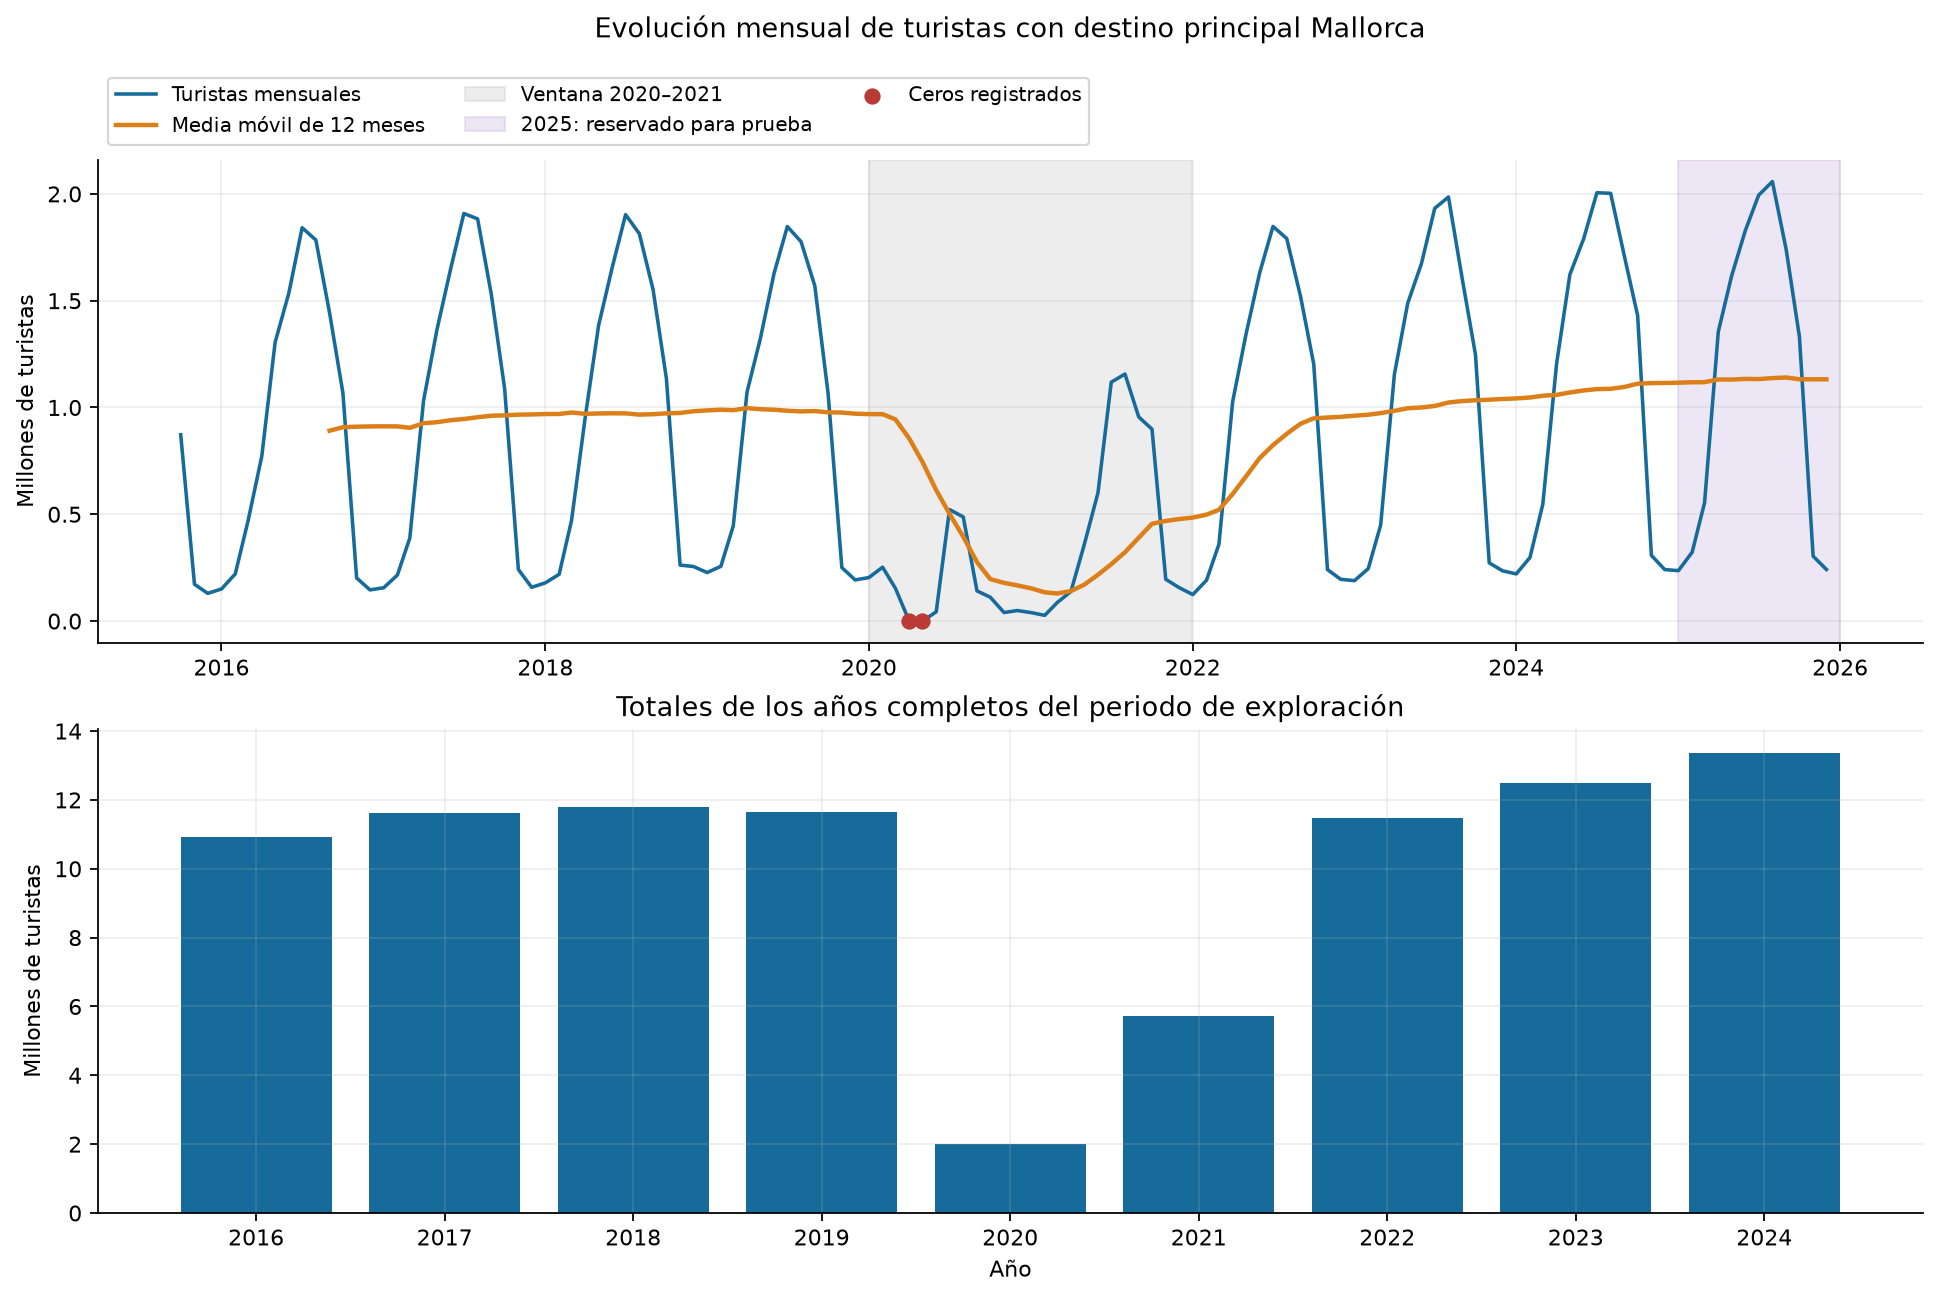

,meses_observados,turistas,variacion_anual_pct
año,,,
2016,12,10937186.0,NaN
2017,12,11609381.0,6.15
2018,12,11788998.0,1.55
2019,12,11651957.0,-1.16
2020,12,2004355.0,-82.80
2021,12,5730732.0,185.91
2022,12,11474346.0,100.22
2023,12,12477497.0,8.74
2024,12,13376944.0,7.21


**Lectura.** La serie combina oscilaciones dentro del año con una ruptura en 2020. En 2024 se registran **13,376,944 turistas**, un **14,8 % más** que en 2019. Los meses de 2015 no permiten calcular un total anual comparable. La media móvil se retrasa ante los cambios bruscos y no debe confundirse con una predicción.

In [13]:
annual = eda_train["turistas"].groupby(eda_train.index.year).agg(["count", "sum"])
annual = annual.loc[annual["count"].eq(12)].copy()
annual["variacion_anual_pct"] = annual["sum"].pct_change(fill_method=None) * 100
annual.index.name = "año"
annual = annual.rename(columns={"count": "meses_observados", "sum": "turistas"})
annual.to_csv(EDA_DIR / "turistas_anuales_hasta_2024.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(2, 1, figsize=(12, 8), constrained_layout=True)
axes[0].plot(eda.index, eda["turistas"] / 1e6, color="#176b9b", lw=1.6, label="Turistas mensuales")
axes[0].plot(eda.index, eda["turistas"].rolling(12, min_periods=12).mean() / 1e6,
             color="#dd7f19", lw=2, label="Media móvil de 12 meses")
axes[0].axvspan(pd.Timestamp("2020-01-01"), pd.Timestamp("2021-12-31"), color="#c5c5c5", alpha=.3, label="Ventana 2020–2021")
axes[0].axvspan(pd.Timestamp("2025-01-01"), pd.Timestamp("2025-12-31"), color="#af91d5", alpha=.22, label="2025: reservado para prueba")
zero_dates = eda.index[eda["turistas"].eq(0)]
axes[0].scatter(zero_dates, eda.loc[zero_dates, "turistas"], color="#ba3b36", s=40, zorder=5, label="Ceros registrados")
axes[0].set_ylabel("Millones de turistas")
axes[0].set_title("Evolución mensual de turistas con destino principal Mallorca", pad=55)
axes[0].legend(fontsize=9, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.01))
axes[1].bar(annual.index, annual["turistas"] / 1e6, color="#176b9b")
axes[1].set(title="Totales de los años completos del periodo de exploración", ylabel="Millones de turistas", xlabel="Año")
axes[1].set_xticks(annual.index)
save_show(fig, "01_evolucion_turistas.png")
display(annual.round(2))
display(Markdown(f"**Lectura.** La serie combina oscilaciones dentro del año con una ruptura en 2020. En 2024 se registran **{annual.loc[2024, 'turistas']:,.0f} turistas**, un **{pct_es((annual.loc[2024, 'turistas'] / annual.loc[2019, 'turistas'] - 1) * 100)} más** que en 2019. Los meses de 2015 no permiten calcular un total anual comparable. La media móvil se retrasa ante los cambios bruscos y no debe confundirse con una predicción."))

## 14. Estacionalidad mensual

Los diagramas de caja usan todos los meses del periodo de exploración, incluidos los de 2020–2021. El segundo panel compara medias de años completos anteriores a la pandemia (2016–2019) y posteriores a la ventana de interrupción (2022–2024). Cada mes dispone de cuatro y tres observaciones, respectivamente; estas muestras pequeñas permiten una lectura descriptiva, sin inferir diferencias estadísticamente significativas.

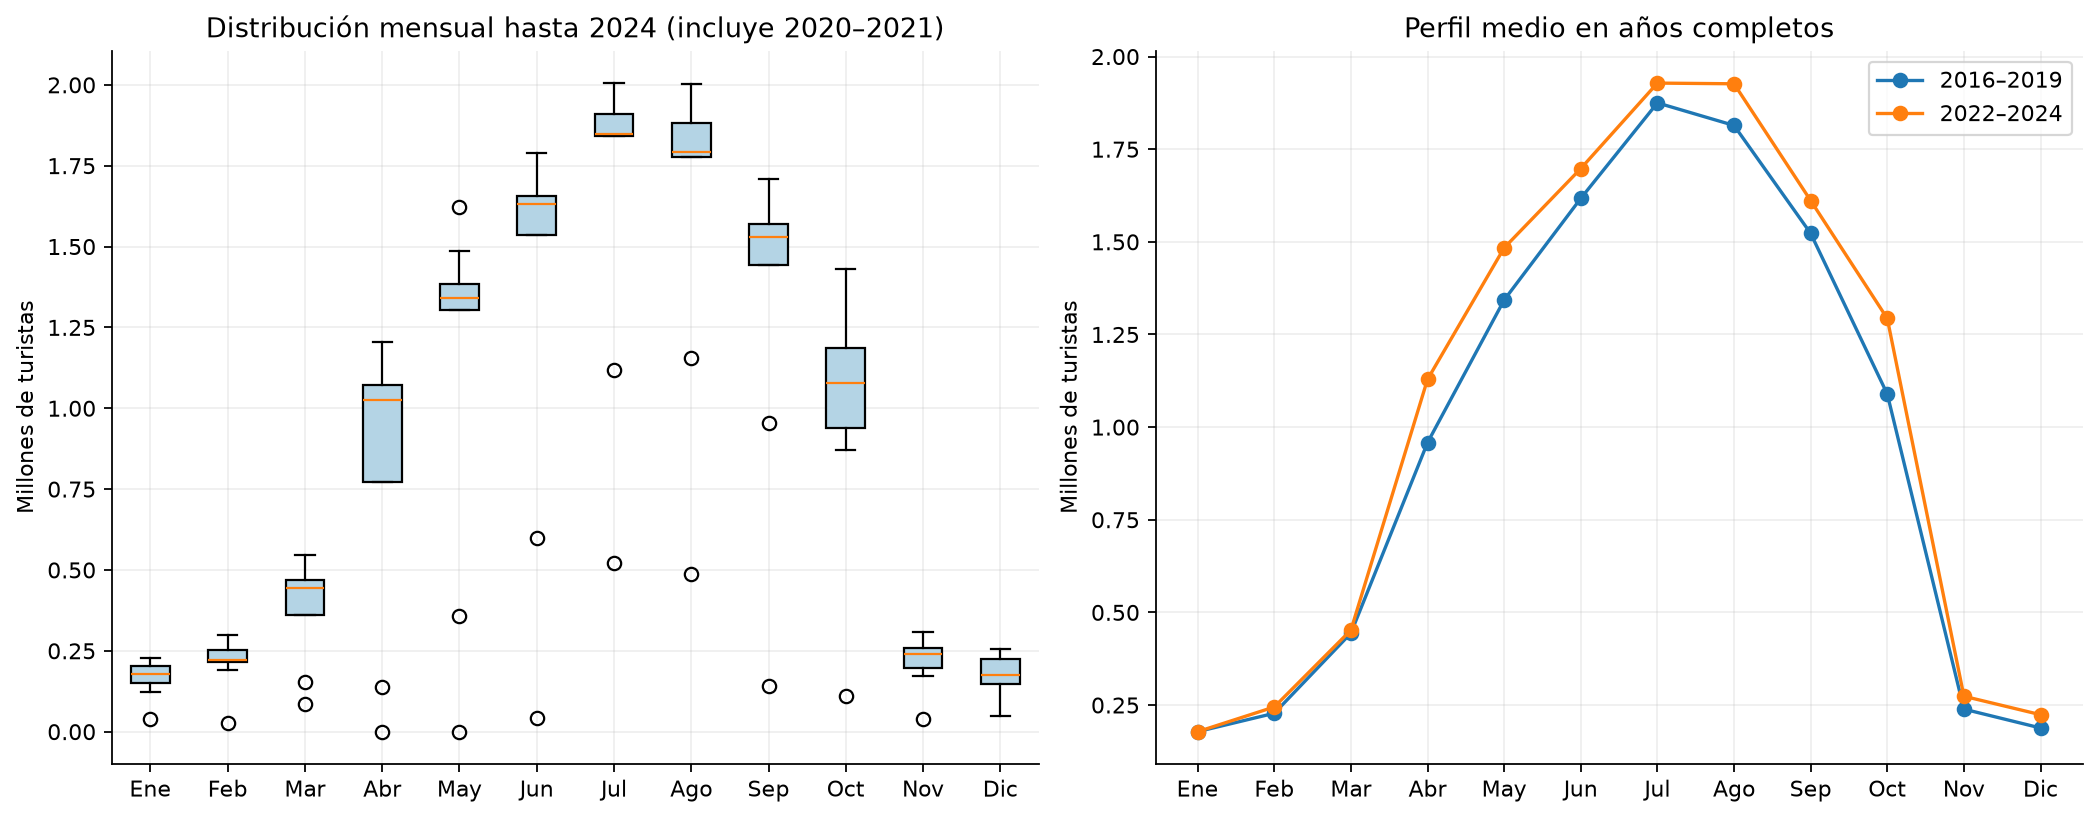

**Lectura.** En 2022–2024 el máximo medio se sitúa en **Jul** y los meses de junio a septiembre reúnen el **57,6 %** del total anual medio. Conviene representar el mes del año y contrastar un baseline estacional con retardo 12. Los valores bajos de 2020 tienen una explicación temporal: que aparezcan como atípicos en una caja no justifica eliminarlos.

In [14]:
profiles = pd.DataFrame({
    "media_2016_2019": eda_train.loc["2016":"2019", "turistas"].groupby(lambda d: d.month).mean(),
    "media_2022_2024": eda_train.loc["2022":"2024", "turistas"].groupby(lambda d: d.month).mean(),
})
profiles.index.name = "mes"
profiles["n_2016_2019"] = eda_train.loc["2016":"2019", "turistas"].groupby(lambda d: d.month).count()
profiles["n_2022_2024"] = eda_train.loc["2022":"2024", "turistas"].groupby(lambda d: d.month).count()
assert profiles["n_2016_2019"].eq(4).all() and profiles["n_2022_2024"].eq(3).all()
profiles.to_csv(EDA_DIR / "perfiles_mensuales.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
boxes = [eda_train.loc[eda_train.index.month == m, "turistas"].dropna().to_numpy() / 1e6 for m in range(1, 13)]
axes[0].boxplot(boxes, patch_artist=True, boxprops={"facecolor": "#b4d4e5"})
axes[0].set_xticks(range(1, 13), MONTHS)
axes[0].set(title="Distribución mensual hasta 2024 (incluye 2020–2021)", ylabel="Millones de turistas")
for col, label in [("media_2016_2019", "2016–2019"), ("media_2022_2024", "2022–2024")]:
    axes[1].plot(profiles.index, profiles[col] / 1e6, marker="o", label=label)
axes[1].set_xticks(range(1, 13), MONTHS)
axes[1].set(title="Perfil medio en años completos", ylabel="Millones de turistas")
axes[1].legend()
save_show(fig, "02_estacionalidad_mensual.png")
summer_share = profiles.loc[6:9, "media_2022_2024"].sum() / profiles["media_2022_2024"].sum() * 100
peak_month = int(profiles["media_2022_2024"].idxmax())
display(Markdown(f"**Lectura.** En 2022–2024 el máximo medio se sitúa en **{MONTHS[peak_month - 1]}** y los meses de junio a septiembre reúnen el **{pct_es(summer_share)}** del total anual medio. Conviene representar el mes del año y contrastar un baseline estacional con retardo 12. Los valores bajos de 2020 tienen una explicación temporal: que aparezcan como atípicos en una caja no justifica eliminarlos."))

## 15. Caída y recuperación tras la pandemia

El índice mensual divide los turistas de cada mes entre los del mismo mes de 2019 (2019 = 100). Se presenta hasta 2024. Un índice mayor que 100 indica que se supera ese mes de referencia; no implica que todos los meses o todos los indicadores se hayan recuperado. Los ceros de abril y mayo de 2020 se mantienen con su estado de fuente `U`.

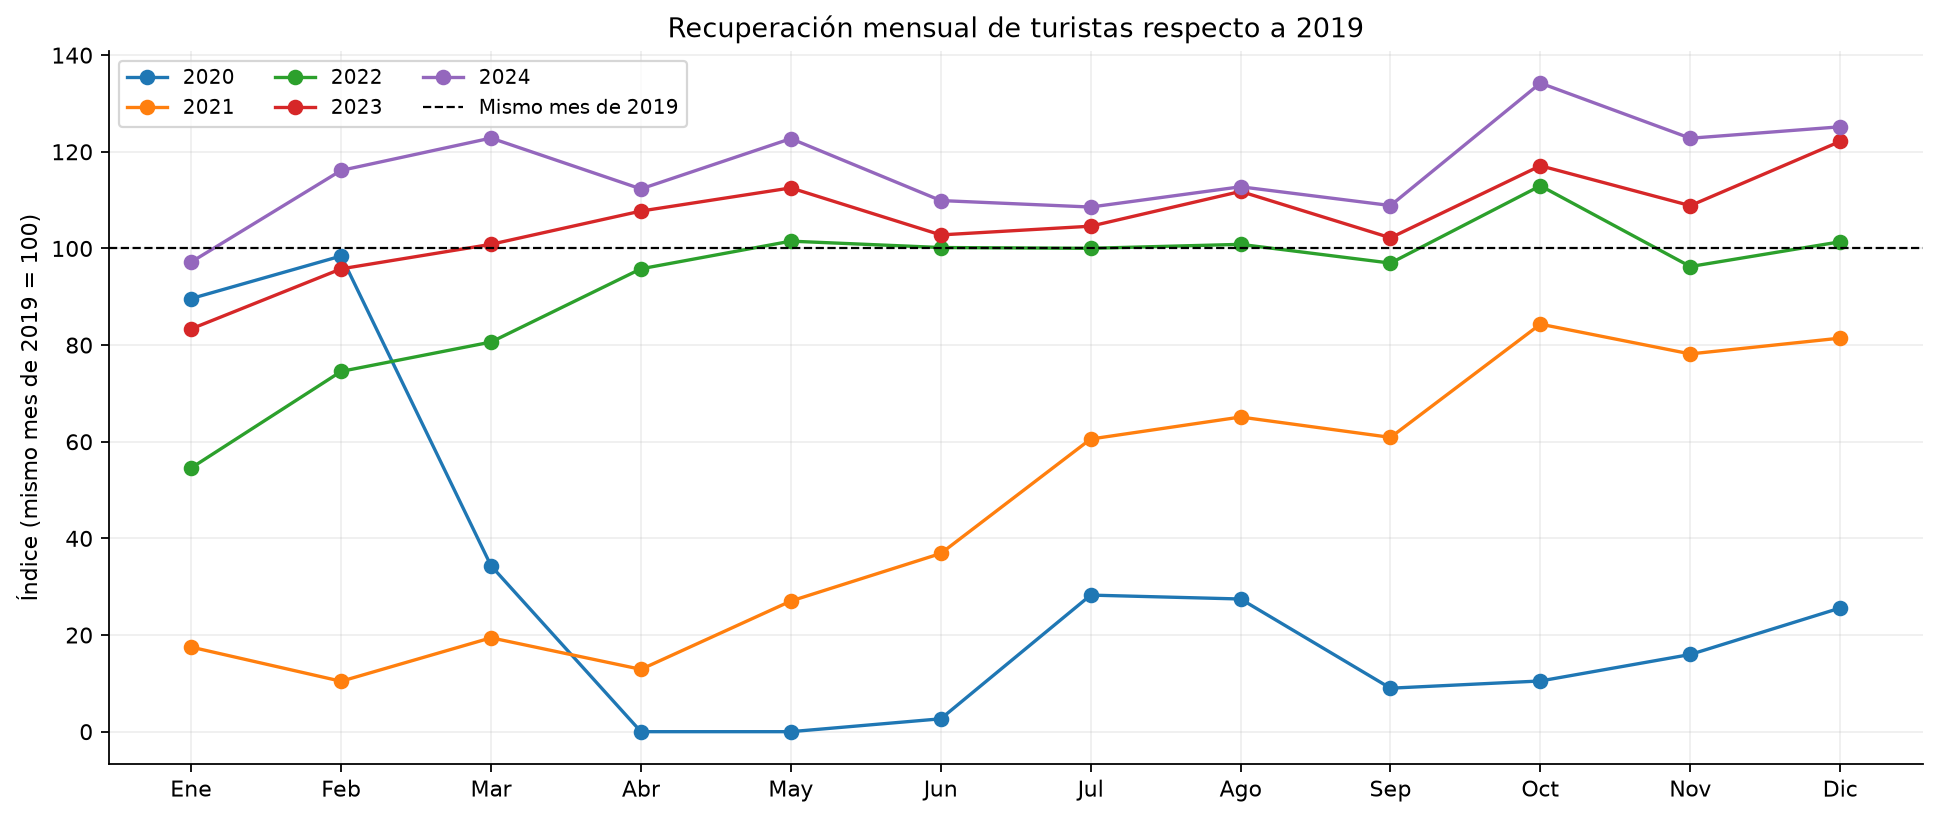

**Lectura.** El total de turistas de 2020 cae un **82,8 %** respecto a 2019. El primer año posterior a 2020 que iguala o supera el total de 2019 es **2023**. El gráfico permite comprobar qué meses explican la recuperación. Para preparar los datos interesa conservar la ruptura y evaluar después la sensibilidad a incluir 2020–2021, sin decidir a partir del rendimiento de 2025. Las métricas basadas en dividir por el valor real, como MAPE, requieren especial cuidado ante los meses con cero turistas.

In [15]:
reference_2019 = eda_train.loc["2019", "turistas"]
assert len(reference_2019) == 12 and reference_2019.gt(0).all()
reference_by_month = reference_2019.groupby(lambda d: d.month).first()
pandemic = eda_train.loc["2020":"2024", ["turistas"]].copy()
pandemic["turistas_2019_mismo_mes"] = pandemic.index.month.map(reference_by_month)
pandemic["indice_2019_100"] = pandemic["turistas"] / pandemic["turistas_2019_mismo_mes"] * 100
pandemic.to_csv(EDA_DIR / "recuperacion_mensual.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(12, 5), constrained_layout=True)
for year in range(2020, 2025):
    part = pandemic.loc[str(year)]
    ax.plot(part.index.month, part["indice_2019_100"], marker="o", label=str(year))
ax.axhline(100, color="black", ls="--", lw=1, label="Mismo mes de 2019")
ax.set_xticks(range(1, 13), MONTHS)
ax.set(title="Recuperación mensual de turistas respecto a 2019", ylabel="Índice (mismo mes de 2019 = 100)")
ax.legend(ncol=3, fontsize=9)
save_show(fig, "03_pandemia_recuperacion.png")
drop_2020 = (annual.loc[2020, "turistas"] / annual.loc[2019, "turistas"] - 1) * 100
recovered_years = annual.loc[2021:].index[annual.loc[2021:, "turistas"].ge(annual.loc[2019, "turistas"])]
first_recovery = int(recovered_years[0]) if len(recovered_years) else None
display(Markdown(f"**Lectura.** El total de turistas de 2020 cae un **{pct_es(abs(drop_2020))}** respecto a 2019. El primer año posterior a 2020 que iguala o supera el total de 2019 es **{first_recovery}**. El gráfico permite comprobar qué meses explican la recuperación. Para preparar los datos interesa conservar la ruptura y evaluar después la sensibilidad a incluir 2020–2021, sin decidir a partir del rendimiento de 2025. Las métricas basadas en dividir por el valor real, como MAPE, requieren especial cuidado ante los meses con cero turistas."))

## 16. Relación con el aeropuerto y la actividad hotelera

Se estudian relaciones contemporáneas hasta 2024. Los pasajeros de Palma incluyen movimientos de residentes y otras tipologías y no equivalen al número de turistas. Los viajeros hoteleros excluyen otras formas de alojamiento; las pernoctaciones cuentan noches, no personas. Por tanto, los indicadores se relacionan, pero no son intercambiables.

Se comparan las correlaciones de Pearson en niveles con las de las **diferencias interanuales** (`x_t − x_{t−12}`), calculadas sobre el calendario completo sin rellenar huecos. Esta segunda lectura reduce el patrón estacional compartido, aunque conserva efectos comunes como la pandemia. Se informa de los pares observados para cada coeficiente. No se seleccionan retardos ni variables mediante estas correlaciones.

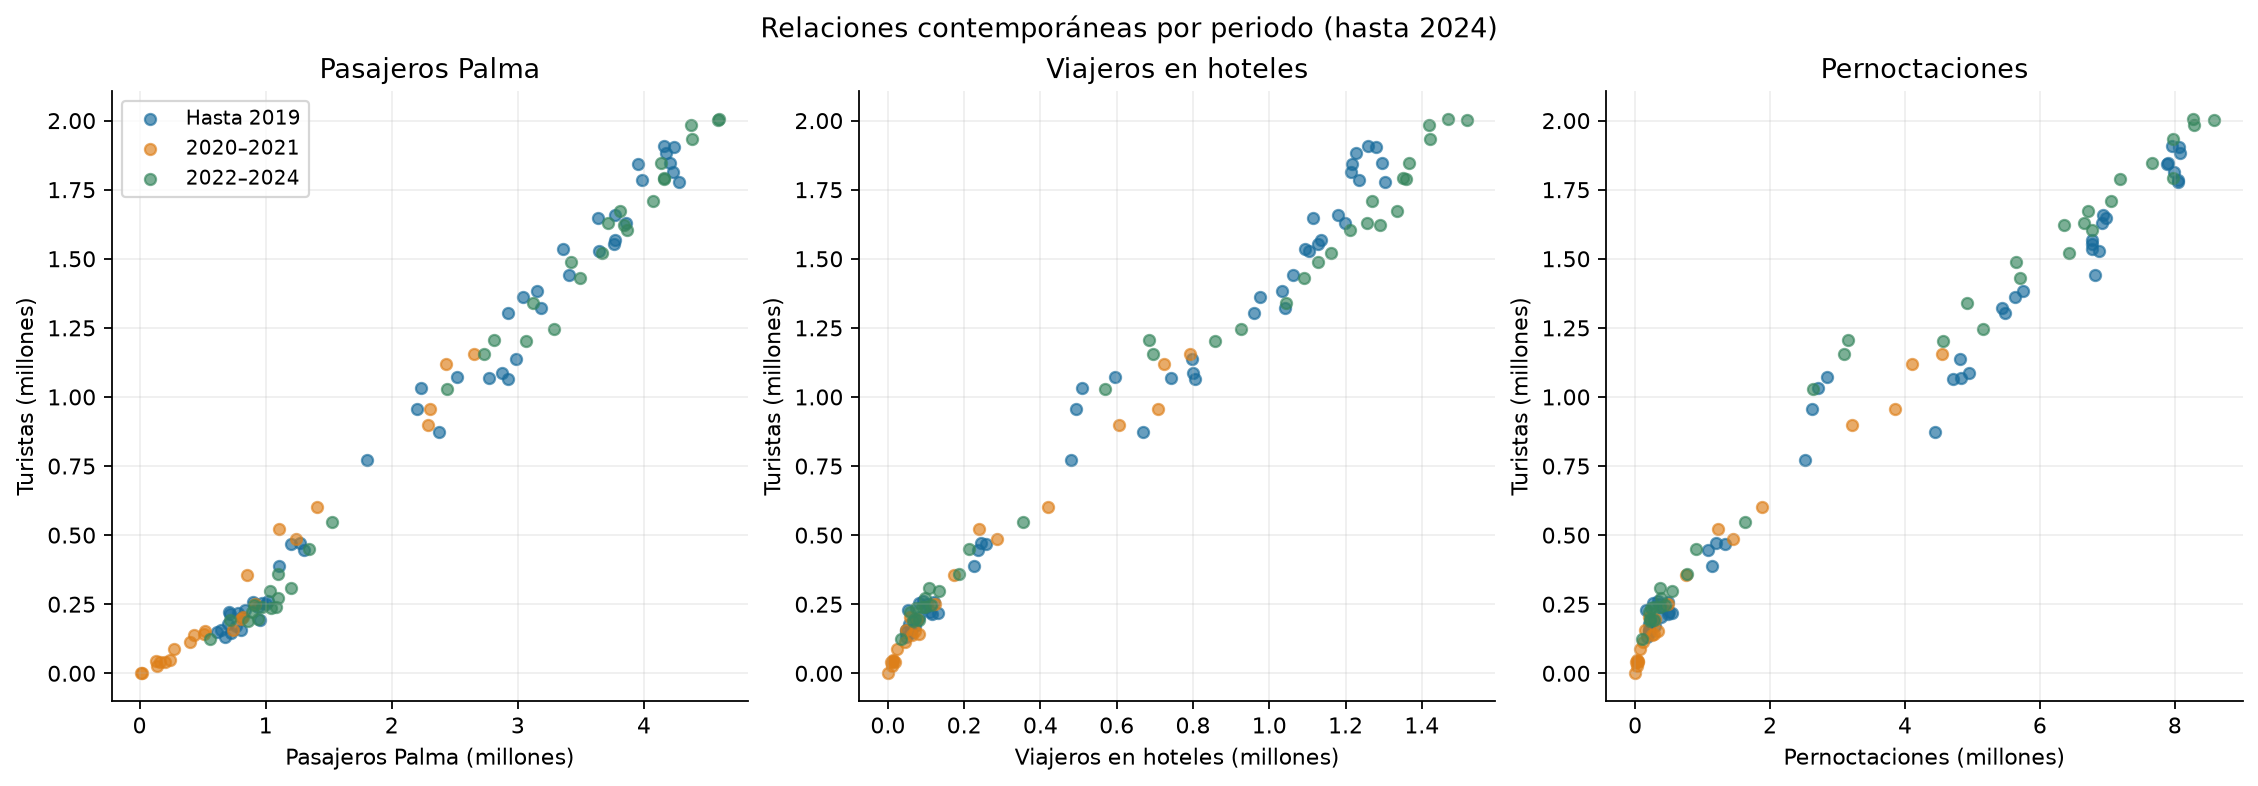

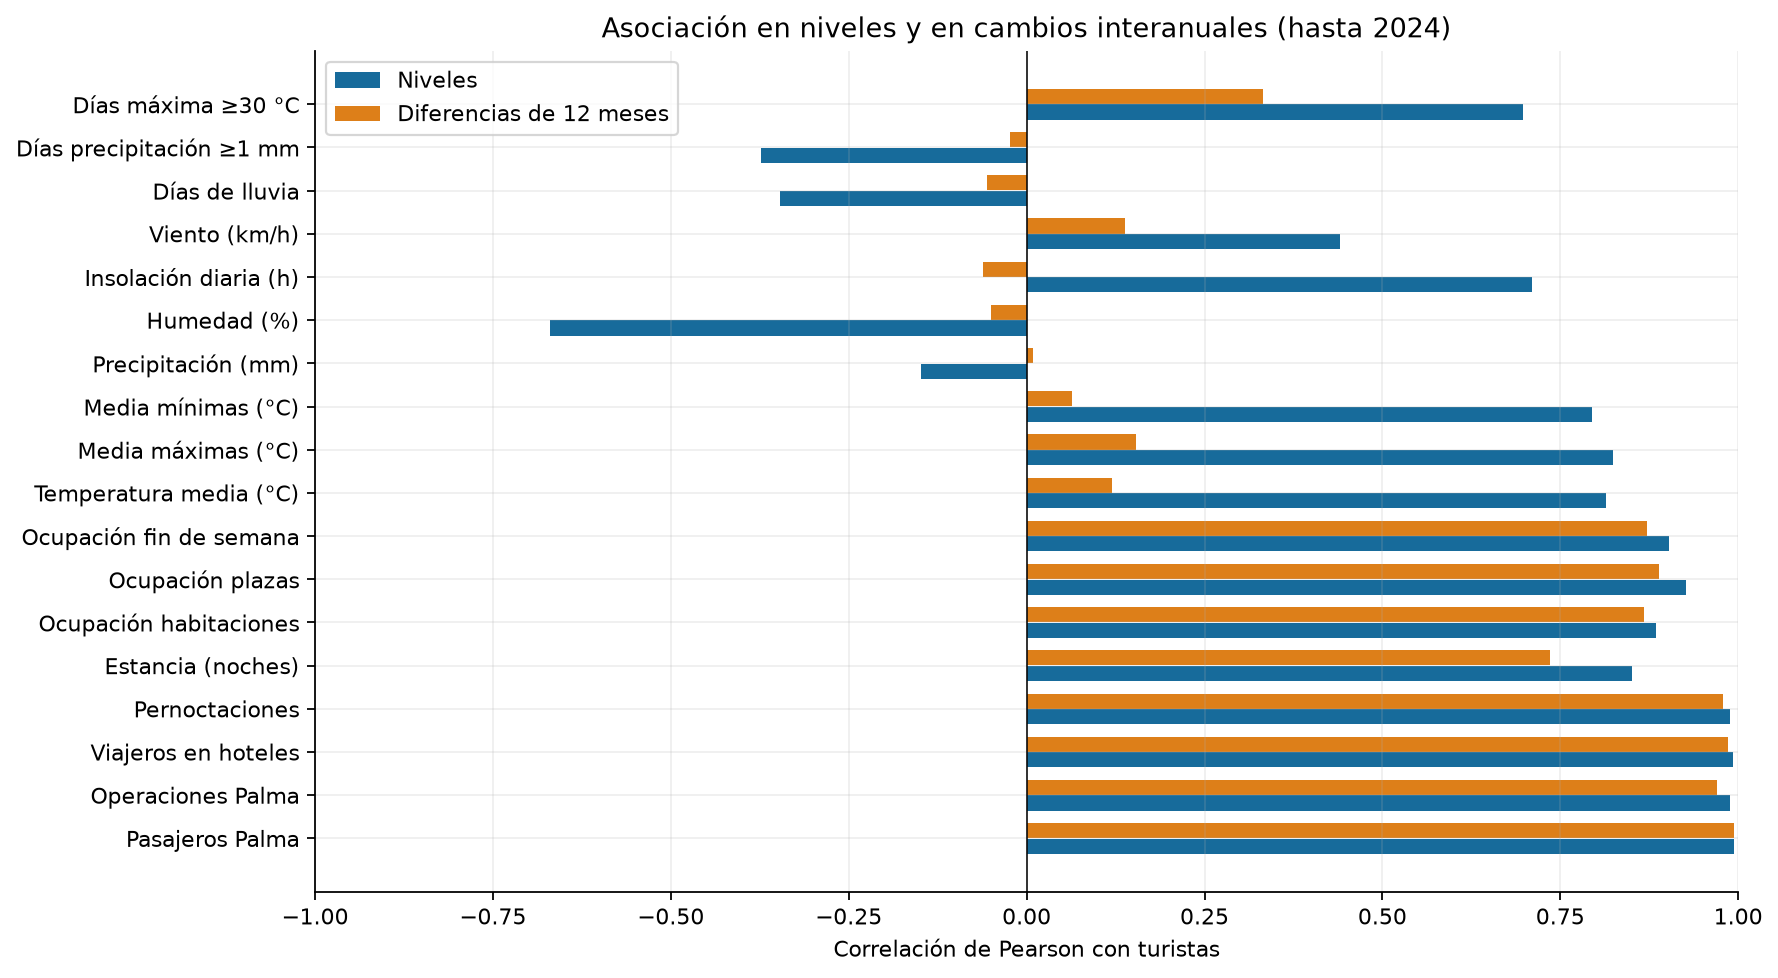

,pearson_niveles,pares_niveles,pearson_diferencia_12,pares_diferencia_12
variable,,,,
Pasajeros Palma,0.994,111,0.994,99
Operaciones Palma,0.988,111,0.970,99
Viajeros en hoteles,0.993,110,0.985,97
Pernoctaciones,0.989,110,0.978,97
Estancia (noches),0.851,109,0.735,95
Ocupación habitaciones,0.885,109,0.867,95
Ocupación plazas,0.926,109,0.888,95
Ocupación fin de semana,0.903,109,0.872,95
Temperatura media (°C),0.814,111,0.120,99


**Lectura.** La correlación de turistas con pasajeros de Palma es **0.994** en niveles y **0.994** en diferencias interanuales; con las pernoctaciones es **0.989** en niveles. La asociación describe movimientos compartidos, no el beneficio predictivo de añadir estas variables. Ese beneficio deberá medirse fuera de muestra con valores disponibles en cada fecha de predicción. La estancia media se deriva de pernoctaciones y viajeros, por lo que estas medidas tampoco aportan información completamente independiente.

In [16]:
external = [c for c in VALUE_COLUMNS if c != "turistas" and c not in GT_COLUMNS]
seasonal_diff = eda_train.diff(12)
correlations = pd.DataFrame(index=external)
for frame, suffix in [(eda_train, "niveles"), (seasonal_diff, "diferencia_12")]:
    correlations[f"pearson_{suffix}"] = [frame[["turistas", c]].corr().loc["turistas", c] for c in external]
    correlations[f"pares_{suffix}"] = [len(frame[["turistas", c]].dropna()) for c in external]
correlations.index.name = "variable"
correlations.to_csv(EDA_DIR / "correlaciones_turistas.csv", encoding="utf-8-sig")

fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), constrained_layout=True)
periods = [("2015-10", "2019-12", "Hasta 2019", "#176b9b"),
           ("2020-01", "2021-12", "2020–2021", "#dd7f19"),
           ("2022-01", "2024-12", "2022–2024", "#35855c")]
for ax, col in zip(axes, ["pasajeros_aena", "viajeros_hoteles", "pernoctaciones_hoteles"]):
    for start, end, label, color in periods:
        pair = eda_train.loc[start:end, ["turistas", col]].dropna()
        ax.scatter(pair[col] / 1e6, pair["turistas"] / 1e6, s=25, alpha=.65, color=color, label=label)
    ax.set(xlabel=LABELS[col] + " (millones)", ylabel="Turistas (millones)", title=LABELS[col])
axes[0].legend(fontsize=9)
fig.suptitle("Relaciones contemporáneas por periodo (hasta 2024)")
save_show(fig, "04_relaciones_aeropuerto_hoteles.png")

fig, ax = plt.subplots(figsize=(11, 6), constrained_layout=True)
positions = np.arange(len(external))
ax.barh(positions - .18, correlations["pearson_niveles"], height=.35, label="Niveles", color="#176b9b")
ax.barh(positions + .18, correlations["pearson_diferencia_12"], height=.35, label="Diferencias de 12 meses", color="#dd7f19")
ax.set_yticks(positions, [LABELS[c] for c in external])
ax.set(xlim=(-1, 1), xlabel="Correlación de Pearson con turistas", title="Asociación en niveles y en cambios interanuales (hasta 2024)")
ax.axvline(0, color="black", lw=.7)
ax.legend(loc="upper left")
save_show(fig, "05_correlaciones.png")
display(correlations.rename(index=LABELS).round(3))
air_r = correlations.loc["pasajeros_aena", "pearson_niveles"]
air_diff_r = correlations.loc["pasajeros_aena", "pearson_diferencia_12"]
hotel_r = correlations.loc["pernoctaciones_hoteles", "pearson_niveles"]
display(Markdown(f"**Lectura.** La correlación de turistas con pasajeros de Palma es **{air_r:.3f}** en niveles y **{air_diff_r:.3f}** en diferencias interanuales; con las pernoctaciones es **{hotel_r:.3f}** en niveles. La asociación describe movimientos compartidos, no el beneficio predictivo de añadir estas variables. Ese beneficio deberá medirse fuera de muestra con valores disponibles en cada fecha de predicción. La estancia media se deriva de pernoctaciones y viajeros, por lo que estas medidas tampoco aportan información completamente independiente."))

## 17. Ausentes, ceros y estados de calidad

El mapa distingue un dato numérico observado de un ausente (`NaN`): el cero es un valor observado. Los estados `U` y `P` se revisan aparte, ya que no convierten automáticamente un número en un ausente. En AENA el estado es común al informe mensual. Las tablas cubren todo el periodo para comprobar la calidad y muestran también los ausentes del conjunto de exploración.

### Decisión sobre los ceros y la ruptura de 2020

La revisión del 9 de octubre de 2026 identifica dos ceros en la variable objetivo: abril y mayo de 2020, el 1,6 % de los 123 meses. Ambos llevan estado `U` (baja fiabilidad según la documentación de origen). Coinciden con el episodio de restricciones pandémicas, pero su conservación no implica considerarlos recuentos exactos plenamente fiables. La serie de turistas no tiene valores ausentes.

| Variable | Meses con cero | Meses ausentes (`NaN`) |
|---|---|---|
| Turistas | Abril y mayo de 2020, ambos con `U` | Ninguno |
| Viajeros y pernoctaciones hoteleras | Abril de 2020 | Mayo de 2020 |
| Cada uno de los tres indicadores de ocupación | Abril de 2020 | Mayo y diciembre de 2020 |
| Estancia media en noches | Ninguno | Abril y mayo de 2020 |

Pasajeros, operaciones aeroportuarias y los cuatro índices de Google Trends no presentan ceros ni ausentes en este maestro. Estos recuentos corresponden a las descargas actuales y deberán comprobarse si se actualizan las fuentes.

**Tratamiento acordado.** El dataset maestro conserva los valores publicados, sus estados y el calendario mensual completo. No se eliminan abril y mayo ni se sustituyen sus ceros por promedios o interpolaciones. Suprimir filas y concatenar los meses restantes alteraría las distancias temporales y la interpretación de los retardos. Los ausentes hoteleros permanecen como `NaN`: no se convierten automáticamente en cero. La estancia media, en particular, puede no estar definida cuando no hay viajeros; debe comprobarse el motivo en la fuente antes de asignar un valor.

**Experimento principal y sensibilidad.** La configuración base conservará el episodio pandémico y las marcas de calidad para su auditoría. En validación anterior a 2025 se comparará con una alternativa de entrenamiento posterior a la pandemia. La fecha de inicio y la historia mínima se concretarán antes de la prueba final, atendiendo a la estacionalidad anual y al menor tamaño de la muestra. Ambas configuraciones se evaluarán en los mismos meses objetivo, por separado para h=1 y h=3, respetando la disponibilidad de cada predictor. No se elegirá el tratamiento a partir de los resultados de 2025. Esta comparación evalúa el efecto de cambiar el periodo de entrenamiento; no permite atribuir cualquier diferencia únicamente a los dos ceros.

**Ausentes hoteleros.** Antes del modelado se comprobará si cada hueco expresa falta de información, baja fiabilidad o imposibilidad de calcular el indicador. Si persiste, se documentará un tratamiento por variable dentro de cada partición de entrenamiento, sin utilizar datos posteriores al origen. La comparación con modelos basados solo en histórico y calendario permitirá comprobar si incorporar estas fuentes aporta una mejora. La mediana por entrenamiento con indicadores de ausencia se implementa en el apartado 31 como regla inicial para los predictores hoteleros.

**Métricas.** MAE y RMSE serán las medidas principales en la escala original de turistas. MAPE no se utilizará como criterio principal porque divide por el valor observado y es indefinido cuando este es cero; tampoco se reemplazarán ceros por cantidades arbitrarias para poder calcularlo. Si se incorpora MASE, su denominador estacional se calculará únicamente con el entrenamiento de cada partición y se comprobará que sea distinto de cero.

**Relación con los antecedentes.** Perú (Pinedo et al., 2026) empieza en 2022 y excluye 2020–2021 mediante el periodo elegido. Austria (Reichold, 2026) incluye la pandemia en la comparación principal y ensaya ajustes retrospectivos en robustez. Reino Unido (Dimitriadou et al., 2026) declara una muestra hasta febrero de 2020, y el TFG de Mallorca (Ramos Hoogwout, 2020) estima con datos hasta diciembre de 2019. Ninguno justifica eliminar nuestros dos ceros simplemente por su escasa frecuencia. El detalle y las reservas de estos estudios están recogidos en `docs/revision_bibliografica/estudios.md` y en las fichas de apoyo.

Como fundamento metodológico, Hyndman y Athanasopoulos explican que las observaciones excepcionales deben interpretarse antes de sustituirlas y que los errores porcentuales no están definidos con objetivos iguales a cero: [tratamiento de observaciones excepcionales y ausentes](https://otexts.com/fpp3/missing-outliers.html) y [evaluación de pronósticos](https://otexts.com/fpp3/accuracy.html).

La decisión queda documentada; el tratamiento de los ausentes hoteleros se implementa en el apartado 31 y la comparación de sensibilidad predictiva sigue pendiente. El maestro conserva sus valores originales.


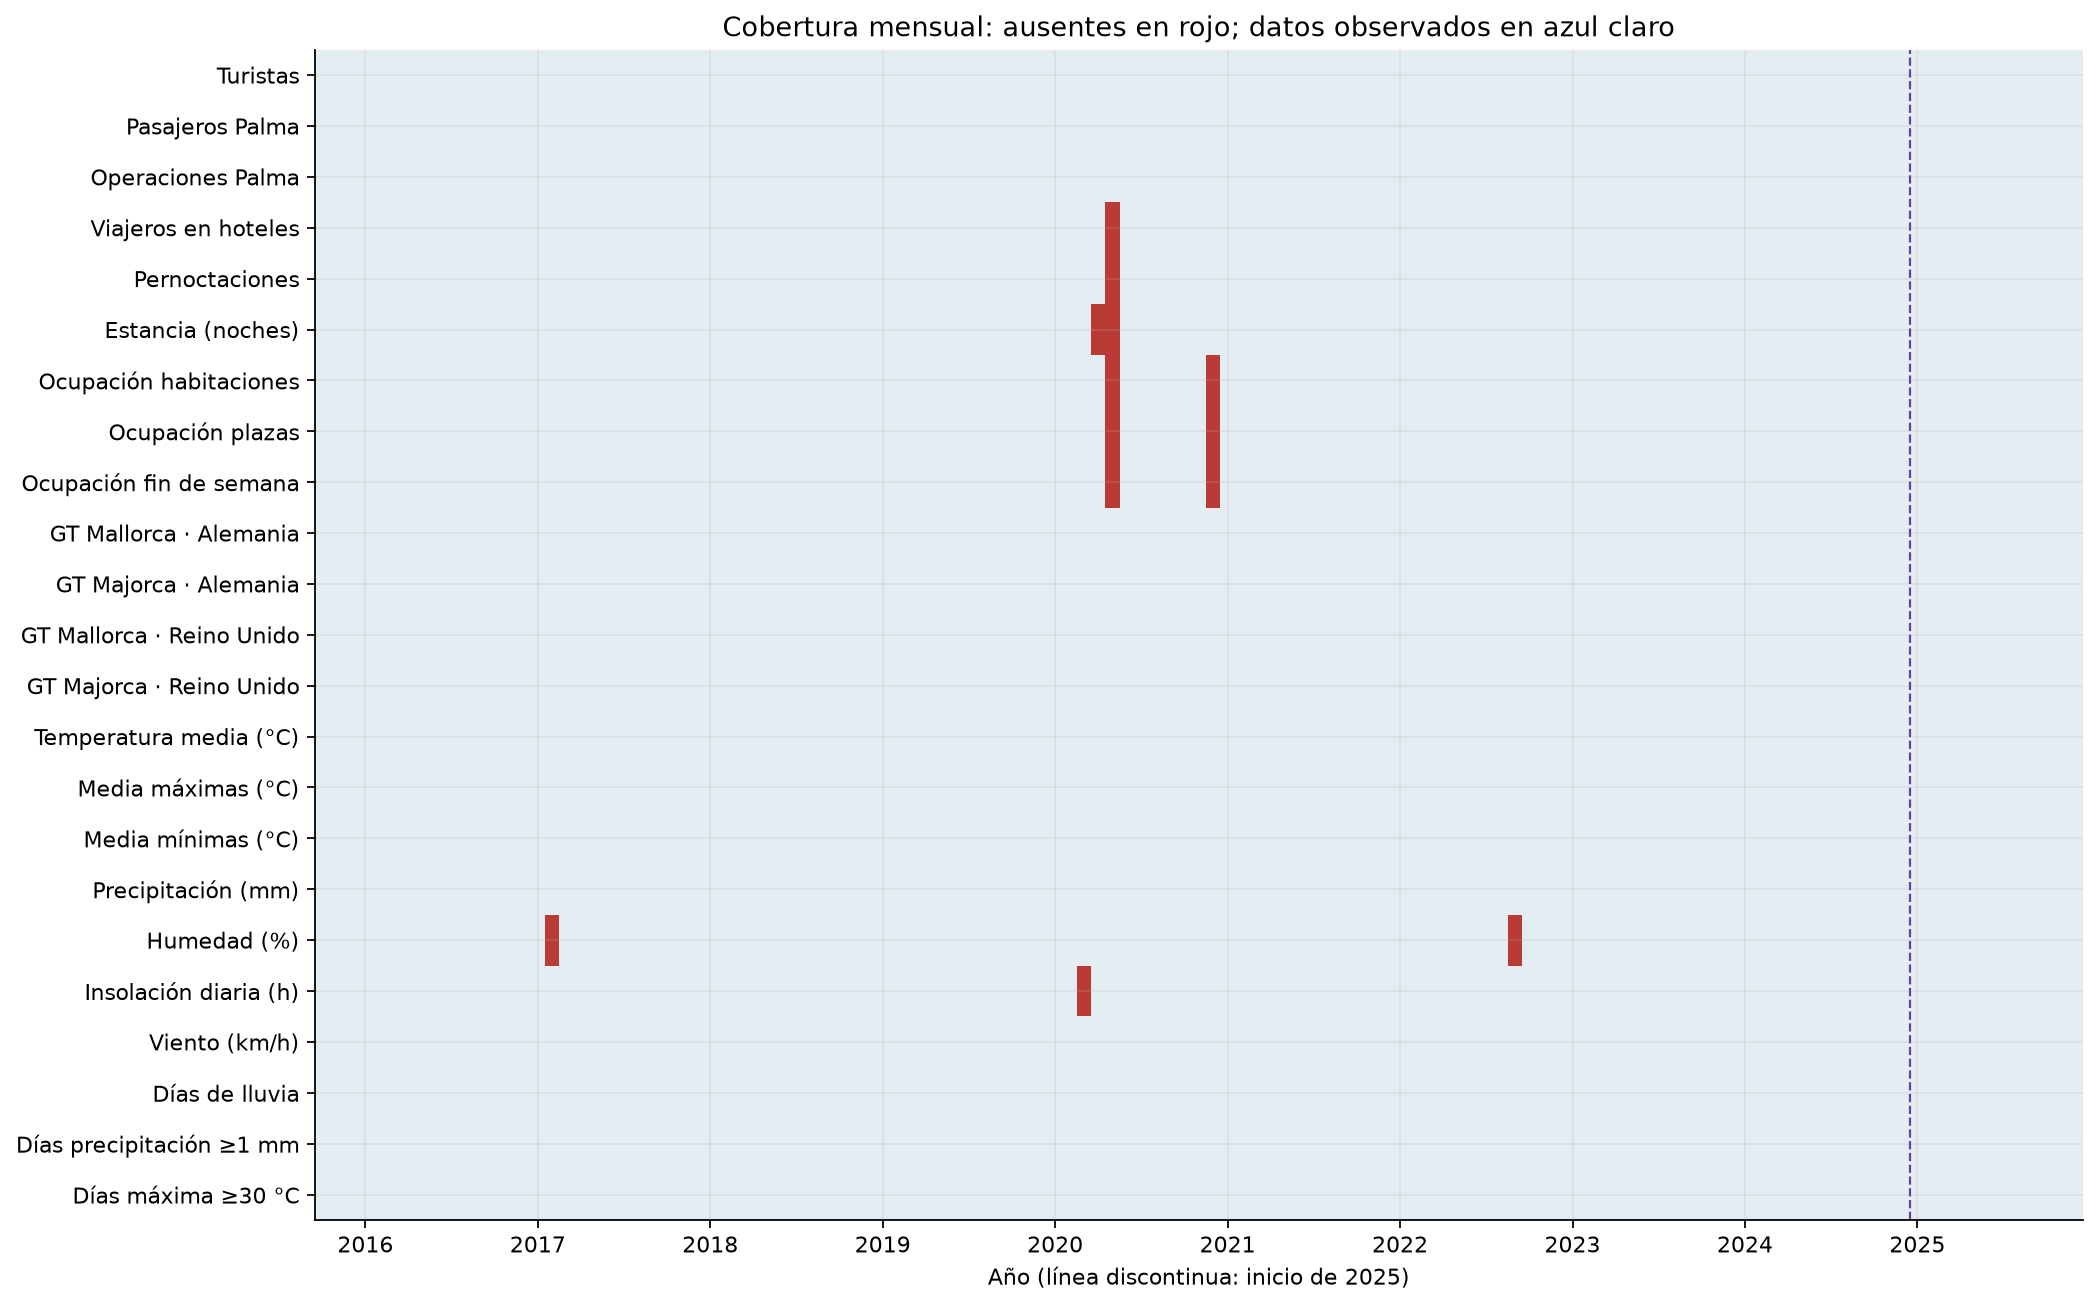

,observados,ausentes_total,ausentes_hasta_2024,ceros,estado_U,estado_P_o_provisional
variable,,,,,,
Turistas,123,0,0,2,2,0
Pasajeros Palma,123,0,0,0,0,12
Operaciones Palma,123,0,0,0,0,12
Viajeros en hoteles,122,1,1,1,1,12
Pernoctaciones,122,1,1,1,1,12
Estancia (noches),121,2,2,0,2,12
Ocupación habitaciones,121,2,2,1,2,7
Ocupación plazas,121,2,2,1,2,7
Ocupación fin de semana,121,2,2,1,2,7


,fecha,variable,estado
0,2020-05-01,viajeros_hoteles,U
1,2020-05-01,pernoctaciones_hoteles,U
2,2020-04-01,estancia_media_noches,U
3,2020-05-01,estancia_media_noches,U
4,2020-05-01,ocupacion_habitaciones_pct,U
5,2020-12-01,ocupacion_habitaciones_pct,U
6,2020-05-01,ocupacion_plazas_pct,U
7,2020-12-01,ocupacion_plazas_pct,U
8,2020-05-01,ocupacion_fin_semana_pct,U
9,2020-12-01,ocupacion_fin_semana_pct,U


,turistas,turistas_estado,viajeros_hoteles,pernoctaciones_hoteles
fecha,,,,
2020-04-01,0.0,U,0.0,0.0
2020-05-01,0.0,U,NaN,NaN


**Lectura.** No hay ausentes en turistas ni en los indicadores de AENA. En mayo de 2020 faltan viajeros y pernoctaciones; la estancia media falta en abril y mayo de 2020, y los tres indicadores de ocupación, en mayo y diciembre de 2020. No se deben convertir esos huecos en ceros ni interpolarlos sin estudiar su contexto. Los ceros de turistas de abril y mayo de 2020 se conservan y quedan identificados con estado `U`. Los informes de AENA de 2025 figuran como provisionales: debe registrarse la versión utilizada en la evaluación final.

In [17]:
missing_review = []
for col in VALUE_COLUMNS:
    state_col = "aena_estado" if col in ["pasajeros_aena", "operaciones_aena"] else col + "_estado"
    counts = eda[state_col].value_counts() if state_col in eda else pd.Series(dtype=int)
    missing_review.append({"variable": col, "observados": int(eda[col].count()),
        "ausentes_total": int(eda[col].isna().sum()), "ausentes_hasta_2024": int(eda_train[col].isna().sum()),
        "ceros": int(eda[col].eq(0).sum()), "estado_U": int(counts.get("U", 0)),
        "estado_P_o_provisional": int(counts.get("P", 0) + counts.get("provisional", 0))})
missing_review = pd.DataFrame(missing_review).set_index("variable")
missing_review.to_csv(EDA_DIR / "revision_ausentes_ceros_estados.csv", encoding="utf-8-sig")
fig, ax = plt.subplots(figsize=(13, max(6.5, len(VALUE_COLUMNS)*.35)), constrained_layout=True)
im = ax.imshow(eda[VALUE_COLUMNS].isna().T.to_numpy().astype(int),
               aspect="auto", interpolation="nearest", cmap=ListedColormap(["#e4edf2", "#ba3b36"]), vmin=0, vmax=1)
ticks = [i for i, d in enumerate(eda.index) if d.month == 1]
ax.set_xticks(ticks, [str(eda.index[i].year) for i in ticks])
ax.set_yticks(range(len(VALUE_COLUMNS)), [LABELS[c] for c in VALUE_COLUMNS])
ax.axvline(eda.index.get_loc(pd.Timestamp("2025-01-01")) - .5, color="#68439b", ls="--", lw=1)
ax.set(title="Cobertura mensual: ausentes en rojo; datos observados en azul claro", xlabel="Año (línea discontinua: inicio de 2025)")
save_show(fig, "06_mapa_ausentes.png")
display(missing_review.rename(index=LABELS))
display(missing_details)
zero_review = eda.loc[eda["turistas"].eq(0), ["turistas", "turistas_estado", "viajeros_hoteles", "pernoctaciones_hoteles"]]
display(zero_review)
assert eda["turistas"].notna().all() and eda["pasajeros_aena"].notna().all()
display(Markdown("**Lectura.** No hay ausentes en turistas ni en los indicadores de AENA. En mayo de 2020 faltan viajeros y pernoctaciones; la estancia media falta en abril y mayo de 2020, y los tres indicadores de ocupación, en mayo y diciembre de 2020. No se deben convertir esos huecos en ceros ni interpolarlos sin estudiar su contexto. Los ceros de turistas de abril y mayo de 2020 se conservan y quedan identificados con estado `U`. Los informes de AENA de 2025 figuran como provisionales: debe registrarse la versión utilizada en la evaluación final."))

## 18. Conclusiones para la preparación de datos

1. **Mantener el calendario mensual completo.** La variable objetivo y el aeropuerto cubren los 123 meses. Eliminar filas por los ausentes hoteleros rompería la regularidad de la serie y los retardos de doce meses. Los meses iniciales sin historia suficiente para construir retardos se tratarán después como pérdida de contexto, no como errores del ETL.
2. **Representar la estacionalidad y comprobarla fuera de muestra.** El perfil mensual justifica contrastar Seasonal Naive y modelos con componente estacional. Para aprendizaje automático se pueden preparar mes del año, retardos del objetivo y resúmenes móviles calculados con `shift(1)`. Sus ventanas y parámetros se elegirán en validación temporal anterior a 2025.
3. **Conservar y documentar la ruptura de 2020.** Los ceros de abril y mayo de 2020 no son huecos y llevan estado `U`, por lo que su precisión es limitada. Se conservarán en el maestro y en la configuración base. En validación anterior a 2025 se comparará con un entrenamiento posterior a la pandemia sobre los mismos meses objetivo, según la decisión documentada en el apartado 17. Cualquier indicador de restricciones requiere fechas verificables y una regla de disponibilidad; no debe inventarse a partir del descenso observado ni prolongarse al futuro sin justificación.
4. **Tratar los ausentes por variable y dentro de cada partición.** Los huecos hoteleros se concentran en meses de pandemia. Humedad e insolación meteorológicas también presentan tres huecos, en 2017, 2020 y 2022, que se conservan sin imputar. Primero se debe consultar la fuente y documentar si representan falta de información o imposibilidad de estimar la medida. Si persisten, comparar un modelo solo con objetivo y calendario con modelos que incorporen variables externas y un tratamiento aprendido únicamente con entrenamiento. Evitar interpolaciones que utilicen meses posteriores a la fecha pronosticada.
5. **Alinear las variables externas con su disponibilidad real.** La correlación contemporánea no permite utilizar pasajeros, ocupación o pernoctaciones del mes que se intenta predecir. Antes del modelado se deben fijar horizontes y retardos de publicación, y construir una tabla de información disponible en cada origen de predicción. Las series descargadas no reconstruyen las versiones históricas: la evaluación será retrospectiva y esta limitación debe explicarse.
6. **No confundir medidas ni duplicar información sin evaluarla.** Pasajeros, viajeros hoteleros y turistas representan poblaciones diferentes. Pernoctaciones y estancia media están relacionadas con viajeros; se contrastará su aportación mediante validación temporal, no solo por correlaciones altas. Escalado, imputación y selección de variables se ajustarán en cada partición de entrenamiento.
7. **Cerrar pendientes antes de consolidar el dataset de modelos.** La meteorología ya está integrada; falta evaluar su aportación predictiva y acreditar la primera publicación mensual si se requiere una reconstrucción operativa estricta. Mantener los estados de calidad y la versión de los archivos; justificar las métricas ante los ceros del objetivo y reservar 2025 para la comparación final. El EDA termina aquí: no se han imputado valores, ajustado modelos ni elegido hiperparámetros.

Las figuras y tablas de este bloque se regeneran en `outputs/eda/`. Los resultados numéricos comentados se calculan al ejecutar el notebook, para que no queden desvinculados de las fuentes.

In [18]:
eda_metadata = {
    "periodo_descriptivo": [str(eda.index.min().date()), str(eda.index.max().date())],
    "periodo_relaciones": [str(eda_train.index.min().date()), str(eda_train.index.max().date())],
    "meses_exploracion": len(eda_train), "meses_prueba_reservados": 12,
    "referencia_recuperacion": 2019, "ventana_interrupcion_descriptiva": [2020, 2021],
    "imputacion": "no realizada", "modelos": "no ajustados", "aemet": "B278 integrada; huecos preservados; exploracion meteorologica en bloque final",
    "correlaciones": "Pearson por pares completos, niveles y diferencias de 12 meses",
    "python": platform.python_version(),
    "dependencias": {p: importlib.metadata.version(p) for p in ["pandas", "numpy", "matplotlib"]},
    "dataset_sha256": hashlib.sha256((OUTPUT_DIR / "dataset_maestro_mallorca.csv").read_bytes()).hexdigest(),
    "figuras": figures,
}
(EDA_DIR / "ejecucion.json").write_text(json.dumps(eda_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
assert eda[VALUE_COLUMNS].equals(master[VALUE_COLUMNS])
print(f"EDA completado: {len(figures)} figuras y 5 tablas; datos originales del maestro conservados.")
print("Salidas:", EDA_DIR)

EDA completado: 6 figuras y 5 tablas; datos originales del maestro conservados.
Salidas: C:\Users\acort\Documents\Codex\tfm-turismo-mallorca\outputs\eda


## 19. Disponibilidad de los predictores y decisión sobre retardos

**Fecha de comprobación: 8 de octubre de 2026; ampliación de AEMET: 9 de octubre de 2026.** Se fija el origen de pronóstico al cierre del último día natural de cada mes `t`, en hora de Mallorca. Se pronostica el total mensual de turistas de `t+1` y `t+3`. El cierre del mes no hace que sus estadísticas ya estén publicadas. Por ejemplo, al cierre de enero no se pueden usar los pasajeros ni los hoteles de enero.

La revisión de fuentes da lugar a una **política mensual de disponibilidad**, distinta de la elección de retardos predictivos. El desfase operativo es el mínimo impuesto por la política, que distingue evidencia de supuestos; los retardos adicionales se seleccionarán en validación anterior a 2025.

| Grupo | Evidencia sobre publicación | Último mes utilizable al cierre de t | Retardo mínimo respecto al mes objetivo: h=1 / h=3 |
|---|---|---|---|
| Pasajeros y operaciones AENA Palma | Enero de 2025 se difundió el 12 de febrero de 2025. Febrero de 2026 se difundió el 12 de marzo. Son ejemplos efectivos, no una garantía de publicación siempre el día 12. | t−1 | 2 / 4 meses |
| Viajeros, pernoctaciones, estancia media y las tres ocupaciones de IBESTAT | El calendario oficial de 2025 programa la EOH en el mes siguiente al de referencia; las fechas previstas van del 21 al 25. El INE describe unos 23 días para las cifras provisionales. | t−1 | 2 / 4 meses |
| Histórico de turistas IBESTAT, utilizado como predictor y para entrenar | El calendario oficial de 2025 programa el flujo turístico con dos meses de desfase. La noticia de IBESTAT del 2 de octubre de 2026 publica agosto de 2026, incluyendo turistas nacionales e internacionales. | t−2 | 3 / 5 meses |
| Mes, año y demás calendario conocido | El calendario del mes objetivo se conoce al emitir el pronóstico. | Mes objetivo | Sin espera de publicación |
| Meteorología mensual AEMET | Plazo de primera publicación no acreditado; se adopta un supuesto experimental, explicado en el bloque 40. | t−2 base; t−3 sensibilidad | 3 / 5 meses en la base; 4 / 6 en sensibilidad |

### Fuentes contrastadas

- [AENA Palma, enero de 2025, publicación del 12 de febrero](https://www.aena.es/es/prensa/el-aeropuerto-de-palma-de-mallorca-registra-durante-el-primer-mes-de-2025---mas-de-900.000-pasajeros.html%26p%3D1575078740846).
- [AENA Palma, febrero de 2026, publicación del 12 de marzo](https://www.aena.es/doc/detalleprensa/260312-pmi-estadisticas-febrero.pdf).
- [Programa anual de estadística de IBESTAT 2025](https://ibestat.es/wp-content/uploads/2025/01/programa_2025_castella.pdf), calendario del IBESTAT, página 158 del PDF (página 2765 del BOIB). La columna indica el mes de difusión; dentro de la celda figuran el día de difusión y el periodo de referencia. Las fechas son previstas y el estado P corresponde a datos provisionales. La celda de noviembre para flujo turístico contiene un día 31, inválido para noviembre: no se utiliza como una fecha válida ni se corrige por suposición.
- [Informe metodológico del INE sobre EOH](https://www.ine.es/dynt3/metadatos/es/RespuestaDatos.htm?oe=30235), apartados 14 y 17: oportunidad y revisiones. [Publicación efectiva de enero de 2025, el 25 de febrero](https://www.ine.es/dyngs/Prensa/CTH0125.htm) y [diciembre de 2025, el 26 de enero de 2026](https://www.ine.es/dyngs/Prensa/CTH1225.htm). Las fechas del INE sirven de contraste, pero no se atribuyen a la publicación de nuestros cubos de IBESTAT.
- [Noticia de IBESTAT para agosto de 2026](https://ibestat.es/turistes-amb-destinacio-principal-a-les-illes-balears-frontur-agost-2026/?lang=ca) y [página de IBESTAT con su fecha 02/10/2026](https://ibestat.es/). [FRONTUR del INE de enero de 2025, difundido el 4 de marzo](https://www.ine.es/dyngs/Prensa/FRONTUR0125.htm) confirma el patrón nacional, pero cubre turistas internacionales y no sustituye a la variable objetivo insular de este trabajo.

### Qué se ha comprobado y qué se está suponiendo

Se han contrastado el calendario autonómico de 2025, la metodología hotelera y ejemplos de difusión efectiva. **No se ha reconstruido la primera publicación de cada observación de 2015–2025**, ni las versiones de los valores disponibles en cada fecha histórica. Aplicar estos desfases a todo el histórico es una simulación retrospectiva bajo una regla explícita, no una reproducción exacta de lo que se sabía entonces.

En ausencia de una fecha efectiva comprobada, la fecha operativa se fija al último día del mes de difusión supuesto: un mes después para AENA y hoteles y dos después para turistas y meteorología; en esta última, el plazo es un supuesto no verificado. Es conservadora dentro de ese mes, pero no garantiza que nunca haya existido una publicación excepcionalmente tardía. Una fecha comprobada posterior prevalecerá y bloqueará el dato hasta entonces. Como sensibilidad se retrasarán todos los grupos un mes adicional, sin decidir esa comprobación mediante los resultados de 2025. La tabla de evidencia separa fechas efectivas de fechas previstas.

Los Excel descargados contienen revisiones y algunos informes AENA son definitivos. Con retrasar su periodo de referencia no se reconstruye el valor provisional original: seguirá existiendo una limitación por revisiones. Las fechas de modificación de los archivos y los estados A/P/U no son fechas de primera publicación. Una marca de calidad también debe vincularse a la versión de fuente si se utiliza como predictor.

In [19]:
AVAIL_DIR = PROJECT_ROOT / "outputs" / "disponibilidad"
AVAIL_DIR.mkdir(parents=True, exist_ok=True)
GROUP_VARIABLES = {
    "aena": ["pasajeros_aena", "operaciones_aena"],
    "hoteles": ["viajeros_hoteles", "pernoctaciones_hoteles", "estancia_media_noches",
                "ocupacion_habitaciones_pct", "ocupacion_plazas_pct", "ocupacion_fin_semana_pct"],
    "turistas": ["turistas"],
    "google_trends": GT_COLUMNS,
    "meteorologia": METEO_COLUMNS,
}
PUBLICATION_DELAYS = {"aena": 1, "hoteles": 1, "turistas": 2, "google_trends": 1, "meteorologia": 2}
availability_policy = {
    "fecha_revision": "2026-10-09", "origen": "cierre del mes t, Europe/Madrid",
    "horizontes": [1, 3], "desfases_publicacion_meses": PUBLICATION_DELAYS,
    "fecha_operativa_sin_verificar": "ultimo dia del mes de difusion supuesto",
    "alcance": "simulacion retrospectiva; primeras versiones no reconstruidas",
    "sensibilidad": "un mes adicional de espera en todos los grupos",
    "meteorologia": "t-2 base y t-3 sensibilidad; supuesto de simulacion, primera publicacion mensual no verificada",
    "meteorologia_versiones": "observaciones mensuales revisadas descargadas en 2026; no son pronosticos meteorologicos",
    "meteorologia_evidencia": "actualizacion diaria del producto no demuestra retraso de publicacion; FAQ diaria no extrapolable a mensual",
    "google_trends": "t-1 por cautela operativa; supuesto, no plazo de publicación verificado",
    "google_trends_versiones": "CSV retrospectivos normalizados en 2015-2025; versiones por origen no reconstruidas",
}
(AVAIL_DIR / "politica.json").write_text(json.dumps(availability_policy, ensure_ascii=False, indent=2), encoding="utf-8")

# La evidencia se registra por operación, no como una fecha real de cada cubo.
evidence = [
    {"grupo": "aena", "entidad": "AENA Palma", "mes_referencia": "2025-01-01", "fecha": "2025-02-12", "tipo": "difusion_efectiva_nota", "url": "https://www.aena.es/es/prensa/el-aeropuerto-de-palma-de-mallorca-registra-durante-el-primer-mes-de-2025---mas-de-900.000-pasajeros.html%26p%3D1575078740846"},
    {"grupo": "aena", "entidad": "AENA Palma", "mes_referencia": "2026-02-01", "fecha": "2026-03-12", "tipo": "difusion_efectiva_nota", "url": "https://www.aena.es/doc/detalleprensa/260312-pmi-estadisticas-febrero.pdf"},
    {"grupo": "hoteles", "entidad": "INE (contraste, no fecha del cubo IBESTAT)", "mes_referencia": "2025-01-01", "fecha": "2025-02-25", "tipo": "difusion_efectiva_nota", "url": "https://www.ine.es/dyngs/Prensa/CTH0125.htm"},
    {"grupo": "hoteles", "entidad": "INE (contraste, no fecha del cubo IBESTAT)", "mes_referencia": "2025-12-01", "fecha": "2026-01-26", "tipo": "difusion_efectiva_nota", "url": "https://www.ine.es/dyngs/Prensa/CTH1225.htm"},
    {"grupo": "turistas", "entidad": "IBESTAT", "mes_referencia": "2026-08-01", "fecha": "2026-10-02", "tipo": "difusion_efectiva_noticia", "url": "https://ibestat.es/"},
    {"grupo": "turistas", "entidad": "INE (solo internacionales; contraste)", "mes_referencia": "2025-01-01", "fecha": "2025-03-04", "tipo": "difusion_efectiva_nota", "url": "https://www.ine.es/dyngs/Prensa/FRONTUR0125.htm"},
]
evidence += [
    {"grupo":"meteorologia", "entidad":"AEMET OpenData", "mes_referencia":None, "fecha":None,
     "tipo":"descripcion_producto_actualizacion_diaria_sin_plazo_mensual",
     "url":"https://opendata.aemet.es/AEMET_OpenData_specification.json"},
    {"grupo":"meteorologia", "entidad":"AEMET FAQ 28-jul-2025, apartado 4.2", "mes_referencia":None, "fecha":None,
     "tipo":"diarias_aproximadamente_4_dias_no_aplicable_al_producto_mensual",
     "url":"https://opendata.aemet.es/centrodedescargas/docs/FAQs220424.pdf"},
    {"grupo":"meteorologia", "entidad":"Decision experimental TFM", "mes_referencia":None, "fecha":None,
     "tipo":"supuesto_mensual_t_menos_2_sensibilidad_t_menos_3_no_verificado",
     "url":None}]
calendar_url = "https://ibestat.es/wp-content/uploads/2025/01/programa_2025_castella.pdf#page=158"
# Mes de difusión enero–diciembre de 2025; EOH referencia diciembre 2024–noviembre 2025.
hotel_days = [24, 25, 21, 23, 23, 23, 23, 22, 23, 23, 21, 23]
tourist_days = [3, 3, 4, 2, 5, 2, 2, 1, 1, 2, None, 3]
for month in range(1, 13):
    release_month = pd.Period(year=2025, month=month, freq="M")
    for group, day in [("hoteles", hotel_days[month-1]), ("turistas", tourist_days[month-1])]:
        evidence.append({"grupo": group, "entidad": "IBESTAT",
            "mes_referencia": str((release_month - PUBLICATION_DELAYS[group]).start_time.date()),
            "fecha": str(pd.Timestamp(year=2025, month=month, day=day).date()) if day else None,
            "tipo": "fecha_prevista_calendario" if day else "celda_invalida_dia_31_noviembre",
            "url": calendar_url})
evidence = pd.DataFrame(evidence)
evidence.to_csv(AVAIL_DIR / "evidencia_publicaciones.csv", index=False, encoding="utf-8-sig")

delay_table = pd.DataFrame([
    {"grupo": g, "variable": v, "desfase_desde_origen": d,
     "retardo_desde_objetivo_h1": 1+d, "retardo_desde_objetivo_h3": 3+d}
    for g, variables in GROUP_VARIABLES.items()
    for v in variables for d in [PUBLICATION_DELAYS[g]]
])
delay_table.to_csv(AVAIL_DIR / "retardos_minimos.csv", index=False, encoding="utf-8-sig")
display(delay_table)

,grupo,variable,desfase_desde_origen,retardo_desde_objetivo_h1,retardo_desde_objetivo_h3
0,aena,pasajeros_aena,1,2,4
1,aena,operaciones_aena,1,2,4
2,hoteles,viajeros_hoteles,1,2,4
3,hoteles,pernoctaciones_hoteles,1,2,4
4,hoteles,estancia_media_noches,1,2,4
5,hoteles,ocupacion_habitaciones_pct,1,2,4
6,hoteles,ocupacion_plazas_pct,1,2,4
7,hoteles,ocupacion_fin_semana_pct,1,2,4
8,turistas,turistas,2,3,5
9,google_trends,gt_mallorca_alemania,1,2,4


## 20. Aplicación de la regla al calendario maestro

La vista siguiente es una **auditoría de disponibilidad**, no el dataset definitivo para modelar. Mantiene los huecos y no imputa. Cada fila corresponde al cierre del mes de origen, y cada valor indica el periodo de referencia que se permite consultar. El retardo se expresa primero respecto al origen para evitar confundirlo con el horizonte.

Se usa `shift(1)` para AENA y hoteles y `shift(2)` para turistas sobre un calendario mensual continuo. Si la primera fecha comprobada de difusión es posterior al origen, el valor queda bloqueado. Ese caso es distinto de un ausente en la fuente. Una regla de respaldo no puede buscar datos posteriores; si se decide usar la última observación disponible, esa antigüedad se deberá registrar y validar después.

In [20]:
def availability_view(data, extra_wait=0, verified_dates=None):
    """Vista por origen con periodo, disponibilidad supuesta y control de fechas efectivas.

    verified_dates: {(grupo, periodo_MS): fecha efectiva}, solo para la fuente pertinente.
    No pasar aquí fechas del INE como si fueran fechas de cubos de IBESTAT.
    """
    assert data.index.equals(pd.date_range(data.index.min(), data.index.max(), freq="MS"))
    verified_dates = verified_dates or {}
    origin_months = data.index.to_period("M")
    cutoffs = origin_months.to_timestamp(how="end").normalize()
    view = pd.DataFrame(index=data.index)
    view.index.name = "mes_origen"
    view["fecha_corte"] = cutoffs
    audit = []
    for group, variables in GROUP_VARIABLES.items():
        wait = PUBLICATION_DELAYS[group] + extra_wait
        reference_months = origin_months - wait
        operational = (reference_months + PUBLICATION_DELAYS[group]).to_timestamp(how="end").normalize()
        actual = pd.to_datetime([verified_dates.get((group, p.start_time), pd.NaT) for p in reference_months])
        # Se mantiene el cierre del mes como margen conservador si la fecha real es anterior.
        effective = pd.Series(operational, index=data.index)
        actual_series = pd.Series(actual, index=data.index)
        later = actual_series.notna() & actual_series.gt(effective)
        effective.loc[later] = actual_series.loc[later]
        allowed = effective.le(pd.Series(cutoffs, index=data.index))
        in_range = reference_months.isin(origin_months)
        for variable in variables:
            view[variable + "_disponible"] = data[variable].shift(wait).where(allowed)
        for i, origin in enumerate(data.index):
            audit.append({"mes_origen": origin, "fecha_corte": cutoffs[i], "grupo": group,
                "mes_referencia": reference_months[i].start_time,
                "fecha_operativa": effective.iloc[i], "fecha_efectiva_verificada": actual[i],
                "evidencia_fecha": "efectiva" if pd.notna(actual[i]) else "regla_supuesta",
                "periodo_en_maestro": bool(in_range[i]), "permitido_por_fecha": bool(allowed.iloc[i]),
                "desfase_origen_meses": wait})
    for horizon in [1, 3]:
        target_period = origin_months + horizon
        view[f"mes_objetivo_h{horizon}"] = target_period.start_time
        view[f"mes_calendario_h{horizon}"] = target_period.month
    return view, pd.DataFrame(audit)

verified_dates = {("aena", pd.Timestamp("2025-01-01")): pd.Timestamp("2025-02-12")}
available, availability_audit = availability_view(master, verified_dates=verified_dates)
conservative, _ = availability_view(master, extra_wait=1, verified_dates=verified_dates)
available.to_csv(AVAIL_DIR / "vista_por_origen.csv", encoding="utf-8-sig")
conservative.to_csv(AVAIL_DIR / "vista_espera_adicional.csv", encoding="utf-8-sig")
availability_audit.to_csv(AVAIL_DIR / "auditoria_por_origen.csv", index=False, encoding="utf-8-sig")
display(availability_audit.loc[availability_audit["mes_origen"].eq(pd.Timestamp("2024-12-01"))])
display(available.loc[["2024-12-01"], ["fecha_corte", "turistas_disponible", "pasajeros_aena_disponible", "viajeros_hoteles_disponible", "mes_objetivo_h1", "mes_objetivo_h3"]])

# Controles temporales: igualdad con el valor del mes permitido, no con datos futuros.
pd.testing.assert_series_equal(available["turistas_disponible"], master["turistas"].shift(2), check_names=False)
pd.testing.assert_series_equal(available["pasajeros_aena_disponible"], master["pasajeros_aena"].shift(1), check_names=False)
assert availability_audit["mes_referencia"].lt(availability_audit["mes_origen"]).all()
assert availability_audit["fecha_operativa"].le(availability_audit["fecha_corte"]).all()
# Una publicación excepcionalmente tardía debe bloquear la observación afectada.
late_view, late_audit = availability_view(master, verified_dates={
    ("hoteles", pd.Timestamp("2024-11-01")): pd.Timestamp("2025-01-02")})
assert pd.isna(late_view.loc["2024-12-01", "viajeros_hoteles_disponible"])
assert not late_audit.loc[late_audit["mes_origen"].eq(pd.Timestamp("2024-12-01")) & late_audit["grupo"].eq("hoteles"), "permitido_por_fecha"].item()
# Los ausentes originales se desplazan, no desaparecen ni se convierten en cero.
assert pd.isna(available.loc["2020-06-01", "viajeros_hoteles_disponible"])
assert available.loc["2020-06-01", "turistas_disponible"] == 0
assert available.loc["2024-12-01", "mes_objetivo_h1"] == pd.Timestamp("2025-01-01")
assert available.loc["2024-12-01", "mes_objetivo_h3"] == pd.Timestamp("2025-03-01")
print("Controles superados: retardos, horizontes, publicación tardía y conservación de ausentes y ceros.")

,mes_origen,fecha_corte,grupo,mes_referencia,fecha_operativa,fecha_efectiva_verificada,evidencia_fecha,periodo_en_maestro,permitido_por_fecha,desfase_origen_meses
110,2024-12-01,2024-12-31,aena,2024-11-01,2024-12-31,NaT,regla_supuesta,True,True,1
233,2024-12-01,2024-12-31,hoteles,2024-11-01,2024-12-31,NaT,regla_supuesta,True,True,1
356,2024-12-01,2024-12-31,turistas,2024-10-01,2024-12-31,NaT,regla_supuesta,True,True,2
479,2024-12-01,2024-12-31,google_trends,2024-11-01,2024-12-31,NaT,regla_supuesta,True,True,1
602,2024-12-01,2024-12-31,meteorologia,2024-10-01,2024-12-31,NaT,regla_supuesta,True,True,2


,fecha_corte,turistas_disponible,pasajeros_aena_disponible,viajeros_hoteles_disponible,mes_objetivo_h1,mes_objetivo_h3
mes_origen,,,,,,
2024-12-01,2024-12-31,1429437.0,1199920.0,106674.0,2025-01-01,2025-03-01


Controles superados: retardos, horizontes, publicación tardía y conservación de ausentes y ceros.


## 21. Consecuencias para el diseño de los modelos

Al cierre de diciembre de 2024 se permiten turistas hasta octubre de 2024 y AENA y hoteles hasta noviembre de 2024. Los objetivos serán enero y marzo de 2025. La espera adicional utilizará turistas hasta septiembre y variables externas hasta octubre. Esta comprobación no evalúa los resultados de 2025.

1. **Referencias comparables.** Seasonal Naive podrá tomar el valor del mismo mes del año anterior al mes objetivo, comprobando su disponibilidad. Los modelos con histórico y calendario y los modelos con variables externas usarán los mismos orígenes, horizontes y filas evaluables. Se distinguirá el efecto de los ausentes del efecto de añadir un grupo de variables.
2. **Entrenamiento con etiquetas publicadas.** En un origen t solo se podrán ajustar los modelos con objetivos cuyo mes de referencia sea, como máximo, t−2 bajo la regla base. Para una fila supervisada de origen s y horizonte h, su etiqueta corresponde a s+h: debe estar publicada al entrenar en t. Tener un valor en el Excel no autoriza usarlo como etiqueta antes de su difusión.
3. **Pasos de SARIMA y SARIMAX.** La última observación conocida del objetivo será t−2. Llegar a t+1 exige pronosticar 3 pasos desde esa observación; llegar a t+3 exige 5. En la espera adicional serán 4 y 6. Los horizontes de planificación siguen siendo uno y tres meses desde t. Se debe conservar esta diferencia al comparar métricas.
4. **Entradas futuras de SARIMAX.** No se rellenarán las variables exógenas futuras con sus realizaciones observadas. Hay que definir una especificación con covariables conocidas en cada origen, o pronosticar las entradas que falten usando solo esa información. Su incertidumbre y su evaluación se documentarán. Para los modelos de árboles se pueden construir entradas directas por horizonte con los retardos mínimos indicados.
5. **Transformaciones y revisión histórica.** Las medias móviles del objetivo deben terminar en t−2, y las de aeropuerto y hoteles, en t−1. Escalado, imputación y selección se ajustarán sobre entrenamiento. El origen, el periodo de referencia y las fechas operativas permanecerán en la auditoría, separados de las columnas numéricas del modelo. Estas reglas evitan el uso de meses no difundidos bajo la política, pero no eliminan el sesgo por revisiones posteriores.

El acuerdo operativo queda fijado en `outputs/disponibilidad/politica.json`. La evidencia de publicación y las dos vistas se regeneran sin acceso a Internet al ejecutar el notebook. La ampliación de fechas verificadas y la incorporación de meteorología podrán precisar la política sin cambiar las fuentes del ETL. No se han ajustado modelos ni imputado valores en este bloque.

**Ampliación con Google Trends.** Las cuatro series se incorporan a las vistas con espera base de un mes: en diciembre de 2024 se usa noviembre de 2024. Es una decisión conservadora para meses completos, no una fecha de publicación acreditada. En la sensibilidad se usa octubre. Los retardos mínimos respecto al objetivo son 2 para h=1 y 4 para h=3. La descarga actual y el escalado del periodo completo no reconstruyen versiones por origen: las comprobaciones temporales no convierten este experimento en una evaluación estrictamente en tiempo real. Véanse las secciones 22–24.


## 22. Google Trends: alcance del experimento y disponibilidad

Se mantienen los cuatro índices como candidatos. Las consultas «Mallorca» en Alemania y «Majorca» en Reino Unido tienen una motivación previa en el antecedente de Ramos; las otras dos permiten comprobar la sensibilidad a la grafía. Esta motivación no demuestra su utilidad ni permite asumir que quienes buscan vayan a viajar. La selección final se hará con validación temporal anterior a 2025.

La exploración de relaciones se limita a octubre de 2015–diciembre de 2024. Se muestran niveles, diferencias de doce meses y retardos respecto al **mes objetivo**. La correlación con retardo cero es exclusivamente descriptiva. Bajo el origen al cierre de t y la espera de un mes, h=1 admite retardos de al menos 2 meses respecto al objetivo; h=3, de al menos 4. El máximo explorado de seis meses delimita esta revisión, no fija la búsqueda de hiperparámetros.

Los CSV fueron escalados sobre todo 2015–2025. Separar las filas de 2025 evita usarlas directamente en las correlaciones, pero no elimina que el escalado y el muestreo procedan de una descarga posterior. No se reconstruyen muestras ni normalización disponibles en cada origen. Esta limitación afecta especialmente a la resolución y a valores bajos; no se resolvería simplemente volviendo a escalar en entrenamiento. Véase [la explicación de Google sobre el escalado por consulta](https://developers.google.com/search/blog/2025/07/trends-api).

La espera de t−1 es un supuesto operativo conservador, no un plazo oficial verificado. No se emplearán búsquedas realizadas durante el mes que se pretende pronosticar. La evaluación futura comparará, con los mismos orígenes, histórico y calendario; histórico más AENA/hoteles; y esas mismas entradas más Google Trends. No se entrenan modelos en este bloque.

In [21]:
for column in GT_COLUMNS:
    pd.testing.assert_series_equal(available[column + "_disponible"], master[column].shift(1), check_names=False)
    pd.testing.assert_series_equal(conservative[column + "_disponible"], master[column].shift(2), check_names=False)
    assert available.loc["2024-12-01", column + "_disponible"] == google_trends.loc["2024-11-01", column]
assert eda_train.index.max() == pd.Timestamp("2024-12-01")
assert gt_catalog["meses"].eq(132).all()
google_trends.reset_index().to_csv(OUTPUT_DIR / "google_trends_mensual.csv", index=False,
                                encoding="utf-8-sig", date_format="%Y-%m-%d")
display(delay_table.loc[delay_table["grupo"].eq("google_trends")])
print("Controles temporales superados: t−1 base y t−2 en sensibilidad; 2025 excluido de relaciones.")

,grupo,variable,desfase_desde_origen,retardo_desde_objetivo_h1,retardo_desde_objetivo_h3
9,google_trends,gt_mallorca_alemania,1,2,4
10,google_trends,gt_majorca_alemania,1,2,4
11,google_trends,gt_mallorca_reino_unido,1,2,4
12,google_trends,gt_majorca_reino_unido,1,2,4


Controles temporales superados: t−1 base y t−2 en sensibilidad; 2025 excluido de relaciones.


## 23. Exploración de Google Trends

Las gráficas muestran la evolución de cada índice, la relación de su perfil mensual con turistas y las asociaciones de meses anteriores. Los paneles conservan la escala propia de cada consulta. Las diferencias interanuales ayudan a revisar cuánto de la asociación en niveles puede estar ligado al patrón anual; no eliminan todos los factores comunes ni prueban causalidad.

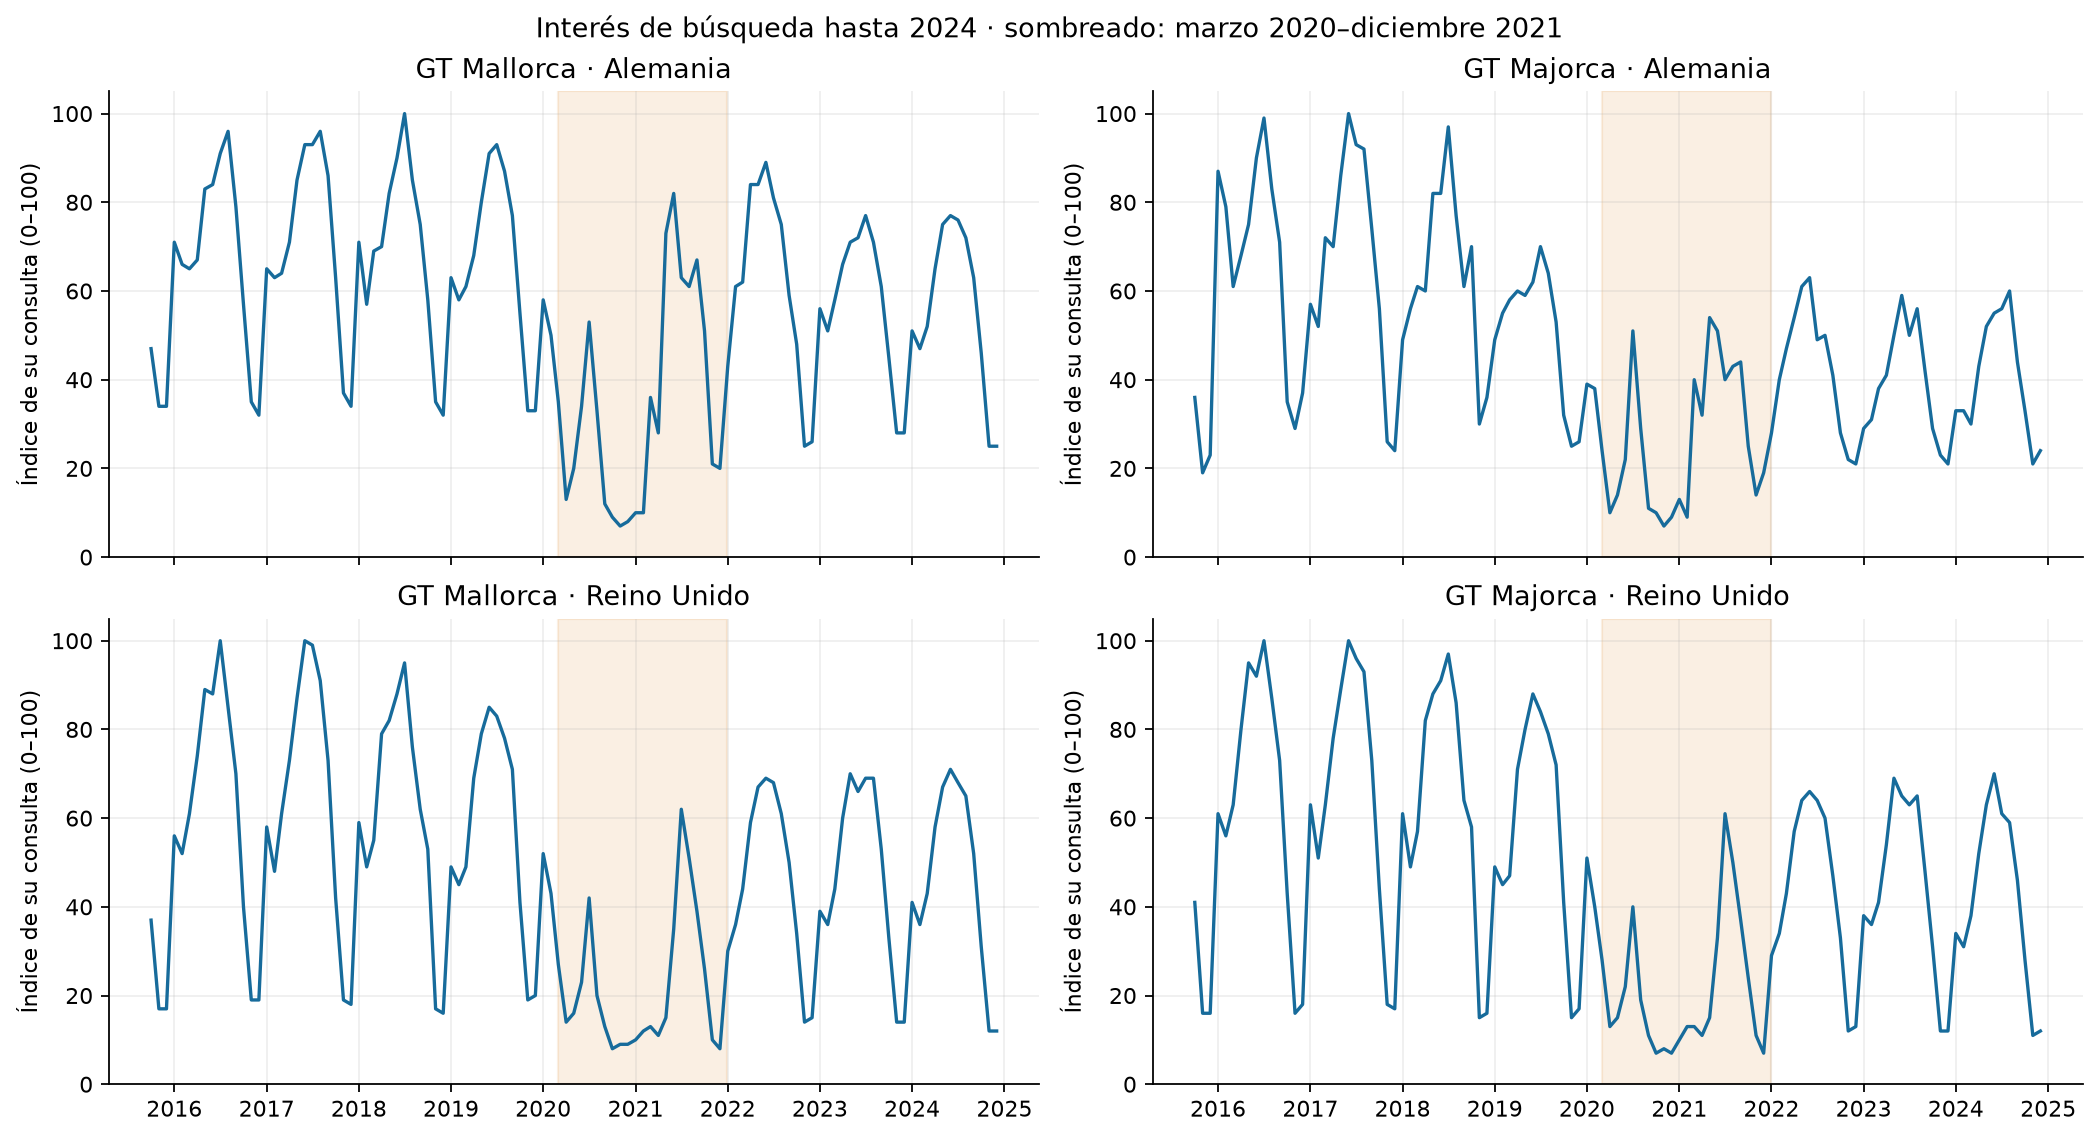

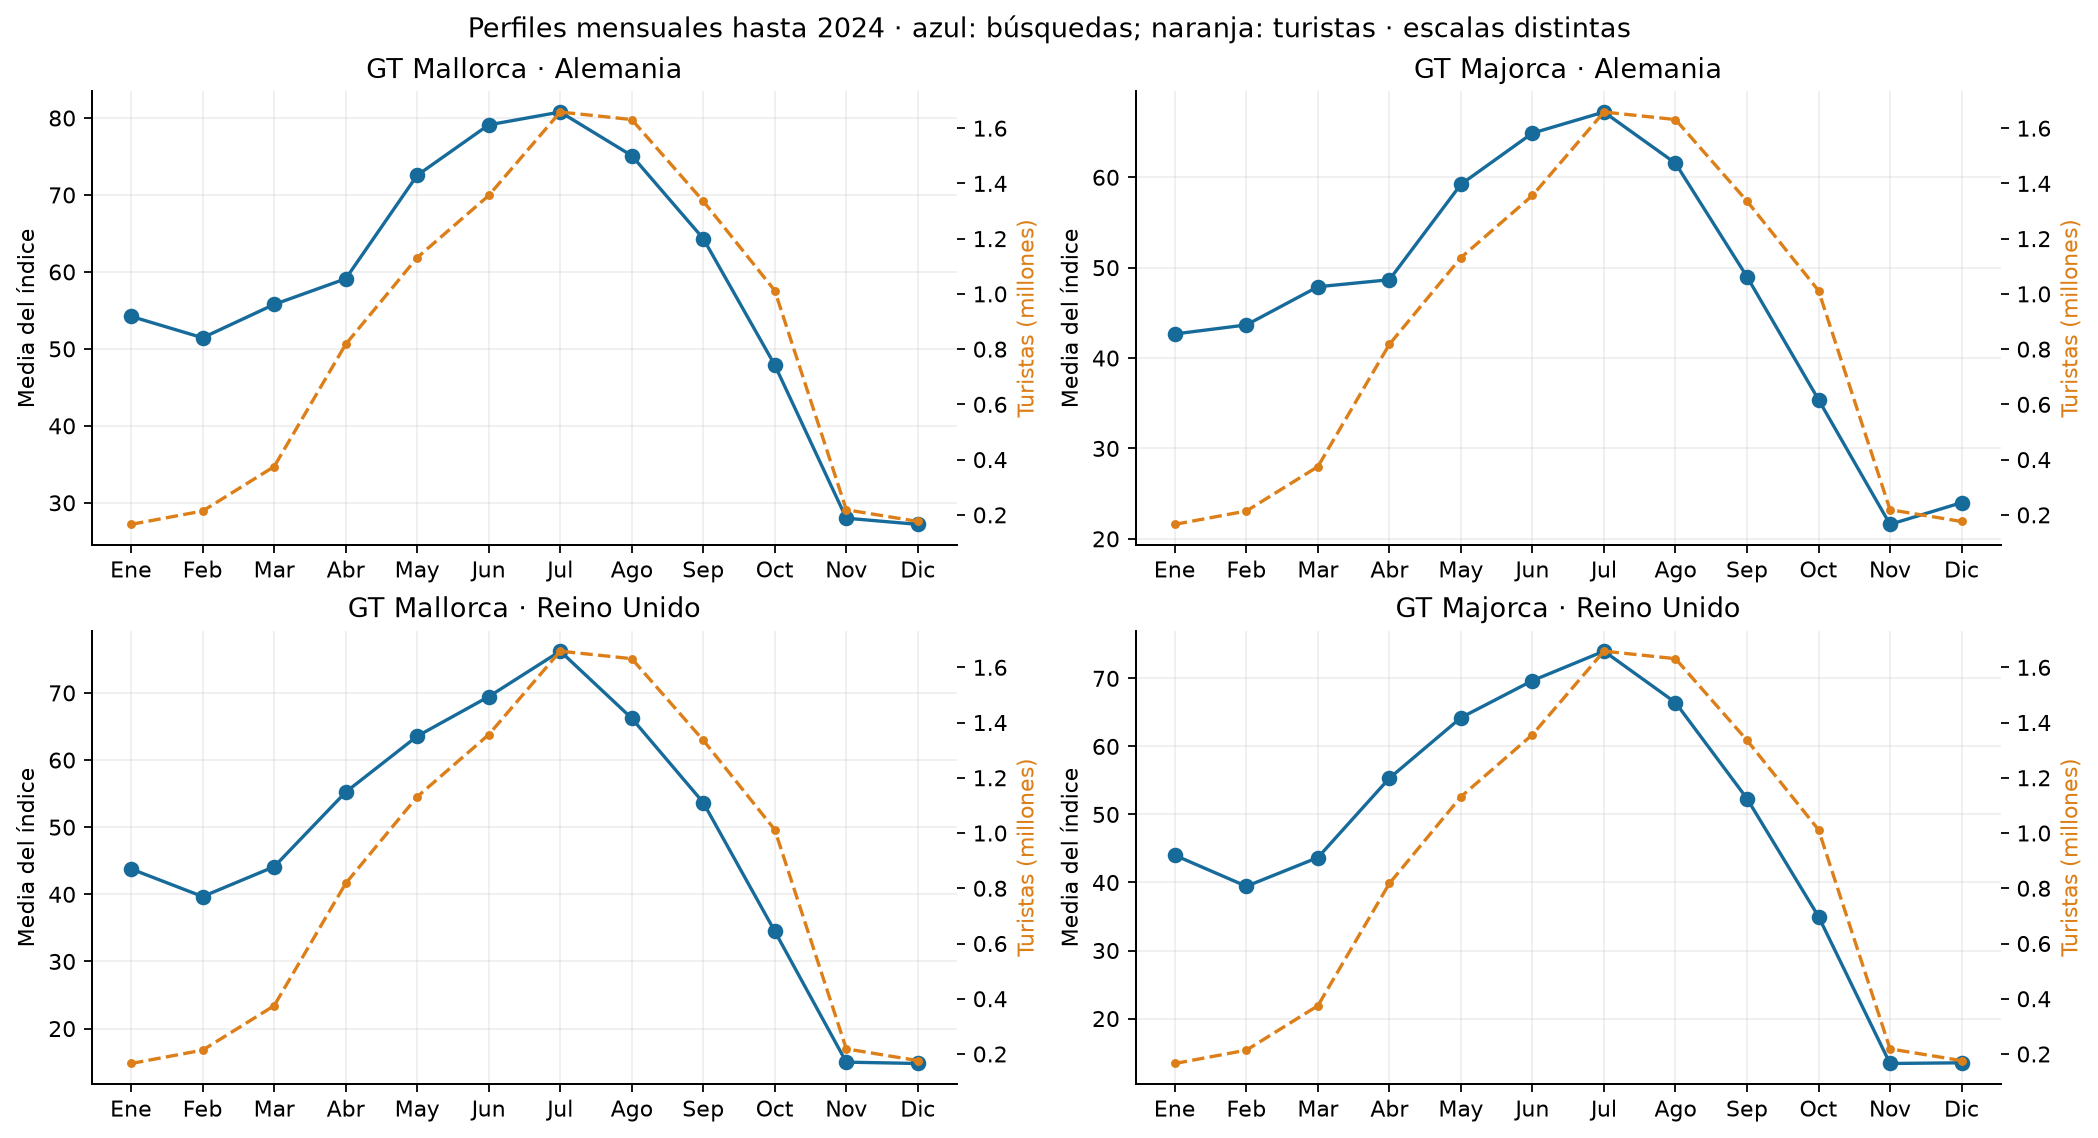

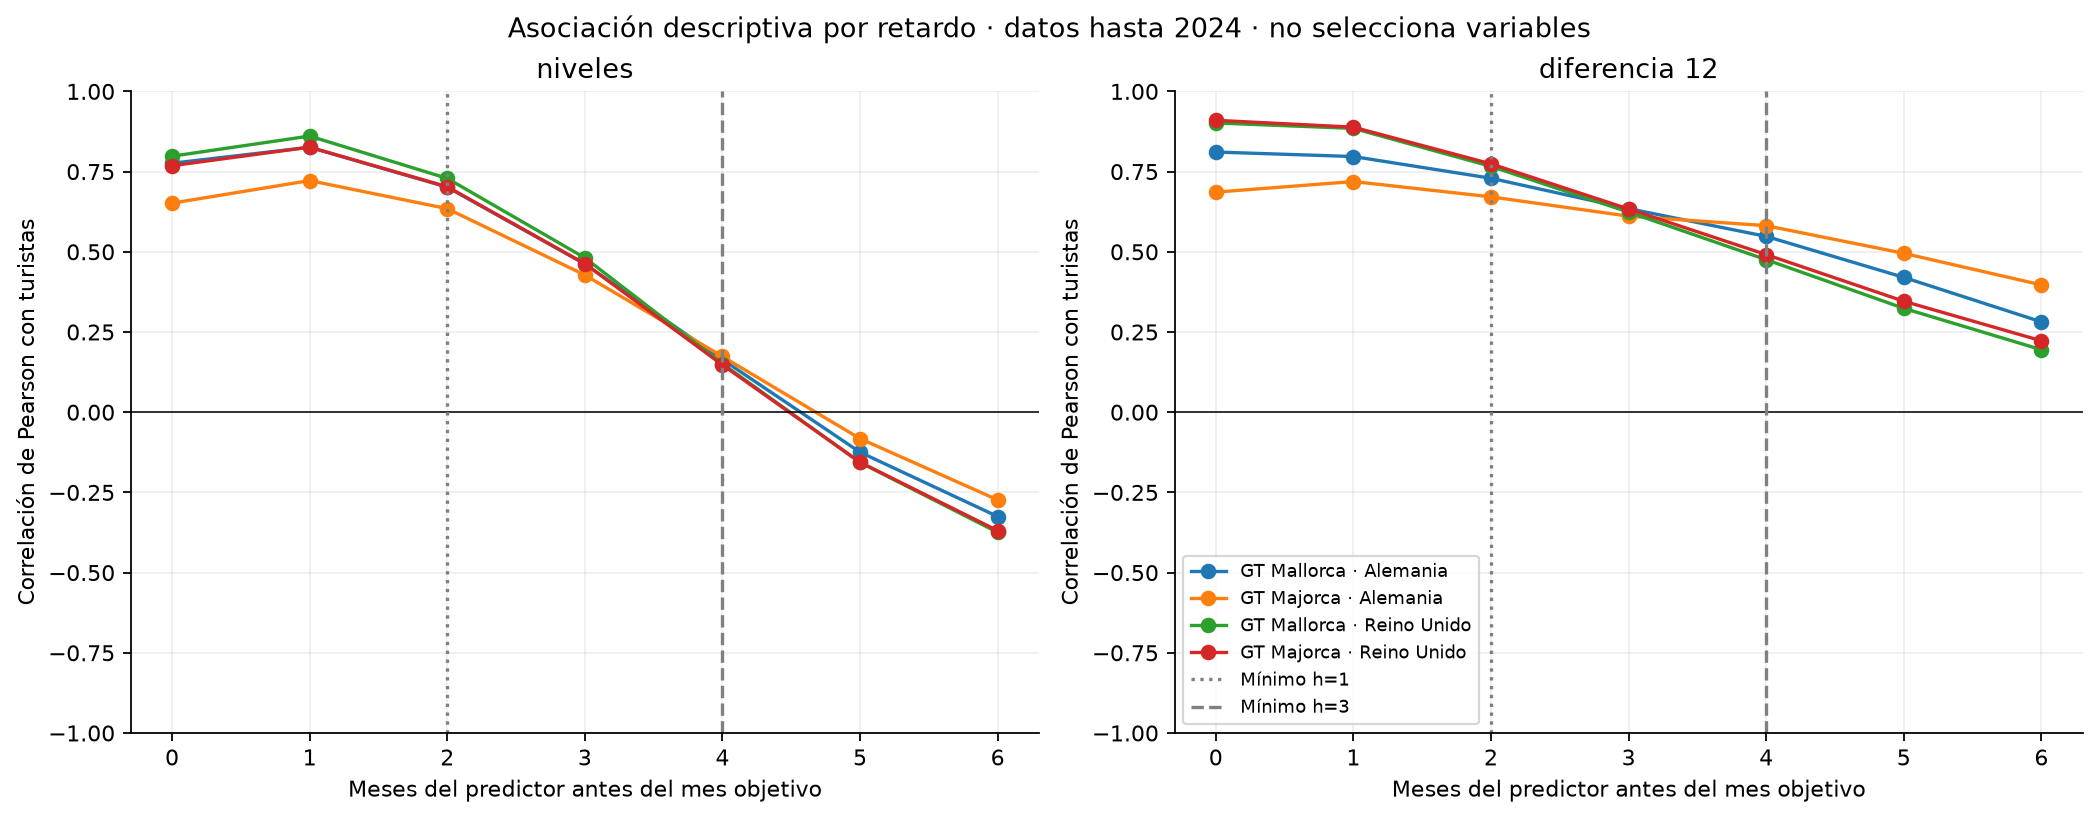

,count,mean,std,min,25%,50%,75%,max,ceros_hasta_2024
gt_mallorca_alemania,111.0,57.32,23.79,7.0,35.0,61.0,75.0,100.0,0
gt_majorca_alemania,111.0,46.60,22.76,7.0,29.0,44.0,60.5,100.0,0
gt_mallorca_reino_unido,111.0,47.30,26.09,8.0,19.5,49.0,68.5,100.0,0
gt_majorca_reino_unido,111.0,46.86,27.12,7.0,18.0,47.0,64.5,100.0,0


,variable,retardo_respecto_objetivo,transformacion,pearson,pares,admisible_h1_regla_base,admisible_h3_regla_base
0,gt_mallorca_alemania,0,niveles,0.776,111,False,False
1,gt_mallorca_alemania,0,diferencia_12,0.811,99,False,False
4,gt_mallorca_alemania,2,niveles,0.701,111,True,False
5,gt_mallorca_alemania,2,diferencia_12,0.729,99,True,False
8,gt_mallorca_alemania,4,niveles,0.164,111,True,True
9,gt_mallorca_alemania,4,diferencia_12,0.548,99,True,True
14,gt_majorca_alemania,0,niveles,0.652,111,False,False
15,gt_majorca_alemania,0,diferencia_12,0.686,99,False,False
18,gt_majorca_alemania,2,niveles,0.635,111,True,False
19,gt_majorca_alemania,2,diferencia_12,0.671,99,True,False


,gt_mallorca_alemania,gt_majorca_alemania,gt_mallorca_reino_unido,gt_majorca_reino_unido
gt_mallorca_alemania,1.000,0.896,0.930,0.921
gt_majorca_alemania,0.896,1.000,0.899,0.914
gt_mallorca_reino_unido,0.930,0.899,1.000,0.994
gt_majorca_reino_unido,0.921,0.914,0.994,1.000


**Lectura: Alemania.** Las dos grafías tienen correlación **0.896** en niveles hasta 2024. La coincidencia sugiere revisar redundancia, pero no determina cuál ofrece mejores pronósticos.

**Lectura: Reino Unido.** Las dos grafías tienen correlación **0.994** en niveles hasta 2024. La coincidencia sugiere revisar redundancia, pero no determina cuál ofrece mejores pronósticos.

**Lectura de los retardos admisibles.** En niveles, las correlaciones con dos meses de retardo van de **0.635 a 0.729**; con cuatro meses, de **0.147 a 0.174**. La reducción puede estar ligada al desfase estacional. Las diferencias interanuales aportan otra perspectiva, pero estas asociaciones no prueban una mejora incremental frente al histórico, calendario y otras variables externas.

Ampliación completada: tres figuras y cuatro tablas de Google Trends; sin imputación ni modelos.


In [22]:
gt_summary = eda_train[GT_COLUMNS].describe().T
gt_summary["ceros_hasta_2024"] = eda_train[GT_COLUMNS].eq(0).sum()
gt_summary.to_csv(EDA_DIR / "google_trends_descriptivos.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(2, 2, figsize=(13, 7), sharex=True, constrained_layout=True)
for ax, column in zip(axes.flat, GT_COLUMNS):
    ax.plot(eda_train.index, eda_train[column], color="#176b9b", lw=1.5)
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="#dd7f19", alpha=.12)
    ax.set(title=LABELS[column], ylabel="Índice de su consulta (0–100)", ylim=(0, 105))
fig.suptitle("Interés de búsqueda hasta 2024 · sombreado: marzo 2020–diciembre 2021")
save_show(fig, "07_google_trends_evolucion.png")

gt_profiles = eda_train[["turistas", *GT_COLUMNS]].groupby(eda_train.index.month).mean()
gt_profiles.index.name = "mes"
gt_profiles.to_csv(EDA_DIR / "google_trends_perfiles_mensuales.csv", encoding="utf-8-sig")
fig, axes = plt.subplots(2, 2, figsize=(13, 7), constrained_layout=True)
for ax, column in zip(axes.flat, GT_COLUMNS):
    ax.plot(gt_profiles.index, gt_profiles[column], color="#176b9b", marker="o")
    right = ax.twinx()
    right.plot(gt_profiles.index, gt_profiles["turistas"] / 1e6, color="#dd7f19", ls="--", marker=".")
    right.grid(False)
    right.set_ylabel("Turistas (millones)", color="#dd7f19")
    ax.set(title=LABELS[column], ylabel="Media del índice", xticks=range(1, 13), xticklabels=MONTHS)
fig.suptitle("Perfiles mensuales hasta 2024 · azul: búsquedas; naranja: turistas · escalas distintas")
save_show(fig, "08_google_trends_estacionalidad.png")

gt_lag_rows = []
for column in GT_COLUMNS:
    for lag in range(7):
        for transform in ["niveles", "diferencia_12"]:
            y = eda_train["turistas"]
            x = google_trends[column].loc[:"2024-12-01"]
            if transform == "diferencia_12":
                y, x = y.diff(12), x.diff(12)
            pair = pd.concat([y.rename("y"), x.shift(lag).reindex(y.index).rename("x")], axis=1).dropna()
            gt_lag_rows.append({"variable": column, "retardo_respecto_objetivo": lag,
                "transformacion": transform, "pearson": pair["y"].corr(pair["x"]), "pares": len(pair),
                "admisible_h1_regla_base": lag >= 2, "admisible_h3_regla_base": lag >= 4})
gt_lag_corr = pd.DataFrame(gt_lag_rows)
gt_lag_corr.to_csv(EDA_DIR / "google_trends_correlaciones_retardos.csv", index=False, encoding="utf-8-sig")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
for ax, transform in zip(axes, ["niveles", "diferencia_12"]):
    for column in GT_COLUMNS:
        subset = gt_lag_corr.loc[gt_lag_corr["variable"].eq(column) & gt_lag_corr["transformacion"].eq(transform)]
        ax.plot(subset["retardo_respecto_objetivo"], subset["pearson"], marker="o", label=LABELS[column])
    ax.axhline(0, color="black", lw=.7)
    ax.axvline(2, color="gray", ls=":", label="Mínimo h=1")
    ax.axvline(4, color="gray", ls="--", label="Mínimo h=3")
    ax.set(title=transform.replace("_", " "), xlabel="Meses del predictor antes del mes objetivo",
           ylabel="Correlación de Pearson con turistas", ylim=(-1, 1), xticks=range(7))
axes[1].legend(fontsize=8, loc="lower left")
fig.suptitle("Asociación descriptiva por retardo · datos hasta 2024 · no selecciona variables")
save_show(fig, "09_google_trends_retardos.png")
display(gt_summary.round(2))
display(gt_lag_corr.loc[gt_lag_corr["retardo_respecto_objetivo"].isin([0, 2, 4])].round(3))
gt_redundancy = eda_train[GT_COLUMNS].corr()
gt_redundancy.to_csv(EDA_DIR / "google_trends_correlaciones_entre_indices.csv", encoding="utf-8-sig")
display(gt_redundancy.round(3))
for country, columns in [("Alemania", ["gt_mallorca_alemania", "gt_majorca_alemania"]),
                         ("Reino Unido", ["gt_mallorca_reino_unido", "gt_majorca_reino_unido"])]:
    r = gt_redundancy.loc[columns[0], columns[1]]
    display(Markdown(f"**Lectura: {country}.** Las dos grafías tienen correlación **{r:.3f}** en niveles hasta 2024. La coincidencia sugiere revisar redundancia, pero no determina cuál ofrece mejores pronósticos."))
r_h1 = gt_lag_corr.loc[gt_lag_corr["retardo_respecto_objetivo"].eq(2) & gt_lag_corr["transformacion"].eq("niveles"), "pearson"]
r_h3 = gt_lag_corr.loc[gt_lag_corr["retardo_respecto_objetivo"].eq(4) & gt_lag_corr["transformacion"].eq("niveles"), "pearson"]
display(Markdown(f"**Lectura de los retardos admisibles.** En niveles, las correlaciones con dos meses de retardo van de **{r_h1.min():.3f} a {r_h1.max():.3f}**; con cuatro meses, de **{r_h3.min():.3f} a {r_h3.max():.3f}**. La reducción puede estar ligada al desfase estacional. Las diferencias interanuales aportan otra perspectiva, pero estas asociaciones no prueban una mejora incremental frente al histórico, calendario y otras variables externas."))
eda_metadata.update({"google_trends": {"candidatos": GT_COLUMNS, "retardos_explorados": list(range(7)),
                    "seleccion": "pendiente de validacion temporal", "versiones_por_origen": "no reconstruidas"},
                    "figuras": figures})
(EDA_DIR / "ejecucion.json").write_text(json.dumps(eda_metadata, ensure_ascii=False, indent=2), encoding="utf-8")
assert eda[VALUE_COLUMNS].equals(master[VALUE_COLUMNS])
print("Ampliación completada: tres figuras y cuatro tablas de Google Trends; sin imputación ni modelos.")

## 24. Conclusiones de la incorporación de Google Trends

1. **Cobertura:** cuatro series mensuales de enero de 2015 a diciembre de 2025. El ETL conserva 123 meses comunes y genera una extracción auxiliar de 132 meses, útil para disponer de contexto anterior al inicio del maestro.
2. **Interpretación:** se conserva cada índice con su escala original. No se suman consultas ni se interpretan los niveles como volumen absoluto o como proporción de turistas alemanes y británicos.
3. **Selección pendiente:** las correlaciones y los perfiles orientan hipótesis. Se contrastará la aportación incremental de Google Trends frente a los mismos modelos sin ese grupo, con iguales orígenes, horizontes y tratamiento de ausentes. Se evitará introducir cuatro señales redundantes sin evaluarlas.
4. **Disponibilidad:** regla base t−1 y sensibilidad t−2 desde el origen. Esto equivale a retardos mínimos 2/4 y 3/5 respecto a los objetivos h=1/h=3. No se confunden los retardos de una covariable con el horizonte de pronóstico.
5. **Trazabilidad pendiente:** los archivos acreditan categoría, término y país. Falta confirmar fecha de descarga, tipo de búsqueda, selección de término o tema y URL de consulta. El catálogo deja esos campos vacíos.
6. **Límite de la evaluación:** descarga retrospectiva con normalización del periodo completo y sin versiones históricas. Las asociaciones hasta 2024 no consultan filas de 2025, pero heredan esa construcción de la fuente. Este experimento no podrá describirse como una reconstrucción exacta de predicción en tiempo real.

Las fuentes originales permanecen intactas. No se han ajustado modelos, imputado valores ni modificado la memoria.

## 25. Variables de predicción por horizonte

Se construyen entradas para emitir pronósticos al cierre de cada mes `t`, con objetivos en `t+1` y `t+3`. El índice identifica el mes de origen; `fecha_corte` identifica su cierre. Los valores del mes objetivo se exportan únicamente como etiquetas y nunca como predictores. La fecha de cada variable se comprueba frente a la política del apartado 19, incluyendo publicaciones excepcionalmente tardías cuando exista evidencia.

| Familia | Construcción respecto al origen t, regla base | Uso |
|---|---|---|
| Histórico de turistas | Valores en t−2, t−3, t−4, t−5, t−8 y t−14 | Último dato publicado y retardos adicionales 1, 2, 3, 6 y 12 |
| Resúmenes del objetivo | Medias de 3, 6 y 12 meses que terminan en t−2 | Nivel reciente; ventanas completas, sin saltar ausentes |
| Referencia estacional | Turistas de t+h−12 | Mismo mes del año anterior al objetivo; disponibilidad comprobada |
| Calendario del objetivo | Mes, seno/coseno anual y meses desde enero de 2015 | Información conocida; índice temporal fijo, sin estimación con la muestra |
| Aeropuerto, hoteles y Google Trends | Valores en t−1, t−2 y t−13 | Último dato permitido y retardos adicionales 1 y 12 |
| Meteorología: temperatura media y precipitación | Valores en t−2, t−3 y t−14 | Supuesto de disponibilidad t−2; retardos adicionales 1 y 12 |

Los nombres `*_origen_lagN` expresan meses anteriores al origen, no al objetivo: su retardo respecto al objetivo es `N+h`. Las medias se identifican por su ventana y su último mes. La referencia estacional tiene retardo 12 respecto al objetivo y, por tanto, retardo 11 respecto al origen para h=1 y 9 para h=3. La versión de sensibilidad añade un mes de espera a todos los grupos; la referencia estacional sigue usando el mismo mes del año anterior si está publicado.

Este catálogo contiene **candidatos**, no una selección definitiva. Con una muestra mensual corta no se introducirán todas las columnas por defecto. Se separan los grupos histórico/calendario, aeropuerto/hoteles y búsquedas para evaluar su aportación en validación anterior a 2025. La referencia estacional también permite construir Seasonal Naïve. Estas matrices son entradas directas por horizonte para ML; SARIMA/SARIMAX necesitan su propia preparación secuencial y no pueden recibir realizaciones futuras de las exógenas.

### Ausentes, calidad y límites

Se conserva el calendario de 123 orígenes, incluso donde falta historia o todavía no existe etiqueta. Los ceros se mantienen; no se realiza imputación, escalado ni selección de variables. Si una ventana contiene un ausente o un dato no publicado, su media queda ausente. La auditoría distingue falta de contexto, bloqueo por publicación y ausencia en la fuente. Las marcas `U`, `P` y provisionales se conservan en la auditoría y no se convierten en números para el modelo. La historia incompleta se identifica por fila, sin eliminar meses del maestro.

Las etiquetas incorporan su fecha operativa de publicación. El bloque de entrenamiento de un origen debe limitarse a etiquetas difundidas antes de su cierre, y 2025 permanece excluido de la selección. La función `training_rows_at` aplica ambos límites; no define todavía los folds de validación. La pertenencia a 2025 depende del **mes objetivo**, aunque el origen esté en 2024. Los objetivos posteriores al final del maestro quedan sin etiqueta y no son evaluables.

La política utiliza fechas supuestas cuando no se dispone de una fecha efectiva. Google Trends mantiene su espera operativa supuesta y su normalización retrospectiva. No se reconstruyen primeras versiones históricas ni se incorpora meteorología pendiente.


In [23]:
FEATURE_DIR = PROJECT_ROOT / "outputs" / "predictores"
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

def feature_specifications(horizon, extra_wait=0):
    specs = []
    def add(name, group, variable, lags, operation="valor"):
        specs.append({"predictor": name, "grupo": group, "variable": variable,
                      "retardos_origen": list(lags), "operacion": operation})
    wait = PUBLICATION_DELAYS["turistas"] + extra_wait
    for offset in [0, 1, 2, 3, 6, 12]:
        lag = wait + offset
        add(f"turistas_origen_lag{lag}", "turistas", "turistas", [lag])
    for window in [3, 6, 12]:
        add(f"turistas_media{window}_hasta_lag{wait}", "turistas", "turistas",
            range(wait, wait + window), "media")
    add("turistas_mismo_mes_ano_anterior", "turistas", "turistas", [12-horizon])
    for group, variables in GROUP_VARIABLES.items():
        if group == "turistas":
            continue
        if group == "meteorologia":
            variables = METEO_CORE
        for variable in variables:
            for offset in [0, 1, 12]:
                lag = PUBLICATION_DELAYS[group] + extra_wait + offset
                add(f"{variable}_origen_lag{lag}", group, variable, [lag])
    return specs

def publication_date(group, reference, extra_wait=0, dates=None):
    # Mantener el cierre conservador, incluso si la nota se publicó antes.
    planned = (reference + PUBLICATION_DELAYS[group] + extra_wait).end_time.normalize()
    actual = (dates or {}).get((group, reference.start_time))
    if actual is not None:
        actual = (pd.Timestamp(actual).to_period("M") + extra_wait).end_time.normalize()
        planned = max(planned, actual)
    return planned

def build_prediction_features(data, horizon, extra_wait=0, dates=None):
    assert horizon in [1, 3] and extra_wait in [0, 1]
    assert data.index.equals(pd.date_range(data.index.min(), data.index.max(), freq="MS"))
    specs = feature_specifications(horizon, extra_wait)
    periods = data.index.to_period("M")
    features = pd.DataFrame(index=data.index)
    features.index.name = "mes_origen"
    audit_rows, contexts = [], []
    for spec in specs:
        values, context = [], []
        group, variable = spec["grupo"], spec["variable"]
        state_column = "aena_estado" if group == "aena" else variable + "_estado"
        for origin in periods:
            cutoff = origin.end_time.normalize()
            refs = [origin - lag for lag in spec["retardos_origen"]]
            dates_used = [publication_date(group, ref, extra_wait, dates) for ref in refs]
            in_range = [ref.start_time in data.index for ref in refs]
            allowed = [release <= cutoff for release in dates_used]
            raw = [data.at[ref.start_time, variable] if exists else np.nan
                   for ref, exists in zip(refs, in_range)]
            usable = [value if ok else np.nan for value, ok in zip(raw, allowed)]
            value = float(np.mean(usable)) if all(pd.notna(v) for v in usable) else np.nan
            values.append(value)
            context.append(all(in_range))
            states = [str(data.at[ref.start_time, state_column]) for ref, exists in zip(refs, in_range)
                      if exists and state_column in data]
            audit_rows.append({"mes_origen": origin.start_time, "horizonte": horizon,
                "espera_adicional": extra_wait, "predictor": spec["predictor"], "grupo": group,
                "fecha_corte": cutoff, "primer_mes_referencia": min(refs).start_time,
                "ultimo_mes_referencia": max(refs).start_time,
                "ultima_fecha_operativa": max(dates_used), "contexto_completo": all(in_range),
                "publicacion_permitida": all(allowed),
                "ausentes_fuente": sum(exists and pd.isna(v) for exists, v in zip(in_range, raw)),
                "valor_disponible": pd.notna(value), "estados_fuente": "|".join(sorted(set(states)))})
        features[spec["predictor"]] = values
        contexts.append(context)
    target_periods = periods + horizon
    features["mes_objetivo"] = target_periods.month.astype(float)
    features["mes_sin"] = np.sin(2*np.pi*target_periods.month/12)
    features["mes_cos"] = np.cos(2*np.pi*target_periods.month/12)
    features["tiempo_meses_desde_2015_01"] = (target_periods.year-2015)*12 + target_periods.month-1
    metadata = pd.DataFrame(index=data.index)
    metadata.index.name = "mes_origen"
    metadata["fecha_corte"] = periods.end_time.normalize()
    metadata["mes_objetivo"] = target_periods.start_time
    metadata["turistas_objetivo"] = data["turistas"].reindex(target_periods.start_time).to_numpy()
    metadata["estado_objetivo"] = data["turistas_estado"].reindex(target_periods.start_time).to_numpy()
    metadata["fecha_publicacion_objetivo"] = [publication_date("turistas", p, extra_wait, dates)
                                              for p in target_periods]
    metadata["contexto_completo"] = np.asarray(contexts).all(axis=0)
    metadata["etiqueta_observada"] = metadata["turistas_objetivo"].notna()
    metadata["uso_por_mes_objetivo"] = np.where(target_periods.year <= 2024, "train_valid",
        np.where(target_periods.year == 2025, "prueba_2025", "fuera_periodo"))
    catalog = pd.DataFrame([{**s, "horizonte": horizon, "espera_adicional": extra_wait,
        "retardos_objetivo": [lag+horizon for lag in s["retardos_origen"]]} for s in specs])
    calendar_catalog = pd.DataFrame([{"predictor": c, "grupo": "calendario", "variable": c,
        "retardos_origen": [], "retardos_objetivo": [], "operacion": "calendario_conocido",
        "horizonte": horizon, "espera_adicional": extra_wait}
        for c in features.columns if c not in set(catalog["predictor"])])
    catalog = pd.concat([catalog, calendar_catalog], ignore_index=True)
    return features, metadata, pd.DataFrame(audit_rows), catalog

def training_rows_at(metadata, forecast_origin):
    """Etiquetas publicadas y anteriores a 2025; la selección de folds es posterior."""
    cutoff = pd.Timestamp(forecast_origin).to_period("M").end_time.normalize()
    return (metadata["contexto_completo"] & metadata["etiqueta_observada"]
            & metadata["fecha_publicacion_objetivo"].le(cutoff)
            & metadata["uso_por_mes_objetivo"].eq("train_valid"))

prediction_sets, feature_audits, feature_catalogs, feature_summaries = {}, [], [], []
for extra_wait, scenario in [(0, "base"), (1, "espera_adicional")]:
    for horizon in [1, 3]:
        X, meta, audit, catalog = build_prediction_features(master, horizon, extra_wait, verified_dates)
        prediction_sets[(scenario, horizon)] = (X, meta)
        X.to_csv(FEATURE_DIR / f"X_{scenario}_h{horizon}.csv", encoding="utf-8-sig")
        meta.to_csv(FEATURE_DIR / f"etiquetas_{scenario}_h{horizon}.csv", encoding="utf-8-sig")
        feature_audits.append(audit)
        feature_catalogs.append(catalog)
        for usage in ["train_valid", "prueba_2025", "fuera_periodo"]:
            selected = meta["uso_por_mes_objetivo"].eq(usage)
            feature_summaries.append({"escenario": scenario, "horizonte": horizon, "uso": usage,
                "origenes": int(selected.sum()), "predictores": len(X.columns),
                "con_historia_y_etiqueta": int((selected & meta["contexto_completo"] & meta["etiqueta_observada"]).sum()),
                "con_todas_las_entradas": int((selected & meta["etiqueta_observada"] & X.notna().all(axis=1)).sum())})
feature_audit = pd.concat(feature_audits, ignore_index=True)
feature_catalog = pd.concat(feature_catalogs, ignore_index=True)
feature_summary = pd.DataFrame(feature_summaries)
feature_audit.to_csv(FEATURE_DIR / "auditoria_predictores.csv", index=False, encoding="utf-8-sig")
feature_catalog.to_csv(FEATURE_DIR / "catalogo_predictores.csv", index=False, encoding="utf-8-sig")
feature_summary.to_csv(FEATURE_DIR / "resumen_construccion.csv", index=False, encoding="utf-8-sig")
display(feature_summary)
display(prediction_sets[("base", 1)][0].loc[["2024-12-01"]])


,escenario,horizonte,uso,origenes,predictores,con_historia_y_etiqueta,con_todas_las_entradas
0,base,1,train_valid,110,56,96,88
1,base,1,prueba_2025,12,56,12,12
2,base,1,fuera_periodo,1,56,0,0
3,base,3,train_valid,108,56,94,86
4,base,3,prueba_2025,12,56,12,12
5,base,3,fuera_periodo,3,56,0,0
6,espera_adicional,1,train_valid,110,56,95,87
7,espera_adicional,1,prueba_2025,12,56,12,12
8,espera_adicional,1,fuera_periodo,1,56,0,0
9,espera_adicional,3,train_valid,108,56,93,85


,turistas_origen_lag2,turistas_origen_lag3,turistas_origen_lag4,turistas_origen_lag5,turistas_origen_lag8,turistas_origen_lag14,turistas_media3_hasta_lag2,turistas_media6_hasta_lag2,turistas_media12_hasta_lag2,turistas_mismo_mes_ano_anterior,...,meteo_temperatura_media_c_origen_lag2,meteo_temperatura_media_c_origen_lag3,meteo_temperatura_media_c_origen_lag14,meteo_precipitacion_mm_origen_lag2,meteo_precipitacion_mm_origen_lag3,meteo_precipitacion_mm_origen_lag14,mes_objetivo,mes_sin,mes_cos,tiempo_meses_desde_2015_01
mes_origen,,,,,,,,,,,,,,,,,,,,,
2024-12-01,1429437.0,1708730.0,2002816.0,2005430.0,1204359.0,1247236.0,1713661.0,1.759625e+06,1.111348e+06,220848.0,...,20.4,22.0,21.3,98.3,48.2,27.6,1.0,0.5,0.866025,120


## 26. Comprobaciones temporales y resultado

Los controles contrastan valores con sus meses de referencia, recalculan medias, comprueban etiquetas y disponibilidad de entrenamiento y simulan una difusión hotelera tardía. También alteran datos todavía no publicados en un origen para verificar que no cambian sus entradas. La auditoría y el catálogo se guardan en `outputs/predictores/`, junto con cuatro matrices numéricas y sus etiquetas separadas. Las filas futuras sin etiqueta se conservan identificadas; no se contabilizan como resultados de prueba.


In [24]:
for (scenario, horizon), (X, meta) in prediction_sets.items():
    wait = 0 if scenario == "base" else 1
    assert len(X) == len(master) and X.index.equals(meta.index)
    assert not X.columns.duplicated().any()
    assert "turistas_objetivo" not in X and "estado_objetivo" not in X
    pd.testing.assert_series_equal(X[f"turistas_origen_lag{2+wait}"], master["turistas"].shift(2+wait), check_names=False)
    pd.testing.assert_series_equal(X[f"turistas_media3_hasta_lag{2+wait}"], master["turistas"].shift(2+wait).rolling(3, min_periods=3).mean(), check_names=False)
    pd.testing.assert_series_equal(X["turistas_mismo_mes_ano_anterior"], master["turistas"].shift(12-horizon), check_names=False)
    assert meta.loc["2024-12-01", "mes_objetivo"] == pd.Timestamp("2025-01-01" if horizon == 1 else "2025-03-01")
    mask = training_rows_at(meta, "2024-12-01")
    assert meta.loc[mask, "mes_objetivo"].max() == pd.Timestamp("2024-10-01")-pd.DateOffset(months=wait)
    assert meta.loc[mask, "fecha_publicacion_objetivo"].le(pd.Timestamp("2024-12-31")).all()
    assert not training_rows_at(meta, "2025-12-01")[meta["uso_por_mes_objetivo"].eq("prueba_2025")].any()
    # Perturbar meses existentes pero todavía no difundidos al cierre de diciembre.
    altered = master.copy(deep=True)
    origin = pd.Timestamp("2024-12-01")
    for group, variables in GROUP_VARIABLES.items():
        last_known = origin - pd.DateOffset(months=PUBLICATION_DELAYS[group]+wait)
        altered.loc[altered.index > last_known, variables] = 99999999
    changed_X, _, _, _ = build_prediction_features(altered, horizon, wait, verified_dates)
    pd.testing.assert_series_equal(X.loc[origin], changed_X.loc[origin])

X1, labels1 = prediction_sets[("base", 1)]
assert X1.loc["2020-06-01", "turistas_origen_lag2"] == 0
assert labels1.loc["2020-03-01", "turistas_objetivo"] == 0
assert labels1.loc["2020-03-01", "estado_objetivo"] == "U"
assert pd.isna(X1.loc["2020-06-01", "viajeros_hoteles_origen_lag1"])
assert pd.isna(X1.loc["2020-06-01", "estancia_media_noches_origen_lag1"])
late_dates = {**verified_dates, ("hoteles", pd.Timestamp("2024-11-01")): pd.Timestamp("2025-01-02")}
late_X, _, late_audit, _ = build_prediction_features(master, 1, dates=late_dates)
assert pd.isna(late_X.loc["2024-12-01", "viajeros_hoteles_origen_lag1"])
assert not late_audit.loc[late_audit.mes_origen.eq(pd.Timestamp("2024-12-01")) & late_audit.predictor.eq("viajeros_hoteles_origen_lag1"), "publicacion_permitida"].item()
assert feature_audit.loc[feature_audit.valor_disponible, "publicacion_permitida"].all()

feature_manifest = {"fecha_documentacion": "2026-10-09", "horizontes": [1, 3],
    "escenarios": ["base", "espera_adicional"], "origenes_por_matriz": len(master),
    "predictores_por_matriz": len(X1.columns), "imputacion": "pendiente, no realizada",
    "seleccion": "candidatos; pendiente de validacion anterior a 2025",
    "entrenamiento": "etiquetas publicadas al origen y mes objetivo anterior a 2025",
    "grupos": {scenario: {str(h): {group: cat.loc[cat.grupo.eq(group), "predictor"].tolist()
        for group in cat.grupo.unique()} for h in [1,3]
        for cat in [feature_catalog.loc[feature_catalog.horizonte.eq(h) & feature_catalog.espera_adicional.eq(wait)]]}
        for wait, scenario in [(0,"base"),(1,"espera_adicional")]},
    "politica_disponibilidad": availability_policy,
    "maestro_sha256": hashlib.sha256((OUTPUT_DIR / "dataset_maestro_mallorca.csv").read_bytes()).hexdigest(),
    "limite": "fuentes revisadas y Google Trends normalizado retrospectivamente; no reconstruye primeras versiones"}
(FEATURE_DIR / "construccion.json").write_text(json.dumps(feature_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print(f"Controles superados: cuatro matrices de {len(master)} orígenes y {len(X1.columns)} candidatos; etiquetas separadas.")
print("Ceros y ausentes conservados. Sin imputación ni ajuste de modelos. Salidas:", FEATURE_DIR)


Controles superados: cuatro matrices de 123 orígenes y 56 candidatos; etiquetas separadas.
Ceros y ausentes conservados. Sin imputación ni ajuste de modelos. Salidas: C:\Users\acort\Documents\Codex\tfm-turismo-mallorca\outputs\predictores


## 27. Protocolo de evaluación temporal

**Decisión fijada el 9 de octubre de 2026, antes de ajustar modelos.** Se utiliza evaluación con origen móvil mensual y ventana de entrenamiento expansiva. El horizonte se mide desde el cierre del mes de origen: h=1 pronostica el mes siguiente y h=3 exclusivamente el tercer mes siguiente, no el promedio de los pasos 1–3. La separación se realiza por **mes objetivo**, no por año del origen.

| Bloque | Meses objetivo | Función |
|---|---|---|
| Historia inicial | Octubre de 2015–2019, según publicación en cada origen | Contexto y primeros entrenamientos |
| Validación para selección | Enero de 2020–julio de 2024: 55 objetivos por horizonte | Elegir configuraciones, grupos de variables y tratamiento de ausentes |
| Validación complementaria | Agosto–diciembre de 2024: 5 objetivos por horizonte | Diagnóstico con configuración fija; no cambiar la selección |
| Prueba final | Enero–diciembre de 2025: 12 objetivos por horizonte | Evaluar la configuración elegida sin modificarla por sus resultados |

Los 60 meses de validación se resumen en cinco bloques anuales, distinguiendo selección y diagnóstico, pero **cada mes tiene su propio entrenamiento**, limitado por lo que ya estaría publicado. No se entrenará una sola vez al inicio del año ni se utilizarán folds aleatorios. Los resultados de 2020–2021 se informarán aparte de los de 2022–2024. El bloque final es una simulación retrospectiva de doce emisiones mensuales, no una predicción de todo 2025 realizada en diciembre de 2024.

### Información equivalente y entrenamiento disponible

Los cuatro escenarios (h=1/h=3, espera base/adicional) evalúan los mismos 72 meses objetivo, de 2020 a 2025. Sus orígenes difieren por horizonte: enero de 2025 se emite desde diciembre de 2024 para h=1 y desde octubre de 2024 para h=3. En un mismo origen, los modelos comparten el calendario, el límite de publicación y las fuentes autorizadas. Esto no obliga a algoritmos distintos a consumir las mismas columnas.

En la regla base, al cierre de t las etiquetas del objetivo deben referirse como máximo a t−2; con espera adicional, a t−3. Las filas supervisadas admitidas tienen objetivo desde abril de 2017, contexto completo y etiqueta publicada. Este comienzo común cubre la pérdida de historia del catálogo en ambos horizontes y esperas. Se exige un mínimo operativo de 24 filas supervisadas; es una salvaguarda inicial, no una garantía de tamaño suficiente para ML.

SARIMA/SARIMAX podrán usar la secuencia del objetivo desde octubre de 2015 hasta el último mes autorizado; ML pierde las etiquetas iniciales necesarias para construir sus retardos. Se registrarán ambos tamaños: equivalencia de información no implica idéntico número de observaciones de estimación. Para SARIMA, alcanzar t+1 desde t−2 requiere tres pasos internos; alcanzar t+3 requiere cinco. Seasonal Naïve consulta el mismo mes del año anterior al objetivo, previa comprobación de publicación.

Los meses anteriores de validación pueden entrar en entrenamientos posteriores cuando ya estén publicados: es la ventana expansiva. Ninguna etiqueta del mes pronosticado ni de sus meses posteriores se usa para estimar ese pronóstico. El control por fecha produce el intervalo de separación necesario entre filas supervisadas; no se sustituye por un `gap=1` arbitrario.

### Cierre de selección antes del primer origen de prueba

La configuración se congela, bajo la política de disponibilidad, al cierre del **31 de octubre de 2024**: es el primer origen de prueba para h=3 (enero de 2025). Para que los dos horizontes y ambas esperas sean comparables, la selección utiliza objetivos hasta **julio de 2024**, publicados como máximo en octubre con la espera adicional de tres meses del objetivo. Usar noviembre o diciembre de 2024 para elegir la configuración de ese primer pronóstico sería información futura, aunque esos meses no pertenezcan a 2025.

Agosto–diciembre de 2024 se puntuarán como diagnóstico retrospectivo con configuración fija. Algunos de sus orígenes preceden al cierre de selección: este diagnóstico no acredita que la configuración elegida estuviera disponible en esas fechas. Se calculará sin reajustar hiperparámetros, elegir columnas ni reglas de preparación por esos errores. Si ese diagnóstico motivara un rediseño, habría que declarar otro experimento y fijar una nueva prueba todavía no utilizada. El cierre aquí es una regla de la simulación retrospectiva; no acredita que los experimentos se ejecutaran realmente en octubre de 2024.

### Reserva de 2025 y actualización mensual

Hiperparámetros, elección de columnas, reglas de imputación y alternativas de preparación se decidirán con los 55 objetivos de validación para selección, hasta julio de 2024. Durante la prueba podrán reestimarse parámetros e imputadores usando únicamente etiquetas de hasta diciembre de 2024 que ya estén publicadas en ese origen, con la configuración elegida fija. Las etiquetas de 2025 se bloquean para ajuste y selección durante todo el año.

Los valores de 2025 ya publicados sí pueden alimentar retardos o actualizar el estado de un modelo secuencial **sin reestimar sus parámetros con esas etiquetas**. Esta actualización utiliza información disponible para emitir el pronóstico; debe distinguirse de incorporar 2025 al entrenamiento. Un experimento futuro que reentrene con etiquetas de 2025 tendría que registrarse aparte. El EDA ya ha examinado descriptivamente la cobertura y calidad de 2025; su reserva para evaluación no implica que el archivo nunca se haya visto.

### Comparaciones, ausentes y métricas

Se compararán Seasonal Naïve y SARIMA como referencias con histórico; SARIMAX, Random Forest y XGBoost según las fuentes que puedan utilizar. Los grupos de entradas son: histórico/calendario; esas entradas más aeropuerto/hoteles; y las anteriores más Google Trends. Para SARIMAX hay que construir exógenas conocidas en todos los pasos internos o pronosticarlas sin realizaciones futuras: la matriz directa de ML no resuelve ese requisito.

No se filtrará el calendario común según las columnas elegidas ni con un `dropna` global. Los ausentes de entradas se tratarán exclusivamente dentro del entrenamiento y con una regla fijada en validación. Si un modelo no genera un pronóstico, se registrará el fallo; no se ocultará reduciendo su denominador. Se publicará la cobertura y, si es necesaria una comparación por pares incompletos, se identificará el subconjunto común y su tamaño. Los ceros y las etiquetas `U` se conservan; podrá informarse un diagnóstico adicional sin las dos etiquetas de baja fiabilidad, identificado y sin alterar el resultado principal.

El criterio principal de selección será RMSE sobre los 55 pronósticos de validación para selección de cada horizonte; MAE será complementario. Se calcularán sobre errores en la escala original y se presentarán también por año y por periodo pandémico/posterior. El RMSE agregado se obtiene de todos los errores cuadrados, no promediando los RMSE anuales. No se promediarán h=1 y h=3 para declarar un ganador único. Si se utiliza MASE, su denominador se calculará con la historia de entrenamiento de cada origen y se comprobará que sea distinto de cero. MAPE no será el criterio principal por los ceros y valores bajos.

La alternativa de entrenamiento posterior a la pandemia se analizará aparte: no dispone de 24 etiquetas desde 2022 en los primeros orígenes de validación. Antes de ejecutarla se fijarán los meses comunes donde haya historia suficiente para ambas esperas y horizontes. No se mezclará su evaluación abreviada con el criterio de selección de 55 meses ni con el diagnóstico de cinco meses.

La tabla de predicciones futura deberá identificar modelo, grupo de fuentes, escenario, horizonte, origen, fecha de corte, mes objetivo, valor observado, predicción y estado de ejecución. El plan exportado fija las claves esperadas y los índices de entrenamiento antes de obtener resultados.

Fundamento: [validación de series temporales con origen móvil, Hyndman y Athanasopoulos](https://otexts.com/fpp3/tscv.html). Las fuentes revisadas y la normalización retrospectiva de Google Trends mantienen las limitaciones del apartado 22; este protocolo controla fechas bajo la política disponible, no reconstruye todas las versiones históricas.


In [25]:
EVAL_DIR = PROJECT_ROOT / "outputs" / "evaluacion"
EVAL_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_TARGET_START = pd.Timestamp("2017-04-01")
TRAIN_TARGET_END = pd.Timestamp("2024-12-01")
EVAL_TARGETS = pd.date_range("2020-01-01", "2025-12-01", freq="MS")
MIN_TRAIN_ROWS = 24
SELECTION_TARGET_END = pd.Timestamp("2024-07-01")
CONFIGURATION_FREEZE = pd.Timestamp("2024-10-31")

plan_rows, training_rows = [], []
for (scenario, horizon), (X, meta) in prediction_sets.items():
    extra_wait = 0 if scenario == "base" else 1
    for target in EVAL_TARGETS:
        origin = target - pd.DateOffset(months=horizon)
        cutoff = origin.to_period("M").end_time.normalize()
        row = meta.loc[origin]
        assert row["mes_objetivo"] == target and row["etiqueta_observada"]
        assert row["contexto_completo"]
        # La etiqueta evaluada se consulta después, para puntuar; nunca para ajustar.
        permitted = (training_rows_at(meta, origin)
                     & meta["mes_objetivo"].ge(TRAIN_TARGET_START)
                     & meta["mes_objetivo"].le(TRAIN_TARGET_END))
        training = meta.loc[permitted]
        assert len(training) >= MIN_TRAIN_ROWS
        observed_periods = master.index.to_period("M")
        published_y = [p.start_time for p in observed_periods
                       if publication_date("turistas", p, extra_wait, verified_dates) <= cutoff]
        last_published_y = max(published_y)
        last_estimation_y = min(last_published_y, TRAIN_TARGET_END)
        plan_rows.append({"escenario": scenario, "horizonte": horizon,
            "mes_origen": origin, "fecha_corte": cutoff, "mes_objetivo": target,
            "uso": "validacion" if target.year <= 2024 else "prueba_final",
            "papel": ("seleccion" if target <= SELECTION_TARGET_END else "diagnostico_fijo") if target.year <= 2024 else "prueba_final",
            "fold": f"validacion_{target.year}" if target.year <= 2024 else "prueba_2025",
            "periodo": "pandemia_2020_2021" if target.year <= 2021 else "posterior_2022_2025",
            "inicio_etiquetas_entrenamiento": training["mes_objetivo"].min(),
            "fin_etiquetas_entrenamiento": training["mes_objetivo"].max(),
            "n_entrenamiento_supervisado": len(training),
            "inicio_historia_secuencial": master.index.min(),
            "ultimo_y_publicado": last_published_y, "ultimo_y_para_estimacion": last_estimation_y,
            "pasos_desde_ultimo_y_publicado": target.to_period("M").ordinal-last_published_y.to_period("M").ordinal,
            "n_historia_estimacion_secuencial": int(master.index.to_series().le(last_estimation_y).sum()),
            "n_entradas_ausentes": int(X.loc[origin].isna().sum()),
            "estado_objetivo": row["estado_objetivo"]})
        for train_origin, train_row in training.iterrows():
            training_rows.append({"escenario": scenario, "horizonte": horizon,
                "mes_origen_pronostico": origin, "mes_objetivo_pronostico": target,
                "fecha_corte_pronostico": cutoff, "mes_origen_entrenamiento": train_origin,
                "mes_objetivo_entrenamiento": train_row["mes_objetivo"],
                "fecha_publicacion_etiqueta": train_row["fecha_publicacion_objetivo"]})
evaluation_plan = pd.DataFrame(plan_rows)
training_indices = pd.DataFrame(training_rows)
fold_summary = evaluation_plan.groupby(["escenario", "horizonte", "uso", "fold", "papel"], sort=True).agg(
    primer_objetivo=("mes_objetivo", "min"), ultimo_objetivo=("mes_objetivo", "max"),
    pronosticos_esperados=("mes_objetivo", "size"),
    minimo_entrenamiento=("n_entrenamiento_supervisado", "min"),
    maximo_entrenamiento=("n_entrenamiento_supervisado", "max"),
    origenes_con_entradas_ausentes=("n_entradas_ausentes", lambda s: int(s.gt(0).sum()))
).reset_index()
evaluation_plan.to_csv(EVAL_DIR / "plan_pronosticos.csv", index=False, encoding="utf-8-sig")
training_indices.to_csv(EVAL_DIR / "indices_entrenamiento.csv", index=False, encoding="utf-8-sig")
fold_summary.to_csv(EVAL_DIR / "resumen_folds.csv", index=False, encoding="utf-8-sig")
evaluation_protocol = {"fecha_definicion": "2026-10-09",
    "validacion": ["2020-01-01", "2024-12-01"], "prueba_final": ["2025-01-01", "2025-12-01"],
    "horizontes": [1, 3], "ventana": "expansiva, origen mensual; resumen anual",
    "inicio_etiquetas_ml": str(TRAIN_TARGET_START.date()), "minimo_filas_ml": MIN_TRAIN_ROWS,
    "fin_etiquetas_ajuste": str(TRAIN_TARGET_END.date()),
    "origenes_totales": len(evaluation_plan), "validacion_por_escenario_horizonte": 60,
    "prueba_por_escenario_horizonte": 12, "seleccion": "RMSE de 55 objetivos hasta julio de 2024 por horizonte; MAE complementario",
    "seleccion_por_escenario_horizonte": 55, "diagnostico_fijo_por_escenario_horizonte": 5,
    "ultimo_objetivo_seleccion": str(SELECTION_TARGET_END.date()),
    "congelacion_configuracion": str(CONFIGURATION_FREEZE.date()),
    "reestimacion": "solo etiquetas hasta 2024 publicadas; configuracion fija en prueba",
    "actualizacion_2025": "permitida para entradas/estado, sin reestimar parametros con etiquetas de 2025",
    "ausentes": "hoteles: mediana por columna dentro de cada entrenamiento y marcas de ausencia; no eliminar casos del calendario comun",
    "comparadores": ["Seasonal Naive", "SARIMA", "SARIMAX", "Random Forest", "XGBoost"],
    "politica_disponibilidad": availability_policy,
    "hash_maestro": feature_manifest["maestro_sha256"],
    "limites": ["EDA descriptivo previo de cobertura/calidad de 2025", "versiones revisadas",
                "normalizacion retrospectiva Google Trends", "meteorologia mensual: retraso supuesto y primeras versiones no reconstruidas"]}
(EVAL_DIR / "protocolo.json").write_text(json.dumps(evaluation_protocol, ensure_ascii=False, indent=2), encoding="utf-8")
display(fold_summary)
display(evaluation_plan.loc[evaluation_plan.escenario.eq("base") & evaluation_plan.mes_objetivo.eq(pd.Timestamp("2025-01-01")),
    ["horizonte", "mes_origen", "mes_objetivo", "fin_etiquetas_entrenamiento",
     "ultimo_y_publicado", "pasos_desde_ultimo_y_publicado"]])


,escenario,horizonte,uso,fold,papel,primer_objetivo,ultimo_objetivo,pronosticos_esperados,minimo_entrenamiento,maximo_entrenamiento,origenes_con_entradas_ausentes
0,base,1,prueba_final,prueba_2025,prueba_final,2025-01-01,2025-12-01,12,91,93,0
1,base,1,validacion,validacion_2020,seleccion,2020-01-01,2020-12-01,12,31,42,3
2,base,1,validacion,validacion_2021,seleccion,2021-01-01,2021-12-01,12,43,54,4
3,base,1,validacion,validacion_2022,seleccion,2022-01-01,2022-12-01,12,55,66,1
4,base,1,validacion,validacion_2023,seleccion,2023-01-01,2023-12-01,12,67,78,0
5,base,1,validacion,validacion_2024,diagnostico_fijo,2024-08-01,2024-12-01,5,86,90,0
6,base,1,validacion,validacion_2024,seleccion,2024-01-01,2024-07-01,7,79,85,0
7,base,3,prueba_final,prueba_2025,prueba_final,2025-01-01,2025-12-01,12,89,93,0
8,base,3,validacion,validacion_2020,seleccion,2020-01-01,2020-12-01,12,29,40,3
9,base,3,validacion,validacion_2021,seleccion,2021-01-01,2021-12-01,12,41,52,4


,horizonte,mes_origen,mes_objetivo,fin_etiquetas_entrenamiento,ultimo_y_publicado,pasos_desde_ultimo_y_publicado
60,1,2024-12-01,2025-01-01,2024-10-01,2024-10-01,3
132,3,2024-10-01,2025-01-01,2024-08-01,2024-08-01,5


## 28. Controles de la evaluación temporal

Se comprueban los 60 objetivos de validación y los 12 de prueba en cada combinación, sin duplicados, distinguiendo 55 meses de selección y cinco de diagnóstico fijo. Se comprueba que todas las etiquetas usadas para elegir configuraciones estén publicadas antes del primer origen de prueba y la publicación de todas las etiquetas de entrenamiento. También se verifica que el año del objetivo determine la reserva, que los dos ceros pandémicos sigan en la validación y que los ausentes hoteleros no eliminen orígenes. En enero de 2025 se contrastan explícitamente las fechas de emisión y los pasos internos de SARIMA. Este bloque genera el plan; no ajusta modelos ni calcula métricas de precisión.


In [26]:
assert len(evaluation_plan) == 4*72
assert not evaluation_plan.duplicated(["escenario", "horizonte", "mes_objetivo"]).any()
for (scenario, horizon), rows in evaluation_plan.groupby(["escenario", "horizonte"]):
    assert rows["mes_objetivo"].tolist() == EVAL_TARGETS.tolist()
    assert rows["uso"].eq("validacion").sum() == 60
    assert rows["uso"].eq("prueba_final").sum() == 12
    assert rows["papel"].eq("seleccion").sum() == 55
    assert rows["papel"].eq("diagnostico_fijo").sum() == 5
    wait = 0 if scenario == "base" else 1
    for target in rows.loc[rows.papel.eq("seleccion"), "mes_objetivo"]:
        assert publication_date("turistas", target.to_period("M"), wait, verified_dates) <= CONFIGURATION_FREEZE
    assert rows.loc[rows.uso.eq("prueba_final"), "fecha_corte"].min() >= CONFIGURATION_FREEZE
    assert rows["n_entrenamiento_supervisado"].ge(MIN_TRAIN_ROWS).all()
    assert rows.loc[rows.mes_objetivo.isin(pd.to_datetime(["2020-04-01", "2020-05-01"])), "estado_objetivo"].eq("U").all()
    expected_steps = horizon + PUBLICATION_DELAYS["turistas"] + (scenario != "base")
    assert rows["pasos_desde_ultimo_y_publicado"].eq(expected_steps).all()
    assert rows["fin_etiquetas_entrenamiento"].le(TRAIN_TARGET_END).all()
assert training_indices.fecha_publicacion_etiqueta.le(training_indices.fecha_corte_pronostico).all()
assert training_indices.mes_objetivo_entrenamiento.lt(training_indices.mes_objetivo_pronostico).all()
assert training_indices.mes_origen_entrenamiento.lt(training_indices.mes_origen_pronostico).all()
assert training_indices.mes_objetivo_entrenamiento.between(TRAIN_TARGET_START, TRAIN_TARGET_END).all()
assert evaluation_plan.loc[evaluation_plan.uso.eq("prueba_final"), "mes_objetivo"].dt.year.eq(2025).all()
for horizon, origin, last_y, steps in [(1,"2024-12-01","2024-10-01",3), (3,"2024-10-01","2024-08-01",5)]:
    row = evaluation_plan.loc[evaluation_plan.escenario.eq("base") & evaluation_plan.horizonte.eq(horizon)
        & evaluation_plan.mes_objetivo.eq(pd.Timestamp("2025-01-01"))].iloc[0]
    assert row.mes_origen == pd.Timestamp(origin) and row.ultimo_y_publicado == pd.Timestamp(last_y)
    assert row.pasos_desde_ultimo_y_publicado == steps
assert evaluation_plan.loc[evaluation_plan.uso.eq("validacion"), "n_entradas_ausentes"].gt(0).any()
print("Evaluación definida y controles superados: 55 meses de selección, 5 de diagnóstico fijo y 12 de prueba por horizonte y espera.")
print(f"Plan: {len(evaluation_plan)} emisiones; mínimo observado de {evaluation_plan.n_entrenamiento_supervisado.min()} filas supervisadas.")
print("Sin entrenamiento ni métricas de modelos. Salidas:", EVAL_DIR)


Evaluación definida y controles superados: 55 meses de selección, 5 de diagnóstico fijo y 12 de prueba por horizonte y espera.
Plan: 288 emisiones; mínimo observado de 28 filas supervisadas.
Sin entrenamiento ni métricas de modelos. Salidas: C:\Users\acort\Documents\Codex\tfm-turismo-mallorca\outputs\evaluacion


## 29. Primera referencia: Seasonal Naïve

Para un objetivo mensual `s=t+h`, el pronóstico es `y[s−12]`: el valor publicado del mismo mes del año anterior. La estacionalidad es de doce meses y los horizontes son uno y tres meses desde el origen. Bajo nuestros desfases, el mes `s−12` está suficientemente atrás para estar disponible; el código lo comprueba, incluyendo fechas tardías verificadas. No se utiliza el mes anterior al origen como referencia ni se desplaza doce meses una tabla ya retrasada por publicación.

El modelo no estima parámetros, selecciona variables ni imputa datos. Cada predicción conserva el mes y estado de su referencia, la fecha operativa y el estado de ejecución. Una referencia ausente o no publicada genera un fallo explícito, sin sustituirla por información posterior. Un cero publicado sigue siendo un valor válido; su estado de baja fiabilidad se conserva.

Se recorren las 288 emisiones del plan: 72 meses objetivo, dos horizontes y dos esperas. Para este modelo, las cuatro predicciones de un mismo mes son iguales porque consultan la misma referencia anual, ya disponible en todos los orígenes. Son 72 objetivos distintos, no 288 observaciones independientes. Otros modelos podrán ofrecer valores distintos por horizonte al utilizar información más reciente.

Fundamento: [método Seasonal Naïve, Hyndman y Athanasopoulos](https://otexts.com/fpp3/simple-methods.html). Esta referencia permite comprobar si métodos más complejos mejoran la predicción fuera de muestra.

### Protección de la prueba final

`EVALUATE_FINAL_2025 = False` deja preparados los doce pronósticos de 2025 por horizonte y espera, pero no incorpora sus valores observados a la tabla del modelo ni calcula errores, métricas o gráficas de prueba. Se activará la puntuación final cuando estén cerradas las configuraciones de SARIMA/SARIMAX y ML. Las métricas actuales corresponden a los 55 meses de selección y a los cinco de diagnóstico fijo; el diagnóstico sigue teniendo el alcance retrospectivo indicado en el apartado 27.


In [27]:
BASELINE_DIR = PROJECT_ROOT / "outputs" / "modelos" / "seasonal_naive"
BASELINE_DIR.mkdir(parents=True, exist_ok=True)
EVALUATE_FINAL_2025 = False

def seasonal_naive_forecast(data, origin, target, extra_wait=0, dates=None):
    origin, target = pd.Timestamp(origin), pd.Timestamp(target)
    horizon = target.to_period("M").ordinal - origin.to_period("M").ordinal
    assert horizon in [1, 3]
    reference = target - pd.DateOffset(months=12)
    cutoff = origin.to_period("M").end_time.normalize()
    release = publication_date("turistas", reference.to_period("M"), extra_wait, dates)
    result = {"mes_referencia": reference, "fecha_operativa_referencia": release,
              "estado_referencia": None, "prediccion": np.nan, "estado_ejecucion": "ok"}
    if reference not in data.index:
        result["estado_ejecucion"] = "sin_contexto_anual"
    elif release > cutoff:
        result["estado_ejecucion"] = "referencia_no_publicada"
    else:
        value = data.at[reference, "turistas"]
        result["estado_referencia"] = data.at[reference, "turistas_estado"]
        if pd.isna(value):
            result["estado_ejecucion"] = "referencia_ausente"
        else:
            result["prediccion"] = float(value)
    return result

baseline_rows = []
for row in evaluation_plan.itertuples(index=False):
    wait = 0 if row.escenario == "base" else 1
    forecast = seasonal_naive_forecast(master, row.mes_origen, row.mes_objetivo, wait, verified_dates)
    scoring_enabled = row.uso != "prueba_final" or EVALUATE_FINAL_2025
    observed = float(master.at[row.mes_objetivo, "turistas"]) if scoring_enabled else np.nan
    baseline_rows.append({"modelo": "Seasonal Naive", "grupo_fuentes": "historico",
        "escenario": row.escenario, "horizonte": row.horizonte, "mes_origen": row.mes_origen,
        "fecha_corte": row.fecha_corte, "mes_objetivo": row.mes_objetivo, "uso": row.uso,
        "papel": row.papel, "fold": row.fold, "periodo": row.periodo, **forecast,
        "evaluacion_habilitada": scoring_enabled, "observado": observed,
        "estado_objetivo": row.estado_objetivo if scoring_enabled else None,
        "error": observed-forecast["prediccion"] if scoring_enabled else np.nan})
baseline_predictions = pd.DataFrame(baseline_rows)

def summarize_forecast_errors(predictions, grouping):
    rows = []
    for key, subset in predictions.groupby(grouping, dropna=False, sort=True):
        keys = key if isinstance(key, tuple) else (key,)
        scored = subset.loc[subset.evaluacion_habilitada & subset.estado_ejecucion.eq("ok")
                            & subset.observado.notna() & subset.prediccion.notna()]
        errors = scored["error"].to_numpy(dtype=float)
        successful = int(subset.estado_ejecucion.eq("ok").sum())
        rows.append({**dict(zip(grouping, keys)), "n_esperados": len(subset),
            "n_pronosticos": successful, "cobertura_pronosticos": successful/len(subset),
            "n_puntuados": len(scored), "MAE": float(np.mean(np.abs(errors))) if len(errors) else np.nan,
            "RMSE": float(np.sqrt(np.mean(errors**2))) if len(errors) else np.nan,
            "sesgo_observado_menos_predicho": float(np.mean(errors)) if len(errors) else np.nan})
    return pd.DataFrame(rows)

baseline_metrics = summarize_forecast_errors(baseline_predictions, ["modelo", "escenario", "horizonte", "papel"])
baseline_annual = summarize_forecast_errors(baseline_predictions, ["modelo", "escenario", "horizonte", "fold"])
baseline_periods = summarize_forecast_errors(baseline_predictions.loc[baseline_predictions.uso.eq("validacion")],
    ["modelo", "escenario", "horizonte", "periodo"])
# Diagnóstico complementario por calidad del objetivo; no reemplaza las métricas principales.
baseline_without_U = summarize_forecast_errors(baseline_predictions.loc[
    baseline_predictions.uso.eq("validacion") & ~baseline_predictions.estado_objetivo.eq("U")],
    ["modelo", "escenario", "horizonte", "papel"])
baseline_predictions.to_csv(BASELINE_DIR / "predicciones.csv", index=False, encoding="utf-8-sig")
for name, table in [("metricas_bloques", baseline_metrics), ("metricas_anuales", baseline_annual),
                    ("metricas_periodos", baseline_periods), ("diagnostico_sin_objetivos_U", baseline_without_U)]:
    table.to_csv(BASELINE_DIR / f"{name}.csv", index=False, encoding="utf-8-sig")
display(baseline_metrics.round(2))
display(baseline_periods.loc[baseline_periods.escenario.eq("base") & baseline_periods.horizonte.eq(1)].round(2))


,modelo,escenario,horizonte,papel,n_esperados,n_pronosticos,cobertura_pronosticos,n_puntuados,MAE,RMSE,sesgo_observado_menos_predicho
0,Seasonal Naive,base,1,diagnostico_fijo,5,5,1.0,5,68977.00,95635.51,68977.00
1,Seasonal Naive,base,1,prueba_final,12,12,1.0,0,NaN,NaN,NaN
2,Seasonal Naive,base,1,seleccion,55,55,1.0,55,392492.25,588182.41,25092.76
3,Seasonal Naive,base,3,diagnostico_fijo,5,5,1.0,5,68977.00,95635.51,68977.00
4,Seasonal Naive,base,3,prueba_final,12,12,1.0,0,NaN,NaN,NaN
5,Seasonal Naive,base,3,seleccion,55,55,1.0,55,392492.25,588182.41,25092.76
6,Seasonal Naive,espera_adicional,1,diagnostico_fijo,5,5,1.0,5,68977.00,95635.51,68977.00
7,Seasonal Naive,espera_adicional,1,prueba_final,12,12,1.0,0,NaN,NaN,NaN
8,Seasonal Naive,espera_adicional,1,seleccion,55,55,1.0,55,392492.25,588182.41,25092.76
9,Seasonal Naive,espera_adicional,3,diagnostico_fijo,5,5,1.0,5,68977.00,95635.51,68977.00


,modelo,escenario,horizonte,periodo,n_esperados,n_pronosticos,cobertura_pronosticos,n_puntuados,MAE,RMSE,sesgo_observado_menos_predicho
0,Seasonal Naive,base,1,pandemia_2020_2021,24,24,1.0,24,595239.46,779504.03,-246717.71
1,Seasonal Naive,base,1,posterior_2022_2025,36,36,1.0,36,212394.78,353176.62,212394.78


## 30. Controles y lectura de la primera referencia

Se comprueban las claves del plan, la publicación de cada referencia anual y la igualdad con la variable estacional ya construida. Un ejemplo sintético distingue explícitamente el mismo mes del año anterior de una observación reciente. Se simulan una publicación tardía y un dato ausente, y se verifica que un cero se conserve. Alterar los valores de 2025 no puede cambiar estos pronósticos, que solo consultan referencias hasta 2024.

MAE y RMSE se calculan en turistas y se acompañan de cobertura y número de meses puntuados. El sesgo se define como observado menos predicho: un signo positivo indica infrapredicción media. Las métricas por periodo incluyen 2020–2021 y 2022–2024 completos y sirven como diagnóstico; no sustituyen el criterio de selección de 55 meses. El diagnóstico sin objetivos `U` omite solo las dos etiquetas de abril/mayo de 2020 al puntuar, conservando el calendario principal. No elimina las referencias `U` que afectan a los pronósticos de 2021.

La gráfica utiliza únicamente 2020–2024. El método traslada el descenso de 2020 a los mismos meses de 2021 y no anticipa cambios de nivel o crisis; los errores permiten medir esa limitación. Los resultados serán la referencia de comparación, no una prueba de que otro modelo vaya a mejorarla. No se han ajustado SARIMA ni modelos de ML.


In [28]:
expected_keys = evaluation_plan[["escenario", "horizonte", "mes_origen", "mes_objetivo"]].reset_index(drop=True)
pd.testing.assert_frame_equal(expected_keys, baseline_predictions[expected_keys.columns].reset_index(drop=True))
assert len(baseline_predictions) == 288 and baseline_predictions.estado_ejecucion.eq("ok").all()
assert baseline_predictions.fecha_operativa_referencia.le(baseline_predictions.fecha_corte).all()
for row in baseline_predictions.itertuples(index=False):
    X = prediction_sets[(row.escenario, row.horizonte)][0]
    assert row.prediccion == X.at[row.mes_origen, "turistas_mismo_mes_ano_anterior"]
assert baseline_predictions.groupby("mes_objetivo").prediccion.nunique().eq(1).all()
if not EVALUATE_FINAL_2025:
    final_rows = baseline_predictions.uso.eq("prueba_final")
    assert baseline_predictions.loc[final_rows, ["observado", "error"]].isna().all().all()
    assert baseline_metrics.loc[baseline_metrics.papel.eq("prueba_final"), "n_puntuados"].eq(0).all()
    assert baseline_metrics.loc[baseline_metrics.papel.eq("prueba_final"), ["MAE", "RMSE"]].isna().all().all()

# Serie sintética con meses inequívocos: enero 2025 debe copiar enero 2024, no octubre 2024.
toy_dates = pd.date_range("2023-01-01", "2025-12-01", freq="MS")
toy = pd.DataFrame({"turistas": np.arange(len(toy_dates), dtype=float), "turistas_estado": "A"}, index=toy_dates)
assert seasonal_naive_forecast(toy, "2024-12-01", "2025-01-01")["prediccion"] == 12
assert seasonal_naive_forecast(toy, "2024-10-01", "2025-01-01")["prediccion"] == 12
late = seasonal_naive_forecast(toy, "2024-12-01", "2025-01-01",
    dates={("turistas", pd.Timestamp("2024-01-01")): pd.Timestamp("2025-01-02")})
assert late["estado_ejecucion"] == "referencia_no_publicada" and pd.isna(late["prediccion"])
toy.loc["2024-01-01", "turistas"] = np.nan
assert seasonal_naive_forecast(toy, "2024-12-01", "2025-01-01")["estado_ejecucion"] == "referencia_ausente"
zero = seasonal_naive_forecast(master, "2021-01-01", "2021-04-01")
assert zero["prediccion"] == 0 and zero["estado_referencia"] == "U"
changed_master = master.copy(deep=True)
changed_master.loc["2025":, "turistas"] = 99999999
for row in baseline_predictions.loc[baseline_predictions.uso.eq("prueba_final")].itertuples(index=False):
    changed_forecast = seasonal_naive_forecast(changed_master, row.mes_origen, row.mes_objetivo,
        0 if row.escenario == "base" else 1, verified_dates)
    assert changed_forecast["prediccion"] == row.prediccion
# Comprobación independiente de las fórmulas sobre tres errores conocidos.
toy_errors = pd.DataFrame({"grupo": "ejemplo", "evaluacion_habilitada": True, "estado_ejecucion": "ok",
    "observado": [0., 10., 20.], "prediccion": [2., 7., 16.], "error": [-2., 3., 4.]})
toy_scores = summarize_forecast_errors(toy_errors, ["grupo"]).iloc[0]
assert np.isclose(toy_scores.MAE, 3.) and np.isclose(toy_scores.RMSE, np.sqrt(29/3))

plot_rows = baseline_predictions.loc[baseline_predictions.escenario.eq("base")
    & baseline_predictions.horizonte.eq(1) & baseline_predictions.uso.eq("validacion")]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True, constrained_layout=True)
axes[0].plot(plot_rows.mes_objetivo, plot_rows.observado/1e6, label="Observado", color="#176b9b")
axes[0].plot(plot_rows.mes_objetivo, plot_rows.prediccion/1e6, label="Seasonal Naïve", color="#dd7f19", ls="--")
axes[0].set(ylabel="Turistas (millones)", title="Validación 2020–2024 · misma predicción en ambos horizontes y esperas")
axes[0].legend()
axes[1].plot(plot_rows.mes_objetivo, plot_rows.error/1e6, color="#176b9b")
axes[1].axhline(0, color="black", lw=.8)
axes[1].set(ylabel="Observado − predicho (millones)", xlabel="Mes objetivo")
for ax in axes:
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="#dd7f19", alpha=.1)
    ax.axvline(SELECTION_TARGET_END + pd.DateOffset(months=1), color="gray", ls=":")
fig.suptitle("Primera referencia estacional · línea vertical: comienzo del diagnóstico fijo")
fig.savefig(BASELINE_DIR / "validacion_seasonal_naive.png", dpi=150)
plt.show()
plt.close(fig)
baseline_manifest = {"modelo": "Seasonal Naive", "periodo_estacional": 12,
    "formula": "prediccion del objetivo s = turistas de s-12, si ya publicado",
    "emisiones": len(baseline_predictions), "objetivos_distintos": 72,
    "evaluacion_final_2025_habilitada": EVALUATE_FINAL_2025,
    "sin_parametros_estimados": True, "sin_imputacion": True,
    "hash_maestro": feature_manifest["maestro_sha256"],
    "protocolo": evaluation_protocol, "controles": "superados"}
(BASELINE_DIR / "ejecucion.json").write_text(json.dumps(baseline_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("Seasonal Naïve preparado: 288 emisiones con cobertura completa; 72 meses objetivo distintos.")
print("Métricas de validación calculadas. Evaluación final de 2025 habilitada:", EVALUATE_FINAL_2025)
print("Salidas:", BASELINE_DIR)


Seasonal Naïve preparado: 288 emisiones con cobertura completa; 72 meses objetivo distintos.
Métricas de validación calculadas. Evaluación final de 2025 habilitada: False
Salidas: C:\Users\acort\Documents\Codex\tfm-turismo-mallorca\outputs\modelos\seasonal_naive


C:\Users\acort\AppData\Local\Temp\ipykernel_15220\3348234473.py:54: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## 31. Tratamiento de los ausentes hoteleros por entrenamiento

**Regla inicial fijada el 9 de octubre de 2026.** Los ausentes de los predictores hoteleros se sustituyen con la mediana de cada columna, calculada exclusivamente en las filas de entrenamiento admitidas en ese origen. Se añade a cada columna hotelera seleccionada una marca `__ausente`: 1 si el valor original era ausente y 0 si estaba observado, incluido un cero. La marca se genera antes de sustituir el valor. El conjunto de columnas es estable incluso si un entrenamiento inicial no presenta huecos.

El maestro y las matrices de predictores originales permanecen intactos. Las sustituciones se realizan en copias. Las medianas se ajustan después de seleccionar las filas autorizadas por sus fechas de publicación y por el límite de etiquetas de 2024, y se aplican sin recalcularlas a la fila pronosticada. Cada retardo hotelero tiene su propia mediana. Las estadísticas se vuelven a estimar en cada origen; la regla no cambia al observar los errores de validación o de 2025.

### Comprobación de las descargas y significado del hueco

Se vuelven a consultar las selecciones de los dos Excel hoteleros ya cargados por el ETL. Los valores vacíos y sus estados se registran en `ausentes_fuente.csv`. Si la descarga contiene un vacío, no hay un recuento recuperable en esa misma observación. La marca de calidad no permite deducir automáticamente que el dato real fuera cero, ni que la estancia media tuviera un valor definido. No se afirma haber recuperado versiones nuevas en línea ni aclarado el motivo exacto de cada hueco con el productor.

La mediana permite ejecutar el modelo y no reconstruye la actividad real del mes. Como los huecos se concentran en la pandemia, la ausencia puede estar relacionada con una situación excepcional y la mediana de meses normales puede ser poco representativa. La marca permite identificar la sustitución, pero con pocos casos tampoco garantiza que el modelo aprenda su efecto. La utilidad se contrasta más adelante en la comparación de SARIMAX con y sin hoteles, sobre los mismos objetivos de selección. Las variables meteorológicas con huecos quedan fuera de este catálogo inicial.

### Interfaz para los modelos y auditoría

`prepare_model_inputs` devuelve las entradas de entrenamiento, sus etiquetas, la fila que se pronostica y el imputador ajustado. Acepta una lista de columnas previamente fijada para cada configuración. En esta comprobación se utiliza todo el catálogo solo para probar la cobertura: sus 56 candidatos incluyen seis retardos meteorológicos completos y 18 retardos hoteleros; se añaden 18 marcas hoteleras. No se propone entrenar por defecto con las 74 columnas.

Una columna hotelera completamente vacía en entrenamiento provoca un error explícito; no se inventa una mediana ni se elimina silenciosamente. Los ausentes de otros grupos también provocan un error, porque esta regla solo autoriza imputar hoteles. La pérdida de contexto inicial se resuelve con los índices del protocolo y no con imputación.

La auditoría registra las medianas, el número de valores disponibles y cada sustitución en entrenamiento o pronóstico, junto con el periodo y la condición de publicación del dato de origen. Si una entrada fue bloqueada por publicación, solo puede sustituirse por una estimación basada en el entrenamiento, conservando el motivo del bloqueo; nunca se incorpora su realización no publicada. La comprobación recorre las 288 emisiones, sin eliminar meses ni puntuar la prueba final.

Esta interfaz prepara matrices directas por horizonte para ML. SARIMAX necesita además resolver la alineación secuencial de las exógenas y sus pasos futuros con información disponible; la imputación de una matriz directa no resuelve por sí sola ese requisito.

Fundamento metodológico: [estrategias de imputación e indicadores de ausencia](https://scikit-learn.org/stable/modules/impute.html) y [preprocesamiento ajustado solo en entrenamiento](https://scikit-learn.org/stable/common_pitfalls.html). Se implementa con pandas, sin añadir dependencias al proyecto.


In [29]:
HOTEL_PREP_DIR = PROJECT_ROOT / "outputs" / "preprocesamiento_hoteles"
HOTEL_PREP_DIR.mkdir(parents=True, exist_ok=True)

# Verificación de los valores ausentes en las selecciones de los Excel originales.
hotel_source_gaps = []
source_specs = [(hotel_raw, {"TERRITORIO_CODE": "ES532", "LUGAR_RESIDENCIA_CODE": "_T", "MEDIDAS_CODE": measure},
                 "estancia_media_noches" if name == "estancia_media_original" else name, hotel_path.name)
                for measure, name in hotel_measures.items()]
source_specs += [(occupancy_raw, {"TERRITORIO_CODE": "ES532", "ALOJAMIENTOS_TURISTICOS_CODE": "HOTEL", "MEDIDAS_CODE": measure},
                  name, occupancy_path.name) for measure, name in occupancy_measures.items()]
for raw, filters, variable, filename in source_specs:
    selected = select_monthly(raw, filters).reindex(master.index)
    missing = selected["valor"].isna()
    assert missing.equals(master[variable].isna())
    for date in selected.index[missing]:
        hotel_source_gaps.append({"fecha": date, "variable": variable, "archivo": filename,
            "valor_original": selected.at[date, "OBS_VALUE"],
            "estado_original": selected.at[date, "ESTADO_OBSERVACION_CODE"],
            "interpretacion": "valor vacio en descarga; no se infiere cero ni motivo exacto"})
hotel_source_gaps = pd.DataFrame(hotel_source_gaps)
hotel_source_gaps.to_csv(HOTEL_PREP_DIR / "ausentes_fuente.csv", index=False, encoding="utf-8-sig")

class HotelMedianImputer:
    """Medianas por columna hotelera y marcas estables; fit solo recibe entrenamiento."""
    def fit(self, training, hotel_columns):
        if training.empty or not training.index.is_unique:
            raise ValueError("Entrenamiento vacío o índice duplicado")
        self.columns_ = training.columns.tolist()
        self.hotel_columns_ = list(hotel_columns)
        if not set(self.hotel_columns_).issubset(self.columns_):
            raise ValueError("Columna hotelera fuera de la configuración")
        self.other_columns_ = [c for c in self.columns_ if c not in self.hotel_columns_]
        if training[self.other_columns_].isna().any().any():
            raise ValueError("Ausentes fuera de hoteles: requieren una regla específica")
        self.medians_ = training[self.hotel_columns_].median()
        if self.medians_.isna().any():
            raise ValueError("Columna hotelera totalmente ausente en entrenamiento")
        self.observed_counts_ = training[self.hotel_columns_].notna().sum()
        self.n_training_ = len(training)
        return self

    def transform(self, frame):
        if frame.columns.tolist() != self.columns_:
            raise ValueError("Orden o columnas distintos del entrenamiento")
        if frame[self.other_columns_].isna().any().any():
            raise ValueError("Ausentes fuera de hoteles: no se imputan automáticamente")
        result = frame.copy(deep=True)
        for column in self.hotel_columns_:
            flag = column + "__ausente"
            if flag in self.columns_:
                raise ValueError("Colisión de nombres de marcas de ausencia")
            result[flag] = frame[column].isna().astype("int8")
            result[column] = frame[column].fillna(self.medians_[column])
        return result

def prepare_model_inputs(scenario, horizon, origin, columns=None, feature_frame=None):
    origin = pd.Timestamp(origin)
    X, meta = prediction_sets[(scenario, horizon)]
    if feature_frame is not None:
        assert feature_frame.index.equals(X.index) and feature_frame.columns.equals(X.columns)
        X = feature_frame
    columns = X.columns.tolist() if columns is None else list(columns)
    assert len(columns) == len(set(columns)) and set(columns).issubset(X.columns)
    plan = evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)
        & evaluation_plan.horizonte.eq(horizon) & evaluation_plan.mes_origen.eq(origin)]
    assert len(plan) == 1
    indices = training_indices.loc[training_indices.escenario.eq(scenario)
        & training_indices.horizonte.eq(horizon) & training_indices.mes_origen_pronostico.eq(origin),
        "mes_origen_entrenamiento"]
    train_index = pd.DatetimeIndex(indices.to_numpy())
    assert train_index.is_unique and len(train_index) >= MIN_TRAIN_ROWS
    training_meta = meta.loc[train_index]
    assert training_meta.fecha_publicacion_objetivo.le(plan.iloc[0].fecha_corte).all()
    assert training_meta.mes_objetivo.le(TRAIN_TARGET_END).all()
    wait = 0 if scenario == "base" else 1
    cat = feature_catalog.loc[feature_catalog.espera_adicional.eq(wait)
        & feature_catalog.horizonte.eq(horizon) & feature_catalog.grupo.eq("hoteles")]
    hotel_columns = [c for c in columns if c in set(cat.predictor)]
    imputer = HotelMedianImputer().fit(X.loc[train_index, columns], hotel_columns)
    train_prepared = imputer.transform(X.loc[train_index, columns])
    forecast_prepared = imputer.transform(X.loc[[origin], columns])
    y_train = training_meta["turistas_objetivo"].copy()
    assert train_prepared.index.equals(y_train.index)
    return train_prepared, y_train, forecast_prepared, imputer

hotel_audit_lookup = feature_audit.set_index(["espera_adicional", "horizonte", "mes_origen", "predictor"])
assert hotel_audit_lookup.index.is_unique
median_rows, substitution_rows, preparation_rows = [], [], []
prepared_forecast_parts = {key: [] for key in prediction_sets}
for plan in evaluation_plan.itertuples(index=False):
    scenario, horizon, origin = plan.escenario, plan.horizonte, plan.mes_origen
    X_raw, meta = prediction_sets[(scenario, horizon)]
    raw_snapshot = X_raw.copy(deep=True)
    X_train, y_train, X_forecast, imputer = prepare_model_inputs(scenario, horizon, origin)
    wait = 0 if scenario == "base" else 1
    prepared_forecast_parts[(scenario, horizon)].append(X_forecast)
    for column in imputer.hotel_columns_:
        median_rows.append({"escenario": scenario, "horizonte": horizon, "mes_origen": origin,
            "predictor": column, "mediana_entrenamiento": imputer.medians_[column],
            "n_entrenamiento": imputer.n_training_, "n_observados": imputer.observed_counts_[column],
            "n_ausentes": imputer.n_training_-imputer.observed_counts_[column],
            "ultimo_objetivo_entrenamiento": plan.fin_etiquetas_entrenamiento})
    for role, raw_frame in [("entrenamiento", X_raw.loc[X_train.index]), ("pronostico", X_raw.loc[[origin]])]:
        for column in imputer.hotel_columns_:
            for feature_origin in raw_frame.index[raw_frame[column].isna()]:
                detail = hotel_audit_lookup.loc[(wait, horizon, feature_origin, column)]
                substitution_rows.append({"escenario": scenario, "horizonte": horizon,
                    "mes_origen_pronostico": origin, "papel_fila": role, "mes_origen_fila": feature_origin,
                    "predictor": column, "valor_sustitucion": imputer.medians_[column], "marca_ausente": 1,
                    "mes_referencia": detail.ultimo_mes_referencia,
                    "publicacion_permitida": detail.publicacion_permitida,
                    "estados_fuente": detail.estados_fuente,
                    "motivo": "ausente_fuente" if detail.publicacion_permitida else "bloqueado_por_publicacion"})
    assert X_train.notna().all().all() and X_forecast.notna().all().all()
    assert len(X_train) == plan.n_entrenamiento_supervisado and len(X_forecast) == 1
    pd.testing.assert_frame_equal(X_raw, raw_snapshot)
    preparation_rows.append({"escenario": scenario, "horizonte": horizon, "mes_origen": origin,
        "mes_objetivo": plan.mes_objetivo, "papel": plan.papel, "filas_entrenamiento": len(X_train),
        "predictores_originales": len(X_raw.columns), "columnas_preparadas": len(X_train.columns),
        "sustituciones_entrenamiento": int(X_raw.loc[X_train.index, imputer.hotel_columns_].isna().sum().sum()),
        "sustituciones_pronostico": int(X_raw.loc[[origin], imputer.hotel_columns_].isna().sum().sum())})
hotel_medians = pd.DataFrame(median_rows)
hotel_substitutions = pd.DataFrame(substitution_rows)
hotel_preparation_summary = pd.DataFrame(preparation_rows)
prepared_hotel_forecasts = {key: pd.concat(parts).sort_index() for key, parts in prepared_forecast_parts.items()}
for (scenario, horizon), frame in prepared_hotel_forecasts.items():
    frame.to_csv(HOTEL_PREP_DIR / f"X_pronosticos_{scenario}_h{horizon}.csv", encoding="utf-8-sig")
hotel_medians.to_csv(HOTEL_PREP_DIR / "medianas_por_origen.csv", index=False, encoding="utf-8-sig")
hotel_substitutions.to_csv(HOTEL_PREP_DIR / "sustituciones.csv", index=False, encoding="utf-8-sig")
hotel_preparation_summary.to_csv(HOTEL_PREP_DIR / "resumen_por_origen.csv", index=False, encoding="utf-8-sig")
display(hotel_source_gaps[["fecha", "variable", "estado_original"]])
display(hotel_preparation_summary.groupby(["escenario", "horizonte"]).agg(
    origenes=("mes_origen", "size"), columnas=("columnas_preparadas", "first"),
    origenes_con_sustitucion=("sustituciones_pronostico", lambda s: int(s.gt(0).sum())),
    celdas_sustituidas_pronostico=("sustituciones_pronostico", "sum")).reset_index())


,fecha,variable,estado_original
0,2020-05-01,viajeros_hoteles,U
1,2020-05-01,pernoctaciones_hoteles,U
2,2020-04-01,estancia_media_noches,U
3,2020-05-01,estancia_media_noches,U
4,2020-05-01,ocupacion_habitaciones_pct,U
5,2020-12-01,ocupacion_habitaciones_pct,U
6,2020-05-01,ocupacion_plazas_pct,U
7,2020-12-01,ocupacion_plazas_pct,U
8,2020-05-01,ocupacion_fin_semana_pct,U
9,2020-12-01,ocupacion_fin_semana_pct,U


,escenario,horizonte,origenes,columnas,origenes_con_sustitucion,celdas_sustituidas_pronostico
0,base,1,72,74,8,30
1,base,3,72,74,8,30
2,espera_adicional,1,72,74,8,30
3,espera_adicional,3,72,74,8,30


## 32. Controles del tratamiento hotelero y alcance

Se verifica que la imputación recorra todo el plan, conserve los valores observados y ceros, y genere marcas que coincidan con los ausentes originales. Una prueba altera únicamente filas excluidas del entrenamiento: las medianas deben mantenerse iguales. Un ejemplo sintético comprueba que transformar un caso nuevo no vuelva a ajustar la mediana, y que una columna completamente vacía falle explícitamente. Se comprueba también una configuración sin hoteles, que no añade marcas ni modifica las entradas.

Estos controles acreditan que el preprocesamiento funciona y respeta las particiones. No acreditan una mejora predictiva: Random Forest, XGBoost y SARIMAX siguen pendientes de implementación y comparación. No se imputan etiquetas, no se generan métricas de 2025 y no se corrige retrospectivamente el maestro. La razón exacta de algunos vacíos de la fuente permanece pendiente de aclaración, mientras su tratamiento operativo queda fijado y auditado.


In [30]:
assert len(hotel_preparation_summary) == len(evaluation_plan) == 288
assert len(hotel_source_gaps) == 10
expected_prepared_columns = len(prediction_sets[("base",1)][0].columns) + len(feature_catalog.loc[
    feature_catalog.horizonte.eq(1) & feature_catalog.espera_adicional.eq(0) & feature_catalog.grupo.eq("hoteles")])
assert hotel_preparation_summary.columnas_preparadas.eq(expected_prepared_columns).all()
for key, prepared in prepared_hotel_forecasts.items():
    X_raw, meta = prediction_sets[key]
    assert len(prepared) == 72 and prepared.index.is_unique
    assert prepared.notna().all().all()
    for column in X_raw.columns:
        observed = X_raw.loc[prepared.index, column].notna()
        pd.testing.assert_series_equal(prepared.loc[observed, column], X_raw.loc[prepared.index[observed], column], check_names=False)
        flag = column + "__ausente"
        if flag in prepared:
            assert prepared[flag].eq(X_raw.loc[prepared.index, column].isna().astype("int8")).all()
    assert meta.loc[prepared.index, "mes_objetivo"].tolist() == EVAL_TARGETS.tolist()

toy_train = pd.DataFrame({"hotel": [0., np.nan, 2., 4.], "calendario": [1., 2., 3., 4.]})
toy_imputer = HotelMedianImputer().fit(toy_train, ["hotel"])
toy_result = toy_imputer.transform(toy_train)
assert toy_imputer.medians_["hotel"] == 2
assert toy_result.loc[0, "hotel"] == 0 and toy_result.loc[0, "hotel__ausente"] == 0
assert toy_result.loc[1, "hotel"] == 2 and toy_result.loc[1, "hotel__ausente"] == 1
median_before = toy_imputer.medians_.copy()
toy_forecast = toy_imputer.transform(pd.DataFrame({"hotel": [np.nan, 99999999.], "calendario": [5., 6.]}))
assert toy_forecast.loc[0, "hotel"] == 2
pd.testing.assert_series_equal(median_before, toy_imputer.medians_)
try:
    HotelMedianImputer().fit(pd.DataFrame({"hotel": [np.nan, np.nan]}), ["hotel"])
except ValueError as error:
    assert "totalmente ausente" in str(error)
else:
    raise AssertionError("Una columna sin datos no debe recibir una mediana inventada")

# Cambiar todas las filas no autorizadas no altera las medianas del origen.
origin = pd.Timestamp("2020-06-01")
for scenario in ["base", "espera_adicional"]:
    for horizon in [1, 3]:
        train, _, _, fitted = prepare_model_inputs(scenario, horizon, origin)
        altered = prediction_sets[(scenario, horizon)][0].copy(deep=True)
        altered.loc[~altered.index.isin(train.index), :] = 99999999
        _, _, _, altered_fitted = prepare_model_inputs(scenario, horizon, origin, feature_frame=altered)
        pd.testing.assert_series_equal(fitted.medians_, altered_fitted.medians_)
base_columns = feature_catalog.loc[feature_catalog.horizonte.eq(1) & feature_catalog.espera_adicional.eq(0)
    & feature_catalog.grupo.isin(["turistas", "calendario"]), "predictor"].tolist()
base_train, _, base_forecast, base_imputer = prepare_model_inputs("base", 1, origin, columns=base_columns)
assert not base_imputer.hotel_columns_ and len(base_train.columns) == len(base_columns)
assert not any(c.endswith("__ausente") for c in base_forecast)
assert pd.isna(prediction_sets[("base", 1)][0].loc[origin, "viajeros_hoteles_origen_lag1"])
assert prepared_hotel_forecasts[("base", 1)].loc[origin, "viajeros_hoteles_origen_lag1__ausente"] == 1
assert prepared_hotel_forecasts[("base", 1)].loc["2020-05-01", "viajeros_hoteles_origen_lag1"] == 0
assert hashlib.sha256((OUTPUT_DIR / "dataset_maestro_mallorca.csv").read_bytes()).hexdigest() == feature_manifest["maestro_sha256"]

hotel_preparation_manifest = {"fecha_documentacion": "2026-10-09", "estrategia": "mediana por columna hotelera, ajustada en entrenamiento de cada origen",
    "indicadores": "uno por predictor hotelero seleccionado; 1 si originalmente ausente; columnas estables",
    "origenes_comprobados": len(hotel_preparation_summary), "huecos_fuente": len(hotel_source_gaps),
    "columnas_catalogo_completo": expected_prepared_columns, "uso_catalogo_completo": "solo auditoria de cobertura, no seleccion de un modelo",
    "fuentes_sin_recuperar": "vacios confirmados en descargas locales; no se consultaron nuevas versiones en linea",
    "maestro_modificado": False, "matrices_fuente_modificadas": False, "etiquetas_imputadas": False,
    "evaluacion_2025": False, "seleccion_modelos": "pendiente, sobre objetivos hasta julio de 2024",
    "columnas_totalmente_ausentes": "error explicito", "otros_grupos_ausentes": "error explicito",
    "hash_maestro": feature_manifest["maestro_sha256"], "controles": "superados",
    "limites": ["mediana no reconstruye meses de pandemia", "utilidad predictiva pendiente", "SARIMAX secuencial pendiente"]}
(HOTEL_PREP_DIR / "ejecucion.json").write_text(json.dumps(hotel_preparation_manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("Tratamiento hotelero verificado en 288 emisiones: mediana solo en entrenamiento y marcas estables de ausencia.")
print("Maestro, ceros y matrices originales conservados; prueba final de 2025 sin puntuar.")
print("La utilidad predictiva se comprobará al ejecutar los modelos con variables externas. Salidas:", HOTEL_PREP_DIR)


Tratamiento hotelero verificado en 288 emisiones: mediana solo en entrenamiento y marcas estables de ausencia.
Maestro, ceros y matrices originales conservados; prueba final de 2025 sin puntuar.
La utilidad predictiva se comprobará al ejecutar los modelos con variables externas. Salidas: C:\Users\acort\Documents\Codex\tfm-turismo-mallorca\outputs\preprocesamiento_hoteles


## 33. SARIMA sin variables externas

Este modelo utiliza exclusivamente los turistas mensuales con destino Mallorca. No requiere meteorología ni imputación hotelera. Se conservan los ceros reales de la pandemia y el calendario mensual. La estacionalidad se fija en 12 meses.

Se comparan ocho combinaciones pequeñas: órdenes no estacionales (1,0,0), (0,0,1), (1,1,0) y (0,1,1), combinados con órdenes estacionales (1,1,0,12) y (0,1,1,12), sin constante ni tendencia. Esta búsqueda acotada constituye un primer modelo; no demuestra que estas sean las mejores configuraciones posibles. Se divide la serie entre un millón para facilitar la optimización y se devuelve la predicción a turistas. Es una escala fija, sin estimación con datos futuros. Las predicciones negativas se limitan a cero, una regla fijada antes de comparar modelos; también se conservan las predicciones y métricas sin este límite.

En cada emisión se reestiman los parámetros con la historia publicada, desde octubre de 2015, manteniendo los meses interiores aún no publicados como ausentes. Se intenta L-BFGS y, si no converge, Powell. Los avisos y fallos quedan registrados. Una configuración solo puede seleccionarse si produce las 55 predicciones del bloque de selección con ajustes convergentes. Se elige el menor RMSE por escenario y horizonte, con MAE y complejidad para resolver empates. Ningún dato objetivo de 2025 participa en esa elección.

In [31]:
import warnings
from statsmodels.tsa.statespace.sarimax import SARIMAX

SARIMA_DIR = PROJECT_ROOT / "outputs" / "modelos" / "sarima"
SARIMA_DIR.mkdir(parents=True, exist_ok=True)
SARIMA_SCALE = 1_000_000.
SARIMA_CANDIDATES = {}
for order in [(1,0,0), (0,0,1), (1,1,0), (0,1,1)]:
    for seasonal in [(1,1,0,12), (0,1,1,12)]:
        name = f"{order[0]}{order[1]}{order[2]}_{seasonal[0]}{seasonal[1]}{seasonal[2]}_12"
        SARIMA_CANDIDATES[name] = (order, seasonal)
sarima_cache, sarima_fit_audit = {}, []

def sarima_history(data, row, dates=None):
    wait = 0 if row.escenario == "base" else 1
    published = pd.Series([publication_date("turistas", d.to_period("M"), wait,
        verified_dates if dates is None else dates) <= row.fecha_corte for d in data.index], index=data.index)
    last = data.index[published][-1]
    end = min(last, TRAIN_TARGET_END)
    history = data.loc[:end, "turistas"].astype(float).where(published.loc[:end]).asfreq("MS") / SARIMA_SCALE
    state = data.loc[:last, "turistas"].astype(float).where(published.loc[:last]).asfreq("MS") / SARIMA_SCALE
    assert history.index.max() <= TRAIN_TARGET_END and history.notna().sum() >= 36
    return history, state

def sarima_fit(history, candidate):
    digest = hashlib.sha256(pd.util.hash_pandas_object(history, index=True).values.tobytes()).hexdigest()
    key = (candidate, digest)
    if key in sarima_cache:
        return sarima_cache[key]
    order, seasonal = SARIMA_CANDIDATES[candidate]
    result = None
    for method in ["lbfgs", "powell"]:
        entry = {"configuracion": candidate, "hash_historia": digest,
            "ultimo_y_parametros": history.index.max(), "n_meses": len(history),
            "n_observados": int(history.notna().sum()), "metodo": method}
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            try:
                fitted = SARIMAX(history, order=order, seasonal_order=seasonal, trend="n",
                    enforce_stationarity=True, enforce_invertibility=True).fit(
                    method=method, maxiter=200, disp=False)
                ok = bool(fitted.mle_retvals.get("converged", False)) and np.isfinite(fitted.params).all()
                entry.update(convergencia=bool(ok), log_verosimilitud=float(fitted.llf),
                    parametros=json.dumps(fitted.params.to_dict()))
                if ok: result = fitted
            except Exception as exc:
                entry.update(convergencia=False, excepcion=f"{type(exc).__name__}: {exc}")
            entry["avisos"] = " | ".join(str(w.message) for w in caught)
        sarima_fit_audit.append(entry)
        if result is not None: break
    sarima_cache[key] = result
    return result

def sarima_forecast(data, row, candidate, dates=None):
    history, state = sarima_history(data, row, dates)
    fitted = sarima_fit(history, candidate)
    details = {"ultimo_y_parametros": history.index.max(), "ultimo_y_estado": state.index.max(),
        "n_meses_parametros": len(history), "n_actualizaciones_2025": max(0, len(state)-len(history)),
        "pasos_internos": row.mes_objetivo.to_period("M").ordinal-state.index[-1].to_period("M").ordinal}
    if fitted is None:
        return dict(details, prediccion=np.nan, prediccion_bruta=np.nan, limitada_a_cero=False,
                    estado_ejecucion="ajuste_no_convergente")
    if len(state) > len(history):
        previous = fitted.params.copy()
        fitted = fitted.append(state.iloc[len(history):], refit=False)
        assert np.array_equal(previous.to_numpy(), fitted.params.to_numpy())
    forecast = fitted.get_forecast(steps=details["pasos_internos"]).predicted_mean
    assert forecast.index[-1] == row.mes_objetivo
    raw = float(forecast.iloc[-1] * SARIMA_SCALE)
    return dict(details, prediccion=max(0., raw), prediccion_bruta=raw,
                limitada_a_cero=bool(raw < 0), estado_ejecucion="ok" if np.isfinite(raw) else "pronostico_no_finito")

def sarima_prediction_record(row, candidate):
    record = row._asdict()
    enabled = row.uso == "validacion" or EVALUATE_FINAL_2025
    record.update(modelo="SARIMA", grupo_fuentes="historico", configuracion=candidate,
        evaluacion_habilitada=enabled, observado=float(master.at[row.mes_objetivo, "turistas"]) if enabled else np.nan,
        estado_objetivo=master.at[row.mes_objetivo, "turistas_estado"] if enabled else None)
    record.update(sarima_forecast(master, row, candidate))
    record["error"] = record["observado"] - record["prediccion"] if enabled else np.nan
    return record

## 34. Selección temporal de la configuración

La selección utiliza los meses objetivo de enero de 2020 a julio de 2024, conforme al protocolo ya definido. Los órdenes quedan fijados antes de la prueba final. Agosto a diciembre de 2024 se presentan como diagnóstico retrospectivo de esa configuración: no constituyen una prueba independiente, porque algunas emisiones de ese bloque preceden a la fecha de congelación. La prueba independiente sigue siendo 2025 y sus métricas permanecen desactivadas.

In [32]:
selection_plan = evaluation_plan.loc[evaluation_plan.papel.eq("seleccion")]
grid_records = []
for candidate in SARIMA_CANDIDATES:
    for row in selection_plan.itertuples(index=False):
        grid_records.append(sarima_prediction_record(row, candidate))
    print("Configuración evaluada:", candidate, flush=True)
sarima_grid_predictions = pd.DataFrame(grid_records)
sarima_grid_metrics = summarize_forecast_errors(sarima_grid_predictions,
    ["configuracion", "escenario", "horizonte"])
sarima_grid_metrics["elegible"] = sarima_grid_metrics.n_pronosticos.eq(55) & sarima_grid_metrics.n_puntuados.eq(55)
sarima_grid_metrics["complejidad"] = sarima_grid_metrics.configuracion.map(
    lambda c: sum(SARIMA_CANDIDATES[c][0][::2])+sum(SARIMA_CANDIDATES[c][1][:3:2]))
selected_rows = []
for (scenario, horizon), block in sarima_grid_metrics.groupby(["escenario", "horizonte"]):
    eligible = block.loc[block.elegible].sort_values(["RMSE", "MAE", "complejidad", "configuracion"])
    assert len(eligible), f"No hay configuración convergente completa para {scenario}, h={horizon}"
    selected_rows.append(eligible.iloc[0].to_dict())
sarima_selected = pd.DataFrame(selected_rows)
sarima_selected["seleccion_hasta"] = SELECTION_TARGET_END
sarima_selected["congelacion"] = CONFIGURATION_FREEZE
display(sarima_selected[["escenario", "horizonte", "configuracion", "MAE", "RMSE", "n_puntuados"]])

Configuración evaluada: 100_110_12


Configuración evaluada: 100_011_12


Configuración evaluada: 001_110_12


Configuración evaluada: 001_011_12


Configuración evaluada: 110_110_12


Configuración evaluada: 110_011_12


Configuración evaluada: 011_110_12


Configuración evaluada: 011_011_12


,escenario,horizonte,configuracion,MAE,RMSE,n_puntuados
0,base,1,011_011_12,270709.010006,404429.040817,55
1,base,3,011_011_12,373715.901228,515841.293203,55
2,espera_adicional,1,011_011_12,322923.171314,462527.594075,55
3,espera_adicional,3,011_011_12,389273.719489,548747.102026,55


## 35. Evaluación de SARIMA y comparación con Seasonal Naïve

Cada modelo predice exactamente los mismos meses y respeta la misma disponibilidad del objetivo. El horizonte se cuenta desde la emisión, mientras que los pasos internos se cuentan desde el último dato publicado: tres y cinco en el escenario base; cuatro y seis en el de espera adicional.

Durante 2025 los parámetros solo pueden estimarse con observaciones anteriores a 2025 ya publicadas. Las observaciones de 2025 que vayan publicándose pueden actualizar el estado del modelo sin reestimar parámetros. Esto reproduce una evaluación progresiva con nueva información disponible, sin utilizar las observaciones futuras. Las predicciones de 2025 se generan, pero no se puntúan mientras `EVALUATE_FINAL_2025=False`.

In [33]:
selected_map = {(r.escenario, r.horizonte): r.configuracion for r in sarima_selected.itertuples(index=False)}
sarima_predictions = pd.DataFrame([sarima_prediction_record(row, selected_map[(row.escenario, row.horizonte)])
    for row in evaluation_plan.itertuples(index=False)])
sarima_metrics = summarize_forecast_errors(sarima_predictions, ["modelo", "escenario", "horizonte", "papel"])
sarima_annual = summarize_forecast_errors(sarima_predictions, ["modelo", "escenario", "horizonte", "fold"])
sarima_periods = summarize_forecast_errors(sarima_predictions.loc[sarima_predictions.uso.eq("validacion")],
    ["modelo", "escenario", "horizonte", "periodo"])
sarima_without_U = summarize_forecast_errors(sarima_predictions.loc[sarima_predictions.uso.eq("validacion")
    & ~sarima_predictions.estado_objetivo.eq("U")], ["modelo", "escenario", "horizonte", "papel"])
raw_predictions = sarima_predictions.copy()
raw_predictions["prediccion"] = raw_predictions.prediccion_bruta
raw_predictions["error"] = raw_predictions.observado - raw_predictions.prediccion
sarima_raw_metrics = summarize_forecast_errors(raw_predictions, ["modelo", "escenario", "horizonte", "papel"])
comparison = sarima_metrics.merge(baseline_metrics, on=["escenario", "horizonte", "papel"], suffixes=("_sarima", "_naive"), validate="one_to_one")
comparison["mejora_RMSE_porcentaje"] = 100*(1-comparison.RMSE_sarima/comparison.RMSE_naive)
for name, table in {
    "seleccion_configuraciones": sarima_selected, "busqueda_metricas": sarima_grid_metrics,
    "busqueda_predicciones": sarima_grid_predictions, "predicciones": sarima_predictions,
    "metricas_bloques": sarima_metrics, "metricas_anuales": sarima_annual,
    "metricas_periodos": sarima_periods, "diagnostico_sin_objetivos_U": sarima_without_U,
    "metricas_sin_limite_cero": sarima_raw_metrics, "comparacion_seasonal_naive": comparison,
    "auditoria_ajustes": pd.DataFrame(sarima_fit_audit)}.items():
    table.to_csv(SARIMA_DIR / (name+".csv"), index=False, encoding="utf-8-sig")
display(comparison[["escenario", "horizonte", "papel", "RMSE_sarima", "RMSE_naive", "mejora_RMSE_porcentaje"]])

,escenario,horizonte,papel,RMSE_sarima,RMSE_naive,mejora_RMSE_porcentaje
0,base,1,diagnostico_fijo,236589.029047,95635.506441,-147.386183
1,base,1,prueba_final,NaN,NaN,NaN
2,base,1,seleccion,404429.040817,588182.412138,31.240882
3,base,3,diagnostico_fijo,243882.067768,95635.506441,-155.012052
4,base,3,prueba_final,NaN,NaN,NaN
5,base,3,seleccion,515841.293203,588182.412138,12.299096
6,espera_adicional,1,diagnostico_fijo,223738.558782,95635.506441,-133.949259
7,espera_adicional,1,prueba_final,NaN,NaN,NaN
8,espera_adicional,1,seleccion,462527.594075,588182.412138,21.363240
9,espera_adicional,3,diagnostico_fijo,327026.794934,95635.506441,-241.951235


## 36. Controles y lectura de los resultados

Se comprueba la cobertura del calendario, el cierre de la prueba final y que los parámetros nunca se estimen con 2025. Una comprobación adicional altera los datos aún no publicados en una emisión y verifica que el pronóstico permanece igual. Las actualizaciones del estado conservan los parámetros estimados. Los ceros de la fuente permanecen intactos.

Un menor error durante la selección no garantiza mejor generalización. Conviene revisar por separado la pandemia y la recuperación, los ajustes que necesitaron el segundo optimizador y las predicciones limitadas a cero. La comparación del bloque de selección refleja los datos utilizados para elegir SARIMA; la conclusión final debe esperar a la prueba reservada de 2025.

In [34]:
keys = ["escenario", "horizonte", "mes_origen", "mes_objetivo"]
pd.testing.assert_frame_equal(sarima_predictions[keys].reset_index(drop=True), evaluation_plan[keys].reset_index(drop=True))
assert sarima_predictions.estado_ejecucion.eq("ok").all()
assert sarima_predictions.ultimo_y_parametros.le(TRAIN_TARGET_END).all()
assert np.array_equal(comparison.n_puntuados_sarima, comparison.n_puntuados_naive)
assert np.array_equal(comparison.n_esperados_sarima, comparison.n_esperados_naive)
if not EVALUATE_FINAL_2025:
    heldout = sarima_predictions.loc[sarima_predictions.uso.eq("prueba_final")]
    assert heldout[["observado", "error"]].isna().all().all() and not heldout.evaluacion_habilitada.any()
for scenario in ["base", "espera_adicional"]:
    for horizon in [1, 3]:
        row = next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)
            & evaluation_plan.horizonte.eq(horizon) & evaluation_plan.mes_objetivo.eq(pd.Timestamp("2025-01-01"))].itertuples(index=False))
        candidate = selected_map[(scenario, horizon)]
        original = sarima_forecast(master, row, candidate)
        altered = master.copy(deep=True)
        altered.loc[altered.index > original["ultimo_y_estado"], "turistas"] = 99_999_999.
        other = sarima_forecast(altered, row, candidate)
        assert original == other
        assert original["pasos_internos"] == horizon + 2 + (scenario == "espera_adicional")
assert master.loc["2020-04-01":"2020-05-01", "turistas"].eq(0).all()
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True, constrained_layout=True)
for ax, horizon in zip(axes, [1, 3]):
    block = sarima_predictions.loc[sarima_predictions.escenario.eq("base") & sarima_predictions.horizonte.eq(horizon)
        & sarima_predictions.uso.eq("validacion")]
    naive = baseline_predictions.loc[baseline_predictions.escenario.eq("base") & baseline_predictions.horizonte.eq(horizon)
        & baseline_predictions.uso.eq("validacion")]
    ax.plot(block.mes_objetivo, block.observado/1e6, label="Observado", color="#176b9b")
    ax.plot(block.mes_objetivo, block.prediccion/1e6, label="SARIMA", color="#b83e40")
    ax.plot(naive.mes_objetivo, naive.prediccion/1e6, label="Seasonal Naïve", color="#dd7f19", ls="--", alpha=.7)
    ax.axvspan(pd.Timestamp("2020-03-01"), pd.Timestamp("2021-12-31"), color="gray", alpha=.1)
    ax.axvline(SELECTION_TARGET_END + pd.DateOffset(months=1), color="gray", ls=":")
    ax.set(title=f"Horizonte de {horizon} meses · escenario base", ylabel="Turistas (millones)")
    ax.legend()
axes[-1].set_xlabel("Mes objetivo")
fig.savefig(SARIMA_DIR / "validacion_sarima.png", dpi=150)
plt.show()
plt.close(fig)
manifest = {"modelo": "SARIMA", "variables_externas": False, "configuraciones":
    {k: {"order": o, "seasonal_order": s} for k, (o,s) in SARIMA_CANDIDATES.items()},
    "escala_fija": SARIMA_SCALE, "limite_inferior_prediccion": 0,
    "seleccion": "RMSE mínimo con cobertura y convergencia completas; desempate MAE, complejidad, identificador",
    "seleccion_hasta": str(SELECTION_TARGET_END.date()), "congelacion": str(CONFIGURATION_FREEZE.date()),
    "diagnostico_2024": "retrospectivo, no prueba independiente",
    "evaluacion_final_2025_habilitada": EVALUATE_FINAL_2025,
    "actualizacion_2025": "estado con datos publicados; parámetros estimados exclusivamente hasta diciembre de 2024",
    "emisiones": len(sarima_predictions), "predicciones_limitadas_a_cero": int(sarima_predictions.limitada_a_cero.sum()),
    "versiones": {p: importlib.metadata.version(p) for p in ["statsmodels", "scipy", "numpy", "pandas"]},
    "hash_maestro": feature_manifest["maestro_sha256"], "controles": "superados"}
(SARIMA_DIR / "ejecucion.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
print("SARIMA verificado:", len(sarima_predictions), "emisiones. Prueba 2025 puntuada:", EVALUATE_FINAL_2025)

SARIMA verificado: 288 emisiones. Prueba 2025 puntuada: False


C:\Users\acort\AppData\Local\Temp\ipykernel_17504\4010109430.py:37: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Lectura de esta ejecución de SARIMA

Las cuatro combinaciones de horizonte y disponibilidad seleccionan SARIMA(0,1,1)(0,1,1) con periodo 12. En el escenario base, el RMSE de selección baja de 588.182 turistas con Seasonal Naïve a 404.429 a un mes y 515.841 a tres meses: reducciones del 31,2 % y 12,3 %. Esta mejora se mide sobre el mismo bloque que se ha utilizado para seleccionar los órdenes.

En agosto–diciembre de 2024 ocurre lo contrario: Seasonal Naïve obtiene un RMSE de 95.636 turistas, frente a 236.589 y 243.882 de SARIMA. La figura muestra que SARIMA tiende a sobreestimar los meses de menor demanda al final de ese año. El bloque solo contiene cinco meses y es retrospectivo; permite detectar esta debilidad, pero no decidir por sí solo qué modelo generaliza mejor. Conviene conservar ambos modelos para la comparación final.

Los 288 pronósticos están completos. Se registran 478 intentos de ajuste, incluidos seis intentos iniciales sin convergencia que se resolvieron con Powell. En 26 emisiones la predicción original fue negativa y se aplicó el límite de cero; las métricas originales están disponibles para revisar el efecto de esta regla. Los controles han pasado y las fuentes y el maestro conservan su contenido. Las métricas de 2025 siguen sin calcularse.

Estas cifras describen la ejecución actual y deberán revisarse si cambian las fuentes, el protocolo o las configuraciones candidatas.

## 37. SARIMAX operativo: AENA y hoteles

Se comparan cuatro variantes: histórico solo, pasajeros de AENA, viajeros alojados en hoteles junto con ocupación de plazas, y la combinación de AENA y hoteles. Es un conjunto pequeño definido antes de calcular resultados; evita introducir a la vez pasajeros y operaciones, o viajeros y pernoctaciones, que pueden aportar información redundante. No incorpora meteorología ni Google Trends. La comparación mide utilidad predictiva, no efectos causales.

Se mantienen los órdenes seleccionados para SARIMA por horizonte y escenario, sin buscar otros órdenes para favorecer una variante externa. Se utiliza una ventana común en las cuatro variantes. La nueva referencia de histórico solo recorta los primeros meses necesarios para formar los retardos; por eso puede diferir ligeramente del SARIMA de la sección anterior. Se conservan los mismos meses de evaluación, cortes de publicación y ceros del objetivo.

Para el objetivo del mes s, cada indicador externo procede de s−(h+1+espera adicional). Así, el objetivo a un mes usa un retardo de dos meses y el de tres meses usa cuatro, en el escenario base. La comprobación de publicación se aplica también a cada fila histórica y a todos los pasos intermedios. Una publicación tardía se bloquea; un hueco hotelero se imputa y se marca. Un hueco de AENA provoca un error explícito. No se utiliza ningún valor contemporáneo futuro ni se extrapolan indicadores externos.

Las medianas hoteleras se calculan exclusivamente sobre las filas de entrenamiento con objetivo publicado, utilizando `HotelMedianImputer`. La transformación y su escala se aplican después a la actualización del estado y al pronóstico. Se estandarizan las entradas con medias y desviaciones del mismo entrenamiento. Las columnas constantes, incluidas marcas sin variación, se excluyen de ese ajuste y quedan registradas: no se puede estimar un coeficiente de ausencia sin ejemplos de ausencia. Los ceros observados no se imputan.

La prueba final permanece desactivada. En 2025 se mantienen los órdenes y se ajustan parámetros, medianas y escalas solo con etiquetas anteriores a 2025 publicadas; las observaciones posteriores ya disponibles actualizan el estado sin reestimar parámetros. Como en SARIMA, los pronósticos se limitan a cero y se conservan los valores y métricas originales.

In [35]:
SARIMAX_DIR = PROJECT_ROOT / "outputs" / "modelos" / "sarimax"
SARIMAX_DIR.mkdir(parents=True, exist_ok=True)
SARIMAX_VARIANTS = {
    "historico_comun": [],
    "aena": ["pasajeros_aena"],
    "hoteles": ["viajeros_hoteles", "ocupacion_plazas_pct"],
    "aena_hoteles": ["pasajeros_aena", "viajeros_hoteles", "ocupacion_plazas_pct"]}
SX_HOTELS = ["viajeros_hoteles", "ocupacion_plazas_pct"]
sx_cache, sx_fit_audit, sx_prep_audit, sx_forecast_inputs = {}, [], [], []

def sx_inputs(data, row, variables, dates=None):
    wait = int(row.escenario == "espera_adicional")
    lag = row.horizonte + 1 + wait
    start = data.index.min() + pd.DateOffset(months=lag)
    index = pd.date_range(start, row.mes_objetivo, freq="MS")
    raw = pd.DataFrame(index=index)
    audit = []
    for variable in variables:
        group = "hoteles" if variable in SX_HOTELS else "aena"
        values = []
        for target in index:
            ref = target - pd.DateOffset(months=lag)
            implied_cutoff = (target-pd.DateOffset(months=row.horizonte)).to_period("M").end_time.normalize()
            cutoff = min(row.fecha_corte, implied_cutoff)
            released = publication_date(group, ref.to_period("M"), wait,
                verified_dates if dates is None else dates)
            permitted = released <= cutoff
            value = data.at[ref, variable] if permitted else np.nan
            values.append(value)
            audit.append({"variable": variable, "mes_fila": target, "mes_referencia": ref,
                "fecha_publicacion": released, "fecha_corte_entrada": cutoff,
                "publicacion_permitida": permitted, "ausente": bool(pd.isna(value)), "retardo_objetivo": lag})
        raw[variable] = values
    return raw, pd.DataFrame(audit)

def sx_prepare(data, row, variant, dates=None):
    variables = SARIMAX_VARIANTS[variant]
    history, state = sarima_history(data, row, dates)
    raw, audit = sx_inputs(data, row, variables, dates)
    history = history.reindex(raw.loc[:history.index[-1]].index).asfreq("MS")
    state = state.reindex(raw.loc[:state.index[-1]].index).asfreq("MS")
    assert len(history) >= 36
    known = history.index[history.notna()]
    info = {"inicio_historia": history.index.min(), "ultimo_y_parametros": history.index.max(),
        "ultimo_y_estado": state.index.max(), "n_meses_parametros": len(history),
        "n_actualizaciones_2025": len(state)-len(history), "retardo_externo_objetivo": row.horizonte+1+int(row.escenario=="espera_adicional")}
    if not variables:
        return history, state, None, info, audit, None
    hotel_columns = [v for v in variables if v in SX_HOTELS]
    imputer = HotelMedianImputer().fit(raw.loc[known], hotel_columns)
    prepared = imputer.transform(raw)
    means = prepared.loc[known].mean()
    stds = prepared.loc[known].std(ddof=0)
    active = stds.index[stds.gt(1e-12)].tolist()
    assert active, "No hay predictores con variación en entrenamiento"
    scaled = ((prepared[active]-means[active])/stds[active]).astype(float)
    assert scaled.notna().all().all() and np.isfinite(scaled.to_numpy()).all()
    info.update(columnas_activas=json.dumps(active), columnas_constantes=json.dumps(stds.index[~stds.gt(1e-12)].tolist()),
        medianas=json.dumps(imputer.medians_.to_dict()), medias=json.dumps(means.to_dict()),
        desviaciones=json.dumps(stds.to_dict()), n_filas_mediana=len(known),
        sustituciones_entrenamiento=int(raw.loc[known,hotel_columns].isna().sum().sum()),
        sustituciones_fuera_entrenamiento=int(raw.loc[~raw.index.isin(known),hotel_columns].isna().sum().sum()))
    return history, state, scaled, info, audit, prepared

def sx_fit(history, exog, candidate, variant):
    digest = hashlib.sha256(pd.util.hash_pandas_object(history,index=True).values.tobytes()
        + (b"" if exog is None else pd.util.hash_pandas_object(exog,index=True).values.tobytes()
           + "|".join(exog.columns).encode())).hexdigest()
    key = (candidate, variant, digest)
    if key in sx_cache: return sx_cache[key]
    result = None
    order, seasonal = SARIMA_CANDIDATES[candidate]
    for method in ["lbfgs", "powell"]:
        entry = {"configuracion": candidate, "variante": variant, "hash_ajuste": digest,
            "inicio_historia": history.index.min(), "ultimo_y_parametros": history.index.max(),
            "n_meses": len(history), "metodo": method}
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            try:
                fitted = SARIMAX(history, exog=exog, order=order, seasonal_order=seasonal, trend="n",
                    enforce_stationarity=True, enforce_invertibility=True).fit(method=method,maxiter=300,disp=False)
                ok = bool(fitted.mle_retvals.get("converged",False)) and np.isfinite(fitted.params).all() and np.isfinite(fitted.llf)
                entry.update(convergencia=bool(ok), log_verosimilitud=float(fitted.llf), parametros=json.dumps(fitted.params.to_dict()))
                if ok: result=fitted
            except Exception as exc:
                entry.update(convergencia=False, excepcion=f"{type(exc).__name__}: {exc}")
            entry["avisos"] = " | ".join(str(w.message) for w in caught)
        sx_fit_audit.append(entry)
        if result is not None: break
    sx_cache[key]=result
    return result

def sx_forecast(data, row, variant, dates=None, record_audit=True):
    history, state, exog, info, audit, prepared = sx_prepare(data,row,variant,dates)
    candidate = selected_map[(row.escenario,row.horizonte)]
    fitted = sx_fit(history, None if exog is None else exog.loc[history.index], candidate, variant)
    info.update(configuracion=candidate, pasos_internos=row.mes_objetivo.to_period("M").ordinal-state.index[-1].to_period("M").ordinal)
    if record_audit:
        sx_prep_audit.append(dict(escenario=row.escenario,horizonte=row.horizonte,mes_origen=row.mes_origen,variante=variant,**info))
        if len(audit):
            future_audit = audit.loc[audit.mes_fila.gt(state.index.max())].copy()
            for k,v in {"escenario":row.escenario,"horizonte":row.horizonte,"mes_origen":row.mes_origen,"variante":variant}.items(): future_audit[k]=v
            sx_forecast_inputs.append(future_audit)
    if fitted is None:
        return dict(info,prediccion=np.nan,prediccion_bruta=np.nan,limitada_a_cero=False,estado_ejecucion="ajuste_no_convergente")
    if len(state)>len(history):
        previous=fitted.params.copy()
        extension=state.iloc[len(history):]
        fitted=fitted.append(extension,exog=None if exog is None else exog.loc[extension.index],refit=False)
        assert np.array_equal(previous.to_numpy(),fitted.params.to_numpy())
    future_index=pd.date_range(state.index[-1]+pd.DateOffset(months=1),row.mes_objetivo,freq="MS")
    future_exog=None if exog is None else exog.loc[future_index]
    forecast=fitted.get_forecast(steps=info["pasos_internos"],exog=future_exog).predicted_mean
    assert forecast.index[-1]==row.mes_objetivo
    raw=float(forecast.iloc[-1]*SARIMA_SCALE)
    return dict(info,prediccion=max(0.,raw),prediccion_bruta=raw,limitada_a_cero=bool(raw<0),estado_ejecucion="ok" if np.isfinite(raw) else "pronostico_no_finito")

## 38. Comparación de las fuentes externas

Se generan 288 emisiones para cada variante, incluidos los pronósticos de 2025 sin puntuarlos. Las tablas conservan los fallos, si los hubiera. Una variante solo puede ocupar un puesto en la clasificación de selección con los 55 pronósticos convergentes y puntuados; no se comparan mejoras basadas en calendarios incompletos. La clasificación de fuentes es una exploración sobre validación y no confirma generalización. Agosto–diciembre de 2024 sigue siendo diagnóstico retrospectivo.

In [36]:
sx_records=[]
for variant in SARIMAX_VARIANTS:
    for row in evaluation_plan.itertuples(index=False):
        enabled=row.uso=="validacion" or EVALUATE_FINAL_2025
        record=row._asdict()
        record.update(modelo="SARIMA común" if variant=="historico_comun" else "SARIMAX",
            variante=variant,evaluacion_habilitada=enabled,
            observado=float(master.at[row.mes_objetivo,"turistas"]) if enabled else np.nan,
            estado_objetivo=master.at[row.mes_objetivo,"turistas_estado"] if enabled else None)
        record.update(sx_forecast(master,row,variant))
        record["error"]=record["observado"]-record["prediccion"] if enabled else np.nan
        sx_records.append(record)
    print("Variante terminada:",variant,flush=True)
sx_predictions=pd.DataFrame(sx_records)
sx_metrics=summarize_forecast_errors(sx_predictions,["variante","escenario","horizonte","papel"])
sx_annual=summarize_forecast_errors(sx_predictions,["variante","escenario","horizonte","fold"])
sx_periods=summarize_forecast_errors(sx_predictions.loc[sx_predictions.uso.eq("validacion")],["variante","escenario","horizonte","periodo"])
sx_no_U=summarize_forecast_errors(sx_predictions.loc[sx_predictions.uso.eq("validacion") & ~sx_predictions.estado_objetivo.eq("U")],
    ["variante","escenario","horizonte","papel"])
sx_raw=sx_predictions.copy()
sx_raw["prediccion"]=sx_raw.prediccion_bruta
sx_raw["error"]=sx_raw.observado-sx_raw.prediccion
sx_raw_metrics=summarize_forecast_errors(sx_raw,["variante","escenario","horizonte","papel"])
sx_control=sx_metrics.loc[sx_metrics.variante.eq("historico_comun"),["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
sx_comparison=sx_metrics.merge(sx_control,on=["escenario","horizonte","papel"],suffixes=("","_historico"),validate="many_to_one")
sx_comparison["mejora_RMSE_porcentaje"]=np.where(sx_comparison.n_puntuados.eq(sx_comparison.n_esperados)
    & sx_comparison.n_puntuados.eq(sx_comparison.n_puntuados_historico),100*(1-sx_comparison.RMSE/sx_comparison.RMSE_historico),np.nan)
sx_ranking=sx_metrics.loc[sx_metrics.papel.eq("seleccion")].copy()
sx_ranking["elegible"]=sx_ranking.n_pronosticos.eq(55)&sx_ranking.n_puntuados.eq(55)
sx_ranking["puesto_RMSE"]=sx_ranking.loc[sx_ranking.elegible].groupby(["escenario","horizonte"]).RMSE.rank(method="min")
display(sx_comparison.loc[sx_comparison.escenario.eq("base"),["variante","horizonte","papel","n_puntuados","RMSE","RMSE_historico","mejora_RMSE_porcentaje"]])
for name,table in {"predicciones":sx_predictions,"metricas_bloques":sx_metrics,"metricas_anuales":sx_annual,
    "metricas_periodos":sx_periods,"diagnostico_sin_objetivos_U":sx_no_U,"metricas_sin_limite_cero":sx_raw_metrics,
    "comparacion_historico_comun":sx_comparison,"clasificacion_seleccion":sx_ranking,
    "auditoria_ajustes":pd.DataFrame(sx_fit_audit),"preprocesamiento_por_emision":pd.DataFrame(sx_prep_audit),
    "disponibilidad_pasos_pronostico":pd.concat(sx_forecast_inputs,ignore_index=True)}.items():
    table.to_csv(SARIMAX_DIR/(name+".csv"),index=False,encoding="utf-8-sig")

Variante terminada: historico_comun


Variante terminada: aena


Variante terminada: hoteles


Variante terminada: aena_hoteles


,variante,horizonte,papel,n_puntuados,RMSE,RMSE_historico,mejora_RMSE_porcentaje
0,aena,1,diagnostico_fijo,5,234461.886363,231622.901465,-1.225693
1,aena,1,prueba_final,0,NaN,NaN,NaN
2,aena,1,seleccion,55,400413.242678,405942.391601,1.362053
3,aena,3,diagnostico_fijo,5,247793.923651,238179.209945,-4.036756
4,aena,3,prueba_final,0,NaN,NaN,NaN
5,aena,3,seleccion,55,529230.820490,519236.485365,-1.924814
12,aena_hoteles,1,diagnostico_fijo,5,234721.792379,231622.901465,-1.337904
13,aena_hoteles,1,prueba_final,0,NaN,NaN,NaN
14,aena_hoteles,1,seleccion,55,432670.297687,405942.391601,-6.584162
15,aena_hoteles,3,diagnostico_fijo,5,256203.605956,238179.209945,-7.567577


## 39. Comprobaciones de SARIMAX

Los controles verifican el calendario común, el cierre de 2025, la conservación de ceros y la disponibilidad de todos los pasos externos. Además, se alteran los valores aún no publicados por fuente y los objetivos futuros de una emisión: ni su preprocesamiento ni su pronóstico deben cambiar. Se prueba una publicación hotelera tardía, que debe producir un ausente con su marca, y se comprueba que las medianas y escalas no se ajustan con filas futuras. Se conservan las advertencias de optimización para revisar la estabilidad, además de las métricas.

In [37]:
assert len(sx_predictions)==4*len(evaluation_plan)==1152
keys=["escenario","horizonte","mes_origen","mes_objetivo"]
for variant in SARIMAX_VARIANTS:
    block=sx_predictions.loc[sx_predictions.variante.eq(variant)]
    pd.testing.assert_frame_equal(block[keys].reset_index(drop=True),evaluation_plan[keys].reset_index(drop=True))
assert sx_predictions.ultimo_y_parametros.le(TRAIN_TARGET_END).all()
if not EVALUATE_FINAL_2025:
    heldout=sx_predictions.loc[sx_predictions.uso.eq("prueba_final")]
    assert heldout[["observado","error"]].isna().all().all() and not heldout.evaluacion_habilitada.any()
path_audit=pd.concat(sx_forecast_inputs,ignore_index=True)
allowed=path_audit.loc[path_audit.publicacion_permitida]
assert allowed.fecha_publicacion.le(allowed.fecha_corte_entrada).all()
assert path_audit.loc[~path_audit.publicacion_permitida,"ausente"].all()
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
        changed=master.copy(deep=True)
        wait=int(scenario=="espera_adicional")
        for group,variables in {"turistas":["turistas"],"aena":["pasajeros_aena"],"hoteles":SX_HOTELS}.items():
            future=[d for d in changed.index if publication_date(group,d.to_period("M"),wait,verified_dates)>row.fecha_corte]
            changed.loc[future,variables]=99_999_999.
        for variant in SARIMAX_VARIANTS:
            original=sx_forecast(master,row,variant,record_audit=False)
            perturbed=sx_forecast(changed,row,variant,record_audit=False)
            assert original==perturbed
        h,s,x,info,a,prep=sx_prepare(master,row,"hoteles")
        reference=row.mes_objetivo-pd.DateOffset(months=horizon+1+wait)
        dates=dict(verified_dates)
        dates[("hoteles",reference)]=row.fecha_corte+pd.Timedelta(days=1)
        late_raw,late_audit=sx_inputs(master,row,SX_HOTELS,dates)
        assert late_raw.loc[row.mes_objetivo].isna().all()
        hotel_imputer=HotelMedianImputer().fit(late_raw.loc[h.index[h.notna()]],SX_HOTELS)
        late=hotel_imputer.transform(late_raw.loc[[row.mes_objetivo]])
        assert late[[v+"__ausente" for v in SX_HOTELS]].eq(1).all().all()
        assert late[SX_HOTELS].notna().all().all()
assert master.loc["2020-04-01":"2020-05-01","turistas"].eq(0).all()
assert hashlib.sha256((OUTPUT_DIR/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()==feature_manifest["maestro_sha256"]
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    for variant in SARIMAX_VARIANTS:
        block=sx_predictions.loc[sx_predictions.escenario.eq("base")&sx_predictions.horizonte.eq(horizon)
            &sx_predictions.variante.eq(variant)&sx_predictions.uso.eq("validacion")]
        ax.plot(block.mes_objetivo,block.prediccion/1e6,label=variant,alpha=.8)
    ax.plot(block.mes_objetivo,block.observado/1e6,label="Observado",color="black",lw=2)
    ax.axvline(SELECTION_TARGET_END+pd.DateOffset(months=1),color="gray",ls=":")
    ax.set(title=f"Escenario base · horizonte {horizon} meses",ylabel="Turistas (millones)")
    ax.legend(ncol=3,fontsize=9)
axes[-1].set_xlabel("Mes objetivo")
fig.savefig(SARIMAX_DIR/"validacion_sarimax.png",dpi=150)
plt.show()
plt.close(fig)
sx_manifest={"modelo":"SARIMAX","variantes":SARIMAX_VARIANTS,"ordenes":"fijos, seleccionados previamente para SARIMA",
    "ventana":"comun por horizonte y escenario, desde primer mes con referencias externas en maestro",
    "retardo_externo":"horizonte + 1 + espera adicional, todos los pasos comprobados",
    "imputacion":"mediana hotelera y marcas; ajuste exclusivamente en etiquetas publicadas hasta 2024",
    "escala":"media y desviacion de entrenamiento; columnas constantes excluidas y registradas",
    "emisiones":len(sx_predictions),"fallos":int(sx_predictions.estado_ejecucion.ne("ok").sum()),
    "evaluacion_final_2025_habilitada":EVALUATE_FINAL_2025,"actualizacion_2025":"estado con datos publicados, sin etiquetas 2025 para ajustar parametros o preprocesamiento",
    "hash_maestro":feature_manifest["maestro_sha256"],"controles":"superados",
    "limites":["ordenes y conjunto de variables acotados","seleccion y diagnostico retrospectivos no son prueba independiente",
        "fechas historicas de primera publicacion no reconstruidas completamente","versiones revisadas; no inferencia causal"]}
(SARIMAX_DIR/"ejecucion.json").write_text(json.dumps(sx_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("SARIMAX comprobado:",len(sx_predictions),"emisiones; fallos:",sx_manifest["fallos"],"2025 puntuado:",EVALUATE_FINAL_2025)

SARIMAX comprobado: 1152 emisiones; fallos: 0 2025 puntuado: False


C:\Users\acort\AppData\Local\Temp\ipykernel_17504\2446140410.py:51: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Lectura de la comparación con variables externas

Las cuatro variantes completan las 288 emisiones previstas: 1.152 pronósticos en total. Los 1.043 intentos de ajuste incluyen once intentos iniciales sin convergencia, resueltos con Powell. Los controles de disponibilidad, tratamiento hotelero y cierre de la prueba final han pasado. Las fuentes y el maestro no se han modificado.

En el escenario base, el histórico común obtiene un RMSE de selección de 405.942 turistas a un mes. AENA lo reduce a 400.413, una mejora del 1,36 %. Hoteles obtiene 451.758 y AENA más hoteles 432.670, empeoramientos del 11,29 % y 6,58 %. A tres meses, el histórico común obtiene 519.236; las tres variantes externas empeoran ese resultado entre el 1,24 % y el 2,33 %. En los cinco meses de diagnóstico de finales de 2024, las variantes externas también empeoran el histórico común en el escenario base.

Con un mes adicional de espera cambia la clasificación: hoteles mejora un 1,18 % a tres meses, mientras que AENA empeora un 1,40 % a un mes. Estas diferencias pequeñas y dependientes del escenario no aportan una ventaja estable de las fuentes externas con la especificación probada. La figura muestra trayectorias bastante próximas entre modelos, salvo en algunas emisiones de la pandemia y su recuperación.

La comparación justifica conservar el histórico solo como referencia y comprobar las variables externas en otros modelos. No permite concluir que AENA o los hoteles carezcan de información útil: los órdenes se han mantenido fijos, se ha probado un conjunto acotado de variables y retardos, y las medianas no reconstruyen los meses de actividad hotelera no observada. La clasificación utiliza validación anterior a 2025 y el diagnóstico es retrospectivo. La prueba final permanece sin puntuar.

Los CSV de preprocesamiento registran las medianas, medias, desviaciones y columnas constantes de cada emisión. La auditoría de los pasos de pronóstico identifica el mes de referencia y la publicación de cada entrada. Las métricas sin limitar predicciones negativas permiten revisar el efecto de la regla de cero. Las cifras de esta lectura corresponden a la ejecución actual y deberán actualizarse si cambia el experimento.

## 40. Disponibilidad meteorológica y alcance de la integración

La [especificación de AEMET](https://opendata.aemet.es/AEMET_OpenData_specification.json) describe actualización diaria de las climatologías mensuales. Esta frecuencia no acredita cuándo se publicó por primera vez cada mes. Las [FAQ de AEMET, versión de julio de 2025, apartado 4.2](https://opendata.aemet.es/centrodedescargas/docs/FAQs220424.pdf) indican unos cuatro días para las climatologías **diarias**, sin establecer aquí un plazo equivalente para las mensuales. No se utiliza ese dato como calendario de publicación mensual.

Se fija un supuesto operativo para la simulación: meteorología de t−2 al cierre de t, y t−3 en el escenario de espera adicional. Esto corresponde a retardos mínimos de 3/5 meses desde los objetivos a uno/tres meses en la base, y 4/6 en sensibilidad. Es una decisión experimental y no un plazo verificado de AEMET. Con estos archivos revisados, ninguna espera reconstruye por sí sola las versiones históricas. Si se acredita una publicación posterior, la función de disponibilidad bloquea la entrada afectada.

Las cuatro matrices de candidatos añaden temperatura media y precipitación, con el primer retardo permitido, un mes más y un año más. Los modelos existentes mantienen sus listas de entradas y no utilizan todavía meteorología. La auditoría hotelera recibe candidatos meteorológicos completos, pero no imputa las variables meteorológicas secundarias ni consulta etiquetas de 2025. Las asociaciones meteorológicas siguientes utilizan exclusivamente el periodo hasta 2024; la cobertura de 2025 se revisa como control de datos, sin puntuar sus predicciones.

In [32]:
for (scenario,horizon),(X,meta) in prediction_sets.items():
    wait = int(scenario == "espera_adicional")
    for variable in METEO_CORE:
        for offset in [0,1,12]:
            lag = 2+wait+offset
            column = f"{variable}_origen_lag{lag}"
            expected_values = master[variable].shift(lag)
            pd.testing.assert_series_equal(X[column], expected_values, check_names=False)
    row = feature_catalog.loc[feature_catalog.grupo.eq("meteorologia") & feature_catalog.horizonte.eq(horizon)
        & feature_catalog.espera_adicional.eq(wait)]
    assert len(row) == 6
    assert master[METEO_CORE].notna().all().all()
    assert meta.loc[training_rows_at(meta,"2025-12-01"),"mes_objetivo"].le(TRAIN_TARGET_END).all()

late = dict(verified_dates)
late[("meteorologia",pd.Timestamp("2024-10-01"))] = pd.Timestamp("2025-01-02")
late_X,_,late_audit,_ = build_prediction_features(master,1,dates=late)
assert pd.isna(late_X.loc["2024-12-01","meteo_temperatura_media_c_origen_lag2"])
assert pd.isna(late_X.loc["2024-12-01","meteo_precipitacion_mm_origen_lag2"])
assert not late_audit.loc[late_audit.grupo.eq("meteorologia") & late_audit.mes_origen.eq(pd.Timestamp("2024-12-01"))
    & late_audit.predictor.eq("meteo_temperatura_media_c_origen_lag2"),"publicacion_permitida"].item()
assert master.meteo_humedad_relativa_pct.isna().sum() == 2
assert master.meteo_insolacion_media_diaria_h.isna().sum() == 1
pd.testing.assert_frame_equal(master[METEO_COLUMNS+[c+"_estado" for c in METEO_COLUMNS]],meteorology)
meteo_missing = missing_details.loc[missing_details.variable.isin(METEO_COLUMNS)]
meteo_missing.to_csv(METEO_DIR/"ausentes_b278.csv",index=False,encoding="utf-8-sig")

relations = []
for horizon in [1,3]:
    X,meta = prediction_sets[("base",horizon)]
    paired = pd.concat([X[[f"{v}_origen_lag2" for v in METEO_CORE]],meta[["turistas_objetivo","mes_objetivo"]]],axis=1)
    paired = paired.loc[paired.mes_objetivo.le(pd.Timestamp("2024-12-01")) & paired.mes_objetivo.ge(TRAIN_TARGET_START)]
    for variable in METEO_CORE:
        column = f"{variable}_origen_lag2"
        valid = paired[[column,"turistas_objetivo"]].dropna()
        diff = paired[[column,"turistas_objetivo"]].diff(12).dropna()
        relations.append({"horizonte":horizon,"variable":variable,"n_niveles":len(valid),
            "pearson_niveles":valid[column].corr(valid.turistas_objetivo),"n_diferencias":len(diff),
            "pearson_diferencias_12":diff[column].corr(diff.turistas_objetivo)})
meteo_relations = pd.DataFrame(relations)
meteo_relations.to_csv(METEO_DIR/"relaciones_hasta_2024.csv",index=False,encoding="utf-8-sig")
display(meteo_relations)
fig,axes=plt.subplots(2,1,figsize=(12,6),sharex=True,constrained_layout=True)
for ax,variable in zip(axes,METEO_CORE):
    for station,table in meteo_tables.items():
        values=table.loc[:"2024-12-01",variable]
        ax.plot(values.index,values,label=station,alpha=.8)
    ax.set_ylabel(METEO_LABELS[variable])
    ax.legend()
axes[0].set_title("Meteorología observada hasta 2024 · estaciones separadas")
fig.savefig(METEO_DIR/"meteorologia_hasta_2024.png",dpi=150)
plt.show()
plt.close(fig)
meteo_manifest={"estacion_principal":"B278","estacion_alternativa":"B228","periodo":[START,END],
    "meses":len(master),"variables_maestro":METEO_COLUMNS,"candidatos":METEO_CORE,
    "disponibilidad_base_origen":2,"espera_adicional_origen":3,"publicacion_mensual_verificada":False,
    "regla":"supuesto experimental; t-2 base y t-3 sensibilidad; bloquear fechas verificadas posteriores",
    "variables_secundarias_imputadas":False,"modelos_con_meteorologia_entrenados":False,
    "evaluacion_2025":EVALUATE_FINAL_2025,"maestro_sha256":feature_manifest["maestro_sha256"],"controles":"superados"}
(METEO_DIR/"integracion.json").write_text(json.dumps(meteo_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("Meteorología integrada y auditada. Candidatos disponibles bajo supuesto explícito; 2025 sin puntuar.")

,horizonte,variable,n_niveles,pearson_niveles,n_diferencias,pearson_diferencias_12
0,1,meteo_temperatura_media_c,93,-0.166111,81,-0.194594
1,1,meteo_precipitacion_mm,93,-0.160532,81,-0.135198
2,3,meteo_temperatura_media_c,93,-0.742729,81,-0.283761
3,3,meteo_precipitacion_mm,93,0.013565,81,-0.220338


Meteorología integrada y auditada. Candidatos disponibles bajo supuesto explícito; 2025 sin puntuar.


C:\Users\acort\AppData\Local\Temp\ipykernel_20032\3378147817.py:52: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Lectura de la integración meteorológica

El maestro conserva 123 meses y añade diez variables de B278 con sus estados. Temperatura media y precipitación tienen cobertura completa y aportan seis candidatos retrasados al catálogo. Se mantienen los cinco meses de precipitación cero. Los ausentes secundarios son humedad en febrero de 2017 y septiembre de 2022 e insolación en marzo de 2020; no se han imputado.

Las dos estaciones muestran perfiles de temperatura similares, con diferencias locales, y discrepancias más marcadas en algunos meses de precipitación. Se conservan separadas: rellenar automáticamente una con la otra ocultaría esta variación espacial.

Las asociaciones con los turistas cambian según el horizonte y el retardo. Para temperatura, Pearson en niveles es −0,166 a un mes y −0,743 a tres meses, frente a −0,195 y −0,284 tras diferencias interanuales. El desplazamiento entre la estación del año del mes meteorológico y la del objetivo puede explicar parte de la asociación en niveles. Estas cifras utilizan solo objetivos hasta diciembre de 2024 y no demuestran una mejora predictiva. El bloque 41 contrasta modelos con y sin meteorología sobre los mismos meses y con una ventana común.

La ejecución completa y los controles han pasado. Las fuentes y las columnas previas del maestro se conservan; los pronósticos anteriores coinciden dentro de la tolerancia numérica comprobada. Los modelos de los bloques anteriores conservan sus entradas; el bloque 41 incorpora la comparación meteorológica. La prueba de 2025 sigue sin puntuar. La disponibilidad mensual de t−2, con sensibilidad t−3, queda documentada como supuesto experimental; las primeras versiones y fechas históricas de publicación no se han reconstruido.

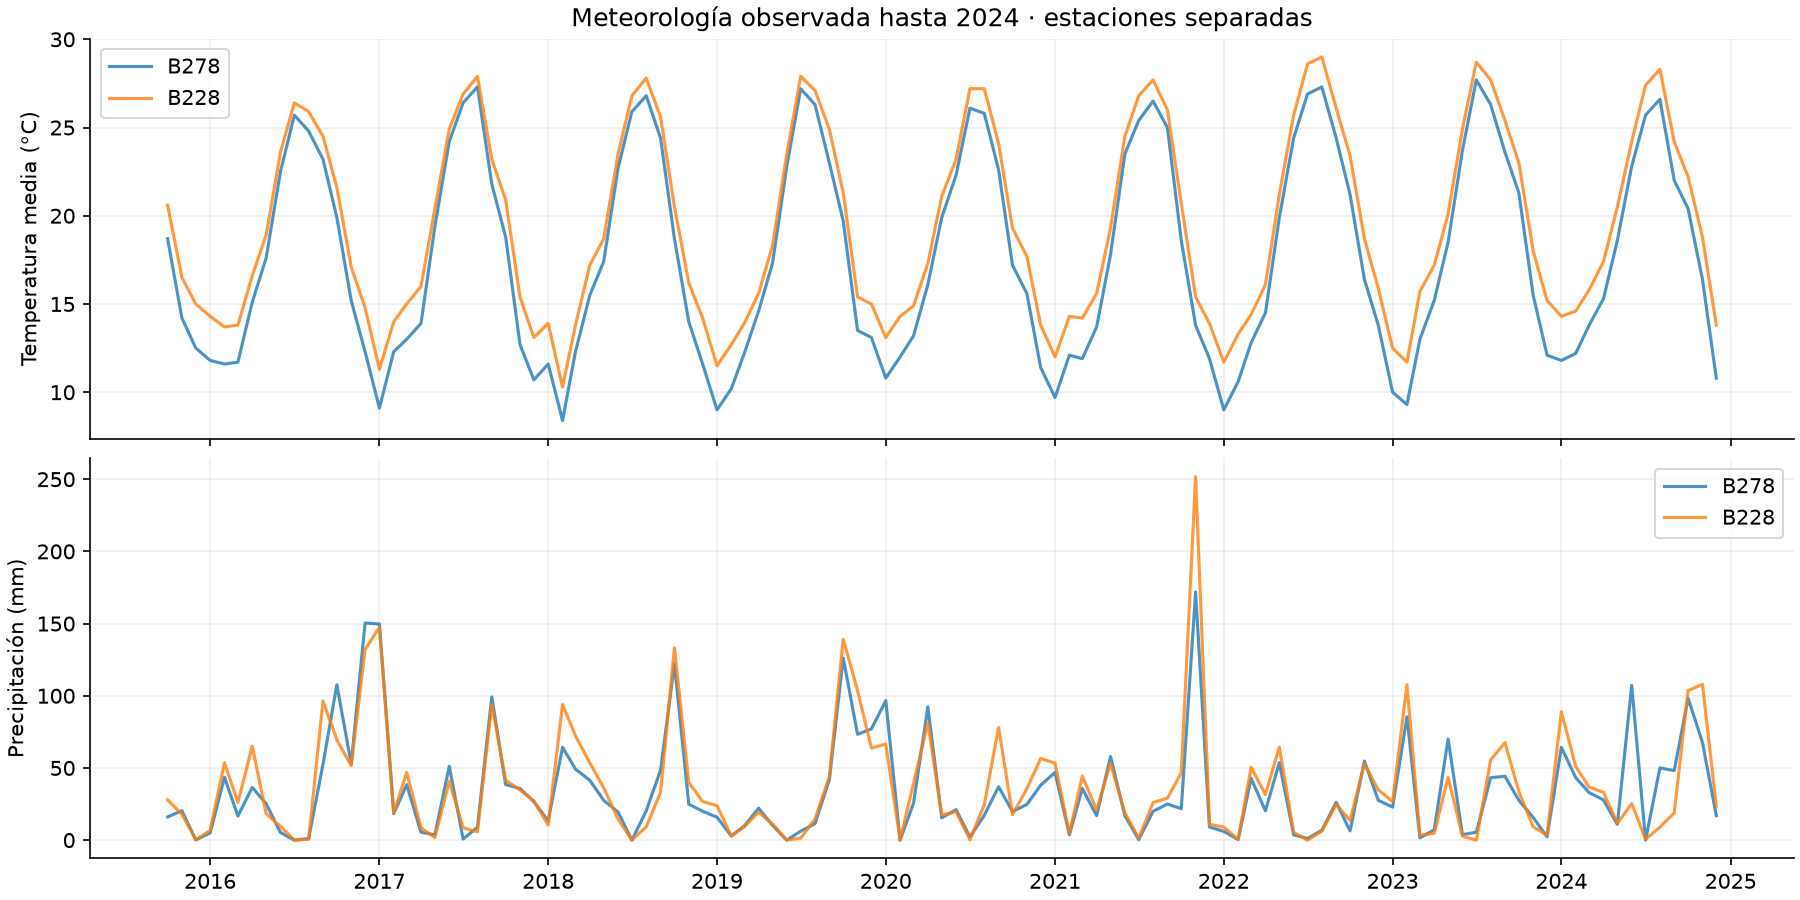


## 41. SARIMAX con temperatura y precipitación

Se contrasta el histórico solo con temperatura media y precipitación mensual de B278. Se mantienen los órdenes ya seleccionados para SARIMA, sin buscar nuevas configuraciones, el calendario de 288 emisiones y los horizontes de uno y tres meses. Ambas variantes usan la misma ventana: comienza cuando existen referencias meteorológicas en el maestro. Este control se estima de nuevo porque la disponibilidad de AEMET exige una ventana distinta de la comparación con AENA y hoteles.

Las variables observadas se alinean con cada objetivo con retardo `h + 2 + espera adicional`: 3/5 meses en la base y 4/6 en sensibilidad. Cada paso intermedio debe tener una referencia publicada bajo la política t−2/t−3; se comprueba también su fecha efectiva cuando existe. El plazo mensual de AEMET sigue siendo un supuesto experimental, con datos revisados. No se utilizan pronósticos meteorológicos ni el tiempo observado del mes que se pretende predecir.

Temperatura y precipitación están completas, por lo que no se imputan; se conservan los ceros reales. La media y desviación de cada predictor se calculan solo con etiquetas publicadas de entrenamiento anteriores a 2025. Una publicación tardía bloquea la entrada en lugar de rellenarla. Se comprueba que alterar datos aún no publicados no cambie los pronósticos.

Se generan predicciones reservadas de 2025 con `EVALUATE_FINAL_2025=False`: sin objetivos observados, errores ni métricas de prueba. La comparación principal utiliza los 55 meses de selección hasta julio de 2024; los cinco posteriores son diagnóstico retrospectivo. Los resultados y auditorías se guardan separados en `outputs/modelos/sarimax_meteorologia/`. Las mejoras se calculan frente al control de esta comparación, sin atribuir causalidad ni compararlas directamente con el control de ventana diferente de AENA/hoteles.


In [33]:
WX_DIR = PROJECT_ROOT / "outputs" / "modelos" / "sarimax_meteorologia"
WX_DIR.mkdir(parents=True, exist_ok=True)
WX_VARIANTS = {"historico_comun": [], "temperatura_precipitacion": list(METEO_CORE)}
WX_HOTELS = []
wx_cache, wx_fit_audit, wx_prep_audit, wx_forecast_inputs = {}, [], [], []

def wx_inputs(data, row, variables, dates=None):
    wait = int(row.escenario == "espera_adicional")
    lag = row.horizonte + PUBLICATION_DELAYS["meteorologia"] + wait
    start = data.index.min() + pd.DateOffset(months=lag)
    index = pd.date_range(start, row.mes_objetivo, freq="MS")
    raw = pd.DataFrame(index=index)
    audit = []
    for variable in variables:
        group = "meteorologia"
        values = []
        for target in index:
            ref = target - pd.DateOffset(months=lag)
            implied_cutoff = (target-pd.DateOffset(months=row.horizonte)).to_period("M").end_time.normalize()
            cutoff = min(row.fecha_corte, implied_cutoff)
            released = publication_date(group, ref.to_period("M"), wait,
                verified_dates if dates is None else dates)
            permitted = released <= cutoff
            value = data.at[ref, variable] if permitted else np.nan
            values.append(value)
            audit.append({"variable": variable, "mes_fila": target, "mes_referencia": ref,
                "fecha_publicacion": released, "fecha_corte_entrada": cutoff,
                "publicacion_permitida": permitted, "ausente": bool(pd.isna(value)), "retardo_objetivo": lag})
        raw[variable] = values
    return raw, pd.DataFrame(audit)

def wx_prepare(data, row, variant, dates=None):
    variables = WX_VARIANTS[variant]
    history, state = sarima_history(data, row, dates)
    raw, audit = wx_inputs(data, row, variables, dates)
    history = history.reindex(raw.loc[:history.index[-1]].index).asfreq("MS")
    state = state.reindex(raw.loc[:state.index[-1]].index).asfreq("MS")
    assert len(history) >= 36
    known = history.index[history.notna()]
    info = {"inicio_historia": history.index.min(), "ultimo_y_parametros": history.index.max(),
        "ultimo_y_estado": state.index.max(), "n_meses_parametros": len(history),
        "n_actualizaciones_2025": len(state)-len(history), "retardo_externo_objetivo": row.horizonte+PUBLICATION_DELAYS["meteorologia"]+int(row.escenario=="espera_adicional")}
    if not variables:
        return history, state, None, info, audit, None
    hotel_columns = [v for v in variables if v in WX_HOTELS]
    imputer = HotelMedianImputer().fit(raw.loc[known], hotel_columns)
    prepared = imputer.transform(raw)
    means = prepared.loc[known].mean()
    stds = prepared.loc[known].std(ddof=0)
    active = stds.index[stds.gt(1e-12)].tolist()
    assert active, "No hay predictores con variación en entrenamiento"
    scaled = ((prepared[active]-means[active])/stds[active]).astype(float)
    assert scaled.notna().all().all() and np.isfinite(scaled.to_numpy()).all()
    info.update(columnas_activas=json.dumps(active), columnas_constantes=json.dumps(stds.index[~stds.gt(1e-12)].tolist()),
        medianas=json.dumps(imputer.medians_.to_dict()), medias=json.dumps(means.to_dict()),
        desviaciones=json.dumps(stds.to_dict()), n_filas_mediana=len(known),
        sustituciones_entrenamiento=int(raw.loc[known,hotel_columns].isna().sum().sum()),
        sustituciones_fuera_entrenamiento=int(raw.loc[~raw.index.isin(known),hotel_columns].isna().sum().sum()))
    return history, state, scaled, info, audit, prepared

def wx_fit(history, exog, candidate, variant):
    digest = hashlib.sha256(pd.util.hash_pandas_object(history,index=True).values.tobytes()
        + (b"" if exog is None else pd.util.hash_pandas_object(exog,index=True).values.tobytes()
           + "|".join(exog.columns).encode())).hexdigest()
    key = (candidate, variant, digest)
    if key in wx_cache: return wx_cache[key]
    result = None
    order, seasonal = SARIMA_CANDIDATES[candidate]
    for method in ["lbfgs", "powell"]:
        entry = {"configuracion": candidate, "variante": variant, "hash_ajuste": digest,
            "inicio_historia": history.index.min(), "ultimo_y_parametros": history.index.max(),
            "n_meses": len(history), "metodo": method}
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            try:
                fitted = SARIMAX(history, exog=exog, order=order, seasonal_order=seasonal, trend="n",
                    enforce_stationarity=True, enforce_invertibility=True).fit(method=method,maxiter=300,disp=False)
                ok = bool(fitted.mle_retvals.get("converged",False)) and np.isfinite(fitted.params).all() and np.isfinite(fitted.llf)
                entry.update(convergencia=bool(ok), log_verosimilitud=float(fitted.llf), parametros=json.dumps(fitted.params.to_dict()))
                if ok: result=fitted
            except Exception as exc:
                entry.update(convergencia=False, excepcion=f"{type(exc).__name__}: {exc}")
            entry["avisos"] = " | ".join(str(w.message) for w in caught)
        wx_fit_audit.append(entry)
        if result is not None: break
    wx_cache[key]=result
    return result

def wx_forecast(data, row, variant, dates=None, record_audit=True):
    history, state, exog, info, audit, prepared = wx_prepare(data,row,variant,dates)
    candidate = selected_map[(row.escenario,row.horizonte)]
    fitted = wx_fit(history, None if exog is None else exog.loc[history.index], candidate, variant)
    info.update(configuracion=candidate, pasos_internos=row.mes_objetivo.to_period("M").ordinal-state.index[-1].to_period("M").ordinal)
    if record_audit:
        wx_prep_audit.append(dict(escenario=row.escenario,horizonte=row.horizonte,mes_origen=row.mes_origen,variante=variant,**info))
        if len(audit):
            future_audit = audit.loc[audit.mes_fila.gt(state.index.max())].copy()
            for k,v in {"escenario":row.escenario,"horizonte":row.horizonte,"mes_origen":row.mes_origen,"variante":variant}.items(): future_audit[k]=v
            wx_forecast_inputs.append(future_audit)
    if fitted is None:
        return dict(info,prediccion=np.nan,prediccion_bruta=np.nan,limitada_a_cero=False,estado_ejecucion="ajuste_no_convergente")
    if len(state)>len(history):
        previous=fitted.params.copy()
        extension=state.iloc[len(history):]
        fitted=fitted.append(extension,exog=None if exog is None else exog.loc[extension.index],refit=False)
        assert np.array_equal(previous.to_numpy(),fitted.params.to_numpy())
    future_index=pd.date_range(state.index[-1]+pd.DateOffset(months=1),row.mes_objetivo,freq="MS")
    future_exog=None if exog is None else exog.loc[future_index]
    forecast=fitted.get_forecast(steps=info["pasos_internos"],exog=future_exog).predicted_mean
    assert forecast.index[-1]==row.mes_objetivo
    raw=float(forecast.iloc[-1]*SARIMA_SCALE)
    return dict(info,prediccion=max(0.,raw),prediccion_bruta=raw,limitada_a_cero=bool(raw<0),estado_ejecucion="ok" if np.isfinite(raw) else "pronostico_no_finito")

In [34]:
wx_records=[]
for variant in WX_VARIANTS:
    for row in evaluation_plan.itertuples(index=False):
        enabled=row.uso=="validacion" or EVALUATE_FINAL_2025
        record=row._asdict()
        record.update(modelo="SARIMA común" if variant=="historico_comun" else "SARIMAX",
            variante=variant,evaluacion_habilitada=enabled,
            observado=float(master.at[row.mes_objetivo,"turistas"]) if enabled else np.nan,
            estado_objetivo=master.at[row.mes_objetivo,"turistas_estado"] if enabled else None)
        record.update(wx_forecast(master,row,variant))
        record["error"]=record["observado"]-record["prediccion"] if enabled else np.nan
        wx_records.append(record)
    print("Variante meteorológica terminada:",variant,flush=True)
wx_predictions=pd.DataFrame(wx_records)
wx_metrics=summarize_forecast_errors(wx_predictions,["variante","escenario","horizonte","papel"])
wx_annual=summarize_forecast_errors(wx_predictions,["variante","escenario","horizonte","fold"])
wx_periods=summarize_forecast_errors(wx_predictions.loc[wx_predictions.uso.eq("validacion")],["variante","escenario","horizonte","periodo"])
wx_no_U=summarize_forecast_errors(wx_predictions.loc[wx_predictions.uso.eq("validacion") & ~wx_predictions.estado_objetivo.eq("U")],
    ["variante","escenario","horizonte","papel"])
wx_raw=wx_predictions.copy()
wx_raw["prediccion"]=wx_raw.prediccion_bruta
wx_raw["error"]=wx_raw.observado-wx_raw.prediccion
wx_raw_metrics=summarize_forecast_errors(wx_raw,["variante","escenario","horizonte","papel"])
wx_control=wx_metrics.loc[wx_metrics.variante.eq("historico_comun"),["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
wx_comparison=wx_metrics.merge(wx_control,on=["escenario","horizonte","papel"],suffixes=("","_historico"),validate="many_to_one")
wx_comparison["mejora_RMSE_porcentaje"]=np.where(wx_comparison.n_puntuados.eq(wx_comparison.n_esperados)
    & wx_comparison.n_puntuados.eq(wx_comparison.n_puntuados_historico),100*(1-wx_comparison.RMSE/wx_comparison.RMSE_historico),np.nan)
wx_ranking=wx_metrics.loc[wx_metrics.papel.eq("seleccion")].copy()
wx_ranking["elegible"]=wx_ranking.n_pronosticos.eq(55)&wx_ranking.n_puntuados.eq(55)
wx_ranking["puesto_RMSE"]=wx_ranking.loc[wx_ranking.elegible].groupby(["escenario","horizonte"]).RMSE.rank(method="min")
display(wx_comparison.loc[wx_comparison.escenario.eq("base"),["variante","horizonte","papel","n_puntuados","RMSE","RMSE_historico","mejora_RMSE_porcentaje"]])
for name,table in {"predicciones":wx_predictions,"metricas_bloques":wx_metrics,"metricas_anuales":wx_annual,
    "metricas_periodos":wx_periods,"diagnostico_sin_objetivos_U":wx_no_U,"metricas_sin_limite_cero":wx_raw_metrics,
    "comparacion_historico_comun":wx_comparison,"clasificacion_seleccion":wx_ranking,
    "auditoria_ajustes":pd.DataFrame(wx_fit_audit),"preprocesamiento_por_emision":pd.DataFrame(wx_prep_audit),
    "disponibilidad_pasos_pronostico":pd.concat(wx_forecast_inputs,ignore_index=True)}.items():
    table.to_csv(WX_DIR/(name+".csv"),index=False,encoding="utf-8-sig")

Variante meteorológica terminada: historico_comun


Variante meteorológica terminada: temperatura_precipitacion


,variante,horizonte,papel,n_puntuados,RMSE,RMSE_historico,mejora_RMSE_porcentaje
0,historico_comun,1,diagnostico_fijo,5,231227.464039,231227.464039,0.000000
1,historico_comun,1,prueba_final,0,NaN,NaN,NaN
2,historico_comun,1,seleccion,55,405305.671912,405305.671912,0.000000
3,historico_comun,3,diagnostico_fijo,5,236500.668384,236500.668384,0.000000
4,historico_comun,3,prueba_final,0,NaN,NaN,NaN
5,historico_comun,3,seleccion,55,521775.694507,521775.694507,0.000000
12,temperatura_precipitacion,1,diagnostico_fijo,5,230278.854193,231227.464039,0.410250
13,temperatura_precipitacion,1,prueba_final,0,NaN,NaN,NaN
14,temperatura_precipitacion,1,seleccion,55,401253.233460,405305.671912,0.999847
15,temperatura_precipitacion,3,diagnostico_fijo,5,244502.623184,236500.668384,-3.383481


In [35]:
assert len(wx_predictions)==2*len(evaluation_plan)==576
assert wx_predictions.estado_ejecucion.eq("ok").all(), "Hay emisiones fallidas; revisar auditoría"
keys=["escenario","horizonte","mes_origen","mes_objetivo"]
for variant in WX_VARIANTS:
    block=wx_predictions.loc[wx_predictions.variante.eq(variant)]
    pd.testing.assert_frame_equal(block[keys].reset_index(drop=True),evaluation_plan[keys].reset_index(drop=True))
assert wx_predictions.ultimo_y_parametros.le(TRAIN_TARGET_END).all()
assert wx_predictions.prediccion.notna().all()
if not EVALUATE_FINAL_2025:
    heldout=wx_predictions.loc[wx_predictions.uso.eq("prueba_final")]
    assert heldout[["observado","error"]].isna().all().all()
    assert heldout.estado_objetivo.isna().all() and not heldout.evaluacion_habilitada.any()
    assert wx_metrics.loc[wx_metrics.papel.eq("prueba_final"),"n_puntuados"].eq(0).all()
path_audit=pd.concat(wx_forecast_inputs,ignore_index=True)
assert path_audit.publicacion_permitida.all() and not path_audit.ausente.any()
assert path_audit.fecha_publicacion.le(path_audit.fecha_corte_entrada).all()
# Misma ventana de entrenamiento y estado para ambas variantes en cada emisión.
comparison_info=wx_predictions.pivot(index=keys,columns="variante",values=["inicio_historia","ultimo_y_parametros","ultimo_y_estado","n_meses_parametros"])
for field in ["inicio_historia","ultimo_y_parametros","ultimo_y_estado","n_meses_parametros"]:
    assert comparison_info[field].historico_comun.equals(comparison_info[field].temperatura_precipitacion)
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
        wait=int(scenario=="espera_adicional")
        changed=master.copy(deep=True)
        for group,variables in {"turistas":["turistas"],"meteorologia":METEO_CORE}.items():
            future=[d for d in changed.index if publication_date(group,d.to_period("M"),wait,verified_dates)>row.fecha_corte]
            changed.loc[future,variables]=99_999_999.
        for variant in WX_VARIANTS:
            assert wx_forecast(master,row,variant,record_audit=False)==wx_forecast(changed,row,variant,record_audit=False)
        reference=row.mes_objetivo-pd.DateOffset(months=horizon+PUBLICATION_DELAYS["meteorologia"]+wait)
        dates=dict(verified_dates)
        dates[("meteorologia",reference)]=row.fecha_corte+pd.Timedelta(days=1)
        late_raw,late_audit=wx_inputs(master,row,METEO_CORE,dates)
        assert late_raw.loc[row.mes_objetivo].isna().all()
        try:
            wx_prepare(master,row,"temperatura_precipitacion",dates)
        except ValueError:
            pass
        else:
            raise AssertionError("Una publicación meteorológica tardía debe bloquear el pronóstico; no se imputa")
assert master.loc["2020-04-01":"2020-05-01","turistas"].eq(0).all()
assert hashlib.sha256((OUTPUT_DIR/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()==feature_manifest["maestro_sha256"]
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    for variant in WX_VARIANTS:
        block=wx_predictions.loc[wx_predictions.escenario.eq("base")&wx_predictions.horizonte.eq(horizon)
            &wx_predictions.variante.eq(variant)&wx_predictions.uso.eq("validacion")]
        ax.plot(block.mes_objetivo,block.prediccion/1e6,label=variant,alpha=.85)
    ax.plot(block.mes_objetivo,block.observado/1e6,label="Observado",color="black",lw=2)
    ax.axvline(SELECTION_TARGET_END+pd.DateOffset(months=1),color="gray",ls=":")
    ax.set(title=f"Meteorología B278 · horizonte {horizon} meses",ylabel="Turistas (millones)")
    ax.legend(fontsize=9)
axes[-1].set_xlabel("Mes objetivo")
fig.savefig(WX_DIR/"validacion_sarimax_meteorologia.png",dpi=150)
plt.show()
plt.close(fig)
wx_manifest={"modelo":"SARIMAX","variantes":WX_VARIANTS,"estacion":"B278",
    "ordenes":"fijos, seleccionados previamente para SARIMA",
    "ventana":"común para histórico y meteorología, inicio maestro + horizonte + retardo AEMET + espera",
    "disponibilidad":"t-2 base y t-3 sensibilidad desde origen; supuesto mensual no verificado",
    "retardo_objetivo":"h+2 base; h+3 sensibilidad; comprobados todos los pasos internos",
    "imputacion_meteorologica":False,"escala":"media y desviación exclusivamente de entrenamiento con etiquetas publicadas anteriores a 2025",
    "emisiones":len(wx_predictions),"fallos":int(wx_predictions.estado_ejecucion.ne("ok").sum()),
    "evaluacion_final_2025_habilitada":EVALUATE_FINAL_2025,
    "actualizacion_2025":"estado con datos publicados, sin reajustar parámetros ni preprocesamiento con etiquetas 2025",
    "hash_maestro":feature_manifest["maestro_sha256"],"controles":"superados",
    "limites":["datos revisados y primera publicación mensual no reconstruida","estación local, no toda Mallorca",
        "órdenes fijos y dos predictores, sin búsqueda adicional","selección y diagnóstico retrospectivos no son prueba independiente",
        "control con ventana diferente de AENA/hoteles: no comparar mejoras como si compartieran control"]}
(WX_DIR/"ejecucion.json").write_text(json.dumps(wx_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
meteo_manifest["modelos_con_meteorologia_entrenados"]=True
(METEO_DIR/"integracion.json").write_text(json.dumps(meteo_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("SARIMAX meteorología comprobado:",len(wx_predictions),"emisiones; 2025 puntuado:",EVALUATE_FINAL_2025)


SARIMAX meteorología comprobado: 576 emisiones; 2025 puntuado: False


C:\Users\acort\AppData\Local\Temp\ipykernel_20032\2310121797.py:57: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Lectura de SARIMAX con meteorología

Las dos variantes completan las 288 emisiones previstas cada una, sin fallos finales, para un total de 576. Los ajustes y la normalización utilizan objetivos publicados anteriores a 2025; las observaciones de 2025 disponibles actualizan únicamente el estado. Los controles del calendario común, las ventanas, los datos aún no publicados y las fechas tardías han pasado. Las fuentes, el maestro y los productos de los modelos anteriores conservan sus hashes.

La comparación de los 55 meses de selección (enero de 2020–julio de 2024) es:

| Disponibilidad | Horizonte | RMSE histórico | RMSE con meteorología | Mejora relativa |
| --- | ---: | ---: | ---: | ---: |
| base | 1 meses | 405,306 | 401,253 | +1.00 % |
| base | 3 meses | 521,776 | 528,439 | -1.28 % |
| espera_adicional | 1 meses | 464,415 | 491,662 | -5.87 % |
| espera_adicional | 3 meses | 564,445 | 576,982 | -2.22 % |

El RMSE se expresa en turistas; una mejora positiva indica menor error con meteorología. En la base, la reducción a un mes es pequeña, aproximadamente un 1 %. A tres meses el error aumenta un 1,28 %. Al retrasar otro mes las entradas, la meteorología aumenta el error en los dos horizontes, un 5,87 % y un 2,22 %. La ventaja a corto plazo no se mantiene bajo esta sensibilidad.

En los cinco meses de diagnóstico posteriores de 2024, la mejora base a un mes es de solo un 0,41 %, mientras a tres meses el error aumenta un 3,38 %. Con espera adicional el error aumenta un 0,54 % a un mes y disminuye un 3,68 % a tres meses. Este diagnóstico retrospectivo es breve y no constituye una prueba independiente; no cambia la conclusión de que la aportación observada es pequeña y depende del horizonte y la disponibilidad.

Se registran 526 intentos de optimización: 516 ajustes convergentes y diez intentos iniciales no convergentes resueltos con el segundo optimizador. Las predicciones negativas se limitan a cero según la regla previa y se conservan también las predicciones originales y sus métricas. No se han imputado variables meteorológicas ni eliminado ceros.

Estos resultados justifican conservar el histórico solo como referencia y evaluar la meteorología como alternativa, sin afirmar una mejora general. Se ha probado una estación local, dos variables y órdenes fijos: no demuestra que la meteorología carezca de utilidad en otras especificaciones. Los plazos mensuales t−2/t−3 siguen siendo supuestos de una simulación con datos revisados. La evaluación final de 2025 continúa desactivada y no se utiliza para elegir modelos.

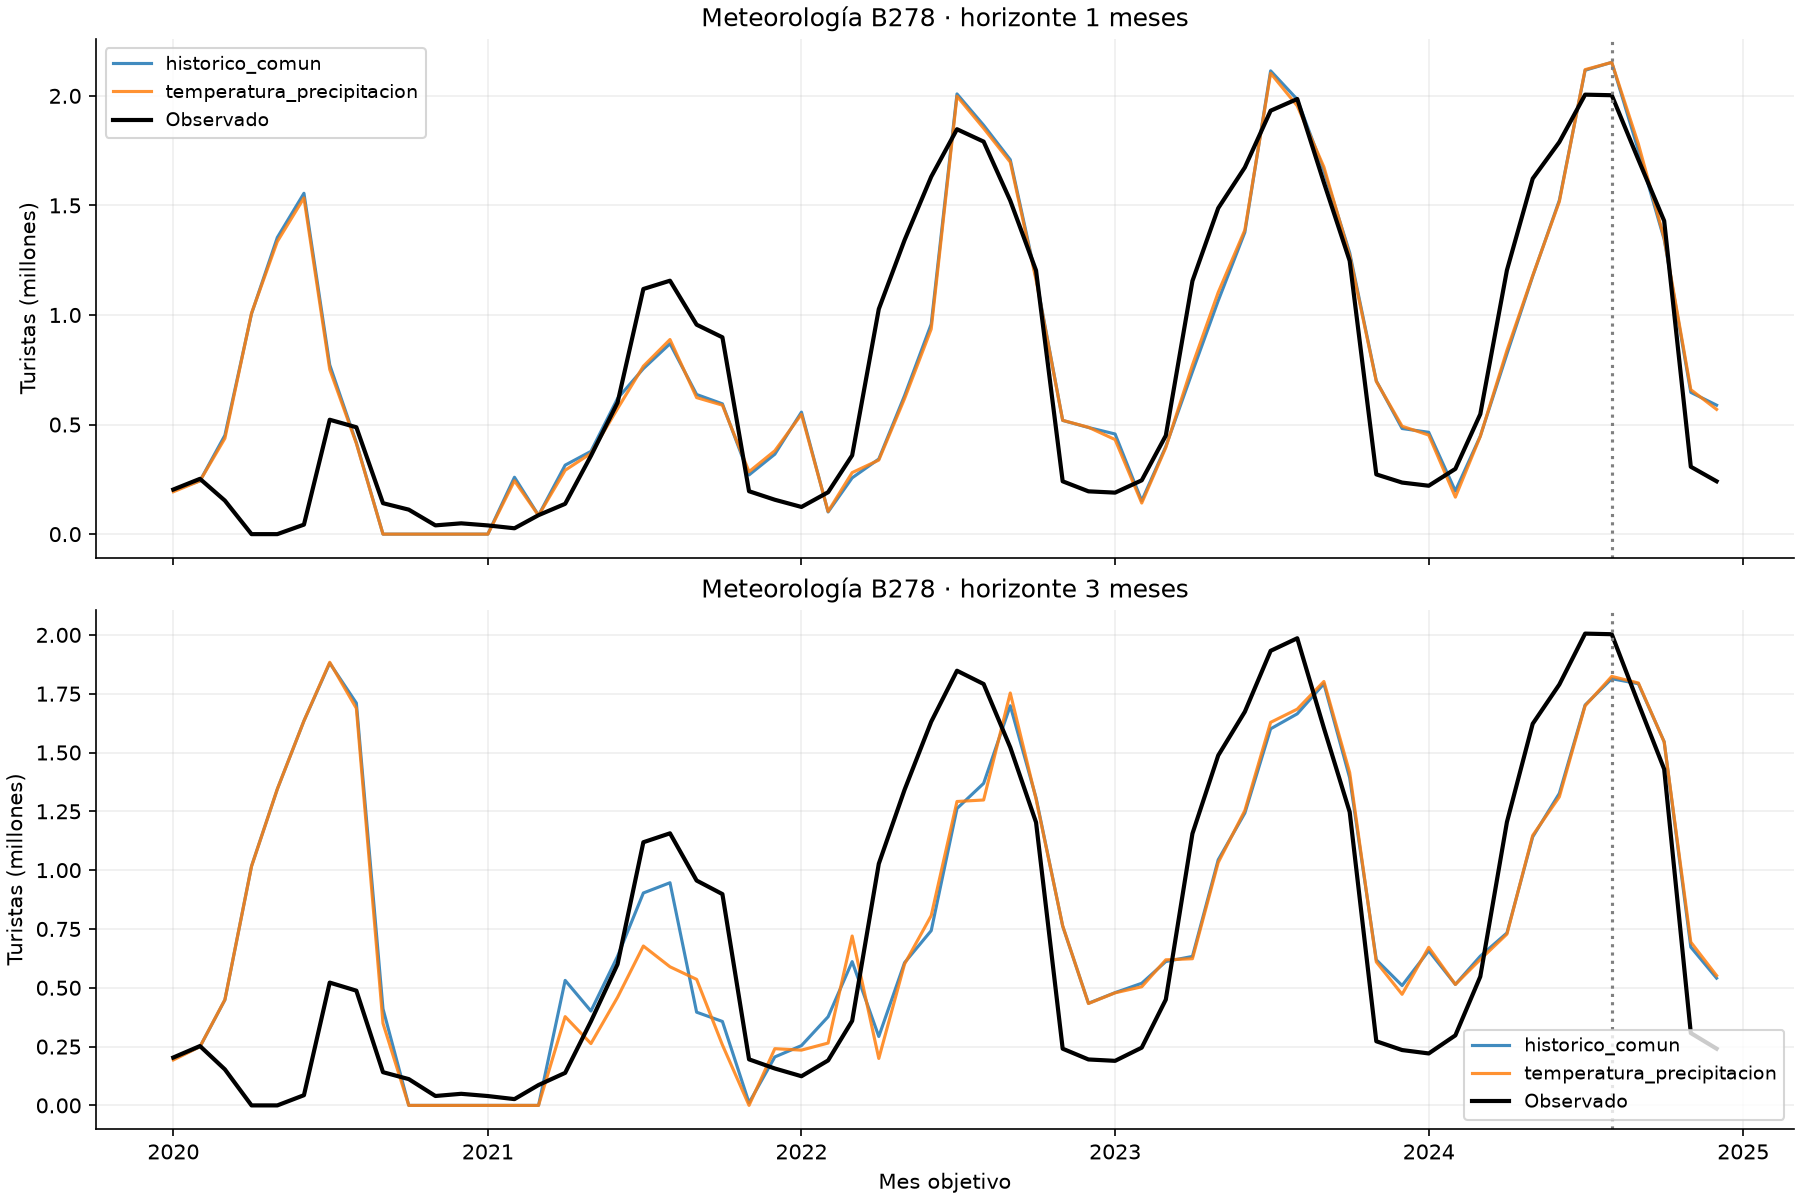


## 42. Random Forest: turistas y calendario

Se introduce una primera referencia de aprendizaje automático con diez predictores derivados del histórico de turistas (seis retardos, tres medias móviles y el mismo mes del año anterior) y cuatro variables de calendario del objetivo (mes, seno, coseno y tiempo mensual). El catálogo existente determina los nombres y retardos por horizonte y escenario; se excluyen las fuentes externas y los estados de observación.

La predicción es **directa**: un bosque separado para cada horizonte, con entradas conocidas al cierre del origen. No se predice recursivamente el mes intermedio. Se mantienen las 288 emisiones del protocolo, los 55 objetivos de selección y los cinco de diagnóstico por horizonte y escenario. El entrenamiento supervisado comienza con objetivos de abril de 2017 y utiliza exactamente los índices autorizados por el protocolo, con al menos 24 filas. No tiene toda la historia secuencial utilizada por SARIMA; las métricas comparan los mismos objetivos, pero esta diferencia de longitud de entrenamiento debe tenerse en cuenta.

La configuración inicial se fija antes de medir sus resultados: 300 árboles, `min_samples_leaf=3`, `max_features=1.0`, profundidad sin límite, bootstrap y semilla 42. Tres observaciones mínimas por hoja limitan particiones muy pequeñas en una muestra mensual reducida. Es una referencia inicial sin búsqueda de hiperparámetros, validación aleatoria ni puntuación OOB; estos valores no se presentan como óptimos. Se utiliza [RandomForestRegressor de scikit-learn](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html).

Los árboles reciben las variables en sus unidades originales: no se estima un escalado ni se imputan estas entradas completas. Un ausente inesperado bloquea el pronóstico. Los ceros reales permanecen en las entradas y etiquetas de entrenamiento. Cada ajuste recibe únicamente etiquetas ya publicadas y anteriores a 2025. En la prueba se pueden incorporar retardos publicados de 2025 como entradas, sin entrenar con objetivos de 2025. `EVALUATE_FINAL_2025=False` mantiene reservadas las observaciones y errores finales. Las fechas históricas y versiones revisadas siguen siendo una limitación de esta simulación.


In [30]:
from sklearn.ensemble import RandomForestRegressor

RF_DIR = PROJECT_ROOT / "outputs" / "modelos" / "random_forest"
RF_DIR.mkdir(parents=True, exist_ok=True)
RF_PARAMS = {"n_estimators":300,"criterion":"squared_error","min_samples_leaf":3,
    "max_features":1.0,"max_depth":None,"bootstrap":True,"random_state":42,"n_jobs":1}
rf_columns, rf_cache, rf_fit_audit = {}, {}, []
for scenario,horizon in prediction_sets:
    wait=int(scenario=="espera_adicional")
    catalog=feature_catalog.loc[feature_catalog.horizonte.eq(horizon)&feature_catalog.espera_adicional.eq(wait)]
    rf_columns[(scenario,horizon)]=catalog.loc[catalog.grupo.isin(["turistas","calendario"]),"predictor"].tolist()
    assert len(rf_columns[(scenario,horizon)])==14


def rf_prepare(data,row,dates=None):
    wait=int(row.escenario=="espera_adicional")
    if data is master and dates is None:
        X,meta=prediction_sets[(row.escenario,row.horizonte)]
    else:
        X,meta,_,_=build_prediction_features(data,row.horizonte,wait,verified_dates if dates is None else dates)
    cols=rf_columns[(row.escenario,row.horizonte)]
    indices=training_indices.loc[training_indices.escenario.eq(row.escenario)
        &training_indices.horizonte.eq(row.horizonte)
        &training_indices.mes_origen_pronostico.eq(row.mes_origen)]
    origins=pd.DatetimeIndex(indices.mes_origen_entrenamiento)
    assert len(origins)==row.n_entrenamiento_supervisado and len(origins)>=MIN_TRAIN_ROWS
    labels=meta.loc[origins]
    assert labels.mes_objetivo.between(TRAIN_TARGET_START,TRAIN_TARGET_END).all()
    assert labels.fecha_publicacion_objetivo.le(row.fecha_corte).all()
    assert labels.mes_objetivo.lt(row.mes_objetivo).all() and (origins<row.mes_origen).all()
    assert labels.mes_objetivo.tolist()==indices.mes_objetivo_entrenamiento.tolist()
    train_X=X.loc[origins,cols].copy()
    train_y=labels.turistas_objetivo.astype(float).copy()
    forecast_X=X.loc[[row.mes_origen],cols].copy()
    if train_X.isna().any().any() or train_y.isna().any() or forecast_X.isna().any().any():
        raise ValueError("Entrada turística/calendario o etiqueta ausente: Random Forest no imputa ni elimina emisiones")
    assert np.isfinite(train_X.to_numpy()).all() and np.isfinite(train_y.to_numpy()).all()
    assert np.isfinite(forecast_X.to_numpy()).all() and train_y.ge(0).all()
    details={"n_entrenamiento":len(origins),"n_predictores":len(cols),
        "inicio_objetivos_entrenamiento":labels.mes_objetivo.min(),
        "ultimo_y_parametros":labels.mes_objetivo.max(),
        "ultima_publicacion_entrenamiento":labels.fecha_publicacion_objetivo.max(),
        "ceros_entrenamiento":int(train_y.eq(0).sum()),"predictores":json.dumps(cols,ensure_ascii=False)}
    return train_X,train_y,forecast_X,details


def rf_forecast(data,row,dates=None,record_audit=True):
    train_X,train_y,forecast_X,details=rf_prepare(data,row,dates)
    digest=hashlib.sha256(pd.util.hash_pandas_object(train_X,index=True).values.tobytes()
        +pd.util.hash_pandas_object(train_y,index=True).values.tobytes()
        +"|".join(train_X.columns).encode()+json.dumps(RF_PARAMS,sort_keys=True).encode()).hexdigest()
    # Solo el último ajuste por horizonte y escenario: reutilización en 2025 sin guardar todos los bosques.
    key=(row.escenario,row.horizonte)
    reused=key in rf_cache and rf_cache[key][0]==digest
    if reused:
        model=rf_cache[key][1]
    else:
        model=RandomForestRegressor(**RF_PARAMS).fit(train_X,train_y)
        rf_cache[key]=(digest,model)
    value=float(model.predict(forecast_X)[0])
    assert np.isfinite(value) and train_y.min()-1e-7<=value<=train_y.max()+1e-7
    details.update(hash_ajuste=digest,ajuste_reutilizado=reused,prediccion=value,estado_ejecucion="ok")
    if record_audit:
        rf_fit_audit.append(dict(escenario=row.escenario,horizonte=row.horizonte,mes_origen=row.mes_origen,
            mes_objetivo=row.mes_objetivo,fecha_corte=row.fecha_corte,
            parametros=json.dumps(RF_PARAMS,sort_keys=True),**details))
    return details


In [29]:
rf_records=[]
for i,row in enumerate(evaluation_plan.itertuples(index=False)):
    enabled=row.uso=="validacion" or EVALUATE_FINAL_2025
    record=row._asdict()
    record.update(modelo="Random Forest",grupo_fuentes="turistas_calendario",evaluacion_habilitada=enabled,
        observado=float(master.at[row.mes_objetivo,"turistas"]) if enabled else np.nan,
        estado_objetivo=master.at[row.mes_objetivo,"turistas_estado"] if enabled else None)
    record.update(rf_forecast(master,row))
    record["error"]=record["observado"]-record["prediccion"] if enabled else np.nan
    rf_records.append(record)
    if (i+1)%72==0: print("Random Forest:",i+1,"/",len(evaluation_plan),"emisiones",flush=True)
rf_predictions=pd.DataFrame(rf_records)
rf_metrics=summarize_forecast_errors(rf_predictions,["modelo","escenario","horizonte","papel"])
rf_annual=summarize_forecast_errors(rf_predictions,["modelo","escenario","horizonte","fold"])
rf_periods=summarize_forecast_errors(rf_predictions.loc[rf_predictions.uso.eq("validacion")],["modelo","escenario","horizonte","periodo"])
rf_no_U=summarize_forecast_errors(rf_predictions.loc[rf_predictions.uso.eq("validacion")&~rf_predictions.estado_objetivo.eq("U")],
    ["modelo","escenario","horizonte","papel"])
rf_comparisons=[]
for name,folder in [("Seasonal Naive","seasonal_naive"),("SARIMA","sarima")]:
    reference=pd.read_csv(PROJECT_ROOT/"outputs"/"modelos"/folder/"metricas_bloques.csv")
    reference=reference[["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
    comparison=rf_metrics.merge(reference,on=["escenario","horizonte","papel"],suffixes=("","_referencia"),validate="one_to_one")
    comparison["referencia"]=name
    complete=comparison.n_puntuados.eq(comparison.n_esperados)&comparison.n_puntuados.eq(comparison.n_puntuados_referencia)
    comparison["mejora_RMSE_porcentaje"]=np.where(complete,100*(1-comparison.RMSE/comparison.RMSE_referencia),np.nan)
    rf_comparisons.append(comparison)
rf_comparison=pd.concat(rf_comparisons,ignore_index=True)
rf_audit=pd.DataFrame(rf_fit_audit)
rf_catalog=feature_catalog.loc[feature_catalog.grupo.isin(["turistas","calendario"])].copy()
rf_availability=feature_audit.loc[feature_audit.grupo.eq("turistas")].copy()
for name,table in {"predicciones":rf_predictions,"metricas_bloques":rf_metrics,"metricas_anuales":rf_annual,
    "metricas_periodos":rf_periods,"diagnostico_sin_objetivos_U":rf_no_U,"comparacion_referencias":rf_comparison,
    "auditoria_ajustes":rf_audit,"catalogo_predictores":rf_catalog,
    "disponibilidad_predictores":rf_availability,"indices_entrenamiento":training_indices}.items():
    table.to_csv(RF_DIR/(name+".csv"),index=False,encoding="utf-8-sig")
display(rf_comparison.loc[rf_comparison.escenario.eq("base"),
    ["horizonte","papel","referencia","n_puntuados","RMSE","RMSE_referencia","mejora_RMSE_porcentaje"]])


Random Forest: 72 / 288 emisiones


Random Forest: 144 / 288 emisiones


Random Forest: 216 / 288 emisiones


Random Forest: 288 / 288 emisiones


,horizonte,papel,referencia,n_puntuados,RMSE,RMSE_referencia,mejora_RMSE_porcentaje
0,1,diagnostico_fijo,Seasonal Naive,5,201453.045164,95635.506441,-110.646707
1,1,prueba_final,Seasonal Naive,0,NaN,NaN,NaN
2,1,seleccion,Seasonal Naive,55,603704.072257,588182.412138,-2.638919
3,3,diagnostico_fijo,Seasonal Naive,5,272264.543909,95635.506441,-184.689812
4,3,prueba_final,Seasonal Naive,0,NaN,NaN,NaN
5,3,seleccion,Seasonal Naive,55,681873.166835,588182.412138,-15.928860
12,1,diagnostico_fijo,SARIMA,5,201453.045164,236589.029047,14.851062
13,1,prueba_final,SARIMA,0,NaN,NaN,NaN
14,1,seleccion,SARIMA,55,603704.072257,404429.040817,-49.273176
15,3,diagnostico_fijo,SARIMA,5,272264.543909,243882.067768,-11.637787


In [30]:
keys=["escenario","horizonte","mes_origen","mes_objetivo"]
assert len(rf_predictions)==len(evaluation_plan)==288
pd.testing.assert_frame_equal(rf_predictions[keys],evaluation_plan[keys])
assert rf_predictions.estado_ejecucion.eq("ok").all() and rf_predictions.prediccion.ge(0).all()
assert rf_audit.ultimo_y_parametros.le(TRAIN_TARGET_END).all()
assert rf_audit.ultima_publicacion_entrenamiento.le(rf_audit.fecha_corte).all()
assert rf_audit.n_entrenamiento.tolist()==evaluation_plan.n_entrenamiento_supervisado.tolist()
assert rf_catalog.grupo.isin(["turistas","calendario"]).all()
assert not any(c.startswith(("meteo_","pasajeros_","viajeros_hoteles","gt_")) for cols in rf_columns.values() for c in cols)
if not EVALUATE_FINAL_2025:
    final=rf_predictions.loc[rf_predictions.uso.eq("prueba_final")]
    assert final[["observado","error"]].isna().all().all() and final.estado_objetivo.isna().all()
    assert not final.evaluacion_habilitada.any()
    assert rf_metrics.loc[rf_metrics.papel.eq("prueba_final"),"n_puntuados"].eq(0).all()
# Perturbar etiquetas y retardos todavía no publicados no puede modificar entrenamiento o entradas.
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
        changed=master.copy(deep=True)
        wait=int(scenario=="espera_adicional")
        future=[d for d in changed.index if publication_date("turistas",d.to_period("M"),wait,verified_dates)>row.fecha_corte]
        changed.loc[future,"turistas"]=99_999_999.
        original=rf_prepare(master,row)
        altered=rf_prepare(changed,row)
        for a,b in zip(original[:3],altered[:3]):
            if isinstance(a,pd.DataFrame): pd.testing.assert_frame_equal(a,b)
            else: pd.testing.assert_series_equal(a,b)
        assert rf_forecast(master,row,record_audit=False)["prediccion"]==rf_forecast(changed,row,record_audit=False)["prediccion"]
        # Segunda estimación independiente con semilla fija: reproducibilidad numérica.
        repeated=RandomForestRegressor(**RF_PARAMS).fit(original[0],original[1]).predict(original[2])[0]
        assert repeated==rf_forecast(master,row,record_audit=False)["prediccion"]
        reference=row.mes_origen-pd.DateOffset(months=PUBLICATION_DELAYS["turistas"]+wait)
        dates=dict(verified_dates)
        dates[("turistas",reference)]=row.fecha_corte+pd.Timedelta(days=1)
        try: rf_prepare(master,row,dates)
        except (ValueError,AssertionError): pass
        else: raise AssertionError("Una publicación tardía debe bloquear la emisión o una etiqueta requerida")
# En 2025 los valores publicados pueden entrar como retardos, pero jamás como etiquetas de ajuste.
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2025-12-01"))].itertuples(index=False))
        changed=master.copy(deep=True)
        changed.loc[changed.index.year==2025,"turistas"]=99_999_999.
        original=rf_prepare(master,row)
        altered=rf_prepare(changed,row)
        pd.testing.assert_frame_equal(original[0],altered[0])
        pd.testing.assert_series_equal(original[1],altered[1])
        assert not original[2].equals(altered[2]), "Los retardos publicados de 2025 pueden actualizar las entradas"
assert master.loc["2020-04-01":"2020-05-01","turistas"].eq(0).all()
assert rf_audit.ceros_entrenamiento.max()==2
assert hashlib.sha256((OUTPUT_DIR/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()==feature_manifest["maestro_sha256"]
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    block=rf_predictions.loc[rf_predictions.escenario.eq("base")&rf_predictions.horizonte.eq(horizon)&rf_predictions.uso.eq("validacion")]
    ax.plot(block.mes_objetivo,block.observado/1e6,label="Observado",color="black",lw=2)
    ax.plot(block.mes_objetivo,block.prediccion/1e6,label="Random Forest",alpha=.9)
    for name,folder in [("Seasonal Naive","seasonal_naive"),("SARIMA","sarima")]:
        reference=pd.read_csv(PROJECT_ROOT/"outputs"/"modelos"/folder/"predicciones.csv",parse_dates=["mes_objetivo"])
        reference=reference.loc[reference.escenario.eq("base")&reference.horizonte.eq(horizon)&reference.uso.eq("validacion")]
        assert reference.mes_objetivo.tolist()==block.mes_objetivo.tolist()
        ax.plot(reference.mes_objetivo,reference.prediccion/1e6,label=name,alpha=.7)
    ax.axvline(SELECTION_TARGET_END+pd.DateOffset(months=1),color="gray",ls=":")
    ax.set(title=f"Turistas y calendario · horizonte {horizon} meses",ylabel="Turistas (millones)")
    ax.legend(fontsize=9,ncol=2)
axes[-1].set_xlabel("Mes objetivo")
fig.savefig(RF_DIR/"validacion_random_forest.png",dpi=150)
plt.show()
plt.close(fig)
rf_manifest={"modelo":"RandomForestRegressor","version_sklearn":importlib.metadata.version("scikit-learn"),
    "fecha_documentacion":"2026-10-10","parametros":RF_PARAMS,"busqueda_hiperparametros":False,
    "grupos":["turistas","calendario"],"predictores":{str(k):v for k,v in rf_columns.items()},
    "estrategia":"directa por horizonte, ventana expansiva e índices ML del protocolo",
    "inicio_objetivos_entrenamiento":str(TRAIN_TARGET_START.date()),"fin_etiquetas_ajuste":str(TRAIN_TARGET_END.date()),
    "imputacion":False,"escalado":False,"emisiones":len(rf_predictions),
    "fallos":int(rf_predictions.estado_ejecucion.ne("ok").sum()),"evaluacion_final_2025_habilitada":EVALUATE_FINAL_2025,
    "controles":"superados","maestro_sha256":feature_manifest["maestro_sha256"],
    "limites":["configuración inicial fija, sin optimización","muestra mensual supervisada pequeña",
        "historia de entrenamiento distinta de modelos secuenciales","versiones revisadas y calendario histórico incompleto",
        "selección y diagnóstico retrospectivos, no prueba final independiente","árboles no extrapolan por encima del rango de etiquetas de entrenamiento"]}
(RF_DIR/"ejecucion.json").write_text(json.dumps(rf_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("Random Forest verificado:",len(rf_predictions),"emisiones; 2025 sin puntuar:",not EVALUATE_FINAL_2025)


Random Forest verificado: 288 emisiones; 2025 sin puntuar: True


C:\Users\acort\AppData\Local\Temp\ipykernel_12016\3386169335.py:69: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Lectura de la primera referencia Random Forest

Se completan las 288 emisiones, sin ausentes, fallos ni cambios en el calendario. Se han realizado 258 ajustes y reutilizado 30: cuando las etiquetas publicadas de entrenamiento son idénticas, el bosque no se vuelve a estimar. El número de filas supervisadas varía entre 28 y 93. Los controles verifican los índices autorizados, la reproducibilidad de la semilla, la invariancia ante información futura, el bloqueo de publicaciones tardías y la conservación de los dos ceros turísticos de 2020. Las fuentes, el maestro y los productos de los modelos anteriores conservan sus hashes.

En los 55 meses de selección del escenario base (enero de 2020–julio de 2024), el RMSE, en turistas, es:

| Horizonte | Random Forest | Seasonal Naïve | SARIMA |
| --- | ---: | ---: | ---: |
| 1 mes | 603.704 | 588.182 | 404.429 |
| 3 meses | 681.873 | 588.182 | 515.841 |

Random Forest aumenta el error un 2,64 % y un 15,93 % frente a Seasonal Naïve, y un 49,27 % y un 32,19 % frente a SARIMA, a uno y tres meses respectivamente. La configuración inicial no supera las referencias en selección. En el escenario de espera adicional también queda por detrás: sus RMSE son 658.035 y 665.811 turistas.

En los cinco meses de diagnóstico posteriores de 2024, el RMSE base es 201.453 a un mes y 272.265 a tres meses. A un mes mejora respecto a SARIMA un 14,85 %, pero ambos horizontes quedan por detrás de Seasonal Naïve (95.636 turistas). El diagnóstico es breve y retrospectivo; no sustituye una prueba final independiente ni justifica elegir una configuración utilizando 2025.

La figura muestra dificultades durante el cambio de régimen y la recuperación, especialmente a tres meses. En el conjunto de validación 2020–2021, el RMSE base alcanza 749.836 y 832.062 turistas; en 2022–2024 se reduce a 433.142 y 509.005. Los indicadores exportados identifican ese segundo periodo como `posterior_2022_2025`, nombre heredado del protocolo, pero estas métricas contienen únicamente los 36 meses de 2022–2024. Los bosques promedian valores de entrenamiento y no extrapolan por encima de su rango: esta propiedad y la corta muestra supervisada pueden contribuir a la infraestimación de la recuperación, sin que este experimento permita aislar su causa.

Se conserva esta configuración como primera referencia de ML. No se han optimizado hiperparámetros, comparado conjuntos alternativos de predictores ni incorporado fuentes externas; estos resultados no descartan Random Forest con otras especificaciones. SARIMA utiliza una historia secuencial más larga y una configuración previamente seleccionada, mientras este bosque es una configuración inicial fija: la comparación describe lo implementado y no constituye una comparación exhaustiva de algoritmos.

Las 48 predicciones de 2025 están generadas y reservadas: no contienen observación objetivo, estado, error ni métricas finales. `EVALUATE_FINAL_2025=False` permanece desactivado para todos los modelos. Las entradas pueden actualizarse con retardos de 2025 ya publicados, sin utilizar sus etiquetas en el ajuste.

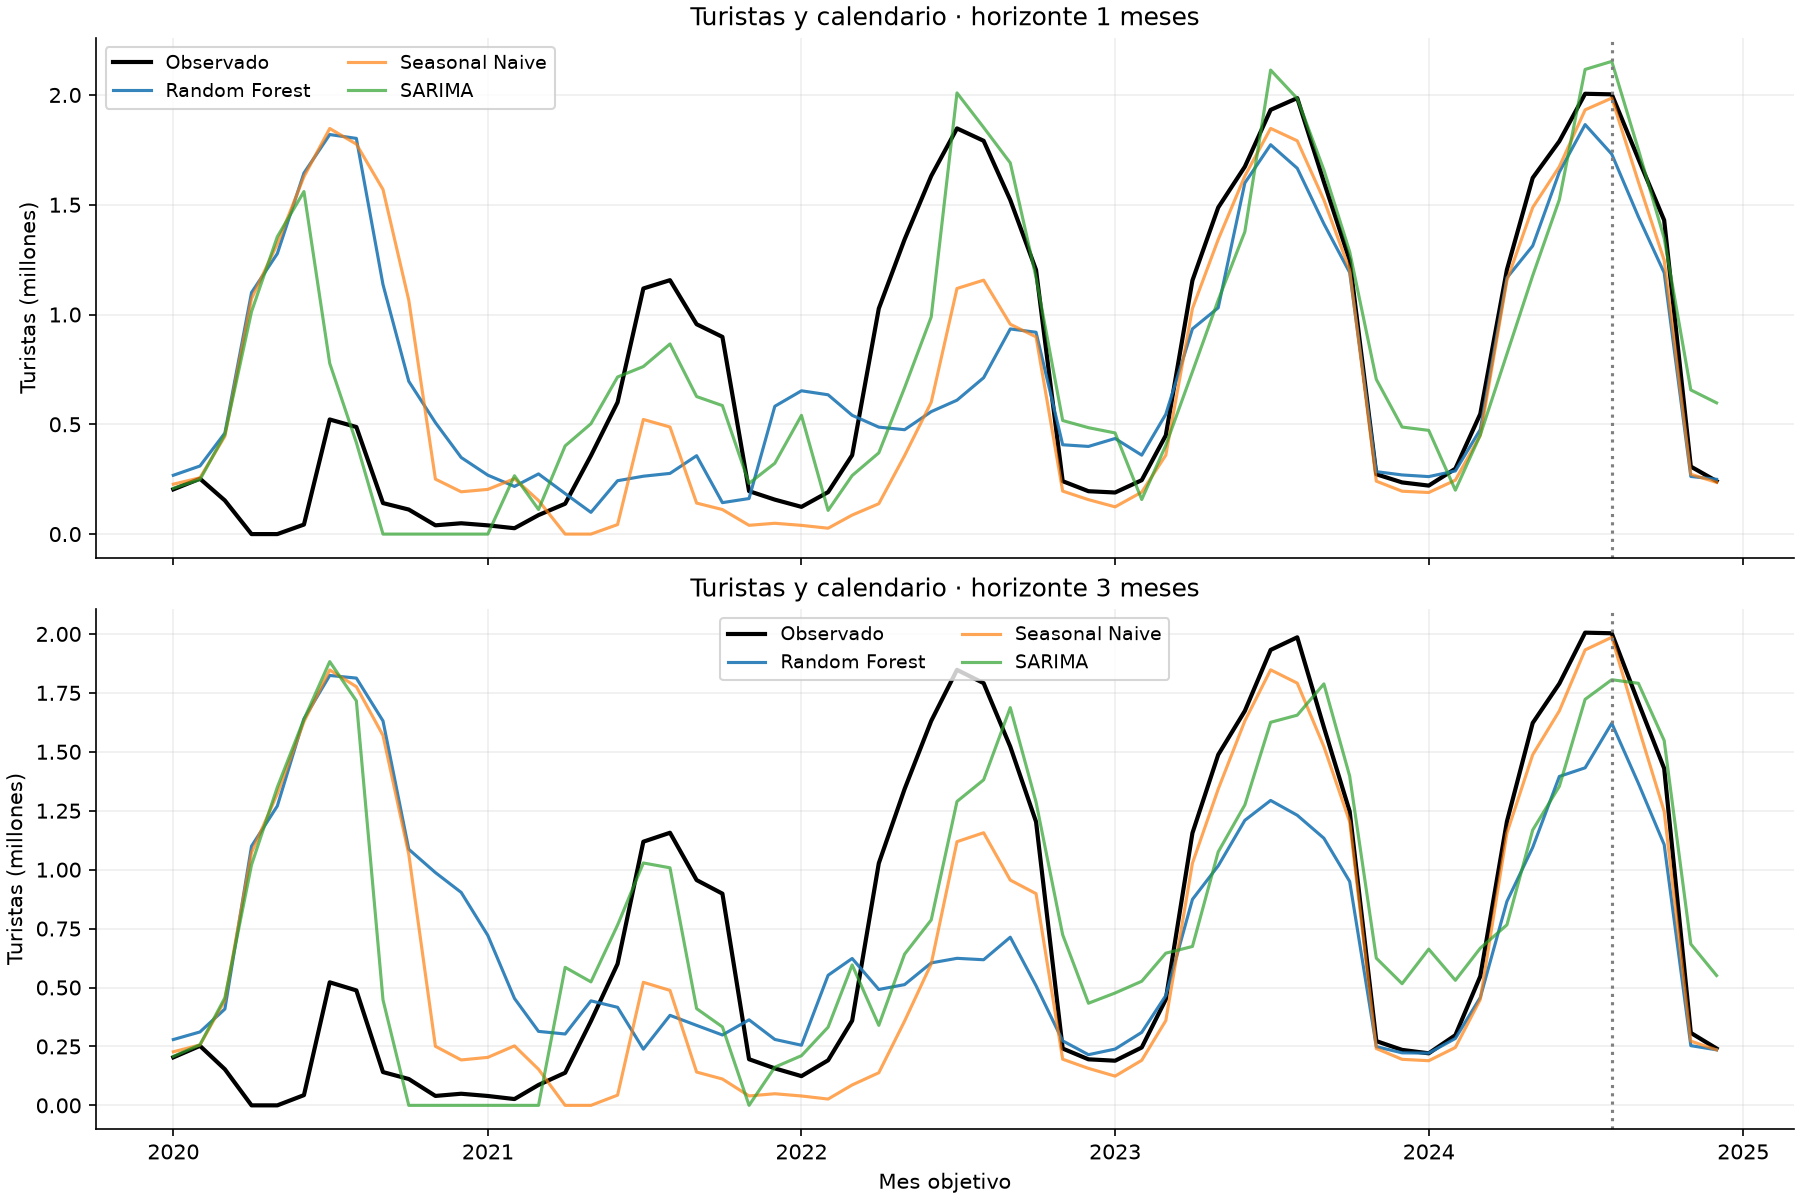


## 43. Búsqueda acotada de hiperparámetros de Random Forest

Se mantienen los 14 predictores de turistas y calendario, 300 árboles, bootstrap, todas las variables en cada división y semilla 42. Se cruzan `min_samples_leaf` = 1, 3, 5 y `max_depth` = 5, sin límite: seis configuraciones, incluida la inicial. No se optimizan simultáneamente variables externas ni otros hiperparámetros.

Para cada horizonte se selecciona una configuración **solo en el escenario base y los 55 objetivos hasta julio de 2024**. Cada emisión se vuelve a entrenar con los mismos índices supervisados y las etiquetas publicadas del protocolo. Se selecciona el menor RMSE entre configuraciones con los 55 pronósticos completos; MAE y una preferencia por la menor profundidad y mayor tamaño de hoja resuelven empates exactos. Se conserva la configuración inicial como referencia y se comprueba que la búsqueda la reproduzca.

Una vez elegida, la configuración queda fija por horizonte para los cinco meses de diagnóstico, el escenario de espera adicional y las predicciones reservadas de 2025. La espera adicional **no tiene su propia búsqueda**: mide la sensibilidad de la configuración elegida bajo otra disponibilidad. Los resultados de esos bloques no se utilizan para volver a seleccionar. La congelación de octubre de 2024 es una regla de la simulación retrospectiva; no implica que esta búsqueda se hiciera realmente en aquella fecha.

La búsqueda y la evaluación usan entrenamiento expansivo y predicción directa, sin particiones aleatorias de entrenamiento y prueba. La puntuación de selección se utiliza para elegir, por lo que resulta optimista como estimación de generalización. El diagnóstico de cinco meses ya se ha inspeccionado en experimentos anteriores y tampoco se presenta como prueba independiente. La evaluación final permanece desactivada: ninguna configuración se compara con observaciones de 2025.

Los productos se guardan aparte en `outputs/modelos/random_forest_optimizado/`: las seis configuraciones, 660 emisiones de búsqueda, clasificación y selección por horizonte, 288 emisiones con configuración fija, métricas, comparaciones y auditorías. El bloque 42 y sus productos se conservan como referencia inicial.


In [31]:
RFT_DIR = PROJECT_ROOT / "outputs" / "modelos" / "random_forest_optimizado"
RFT_DIR.mkdir(parents=True, exist_ok=True)
RFT_CANDIDATES = {}
for leaf in [1,3,5]:
    for depth in [5,None]:
        name=f"hoja{leaf}_profundidad{depth if depth is not None else 'libre'}"
        RFT_CANDIDATES[name]={**RF_PARAMS,"min_samples_leaf":leaf,"max_depth":depth}
rft_cache,rft_fit_audit={},[]


def rft_forecast(data,row,candidate,dates=None,record_audit=True,stage="evaluacion_fija"):
    train_X,train_y,forecast_X,details=rf_prepare(data,row,dates)
    params=RFT_CANDIDATES[candidate]
    digest=hashlib.sha256(pd.util.hash_pandas_object(train_X,index=True).values.tobytes()
        +pd.util.hash_pandas_object(train_y,index=True).values.tobytes()
        +"|".join(train_X.columns).encode()+json.dumps(params,sort_keys=True).encode()).hexdigest()
    key=(candidate,row.escenario,row.horizonte)
    reused=key in rft_cache and rft_cache[key][0]==digest
    if reused: model=rft_cache[key][1]
    else:
        model=RandomForestRegressor(**params).fit(train_X,train_y)
        rft_cache[key]=(digest,model)
    value=float(model.predict(forecast_X)[0])
    assert np.isfinite(value) and train_y.min()-1e-7<=value<=train_y.max()+1e-7
    details.update(configuracion=candidate,hash_ajuste=digest,ajuste_reutilizado=reused,
        prediccion=value,estado_ejecucion="ok")
    if record_audit:
        rft_fit_audit.append(dict(etapa=stage,escenario=row.escenario,horizonte=row.horizonte,
            mes_origen=row.mes_origen,mes_objetivo=row.mes_objetivo,fecha_corte=row.fecha_corte,
            parametros=json.dumps(params,sort_keys=True),**details))
    return details


def rft_record(row,candidate,stage):
    enabled=row.uso=="validacion" or EVALUATE_FINAL_2025
    record=row._asdict()
    record.update(modelo="Random Forest optimizado",grupo_fuentes="turistas_calendario",
        evaluacion_habilitada=enabled,
        observado=float(master.at[row.mes_objetivo,"turistas"]) if enabled else np.nan,
        estado_objetivo=master.at[row.mes_objetivo,"turistas_estado"] if enabled else None)
    record.update(rft_forecast(master,row,candidate,stage=stage))
    record["error"]=record["observado"]-record["prediccion"] if enabled else np.nan
    return record


def rft_select(predictions):
    subset=predictions.loc[predictions.escenario.eq("base")&predictions.papel.eq("seleccion")]
    assert subset.mes_objetivo.le(SELECTION_TARGET_END).all()
    assert not subset.duplicated(["configuracion","horizonte","mes_objetivo"]).any()
    metrics=summarize_forecast_errors(subset,["configuracion","horizonte"])
    metrics["elegible"]=metrics.n_esperados.eq(55)&metrics.n_pronosticos.eq(55)&metrics.n_puntuados.eq(55)
    metrics["profundidad_desempate"]=metrics.configuracion.map(lambda c:RFT_CANDIDATES[c]["max_depth"] or 999)
    metrics["hoja_desempate"]=metrics.configuracion.map(lambda c:-RFT_CANDIDATES[c]["min_samples_leaf"])
    metrics["puesto_RMSE"]=metrics.loc[metrics.elegible].groupby("horizonte").RMSE.rank(method="min")
    selected=metrics.loc[metrics.elegible].sort_values(["horizonte","RMSE","MAE","profundidad_desempate","hoja_desempate","configuracion"])
    selected=selected.groupby("horizonte",as_index=False).head(1).reset_index(drop=True)
    assert selected.horizonte.tolist()==[1,3]
    selected["parametros"]=selected.configuracion.map(lambda c:json.dumps(RFT_CANDIDATES[c],sort_keys=True))
    selected["escenario_seleccion"]="base"
    selected["ultimo_objetivo_seleccion"]=SELECTION_TARGET_END
    selected["fecha_congelacion_simulada"]=CONFIGURATION_FREEZE
    return metrics,selected


In [30]:
rft_selection_plan=evaluation_plan.loc[evaluation_plan.escenario.eq("base")&evaluation_plan.papel.eq("seleccion")]
assert len(rft_selection_plan)==110
rft_grid_records=[]
for candidate in RFT_CANDIDATES:
    for row in rft_selection_plan.itertuples(index=False):
        rft_grid_records.append(rft_record(row,candidate,"busqueda_base"))
    print("Búsqueda terminada:",candidate,"· 110 emisiones",flush=True)
rft_grid_predictions=pd.DataFrame(rft_grid_records)
rft_grid_metrics,rft_selected=rft_select(rft_grid_predictions)
rft_selected_map={r.horizonte:r.configuracion for r in rft_selected.itertuples(index=False)}
assert len(rft_grid_predictions)==660
for name,table in {"busqueda_predicciones":rft_grid_predictions,"busqueda_metricas":rft_grid_metrics,
    "seleccion_configuraciones":rft_selected,
    "configuraciones":pd.DataFrame([dict(configuracion=k,parametros=json.dumps(v,sort_keys=True)) for k,v in RFT_CANDIDATES.items()])}.items():
    table.to_csv(RFT_DIR/(name+".csv"),index=False,encoding="utf-8-sig")
display(rft_grid_metrics[["configuracion","horizonte","n_puntuados","RMSE","MAE","elegible","puesto_RMSE"]])
display(rft_selected[["horizonte","configuracion","RMSE","MAE","ultimo_objetivo_seleccion"]])


Búsqueda terminada: hoja1_profundidad5 · 110 emisiones


Búsqueda terminada: hoja1_profundidadlibre · 110 emisiones


Búsqueda terminada: hoja3_profundidad5 · 110 emisiones


Búsqueda terminada: hoja3_profundidadlibre · 110 emisiones


Búsqueda terminada: hoja5_profundidad5 · 110 emisiones


Búsqueda terminada: hoja5_profundidadlibre · 110 emisiones


,configuracion,horizonte,n_puntuados,RMSE,MAE,elegible,puesto_RMSE
0,hoja1_profundidad5,1,55,586743.197223,422893.554099,True,2.0
1,hoja1_profundidad5,3,55,674364.777060,517699.962246,True,1.0
2,hoja1_profundidadlibre,1,55,584640.599299,422121.793697,True,1.0
3,hoja1_profundidadlibre,3,55,675858.878844,520356.459939,True,2.0
4,hoja3_profundidad5,1,55,603175.064189,438150.108818,True,3.0
5,hoja3_profundidad5,3,55,680231.896382,521082.805953,True,3.0
6,hoja3_profundidadlibre,1,55,603704.072257,438205.204810,True,4.0
7,hoja3_profundidadlibre,3,55,681873.166835,522980.692084,True,4.0
8,hoja5_profundidad5,1,55,610772.966142,445877.531661,True,5.0
9,hoja5_profundidad5,3,55,696070.408986,533574.227451,True,5.0


,horizonte,configuracion,RMSE,MAE,ultimo_objetivo_seleccion
0,1,hoja1_profundidadlibre,584640.599299,422121.793697,2024-07-01
1,3,hoja1_profundidad5,674364.777060,517699.962246,2024-07-01


In [31]:
rft_records=[]
for i,row in enumerate(evaluation_plan.itertuples(index=False)):
    rft_records.append(rft_record(row,rft_selected_map[row.horizonte],"evaluacion_fija"))
    if (i+1)%72==0: print("Configuración fija:",i+1,"/",len(evaluation_plan),"emisiones",flush=True)
rft_predictions=pd.DataFrame(rft_records)
rft_metrics=summarize_forecast_errors(rft_predictions,["modelo","escenario","horizonte","papel"])
rft_annual=summarize_forecast_errors(rft_predictions,["modelo","escenario","horizonte","fold"])
rft_periods=summarize_forecast_errors(rft_predictions.loc[rft_predictions.uso.eq("validacion")],["modelo","escenario","horizonte","periodo"])
rft_no_U=summarize_forecast_errors(rft_predictions.loc[rft_predictions.uso.eq("validacion")&~rft_predictions.estado_objetivo.eq("U")],
    ["modelo","escenario","horizonte","papel"])
rft_comparisons=[]
for name,folder in [("Random Forest inicial","random_forest"),("Seasonal Naive","seasonal_naive"),("SARIMA","sarima")]:
    reference=pd.read_csv(PROJECT_ROOT/"outputs"/"modelos"/folder/"metricas_bloques.csv")
    reference=reference[["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
    comparison=rft_metrics.merge(reference,on=["escenario","horizonte","papel"],suffixes=("","_referencia"),validate="one_to_one")
    comparison["referencia"]=name
    complete=comparison.n_puntuados.eq(comparison.n_esperados)&comparison.n_puntuados.eq(comparison.n_puntuados_referencia)
    comparison["mejora_RMSE_porcentaje"]=np.where(complete,100*(1-comparison.RMSE/comparison.RMSE_referencia),np.nan)
    rft_comparisons.append(comparison)
rft_comparison=pd.concat(rft_comparisons,ignore_index=True)
rft_audit=pd.DataFrame(rft_fit_audit)
for name,table in {"predicciones":rft_predictions,"metricas_bloques":rft_metrics,"metricas_anuales":rft_annual,
    "metricas_periodos":rft_periods,"diagnostico_sin_objetivos_U":rft_no_U,"comparacion_referencias":rft_comparison,
    "auditoria_ajustes":rft_audit,"catalogo_predictores":rf_catalog,
    "indices_entrenamiento":training_indices}.items():
    table.to_csv(RFT_DIR/(name+".csv"),index=False,encoding="utf-8-sig")
display(rft_comparison.loc[rft_comparison.escenario.eq("base"),
    ["horizonte","papel","referencia","n_puntuados","RMSE","RMSE_referencia","mejora_RMSE_porcentaje"]])


Configuración fija: 72 / 288 emisiones


Configuración fija: 144 / 288 emisiones


Configuración fija: 216 / 288 emisiones


Configuración fija: 288 / 288 emisiones


,horizonte,papel,referencia,n_puntuados,RMSE,RMSE_referencia,mejora_RMSE_porcentaje
0,1,diagnostico_fijo,Random Forest inicial,5,186841.021819,201453.045164,7.253315
1,1,prueba_final,Random Forest inicial,0,NaN,NaN,NaN
2,1,seleccion,Random Forest inicial,55,584640.599299,603704.072257,3.157751
3,3,diagnostico_fijo,Random Forest inicial,5,252610.555756,272264.543909,7.218710
4,3,prueba_final,Random Forest inicial,0,NaN,NaN,NaN
5,3,seleccion,Random Forest inicial,55,674364.777060,681873.166835,1.101142
12,1,diagnostico_fijo,Seasonal Naive,5,186841.021819,95635.506441,-95.367839
13,1,prueba_final,Seasonal Naive,0,NaN,NaN,NaN
14,1,seleccion,Seasonal Naive,55,584640.599299,588182.412138,0.602162
15,3,diagnostico_fijo,Seasonal Naive,5,252610.555756,95635.506441,-164.138880


In [32]:
keys=["escenario","horizonte","mes_origen","mes_objetivo"]
assert len(rft_predictions)==len(evaluation_plan)==288
pd.testing.assert_frame_equal(rft_predictions[keys],evaluation_plan[keys])
assert rft_predictions.estado_ejecucion.eq("ok").all() and rft_predictions.prediccion.ge(0).all()
assert rft_audit.ultimo_y_parametros.le(TRAIN_TARGET_END).all()
assert rft_audit.ultima_publicacion_entrenamiento.le(rft_audit.fecha_corte).all()
assert rft_grid_predictions.escenario.eq("base").all() and rft_grid_predictions.papel.eq("seleccion").all()
assert rft_grid_predictions.mes_objetivo.le(SELECTION_TARGET_END).all()
assert len(rft_grid_metrics)==12 and rft_grid_metrics.elegible.all()
for candidate in RFT_CANDIDATES:
    block=rft_grid_predictions.loc[rft_grid_predictions.configuracion.eq(candidate)]
    pd.testing.assert_frame_equal(block[keys].reset_index(drop=True),rft_selection_plan[keys].reset_index(drop=True))
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        block=rft_predictions.loc[rft_predictions.escenario.eq(scenario)&rft_predictions.horizonte.eq(horizon)]
        assert block.configuracion.eq(rft_selected_map[horizon]).all()
        assert block.n_entrenamiento.tolist()==evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon),"n_entrenamiento_supervisado"].tolist()
# La configuración inicial debe reproducirse exactamente dentro de la búsqueda.
initial_grid=rft_grid_predictions.loc[rft_grid_predictions.configuracion.eq("hoja3_profundidadlibre")]
initial_reference=pd.read_csv(RF_DIR/"predicciones.csv",parse_dates=["mes_origen","mes_objetivo"])
initial_reference=initial_reference.loc[initial_reference.escenario.eq("base")&initial_reference.papel.eq("seleccion")]
pd.testing.assert_frame_equal(initial_grid[keys+["prediccion"]].reset_index(drop=True),
    initial_reference[keys+["prediccion"]].reset_index(drop=True),check_exact=False,rtol=1e-12,atol=1e-7)
# La evaluación fija reproduce las predicciones de selección de la configuración ganadora.
for horizon,candidate in rft_selected_map.items():
    original=rft_grid_predictions.loc[rft_grid_predictions.horizonte.eq(horizon)&rft_grid_predictions.configuracion.eq(candidate),"prediccion"]
    fixed=rft_predictions.loc[rft_predictions.escenario.eq("base")&rft_predictions.horizonte.eq(horizon)&rft_predictions.papel.eq("seleccion"),"prediccion"]
    np.testing.assert_allclose(original.to_numpy(),fixed.to_numpy(),rtol=1e-12,atol=1e-7)
# Filtrar bloques excluidos antes de seleccionar: ni el diagnóstico ni 2025 cambian la elección.
excluded=rft_predictions.loc[~rft_predictions.papel.eq("seleccion")|~rft_predictions.escenario.eq("base")].copy()
excluded["observado"]=99_999_999.
excluded["error"]=-99_999_999.
_,unchanged=rft_select(pd.concat([rft_grid_predictions,excluded],ignore_index=True))
pd.testing.assert_frame_equal(rft_selected,unchanged)
if not EVALUATE_FINAL_2025:
    final=rft_predictions.loc[rft_predictions.uso.eq("prueba_final")]
    assert final[["observado","error"]].isna().all().all() and final.estado_objetivo.isna().all()
    assert not final.evaluacion_habilitada.any()
    assert rft_metrics.loc[rft_metrics.papel.eq("prueba_final"),"n_puntuados"].eq(0).all()
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
        candidate=rft_selected_map[horizon]
        changed=master.copy(deep=True)
        wait=int(scenario=="espera_adicional")
        future=[d for d in changed.index if publication_date("turistas",d.to_period("M"),wait,verified_dates)>row.fecha_corte]
        changed.loc[future,"turistas"]=99_999_999.
        a=rft_forecast(master,row,candidate,record_audit=False)
        b=rft_forecast(changed,row,candidate,record_audit=False)
        assert a["prediccion"]==b["prediccion"] and a["hash_ajuste"]==b["hash_ajuste"]
        train_X,train_y,forecast_X,_=rf_prepare(master,row)
        repeated=RandomForestRegressor(**RFT_CANDIDATES[candidate]).fit(train_X,train_y).predict(forecast_X)[0]
        assert repeated==a["prediccion"]
assert master.loc["2020-04-01":"2020-05-01","turistas"].eq(0).all()
assert rft_audit.ceros_entrenamiento.max()==2
assert hashlib.sha256((OUTPUT_DIR/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()==feature_manifest["maestro_sha256"]
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    block=rft_predictions.loc[rft_predictions.escenario.eq("base")&rft_predictions.horizonte.eq(horizon)&rft_predictions.uso.eq("validacion")]
    ax.plot(block.mes_objetivo,block.observado/1e6,label="Observado",color="black",lw=2)
    ax.plot(block.mes_objetivo,block.prediccion/1e6,label="RF optimizado",alpha=.9)
    for name,folder in [("RF inicial","random_forest"),("SARIMA","sarima")]:
        reference=pd.read_csv(PROJECT_ROOT/"outputs"/"modelos"/folder/"predicciones.csv",parse_dates=["mes_objetivo"])
        reference=reference.loc[reference.escenario.eq("base")&reference.horizonte.eq(horizon)&reference.uso.eq("validacion")]
        assert reference.mes_objetivo.tolist()==block.mes_objetivo.tolist()
        ax.plot(reference.mes_objetivo,reference.prediccion/1e6,label=name,alpha=.75)
    ax.axvline(SELECTION_TARGET_END+pd.DateOffset(months=1),color="gray",ls=":")
    ax.set(title=f"Random Forest · configuración fija · horizonte {horizon} meses",ylabel="Turistas (millones)")
    ax.legend(fontsize=9,ncol=2)
axes[-1].set_xlabel("Mes objetivo")
fig.savefig(RFT_DIR/"validacion_random_forest_optimizado.png",dpi=150)
plt.show()
plt.close(fig)
rft_manifest={"modelo":"RandomForestRegressor","version_sklearn":importlib.metadata.version("scikit-learn"),
    "fecha_documentacion":"2026-10-10","configuraciones":RFT_CANDIDATES,
    "seleccion":{str(h):{"configuracion":c,"parametros":RFT_CANDIDATES[c]} for h,c in rft_selected_map.items()},
    "criterio":"RMSE, desempate MAE, profundidad y tamaño de hoja",
    "escenario_seleccion":"base","seleccion_hasta":str(SELECTION_TARGET_END.date()),
    "congelacion_simulada":str(CONFIGURATION_FREEZE.date()),"espera_adicional":"mismas configuraciones, sin nueva selección",
    "predictores":"14 de turistas y calendario; índices supervisados del protocolo",
    "busqueda_emisiones":len(rft_grid_predictions),"evaluacion_emisiones":len(rft_predictions),
    "fallos":int(rft_predictions.estado_ejecucion.ne("ok").sum()),
    "evaluacion_final_2025_habilitada":EVALUATE_FINAL_2025,"controles":"superados",
    "maestro_sha256":feature_manifest["maestro_sha256"],"referencia_inicial_conservada":True,
    "limites":["búsqueda pequeña, no óptimo global","selección optimista: mismos meses usados para elegir y resumir",
        "diagnóstico retrospectivo ya inspeccionado, no prueba independiente","2025 sin puntuar",
        "historia supervisada más corta que SARIMA","versiones revisadas y calendario histórico incompleto"]}
(RFT_DIR/"ejecucion.json").write_text(json.dumps(rft_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("Búsqueda y evaluación verificadas:",len(rft_grid_predictions),"+",len(rft_predictions),"emisiones; 2025 sin puntuar.")


Búsqueda y evaluación verificadas: 660 + 288 emisiones; 2025 sin puntuar.


C:\Users\acort\AppData\Local\Temp\ipykernel_8008\2045502265.py:73: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Lectura de la búsqueda acotada de Random Forest

Las seis configuraciones completan los 55 objetivos de selección por horizonte en el escenario base: 660 emisiones de búsqueda. Se selecciona una configuración por horizonte y se evalúan después las 288 emisiones del calendario común. La auditoría registra 948 emisiones, con 918 ajustes y 30 reutilizaciones. Todas las emisiones terminan sin fallos. Los controles reproducen el bosque inicial dentro de la búsqueda, comprueban que la evaluación fija reproduce la selección y verifican que incorporar puntuaciones ficticias en los bloques excluidos no cambia la configuración elegida. Las fuentes, el maestro y los productos de los modelos anteriores se conservan.

La selección utiliza exclusivamente enero de 2020–julio de 2024 del escenario base:

| Horizonte | Hoja mínima | Profundidad máxima | RMSE inicial | RMSE seleccionado | Reducción frente al inicial |
| --- | ---: | --- | ---: | ---: | ---: |
| 1 mes | 1 | Sin límite | 603.704 | 584.641 | 3,16 % |
| 3 meses | 1 | 5 | 681.873 | 674.365 | 1,10 % |

Se mantienen los 300 árboles, el resto de los parámetros y los 14 predictores. La mejora frente al bosque inicial es moderada. A un mes el modelo seleccionado queda ligeramente por debajo del RMSE de Seasonal Naïve (588.182), una reducción del 0,60 %; a tres meses sigue por encima en un 14,65 %. Los RMSE de SARIMA en selección son 404.429 y 515.841: el bosque seleccionado tiene errores un 44,56 % y un 30,73 % mayores. Estas diferencias describen la selección retrospectiva, no el rendimiento final; SARIMA también tiene una búsqueda previa y una historia secuencial de entrenamiento más larga.

Con la configuración fija, en los cinco meses de diagnóstico de 2024 el RMSE base es 186.841 y 252.611. Esto reduce el error frente al bosque inicial un 7,25 % y un 7,22 %. A un mes queda por debajo de SARIMA, pero a tres meses queda un 3,58 % por encima; Seasonal Naïve mantiene el menor error en ambos horizontes (95.636). Es un bloque breve ya inspeccionado en experimentos anteriores, por lo que no se interpreta como prueba independiente.

La espera adicional usa **las mismas configuraciones**, sin volver a seleccionar. En los 55 meses de selección retrospectiva de ese escenario, el RMSE es 634.427 y 672.347: mejora frente al bosque inicial un 3,59 % a un mes y empeora un 0,98 % a tres. En su diagnóstico, los RMSE son 174.185 y 503.156, con mejora del 10,27 % y deterioro del 1,57 % frente al inicial. La mejora no se mantiene en todos los horizontes y disponibilidades. Estos resultados no se han utilizado para cambiar los ganadores ni ampliar la búsqueda.

Se conserva esta búsqueda como ajuste inicial de Random Forest, junto con la referencia sin ajuste. Los seis candidatos no cubren todas las configuraciones posibles y la puntuación de los ganadores resulta optimista al haberse utilizado para elegirlos. No se atribuye significación estadística a la pequeña ventaja frente a Seasonal Naïve ni se considera demostrada una superioridad general de Random Forest. El siguiente contraste de variables externas podrá usar estos parámetros fijos para separar el efecto del ajuste del efecto de nueva información.

Las 48 predicciones finales de 2025 permanecen reservadas: ninguna contiene observación, estado del objetivo o error, y todas sus métricas quedan sin puntuar. La configuración y el preprocesamiento no se ajustan con etiquetas de 2025; los retardos ya publicados pueden actualizar las entradas. `EVALUATE_FINAL_2025=False` se mantiene. La congelación de octubre de 2024 expresa una regla de la simulación retrospectiva, sin atribuir a ese momento la fecha real de esta búsqueda.

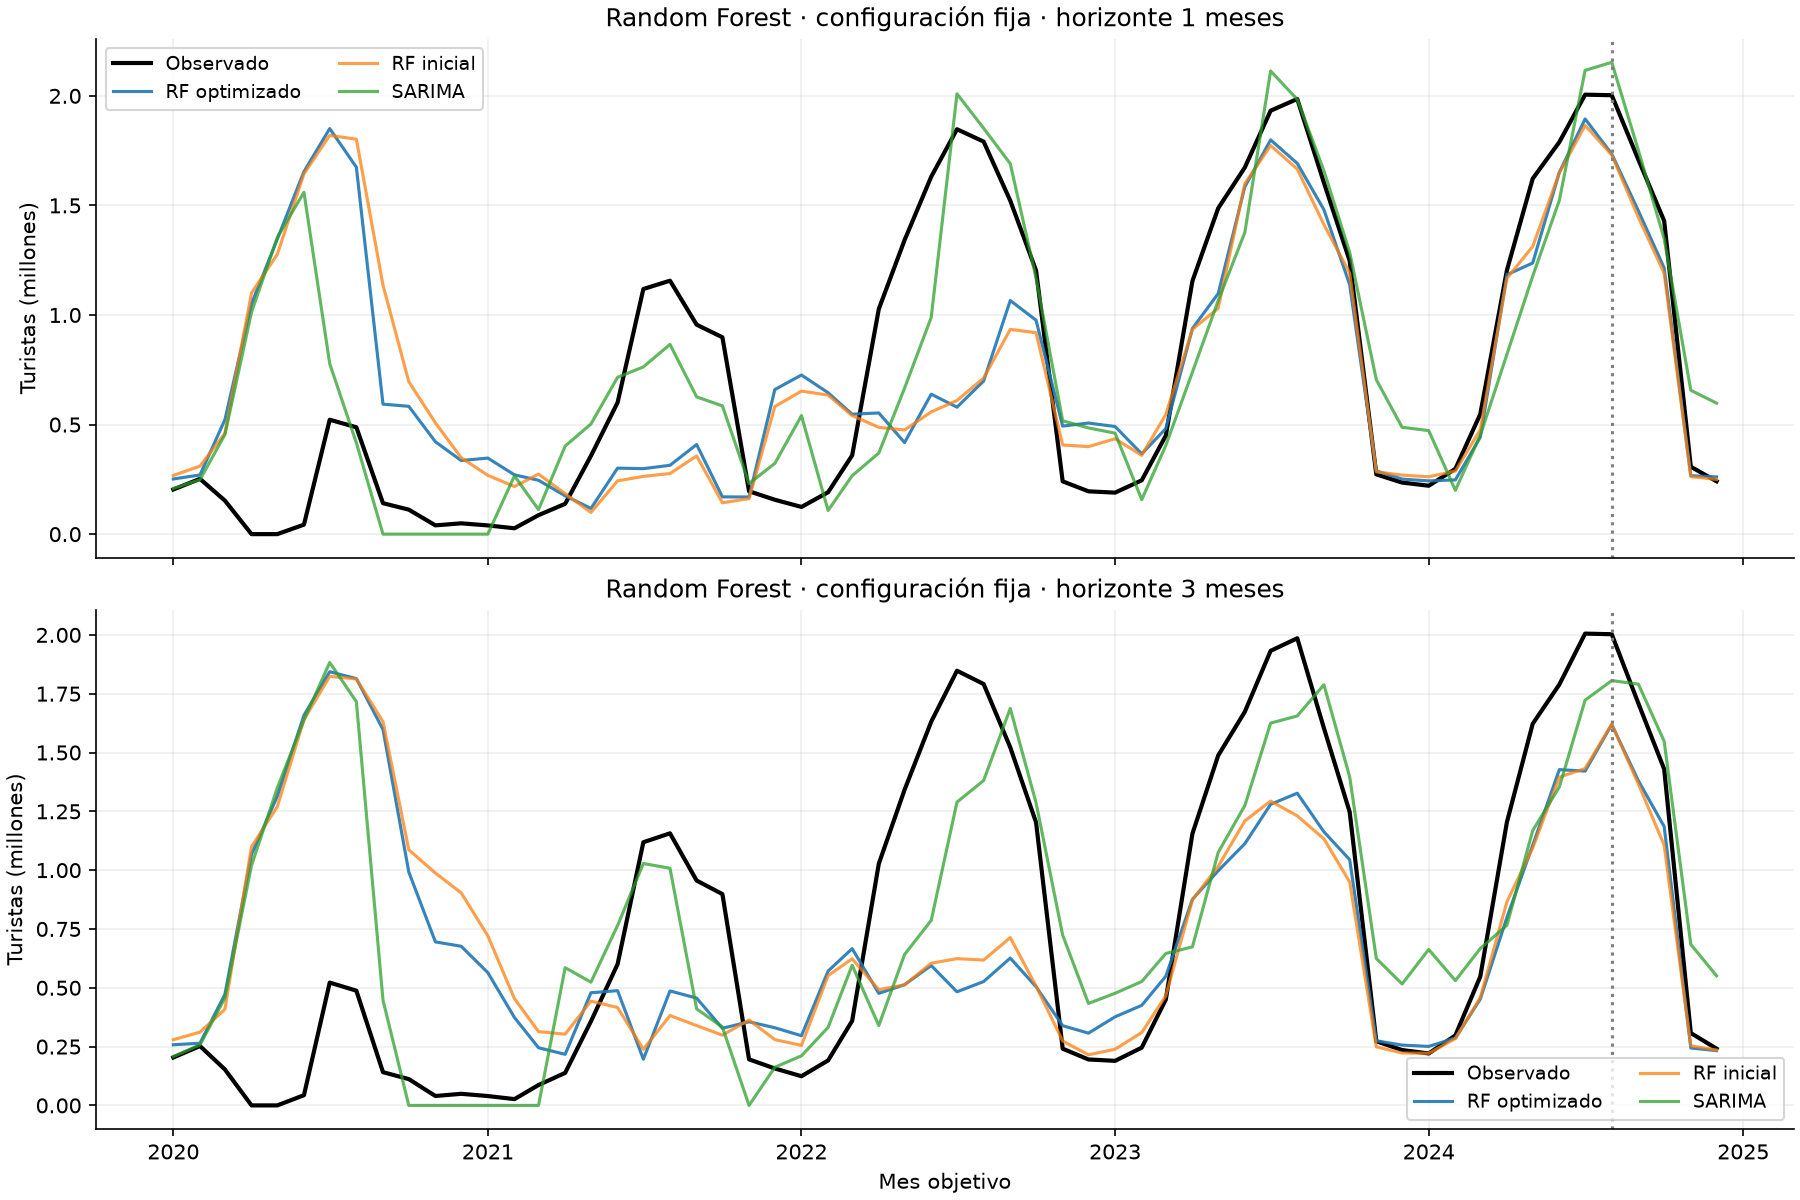


## 44. Aportación de fuentes externas a Random Forest

Se comparan cinco variantes: turistas y calendario como control, y ese mismo conjunto ampliado por separado con AENA, hoteles, meteorología o Google Trends. Se mantienen los hiperparámetros seleccionados en el bloque 43 para cada horizonte: hoja mínima 1 y profundidad sin límite a un mes; hoja mínima 1 y profundidad 5 a tres meses, con 300 árboles. No se vuelven a ajustar por fuente o escenario.

Cada grupo incorpora los tres retardos ya definidos en el catálogo: primer mes permitido, un mes adicional y un año adicional. AENA aporta pasajeros y operaciones (seis columnas); hoteles, seis indicadores (18 columnas); meteorología, temperatura y precipitación completas de B278 (seis columnas); Google Trends, las cuatro series disponibles (12 columnas). Las ocho variables meteorológicas secundarias quedan fuera. Así, el control tiene 14 columnas, AENA y meteorología 20, Google Trends 26 y hoteles 32 entradas más 18 marcas de ausencia, 50 en total.

Los retardos desde el origen son t−1/t−2 para AENA, hoteles y Google Trends, y t−2/t−3 para turistas y meteorología en base/espera adicional. Los meses adicionales del catálogo se aplican sobre ese primer retardo. Las referencias se comprueban según la fecha de publicación; las fechas mensuales de AEMET y la cautela de Google Trends son supuestos de simulación. Google Trends utiliza CSV retrospectivos normalizados para 2015–2025: no reconstruye la señal que habría sido descargada en cada origen. Se evalúa su aportación retrospectiva, sin presentarla como validación estricta en tiempo real.

Cada variante utiliza exactamente las mismas filas supervisadas, los 288 meses de emisión y las etiquetas publicadas anteriores a 2025. No se eliminan casos ni se escalan las variables. Solo los predictores hoteleros se imputan: mediana por columna ajustada en ese entrenamiento y marcas de ausencia estables. Los ausentes originales o bloqueados por una publicación tardía se sustituyen con esa mediana y su marca; la observación todavía no publicada nunca se utiliza. En las otras fuentes, un ausente bloquea el pronóstico y exige una regla específica. Los valores observados y los ceros se conservan.

La comparación mide cada fuente por separado, con configuración fija; no se exploran combinaciones de fuentes ni una nueva selección de retardos. El número de entradas cambia y puede modificar la flexibilidad del bosque, por lo que no se atribuye causalidad a las diferencias de error. Las clasificaciones se calculan solo en los 55 meses de selección base; el diagnóstico y la espera adicional comprueban estabilidad retrospectiva sin cambiar hiperparámetros. La inspección de varias fuentes también introduce selección, que deberá declararse en la comparación final.

`outputs/modelos/random_forest_externas/` conserva las 1.440 emisiones, métricas por bloque/año/periodo, comparación con el control, clasificación de selección, catálogo, auditorías de disponibilidad, entrenamiento e imputación y figuras. 2025 permanece reservado con `EVALUATE_FINAL_2025=False`.


In [32]:
RFX_DIR=PROJECT_ROOT/"outputs"/"modelos"/"random_forest_externas"
RFX_DIR.mkdir(parents=True,exist_ok=True)
RFX_VARIANTS={"turistas_calendario":None,"aena":"aena","hoteles":"hoteles",
    "meteorologia":"meteorologia","google_trends":"google_trends"}
rfx_columns,rfx_hotel_columns,rfx_catalog_parts={},{},[]
for scenario,horizon in prediction_sets:
    wait=int(scenario=="espera_adicional")
    catalog=feature_catalog.loc[feature_catalog.horizonte.eq(horizon)&feature_catalog.espera_adicional.eq(wait)]
    for variant,group in RFX_VARIANTS.items():
        selected=catalog.loc[catalog.grupo.isin(["turistas","calendario"]+([] if group is None else [group]))].copy()
        columns=rf_columns[(scenario,horizon)]+selected.loc[selected.grupo.eq(group),"predictor"].tolist()
        assert len(columns)==len(set(columns))
        rfx_columns[(scenario,horizon,variant)]=columns
        rfx_hotel_columns[(scenario,horizon,variant)]=selected.loc[selected.grupo.eq("hoteles"),"predictor"].tolist()
        selected["variante"]=variant
        selected["escenario"]=scenario
        rfx_catalog_parts.append(selected)
rfx_catalog=pd.concat(rfx_catalog_parts,ignore_index=True)
rfx_cache,rfx_fit_audit={},[]


def rfx_prepare(row,variant,feature_frame=None,label_frame=None):
    X,meta=prediction_sets[(row.escenario,row.horizonte)]
    if feature_frame is not None:
        assert feature_frame.index.equals(X.index) and feature_frame.columns.equals(X.columns)
        X=feature_frame
    if label_frame is not None:
        assert label_frame.index.equals(meta.index) and label_frame.columns.equals(meta.columns)
        meta=label_frame
    indices=training_indices.loc[training_indices.escenario.eq(row.escenario)&training_indices.horizonte.eq(row.horizonte)
        &training_indices.mes_origen_pronostico.eq(row.mes_origen)]
    origins=pd.DatetimeIndex(indices.mes_origen_entrenamiento)
    labels=meta.loc[origins]
    assert len(origins)==row.n_entrenamiento_supervisado and len(origins)>=MIN_TRAIN_ROWS
    assert labels.mes_objetivo.between(TRAIN_TARGET_START,TRAIN_TARGET_END).all()
    assert labels.fecha_publicacion_objetivo.le(row.fecha_corte).all()
    assert labels.mes_objetivo.tolist()==indices.mes_objetivo_entrenamiento.tolist()
    assert labels.mes_objetivo.lt(row.mes_objetivo).all() and (origins<row.mes_origen).all()
    columns=rfx_columns[(row.escenario,row.horizonte,variant)]
    hotels=rfx_hotel_columns[(row.escenario,row.horizonte,variant)]
    raw_train=X.loc[origins,columns].copy()
    raw_forecast=X.loc[[row.mes_origen],columns].copy()
    imputer=HotelMedianImputer().fit(raw_train,hotels)
    train_X=imputer.transform(raw_train)
    forecast_X=imputer.transform(raw_forecast)
    train_y=labels.turistas_objetivo.astype(float).copy()
    assert train_X.columns.equals(forecast_X.columns) and train_X.index.equals(train_y.index)
    assert np.isfinite(train_X.to_numpy()).all() and np.isfinite(forecast_X.to_numpy()).all()
    assert np.isfinite(train_y.to_numpy()).all() and train_y.ge(0).all()
    for column in columns:
        for raw,prepared in [(raw_train,train_X),(raw_forecast,forecast_X)]:
            observed=raw[column].notna()
            pd.testing.assert_series_equal(raw.loc[observed,column],prepared.loc[observed,column])
    details={"n_entrenamiento":len(origins),"n_predictores_originales":len(columns),"n_predictores_preparados":len(train_X.columns),
        "inicio_objetivos_entrenamiento":labels.mes_objetivo.min(),"ultimo_y_parametros":labels.mes_objetivo.max(),
        "ultima_publicacion_entrenamiento":labels.fecha_publicacion_objetivo.max(),
        "ceros_entrenamiento":int(train_y.eq(0).sum()),"predictores":json.dumps(train_X.columns.tolist(),ensure_ascii=False),
        "columnas_hoteleras":json.dumps(hotels),"medianas":json.dumps(imputer.medians_.to_dict(),ensure_ascii=False),
        "observados_por_columna_hotelera":json.dumps(imputer.observed_counts_.to_dict()),
        "sustituciones_entrenamiento":int(raw_train[hotels].isna().sum().sum()),
        "sustituciones_pronostico":int(raw_forecast[hotels].isna().sum().sum())}
    return train_X,train_y,forecast_X,details,imputer


def rfx_forecast(row,variant,feature_frame=None,label_frame=None,record_audit=True):
    train_X,train_y,forecast_X,details,_=rfx_prepare(row,variant,feature_frame,label_frame)
    candidate=rft_selected_map[row.horizonte]
    params=RFT_CANDIDATES[candidate]
    digest=hashlib.sha256(pd.util.hash_pandas_object(train_X,index=True).values.tobytes()
        +pd.util.hash_pandas_object(train_y,index=True).values.tobytes()
        +"|".join(train_X.columns).encode()+json.dumps(params,sort_keys=True).encode()).hexdigest()
    key=(variant,row.escenario,row.horizonte)
    reused=key in rfx_cache and rfx_cache[key][0]==digest
    if reused: model=rfx_cache[key][1]
    else:
        model=RandomForestRegressor(**params).fit(train_X,train_y)
        rfx_cache[key]=(digest,model)
    value=float(model.predict(forecast_X)[0])
    assert np.isfinite(value) and train_y.min()-1e-7<=value<=train_y.max()+1e-7
    details.update(configuracion=candidate,hash_ajuste=digest,ajuste_reutilizado=reused,
        prediccion=value,estado_ejecucion="ok")
    if record_audit:
        rfx_fit_audit.append(dict(escenario=row.escenario,horizonte=row.horizonte,variante=variant,
            mes_origen=row.mes_origen,mes_objetivo=row.mes_objetivo,fecha_corte=row.fecha_corte,
            parametros=json.dumps(params,sort_keys=True),**details))
    return details


In [33]:
rfx_records=[]
for variant in RFX_VARIANTS:
    for i,row in enumerate(evaluation_plan.itertuples(index=False)):
        enabled=row.uso=="validacion" or EVALUATE_FINAL_2025
        record=row._asdict()
        record.update(modelo="Random Forest",variante=variant,grupo_fuentes="turistas_calendario" if variant=="turistas_calendario" else "turistas_calendario+"+variant,
            evaluacion_habilitada=enabled,observado=float(master.at[row.mes_objetivo,"turistas"]) if enabled else np.nan,
            estado_objetivo=master.at[row.mes_objetivo,"turistas_estado"] if enabled else None)
        record.update(rfx_forecast(row,variant))
        record["error"]=record["observado"]-record["prediccion"] if enabled else np.nan
        rfx_records.append(record)
        if (i+1)%72==0: print("Fuente",variant,":",i+1,"/",len(evaluation_plan),"emisiones",flush=True)
rfx_predictions=pd.DataFrame(rfx_records)
rfx_metrics=summarize_forecast_errors(rfx_predictions,["variante","escenario","horizonte","papel"])
rfx_annual=summarize_forecast_errors(rfx_predictions,["variante","escenario","horizonte","fold"])
rfx_periods=summarize_forecast_errors(rfx_predictions.loc[rfx_predictions.uso.eq("validacion")],["variante","escenario","horizonte","periodo"])
rfx_no_U=summarize_forecast_errors(rfx_predictions.loc[rfx_predictions.uso.eq("validacion")&~rfx_predictions.estado_objetivo.eq("U")],
    ["variante","escenario","horizonte","papel"])
rfx_control=rfx_metrics.loc[rfx_metrics.variante.eq("turistas_calendario"),["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
rfx_comparison=rfx_metrics.merge(rfx_control,on=["escenario","horizonte","papel"],suffixes=("","_control"),validate="many_to_one")
complete=rfx_comparison.n_puntuados.eq(rfx_comparison.n_esperados)&rfx_comparison.n_puntuados.eq(rfx_comparison.n_puntuados_control)
rfx_comparison["mejora_RMSE_porcentaje"]=np.where(complete,100*(1-rfx_comparison.RMSE/rfx_comparison.RMSE_control),np.nan)
rfx_ranking=rfx_metrics.loc[rfx_metrics.escenario.eq("base")&rfx_metrics.papel.eq("seleccion")].copy()
rfx_ranking["elegible"]=rfx_ranking.n_pronosticos.eq(55)&rfx_ranking.n_puntuados.eq(55)
rfx_ranking["puesto_RMSE"]=rfx_ranking.loc[rfx_ranking.elegible].groupby("horizonte").RMSE.rank(method="min")
rfx_audit=pd.DataFrame(rfx_fit_audit)
# La disponibilidad por referencia ya se documenta en el catálogo y auditoría originales.
rfx_availability=feature_audit.copy()
for name,table in {"predicciones":rfx_predictions,"metricas_bloques":rfx_metrics,"metricas_anuales":rfx_annual,
    "metricas_periodos":rfx_periods,"diagnostico_sin_objetivos_U":rfx_no_U,"comparacion_control":rfx_comparison,
    "clasificacion_seleccion_base":rfx_ranking,"auditoria_ajustes_imputacion":rfx_audit,
    "catalogo_variantes":rfx_catalog,"disponibilidad_predictores":rfx_availability,
    "indices_entrenamiento":training_indices}.items():
    table.to_csv(RFX_DIR/(name+".csv"),index=False,encoding="utf-8-sig")
display(rfx_comparison.loc[rfx_comparison.escenario.eq("base"),
    ["variante","horizonte","papel","n_puntuados","RMSE","RMSE_control","mejora_RMSE_porcentaje"]])


Fuente turistas_calendario : 72 / 288 emisiones


Fuente turistas_calendario : 144 / 288 emisiones


Fuente turistas_calendario : 216 / 288 emisiones


Fuente turistas_calendario : 288 / 288 emisiones


Fuente aena : 72 / 288 emisiones


...

Fuente google_trends : 72 / 288 emisiones


Fuente google_trends : 144 / 288 emisiones


Fuente google_trends : 216 / 288 emisiones


Fuente google_trends : 288 / 288 emisiones


,variante,horizonte,papel,n_puntuados,RMSE,RMSE_control,mejora_RMSE_porcentaje
0,aena,1,diagnostico_fijo,5,168824.668755,186841.021819,9.642611
1,aena,1,prueba_final,0,NaN,NaN,NaN
2,aena,1,seleccion,55,554346.842375,584640.599299,5.181603
3,aena,3,diagnostico_fijo,5,204642.283922,252610.555756,18.989021
4,aena,3,prueba_final,0,NaN,NaN,NaN
5,aena,3,seleccion,55,649581.786864,674364.777060,3.675013
12,google_trends,1,diagnostico_fijo,5,163431.851029,186841.021819,12.528925
13,google_trends,1,prueba_final,0,NaN,NaN,NaN
14,google_trends,1,seleccion,55,592508.351770,584640.599299,-1.345742
15,google_trends,3,diagnostico_fijo,5,163996.345523,252610.555756,35.079377


In [34]:
keys=["escenario","horizonte","mes_origen","mes_objetivo"]
assert len(rfx_predictions)==5*len(evaluation_plan)==1440
assert rfx_predictions.estado_ejecucion.eq("ok").all() and rfx_predictions.prediccion.ge(0).all()
for variant in RFX_VARIANTS:
    block=rfx_predictions.loc[rfx_predictions.variante.eq(variant)]
    pd.testing.assert_frame_equal(block[keys].reset_index(drop=True),evaluation_plan[keys].reset_index(drop=True))
    assert block.n_entrenamiento.tolist()==evaluation_plan.n_entrenamiento_supervisado.tolist()
assert rfx_audit.ultimo_y_parametros.le(TRAIN_TARGET_END).all()
assert rfx_audit.ultima_publicacion_entrenamiento.le(rfx_audit.fecha_corte).all()
for horizon,candidate in rft_selected_map.items():
    assert rfx_predictions.loc[rfx_predictions.horizonte.eq(horizon),"configuracion"].eq(candidate).all()
# Reproducir el control optimizado en todas las emisiones, también las reservadas.
control=rfx_predictions.loc[rfx_predictions.variante.eq("turistas_calendario")]
reference=pd.read_csv(RFT_DIR/"predicciones.csv",parse_dates=["mes_origen","mes_objetivo"])
pd.testing.assert_frame_equal(control[keys+["prediccion"]].reset_index(drop=True),reference[keys+["prediccion"]].reset_index(drop=True),
    check_exact=False,rtol=1e-12,atol=1e-7)
for variant,expected in {"turistas_calendario":14,"aena":20,"hoteles":50,"meteorologia":20,"google_trends":26}.items():
    assert rfx_predictions.loc[rfx_predictions.variante.eq(variant),"n_predictores_preparados"].eq(expected).all()
if not EVALUATE_FINAL_2025:
    final=rfx_predictions.loc[rfx_predictions.uso.eq("prueba_final")]
    assert final[["observado","error"]].isna().all().all() and final.estado_objetivo.isna().all()
    assert not final.evaluacion_habilitada.any()
    assert rfx_metrics.loc[rfx_metrics.papel.eq("prueba_final"),"n_puntuados"].eq(0).all()
assert rfx_ranking.elegible.all()
# Comparar matrices y pronósticos después de alterar datos aún no publicados de todas las fuentes.
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
        wait=int(scenario=="espera_adicional")
        changed=master.copy(deep=True)
        for group,variables in GROUP_VARIABLES.items():
            future=[d for d in changed.index if publication_date(group,d.to_period("M"),wait,verified_dates)>row.fecha_corte]
            changed.loc[future,variables]=99_999_999.
        altered_X,altered_meta,_,_=build_prediction_features(changed,horizon,wait,verified_dates)
        for variant in RFX_VARIANTS:
            a=rfx_prepare(row,variant)
            b=rfx_prepare(row,variant,altered_X,altered_meta)
            pd.testing.assert_frame_equal(a[0],b[0])
            pd.testing.assert_series_equal(a[1],b[1])
            pd.testing.assert_frame_equal(a[2],b[2])
            pd.testing.assert_series_equal(a[4].medians_,b[4].medians_)
            original=rfx_forecast(row,variant,record_audit=False)
            perturbed=rfx_forecast(row,variant,altered_X,altered_meta,record_audit=False)
            assert original["prediccion"]==perturbed["prediccion"] and original["hash_ajuste"]==perturbed["hash_ajuste"]
        X,meta=prediction_sets[(scenario,horizon)]
        train,y,forecast,info,imputer=rfx_prepare(row,"hoteles")
        pd.testing.assert_series_equal(imputer.medians_,X.loc[train.index,imputer.hotel_columns_].median())
        # Modificar hoteles fuera de las filas de entrenamiento no altera las medianas.
        excluded=X.copy(deep=True)
        outside=~excluded.index.isin(train.index)
        excluded.loc[outside,imputer.hotel_columns_]=99_999_999.
        _,_,_,_,other=rfx_prepare(row,"hoteles",excluded)
        pd.testing.assert_series_equal(imputer.medians_,other.medians_)
# Publicación tardía: hoteles usa solo medianas de entrenamiento y marca; otras fuentes bloquean.
row=next(evaluation_plan.loc[evaluation_plan.escenario.eq("base")&evaluation_plan.horizonte.eq(1)
    &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
for variant,group in RFX_VARIANTS.items():
    if group is None: continue
    dates=dict(verified_dates)
    ref=row.mes_origen-pd.DateOffset(months=PUBLICATION_DELAYS[group])
    dates[(group,ref)]=row.fecha_corte+pd.Timedelta(days=1)
    late_X,late_meta,_,_=build_prediction_features(master,row.horizonte,0,dates)
    if group=="hoteles":
        _,_,forecast,_,imputer=rfx_prepare(row,variant,late_X,late_meta)
        impacted=[c for c in imputer.hotel_columns_ if late_X.at[row.mes_origen,c]!=late_X.at[row.mes_origen,c]]
        assert impacted and forecast[[c+"__ausente" for c in impacted]].eq(1).all().all()
        for c in impacted: assert forecast.iloc[0][c]==imputer.medians_[c]
    else:
        try: rfx_prepare(row,variant,late_X,late_meta)
        except ValueError: pass
        else: raise AssertionError("Una fuente no hotelera tardía debe bloquearse, no imputarse")
assert master.loc["2020-04-01":"2020-05-01","turistas"].eq(0).all()
assert rfx_audit.ceros_entrenamiento.max()==2
assert rfx_audit.loc[~rfx_audit.variante.eq("hoteles"),["sustituciones_entrenamiento","sustituciones_pronostico"]].eq(0).all().all()
assert hashlib.sha256((OUTPUT_DIR/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()==feature_manifest["maestro_sha256"]
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    for variant in RFX_VARIANTS:
        block=rfx_predictions.loc[rfx_predictions.escenario.eq("base")&rfx_predictions.horizonte.eq(horizon)
            &rfx_predictions.variante.eq(variant)&rfx_predictions.uso.eq("validacion")]
        ax.plot(block.mes_objetivo,block.prediccion/1e6,label=variant,alpha=.75)
    ax.plot(block.mes_objetivo,block.observado/1e6,label="Observado",color="black",lw=2)
    ax.axvline(SELECTION_TARGET_END+pd.DateOffset(months=1),color="gray",ls=":")
    ax.set(title=f"Random Forest · fuentes por separado · horizonte {horizon} meses",ylabel="Turistas (millones)")
    ax.legend(fontsize=8,ncol=3)
axes[-1].set_xlabel("Mes objetivo")
fig.savefig(RFX_DIR/"validacion_fuentes_externas.png",dpi=150)
plt.show()
plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    block=rfx_comparison.loc[rfx_comparison.escenario.eq("base")&rfx_comparison.horizonte.eq(horizon)&rfx_comparison.papel.eq("seleccion")]
    ax.barh(block.variante,block.RMSE/1e3)
    ax.axvline(block.RMSE_control.iloc[0]/1e3,color="black",ls=":",label="Control")
    ax.set(title=f"Selección base · h={horizon}",xlabel="RMSE (miles de turistas)")
    ax.legend()
fig.savefig(RFX_DIR/"rmse_seleccion_fuentes.png",dpi=150)
plt.show()
plt.close(fig)
rfx_manifest={"modelo":"RandomForestRegressor","version_sklearn":importlib.metadata.version("scikit-learn"),
    "fecha_documentacion":"2026-10-10","variantes":RFX_VARIANTS,
    "parametros_fijos":{str(h):RFT_CANDIDATES[c] for h,c in rft_selected_map.items()},
    "seleccion_hiperparametros":"bloque 43, solo turistas/calendario, selección base; sin nueva búsqueda por fuente",
    "variables_por_fuente":{g:(METEO_CORE if g=="meteorologia" else GROUP_VARIABLES[g]) for g in RFX_VARIANTS.values() if g},
    "retardos":"catálogo: primer mes permitido, +1 y +12 desde origen; espera adicional en todos los grupos",
    "politica_disponibilidad":availability_policy,"imputacion":"mediana hotelera por entrenamiento y marcas; otras fuentes bloquean",
    "escalado":False,"mismos_indices_entrenamiento":True,"emisiones":len(rfx_predictions),
    "fallos":int(rfx_predictions.estado_ejecucion.ne("ok").sum()),"evaluacion_final_2025_habilitada":EVALUATE_FINAL_2025,
    "controles":"superados","maestro_sha256":feature_manifest["maestro_sha256"],
    "limites":["fuentes por separado, sin combinaciones","diferente dimensionalidad por fuente","sin inferencia causal",
        "Google Trends retrospectivo normalizado en 2015-2025, no versiones por origen",
        "meteorología mensual con plazo supuesto y datos revisados","selección de fuentes exploratoria, diagnóstico ya inspeccionado",
        "2025 sin puntuar"]}
(RFX_DIR/"ejecucion.json").write_text(json.dumps(rfx_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("Fuentes externas verificadas:",len(rfx_predictions),"emisiones; 2025 sin puntuar.")


Fuentes externas verificadas: 1440 emisiones; 2025 sin puntuar.


C:\Users\acort\AppData\Local\Temp\ipykernel_7908\2009901936.py:89: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\acort\AppData\Local\Temp\ipykernel_7908\2009901936.py:99: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


## Lectura de la aportación externa a Random Forest

Las cinco variantes completan las 288 emisiones por variante, 1.440 en total, sin fallos. La auditoría de producción registra 1.290 ajustes y 150 reutilizaciones. El control reproduce los 288 pronósticos del bosque optimizado anterior dentro de la tolerancia numérica comprobada. Los índices de entrenamiento, horizontes, parámetros y meses objetivo son comunes a todas las variantes. Los controles verifican la invariancia de matrices, medianas y pronósticos ante datos no publicados, el tratamiento de fechas tardías y la conservación de fuentes, maestro y productos anteriores.

La comparación base en los 55 meses de selección (enero de 2020–julio de 2024) es:

| Fuente añadida | RMSE h=1 | Reducción h=1 | RMSE h=3 | Reducción h=3 |
| --- | ---: | ---: | ---: | ---: |
| Control: turistas y calendario | 584.641 | — | 674.365 | — |
| AENA | 554.347 | 5,18 % | 649.582 | 3,68 % |
| Hoteles | 558.880 | 4,41 % | 668.291 | 0,90 % |
| Meteorología | 590.224 | −0,95 % | 624.581 | 7,38 % |
| Google Trends | 592.508 | −1,35 % | 690.671 | −2,42 % |

El RMSE se expresa en turistas y una reducción positiva significa menor error que el control. AENA obtiene el menor RMSE a un mes; meteorología lo obtiene a tres meses. Hoteles mejora la selección base, aunque su reducción a tres meses es pequeña. Google Trends no mejora esos 55 meses con esta especificación.

Los cinco meses de diagnóstico de 2024 dan una lectura diferente. AENA reduce el error del control un 9,64 % y un 18,99 %, y hoteles un 7,52 % y un 18,49 %, a uno y tres meses. Meteorología aumenta el error un 17,85 % y un 37,24 %. Google Trends reduce el error un 12,53 % y un 35,08 %, pese a su deterioro en selección. El bloque es breve y ya inspeccionado en experimentos previos: se interpreta como diagnóstico retrospectivo, sin elegir de nuevo los hiperparámetros ni presentar sus mejoras como prueba independiente.

La espera adicional mantiene las mismas configuraciones. En sus 55 meses retrospectivos, AENA empeora un 0,46 % a un mes y mejora un 1,44 % a tres; hoteles mejora un 0,61 % a un mes y empeora un 3,86 % a tres. Meteorología reduce el error un 2,13 % y un 6,21 %, pero en su diagnóstico a un mes empeora un 25,42 %. Google Trends empeora la selección un 5,25 % y un 0,77 %, aunque reduce el diagnóstico. No hay una fuente que mejore de forma uniforme todos los horizontes, bloques y disponibilidades.

En hoteles, 32 de las 288 emisiones requieren relleno de entradas del pronóstico, con 120 sustituciones de celdas. La auditoría registra también 6.440 sustituciones dentro de los entrenamientos expansivos repetidos. Estas cifras cuentan casos por emisión y por retardo, no huecos distintos del dataset original. Cada sustitución utiliza la mediana de las filas de ese entrenamiento, con una marca de ausencia. Los valores observados y los ceros permanecen intactos. AENA, meteorología, Google Trends y el control no requieren imputación.

Se conservan las cinco variantes para la comparación posterior. Los resultados apoyan examinar AENA a corto plazo y meteorología a tres meses, pero la sensibilidad y el diagnóstico impiden afirmar una ventaja general. El deterioro de Google Trends en selección tampoco descarta otras consultas, retardos o configuraciones. Los hiperparámetros proceden del modelo sin fuentes externas y el número de entradas varía de 14 a 50; no se ha buscado el mejor bosque para cada grupo ni se han probado combinaciones. La inspección de fuentes sobre los mismos meses introduce selección y no permite atribuir causalidad.

La meteorología usa datos mensuales revisados con plazo de publicación supuesto. Google Trends procede de descargas retrospectivas normalizadas para 2015–2025, sin reconstruir versiones por origen: sus resultados describen una señal retrospectiva y no garantizan que se hubiese dispuesto de esos mismos índices. Estas limitaciones se mantienen aunque las referencias mensuales respeten los retardos.

Las 240 predicciones reservadas de 2025 (cinco variantes, dos horizontes y dos escenarios) no contienen observación objetivo, estado, error ni métricas finales. `EVALUATE_FINAL_2025=False` permanece desactivado. No se ha utilizado 2025 para ajustar modelos, medianas o hiperparámetros; las entradas solo incorporan los retardos autorizados por la política de disponibilidad.

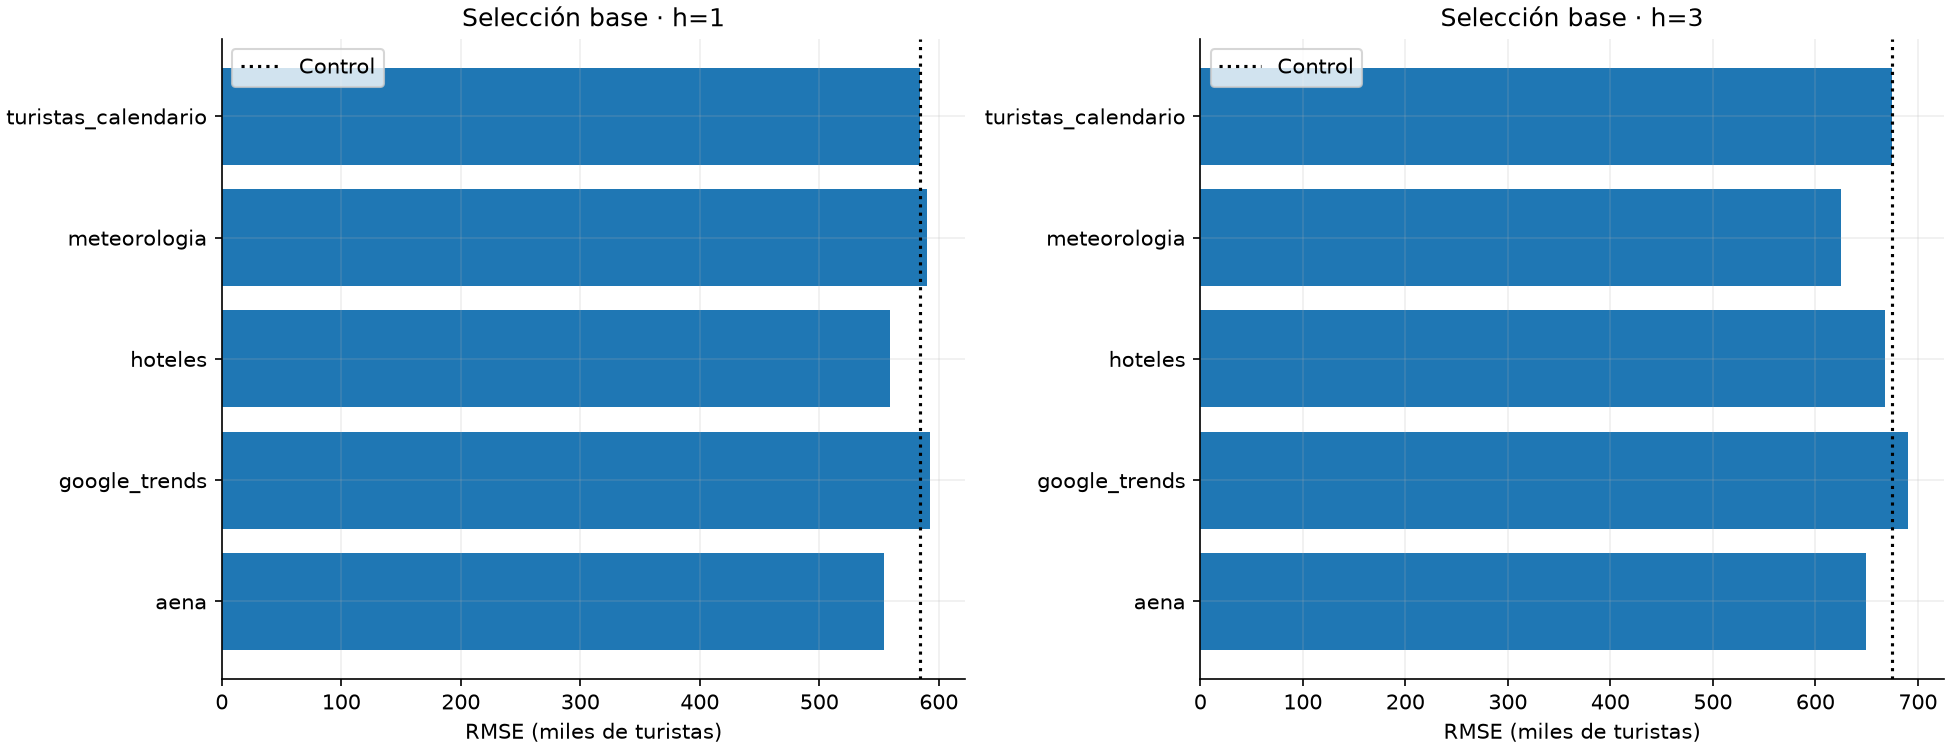

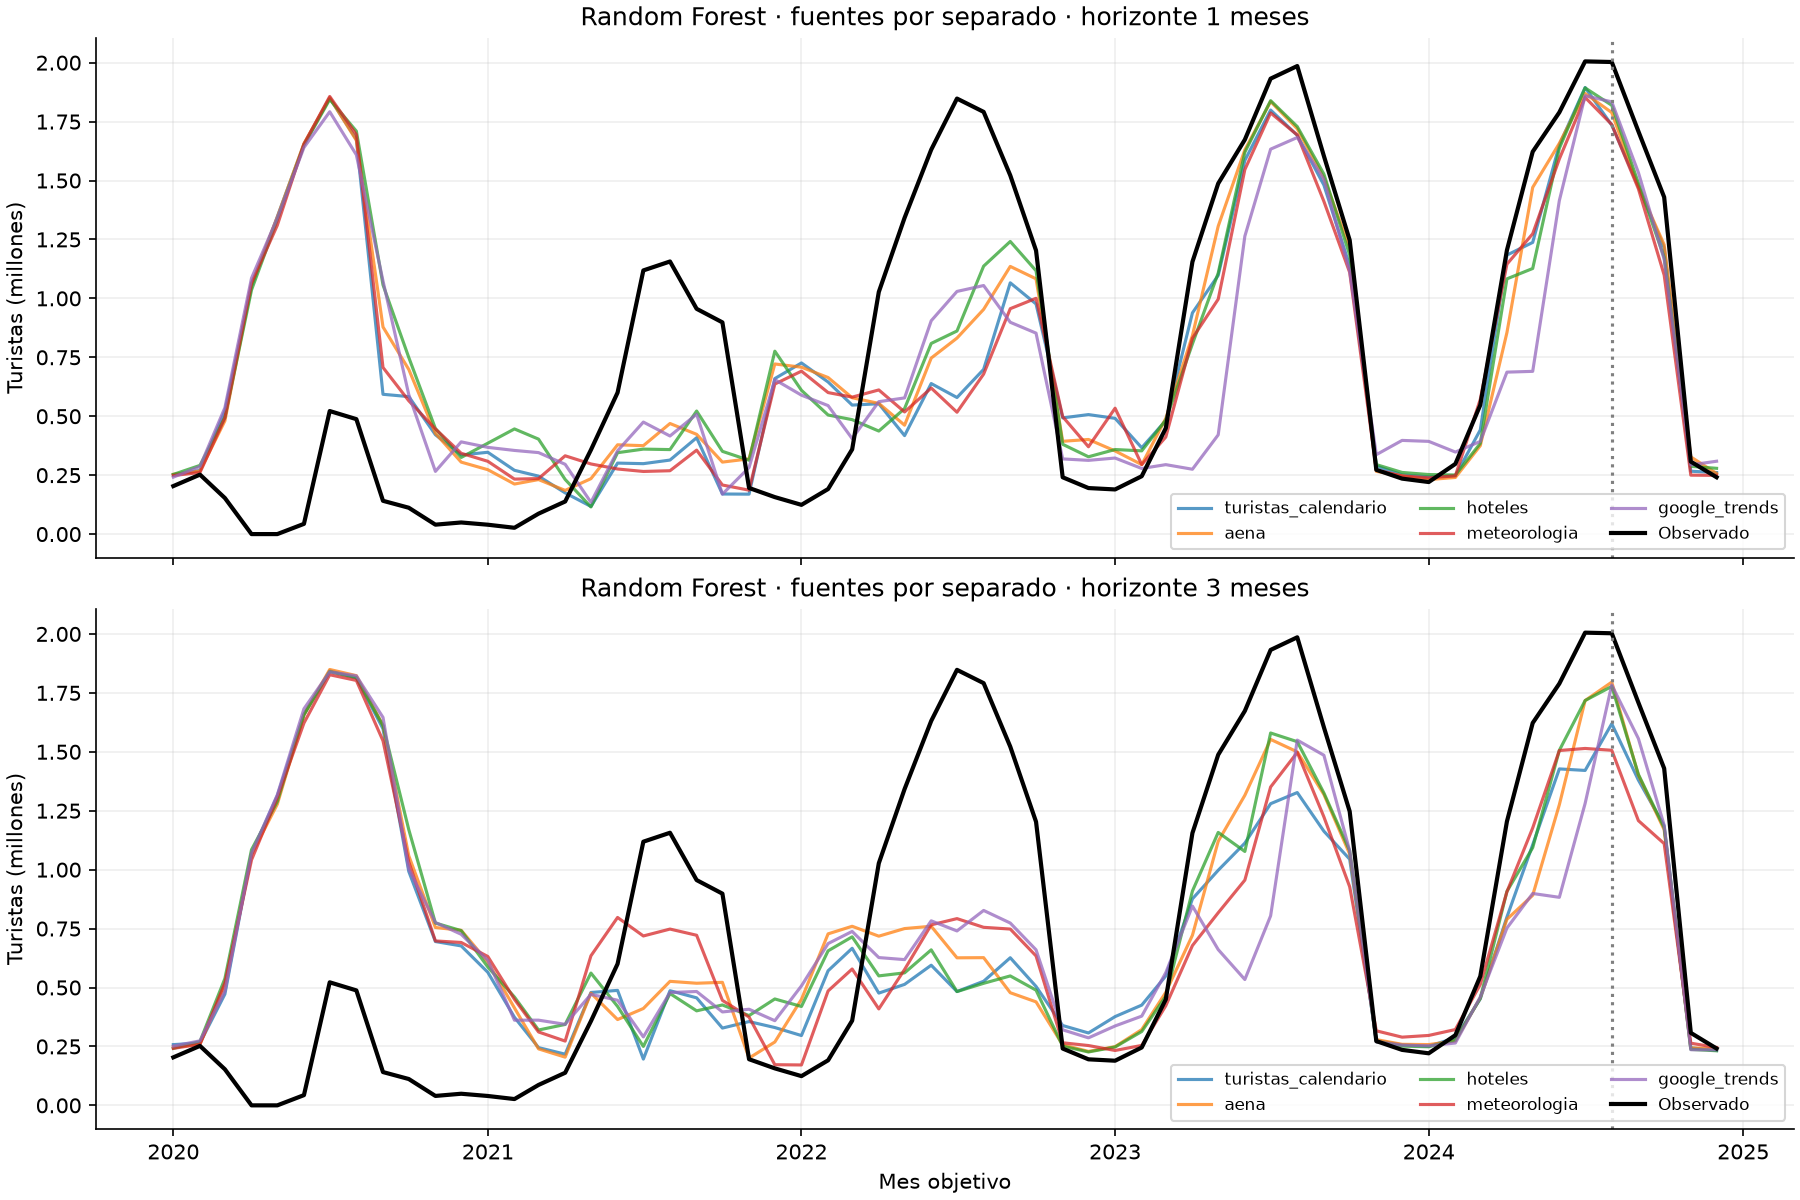


## 45. Comparación conjunta sobre un calendario común

Se reúnen los pronósticos guardados de Seasonal Naïve, SARIMA, los controles y variantes SARIMAX y Random Forest inicial, ajustado y con fuentes externas. Son 14 series de resultados, cada una con las mismas 288 emisiones: dos escenarios, dos horizontes y 72 objetivos por combinación. El control de turistas/calendario del bloque de fuentes de Random Forest coincide con el bosque ajustado y se representa una sola vez.

Los **55 meses de selección** (enero de 2020–julio de 2024) y los **cinco meses de diagnóstico** (agosto–diciembre de 2024) se resumen y dibujan por separado. La espera adicional mantiene también su propia tabla. Se recalculan RMSE, MAE y sesgo desde los errores guardados, con cobertura completa y sin eliminar meses. No se utiliza MAPE por los ceros del objetivo. La clasificación es descriptiva: selección ha participado en la elección de modelos y fuentes; diagnóstico es breve, retrospectivo y ya inspeccionado. Ninguno es una prueba final independiente.

Compartir meses y política de disponibilidad no implica que todos los modelos tengan las mismas entradas o longitud de entrenamiento. SARIMA usa historia secuencial desde octubre de 2015; los controles SARIMAX comienzan más tarde según el retardo externo; Random Forest usa objetivos supervisados desde abril de 2017. SARIMAX incorpora menos retardos/variables que los bosques por fuente. Los modelos secuenciales limitan a cero sus predicciones negativas según la regla previa; se comparan esas predicciones operativas guardadas. La aportación de cada fuente se calcula frente a su **control interno correspondiente**, no frente al SARIMA de historia completa.

Las tablas incluyen todas las variantes. Las gráficas de RMSE muestran las 14 series, separando bloques y escenarios. Para que la evolución sea legible, se representan cuatro ejemplos fijados: Seasonal Naïve, SARIMA de historia completa, SARIMAX con AENA y Random Forest ajustado, más el observado. Esos ejemplos no se eligen como ganadores del diagnóstico. Las gráficas de evolución muestran selección y diagnóstico separados, únicamente en el escenario base.

Los hashes de dataset y archivos de pronósticos se comprueban antes de reunir resultados. El bloque no entrena, cambia hiperparámetros ni modifica productos anteriores. `outputs/comparacion_modelos/` contiene los resultados conjuntos, catálogos, tablas por bloque, clasificación, aportación de fuentes, cobertura, figuras y procedencia. Los pronósticos de 2025 quedan reservados: se comprueba que no incluyan objetivos, errores o métricas puntuadas. Se mantienen las limitaciones de versiones revisadas, normalización retrospectiva de Google Trends y plazo mensual supuesto de AEMET.


In [1]:
JOINT_DIR=PROJECT_ROOT/"outputs"/"comparacion_modelos"
JOINT_DIR.mkdir(parents=True,exist_ok=True)
JOINT_SPECS=[
    ("naive","Seasonal Naïve","Seasonal Naïve","seasonal_naive",None,None),
    ("sarima","SARIMA","SARIMA completo","sarima",None,None),
    ("sarima_ctrl_aena_hoteles","SARIMA","SARIMA control AENA/hoteles","sarimax","historico_comun",None),
    ("sarimax_aena","SARIMAX","SARIMAX + AENA","sarimax","aena","sarima_ctrl_aena_hoteles"),
    ("sarimax_hoteles","SARIMAX","SARIMAX + hoteles","sarimax","hoteles","sarima_ctrl_aena_hoteles"),
    ("sarimax_aena_hoteles","SARIMAX","SARIMAX + AENA/hoteles","sarimax","aena_hoteles","sarima_ctrl_aena_hoteles"),
    ("sarima_ctrl_meteo","SARIMA","SARIMA control meteorología","sarimax_meteorologia","historico_comun",None),
    ("sarimax_meteo","SARIMAX","SARIMAX + meteorología","sarimax_meteorologia","temperatura_precipitacion","sarima_ctrl_meteo"),
    ("rf_inicial","Random Forest","RF inicial","random_forest",None,None),
    ("rf_ajustado","Random Forest","RF ajustado","random_forest_optimizado",None,None),
    ("rf_aena","Random Forest","RF + AENA","random_forest_externas","aena","rf_ajustado"),
    ("rf_hoteles","Random Forest","RF + hoteles","random_forest_externas","hoteles","rf_ajustado"),
    ("rf_meteo","Random Forest","RF + meteorología","random_forest_externas","meteorologia","rf_ajustado"),
    ("rf_gt","Random Forest","RF + Google Trends","random_forest_externas","google_trends","rf_ajustado")]
joint_catalog=pd.DataFrame(JOINT_SPECS,columns=["serie_id","familia","etiqueta","carpeta_fuente","variante_fuente","control_interno"])
joint_keys=["escenario","horizonte","mes_origen","mes_objetivo"]
joint_plan_columns=joint_keys+["fecha_corte","uso","papel","fold","periodo"]
joint_plan=pd.read_csv(PROJECT_ROOT/"outputs"/"evaluacion"/"plan_pronosticos.csv",
    parse_dates=["mes_origen","mes_objetivo","fecha_corte"])[joint_plan_columns].sort_values(joint_keys).reset_index(drop=True)
assert len(joint_plan)==288 and not joint_plan.duplicated(joint_keys).any()
joint_master_hash=hashlib.sha256((PROJECT_ROOT/"outputs"/"etl"/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()
joint_sources,joint_source_metrics,joint_provenance={},{},[]
for folder in joint_catalog.carpeta_fuente.unique():
    directory=PROJECT_ROOT/"outputs"/"modelos"/folder
    path=directory/"predicciones.csv"
    manifest_path=directory/"ejecucion.json"
    manifest=json.loads(manifest_path.read_text(encoding="utf-8"))
    assert (manifest.get("maestro_sha256") or manifest.get("hash_maestro"))==joint_master_hash, "Dataset distinto: "+folder
    assert manifest["evaluacion_final_2025_habilitada"] is False, "Este bloque conserva 2025 sin puntuar"
    joint_sources[folder]=pd.read_csv(path,parse_dates=["mes_origen","mes_objetivo","fecha_corte"])
    joint_source_metrics[folder]=pd.read_csv(directory/"metricas_bloques.csv")
    joint_provenance.append({"carpeta":folder,"archivo":str(path.relative_to(PROJECT_ROOT)),
        "predicciones_sha256":hashlib.sha256(path.read_bytes()).hexdigest(),
        "manifest_sha256":hashlib.sha256(manifest_path.read_bytes()).hexdigest(),"maestro_sha256":joint_master_hash})
joint_parts=[]
for spec in joint_catalog.itertuples(index=False):
    source=joint_sources[spec.carpeta_fuente]
    selected=source.copy() if pd.isna(spec.variante_fuente) else source.loc[source.variante.eq(spec.variante_fuente)].copy()
    selected=selected.sort_values(joint_keys).reset_index(drop=True)
    pd.testing.assert_frame_equal(selected[joint_plan_columns],joint_plan,check_dtype=False)
    assert selected.estado_ejecucion.eq("ok").all() and np.isfinite(selected.prediccion).all()
    scored=selected.uso.eq("validacion")
    assert selected.loc[scored,"evaluacion_habilitada"].all()
    assert np.isfinite(selected.loc[scored,["observado","error"]].to_numpy()).all()
    np.testing.assert_allclose(selected.loc[scored,"error"],selected.loc[scored,"observado"]-selected.loc[scored,"prediccion"],rtol=1e-10,atol=1e-7)
    final=selected.loc[~scored]
    assert final[["observado","error"]].isna().all().all() and not final.evaluacion_habilitada.any()
    assert final.estado_objetivo.isna().all()
    columns=joint_plan_columns+["evaluacion_habilitada","observado","estado_objetivo","prediccion","error","estado_ejecucion"]
    columns+=[c for c in ["inicio_historia","inicio_objetivos_entrenamiento","ultimo_y_parametros","n_meses_parametros",
        "n_entrenamiento","n_predictores_preparados","configuracion","n_actualizaciones_2025"] if c in selected]
    part=selected[columns].copy()
    part["serie_id"]=spec.serie_id
    part["familia"]=spec.familia
    part["etiqueta"]=spec.etiqueta
    joint_parts.append(part)
joint_predictions=pd.concat(joint_parts,ignore_index=True)
assert len(joint_predictions)==14*288==4032
assert not joint_predictions.duplicated(["serie_id"]+joint_keys).any()
# Un único observado para cada mes evaluado; no se vuelve a consultar el objetivo de 2025.
observed_reference=joint_predictions.loc[joint_predictions.serie_id.eq("naive")&joint_predictions.uso.eq("validacion"),joint_keys+["observado","estado_objetivo"]]
for series_id,block in joint_predictions.loc[joint_predictions.uso.eq("validacion")].groupby("serie_id",sort=False):
    pd.testing.assert_frame_equal(block[joint_keys+["observado","estado_objetivo"]].reset_index(drop=True),observed_reference.reset_index(drop=True),check_dtype=False)
# El control repetido de Random Forest es equivalente y se representa una sola vez.
rf_control=joint_sources["random_forest_externas"].loc[lambda f:f.variante.eq("turistas_calendario")].sort_values(joint_keys)
rf_reference=joint_sources["random_forest_optimizado"].sort_values(joint_keys)
np.testing.assert_allclose(rf_control.prediccion,rf_reference.prediccion,rtol=1e-12,atol=1e-7)
print("Calendario común verificado:",len(joint_predictions),"emisiones de 14 series; dataset y observados coincidentes.")


Calendario común verificado: 4032 emisiones de 14 series; dataset y observados coincidentes.


In [2]:
joint_group=["serie_id","familia","etiqueta","escenario","horizonte","papel"]
joint_metrics=summarize_forecast_errors(joint_predictions,joint_group)
joint_annual=summarize_forecast_errors(joint_predictions,["serie_id","escenario","horizonte","fold"])
joint_periods=summarize_forecast_errors(joint_predictions.loc[joint_predictions.uso.eq("validacion")],
    ["serie_id","escenario","horizonte","periodo"])
joint_no_U=summarize_forecast_errors(joint_predictions.loc[joint_predictions.uso.eq("validacion")&~joint_predictions.estado_objetivo.eq("U")],joint_group)
# Contrastar todas las métricas recalculadas con las métricas originales de cada ejecución.
for spec in joint_catalog.itertuples(index=False):
    original=joint_source_metrics[spec.carpeta_fuente]
    if not pd.isna(spec.variante_fuente): original=original.loc[original.variante.eq(spec.variante_fuente)]
    original=original.sort_values(["escenario","horizonte","papel"])
    recomputed=joint_metrics.loc[joint_metrics.serie_id.eq(spec.serie_id)].sort_values(["escenario","horizonte","papel"])
    for column in ["n_esperados","n_pronosticos","n_puntuados","MAE","RMSE","sesgo_observado_menos_predicho"]:
        np.testing.assert_allclose(recomputed[column],original[column],rtol=1e-10,atol=1e-7,equal_nan=True)
joint_naive=joint_metrics.loc[joint_metrics.serie_id.eq("naive"),["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
joint_comparison=joint_metrics.merge(joint_naive,on=["escenario","horizonte","papel"],suffixes=("","_naive"),validate="many_to_one")
complete=joint_comparison.n_puntuados.eq(joint_comparison.n_esperados)&joint_comparison.n_puntuados.eq(joint_comparison.n_puntuados_naive)
joint_comparison["mejora_RMSE_vs_naive_pct"]=np.where(complete,100*(1-joint_comparison.RMSE/joint_comparison.RMSE_naive),np.nan)
joint_rankings={}
for role in ["seleccion","diagnostico_fijo"]:
    table=joint_comparison.loc[joint_comparison.papel.eq(role)].copy()
    expected=55 if role=="seleccion" else 5
    table["elegible"]=table.n_esperados.eq(expected)&table.n_puntuados.eq(expected)&table.n_pronosticos.eq(expected)
    assert table.elegible.all()
    table["puesto_RMSE"]=table.groupby(["escenario","horizonte"]).RMSE.rank(method="min")
    joint_rankings[role]=table.sort_values(["escenario","horizonte","RMSE","MAE","serie_id"])
# Diferencias externas solo frente al control interno de la misma ventana y procedimiento.
joint_incremental=[]
for spec in joint_catalog.loc[joint_catalog.control_interno.notna()].itertuples(index=False):
    model=joint_metrics.loc[joint_metrics.serie_id.eq(spec.serie_id)]
    control=joint_metrics.loc[joint_metrics.serie_id.eq(spec.control_interno),["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
    table=model.merge(control,on=["escenario","horizonte","papel"],suffixes=("","_control"),validate="one_to_one")
    table["control_interno"]=spec.control_interno
    complete=table.n_puntuados.eq(table.n_esperados)&table.n_puntuados.eq(table.n_puntuados_control)
    table["mejora_RMSE_vs_control_pct"]=np.where(complete,100*(1-table.RMSE/table.RMSE_control),np.nan)
    joint_incremental.append(table)
joint_incremental=pd.concat(joint_incremental,ignore_index=True)
for name,table in {"predicciones_conjuntas":joint_predictions,"catalogo_series":joint_catalog,"calendario_comun":joint_plan,
    "metricas_bloques":joint_metrics,"metricas_anuales":joint_annual,"metricas_periodos":joint_periods,
    "diagnostico_sin_objetivos_U":joint_no_U,"comparacion_seasonal_naive":joint_comparison,
    "clasificacion_seleccion":joint_rankings["seleccion"],"clasificacion_diagnostico":joint_rankings["diagnostico_fijo"],
    "aportacion_fuentes_control_interno":joint_incremental,"procedencia":pd.DataFrame(joint_provenance)}.items():
    table.to_csv(JOINT_DIR/(name+".csv"),index=False,encoding="utf-8-sig")
joint_order=joint_catalog.serie_id.tolist()
for scenario in ["base","espera_adicional"]:
    for role in ["seleccion","diagnostico_fijo"]:
        block=joint_metrics.loc[joint_metrics.escenario.eq(scenario)&joint_metrics.papel.eq(role)]
        wide=block.pivot(index=["serie_id","etiqueta"],columns="horizonte",values=["RMSE","MAE"])
        wide.columns=[f"{metric}_h{horizon}" for metric,horizon in wide.columns]
        wide=wide.reset_index().set_index("serie_id").loc[joint_order].reset_index()
        wide.to_csv(JOINT_DIR/f"tabla_{role}_{scenario}.csv",index=False,encoding="utf-8-sig")
        if scenario=="base":
            print("Bloque:",role,"·",55 if role=="seleccion" else 5,"meses por horizonte")
            display(wide)


Bloque: seleccion · 55 meses por horizonte


,serie_id,etiqueta,RMSE_h1,RMSE_h3,MAE_h1,MAE_h3
0,naive,Seasonal Naïve,588182.412138,588182.412138,392492.254545,392492.254545
1,sarima,SARIMA completo,404429.040817,515841.293203,270709.010006,373715.901228
2,sarima_ctrl_aena_hoteles,SARIMA control AENA/hoteles,405942.391601,519236.485365,268446.602690,377435.405884
3,sarimax_aena,SARIMAX + AENA,400413.242678,529230.820490,277236.436636,389104.684450
4,sarimax_hoteles,SARIMAX + hoteles,451758.428232,525679.633860,290465.380854,385611.788568
5,sarimax_aena_hoteles,SARIMAX + AENA/hoteles,432670.297687,531356.928406,285214.171093,393146.966699
6,sarima_ctrl_meteo,SARIMA control meteorología,405305.671912,521775.694507,268158.035924,379150.581617
7,sarimax_meteo,SARIMAX + meteorología,401253.233460,528439.414198,265384.165149,389638.013937
8,rf_inicial,RF inicial,603704.072257,681873.166835,438205.204810,522980.692084
9,rf_ajustado,RF ajustado,584640.599299,674364.777060,422121.793697,517699.962246


Bloque: diagnostico_fijo · 5 meses por horizonte


,serie_id,etiqueta,RMSE_h1,RMSE_h3,MAE_h1,MAE_h3
0,naive,Seasonal Naïve,95635.506441,95635.506441,68977.000000,68977.000000
1,sarima,SARIMA completo,236589.029047,243882.067768,195909.215504,216742.797189
2,sarima_ctrl_aena_hoteles,SARIMA control AENA/hoteles,231622.901465,238179.209945,192948.931468,212437.955787
3,sarimax_aena,SARIMAX + AENA,234461.886363,247793.923651,199285.901586,225084.625531
4,sarimax_hoteles,SARIMAX + hoteles,235479.708865,256288.013240,189656.927368,231971.991784
5,sarimax_aena_hoteles,SARIMAX + AENA/hoteles,234721.792379,256203.605956,189350.553939,231833.881117
6,sarima_ctrl_meteo,SARIMA control meteorología,231227.464039,236500.668384,192663.447135,210853.255349
7,sarimax_meteo,SARIMAX + meteorología,230278.854193,244502.623184,195924.165349,215704.865436
8,rf_inicial,RF inicial,201453.045164,272264.543909,165673.499691,221484.851075
9,rf_ajustado,RF ajustado,186841.021819,252610.555756,155421.667333,205671.746092


In [3]:
joint_colors={"Seasonal Naïve":"#777777","SARIMA":"#3274a1","SARIMAX":"#e1812c","Random Forest":"#3a923a"}
for role,title in [("seleccion","Selección: 55 meses"),("diagnostico_fijo","Diagnóstico retrospectivo: 5 meses")]:
    fig,axes=plt.subplots(2,2,figsize=(19,13),constrained_layout=True)
    for row,scenario in enumerate(["base","espera_adicional"]):
        for col,horizon in enumerate([1,3]):
            ax=axes[row,col]
            block=joint_metrics.loc[joint_metrics.escenario.eq(scenario)&joint_metrics.horizonte.eq(horizon)&joint_metrics.papel.eq(role)].set_index("serie_id").loc[joint_order]
            values=block.RMSE/1e3
            ax.barh(block.etiqueta,values,color=[joint_colors[g] for g in block.familia])
            ax.invert_yaxis()
            for i,value in enumerate(values): ax.text(value+values.max()*.012,i,f"{value:.1f}",va="center",fontsize=8)
            ax.set_xlim(0,values.max()*1.16)
            ax.set(title=f"{title} · {scenario} · h={horizon}",xlabel="RMSE (miles de turistas)")
            ax.tick_params(axis="y",labelsize=9)
    fig.savefig(JOINT_DIR/f"rmse_{role}.png",dpi=150)
    plt.show()
    plt.close(fig)
# Cuatro ejemplos fijados; no elegir ganadores a partir del diagnóstico.
joint_examples=["naive","sarima","sarimax_aena","rf_ajustado"]
for role,title in [("seleccion","Selección: enero de 2020–julio de 2024"),("diagnostico_fijo","Diagnóstico: agosto–diciembre de 2024")]:
    fig,axes=plt.subplots(2,1,figsize=(13,8),sharex=True,constrained_layout=True)
    for ax,horizon in zip(axes,[1,3]):
        for series_id in joint_examples:
            block=joint_predictions.loc[joint_predictions.escenario.eq("base")&joint_predictions.horizonte.eq(horizon)
                &joint_predictions.papel.eq(role)&joint_predictions.serie_id.eq(series_id)].sort_values("mes_objetivo")
            label=joint_catalog.set_index("serie_id").at[series_id,"etiqueta"]
            ax.plot(block.mes_objetivo,block.prediccion/1e6,label=label,alpha=.85,
                marker="o" if role=="diagnostico_fijo" else None,markersize=4)
        ax.plot(block.mes_objetivo,block.observado/1e6,label="Observado",color="black",lw=2,
            marker="o" if role=="diagnostico_fijo" else None,markersize=4)
        ax.set(title=f"{title} · base · h={horizon}",ylabel="Turistas (millones)")
        ax.legend(ncol=3,fontsize=9)
    axes[-1].set_xlabel("Mes objetivo")
    if role=="diagnostico_fijo":
        import matplotlib.dates as mdates
        axes[-1].xaxis.set_major_locator(mdates.MonthLocator())
        axes[-1].xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
    fig.savefig(JOINT_DIR/f"evolucion_{role}_base.png",dpi=150)
    plt.show()
    plt.close(fig)


C:\Users\acort\AppData\Local\Temp\ipykernel_5720\953894696.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


C:\Users\acort\AppData\Local\Temp\ipykernel_5720\953894696.py:16: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


C:\Users\acort\AppData\Local\Temp\ipykernel_5720\953894696.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


C:\Users\acort\AppData\Local\Temp\ipykernel_5720\953894696.py:39: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


In [4]:
assert len(joint_predictions)==4032
assert joint_metrics.n_pronosticos.eq(joint_metrics.n_esperados).all()
assert joint_metrics.loc[joint_metrics.papel.eq("seleccion"),"n_puntuados"].eq(55).all()
assert joint_metrics.loc[joint_metrics.papel.eq("diagnostico_fijo"),"n_puntuados"].eq(5).all()
final=joint_predictions.loc[joint_predictions.uso.eq("prueba_final")]
assert len(final)==14*4*12==672
assert final[["observado","error"]].isna().all().all() and not final.evaluacion_habilitada.any()
assert joint_metrics.loc[joint_metrics.papel.eq("prueba_final"),"n_puntuados"].eq(0).all()
assert joint_metrics.loc[joint_metrics.papel.eq("prueba_final"),["RMSE","MAE","sesgo_observado_menos_predicho"]].isna().all().all()
assert joint_predictions.loc[joint_predictions.uso.eq("validacion")&joint_predictions.mes_objetivo.isin(pd.to_datetime(["2020-04-01","2020-05-01"])),"observado"].eq(0).all()
assert hashlib.sha256((PROJECT_ROOT/"outputs"/"etl"/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()==joint_master_hash
for item in joint_provenance:
    assert hashlib.sha256((PROJECT_ROOT/item["archivo"]).read_bytes()).hexdigest()==item["predicciones_sha256"]
joint_manifest={"fecha_documentacion":"2026-10-10","series":len(joint_catalog),"emisiones":len(joint_predictions),
    "calendario":"72 objetivos por horizonte/escenario, mismos orígenes y cortes",
    "seleccion":"55 objetivos hasta julio de 2024","diagnostico":"5 objetivos agosto-diciembre de 2024, retrospectivo",
    "escenarios":["base","espera_adicional"],"horizontes":[1,3],"metricas":["RMSE","MAE","sesgo"],
    "metricas_originales_reproducidas":True,"ejemplos_evolucion":joint_examples,
    "entrenamiento_realizado":False,"predicciones_2025_reservadas":len(final),"evaluacion_2025":False,
    "maestro_sha256":joint_master_hash,"procedencia":joint_provenance,"controles":"superados",
    "limites":["diferentes entradas y longitudes de entrenamiento","controles internos distintos para SARIMAX",
        "selección de configuraciones y fuentes sobre los mismos meses","diagnóstico breve ya inspeccionado",
        "versiones revisadas y publicación histórica incompleta","Google Trends retrospectivo y AEMET con plazo supuesto",
        "clasificación descriptiva, sin declarar ganador final ni causalidad"]}
(JOINT_DIR/"ejecucion.json").write_text(json.dumps(joint_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("Comparación conjunta verificada: 14 series, 4.032 emisiones, métricas originales reproducidas; 672 pronósticos de 2025 sin puntuar.")


Comparación conjunta verificada: 14 series, 4.032 emisiones, métricas originales reproducidas; 672 pronósticos de 2025 sin puntuar.


### Lectura de la comparación conjunta

La comparación reúne 14 series de pronósticos sobre los mismos meses, orígenes y cortes de información. Incluye Seasonal Naïve, SARIMA, las variantes de SARIMAX y los bosques inicial, ajustado y con fuentes externas. Los controles históricos de SARIMAX aparecen separados porque comparten la ventana de su correspondiente variante externa. El control del bosque se reproduce y se incluye una sola vez.

Se distinguen los **55 meses de selección** (enero de 2020–julio de 2024) y los **cinco meses de diagnóstico** (agosto–diciembre de 2024). Las tablas exhaustivas recogen RMSE, MAE y sesgo por horizonte y escenario; también se conservan desgloses por año y periodo. Los gráficos de evolución muestran cuatro referencias fijadas para facilitar la lectura, mientras que los gráficos de barras incluyen las 14 series.

En el escenario base, estas cuatro referencias obtienen los siguientes RMSE, expresados en turistas y redondeados a la unidad:

| Referencia | Selección h=1 | Selección h=3 | Diagnóstico h=1 | Diagnóstico h=3 |
| --- | ---: | ---: | ---: | ---: |
| Seasonal Naïve | 588.182 | 588.182 | 95.636 | 95.636 |
| SARIMA | 404.429 | 515.841 | 236.589 | 243.882 |
| SARIMAX con AENA | 400.413 | 529.231 | 234.462 | 247.794 |
| Random Forest ajustado | 584.641 | 674.365 | 186.841 | 252.611 |

**Selección.** SARIMAX con AENA tiene el menor RMSE base a un mes entre las 14 series; SARIMA lo tiene a tres meses. La clasificación depende de la métrica: a un mes, SARIMAX con meteorología obtiene el menor MAE. Con un mes adicional de espera, SARIMA presenta el menor RMSE de selección en ambos horizontes. Por tanto, la incorporación de una fuente externa no produce una mejora uniforme.

Para valorar esa aportación se utiliza la tabla de diferencias frente al **control interno correspondiente**. En selección base, AENA reduce el RMSE de SARIMAX un 1,36 % a un mes frente a su control, pero lo aumenta un 1,92 % a tres meses. Temperatura y precipitación reducen el error un 1,00 % a un mes y lo aumentan un 1,28 % a tres. Las diferencias frente al SARIMA con toda su historia no aíslan la aportación de la fuente, pues cambia también la ventana de entrenamiento. En Random Forest se conservan los mismos índices y parámetros por horizonte, aunque cambia el número de entradas.

**Diagnóstico.** Seasonal Naïve obtiene el menor RMSE en los dos horizontes y escenarios durante los cinco meses finales de 2024. Este bloque es breve y ya se ha inspeccionado; permite observar cambios de comportamiento, pero no constituye una prueba independiente ni justifica declarar un ganador final. Tampoco se mezcla con los meses que han servido para seleccionar configuraciones. Las diferencias de resultados entre bloques aconsejan conservar el modelo estacional como referencia.

**Comprobaciones y límites.** Se han reunido 4.032 emisiones sin reentrenar modelos ni modificar sus productos. Las métricas originales se reproducen y los ceros reales de abril y mayo de 2020 se mantienen. Las 672 emisiones correspondientes a 2025 quedan reservadas, sin valores observados, errores ni métricas finales. Se respetan los cortes de disponibilidad establecidos, con las limitaciones ya documentadas sobre publicaciones históricas, datos revisados, el plazo mensual supuesto de AEMET y la normalización retrospectiva de Google Trends. Los modelos secuenciales y supervisados disponen de historias de entrenamiento distintas; las clasificaciones son descriptivas y las mejoras no se interpretan como efectos causales.

Los productos reproducibles se guardan en `outputs/comparacion_modelos/`.

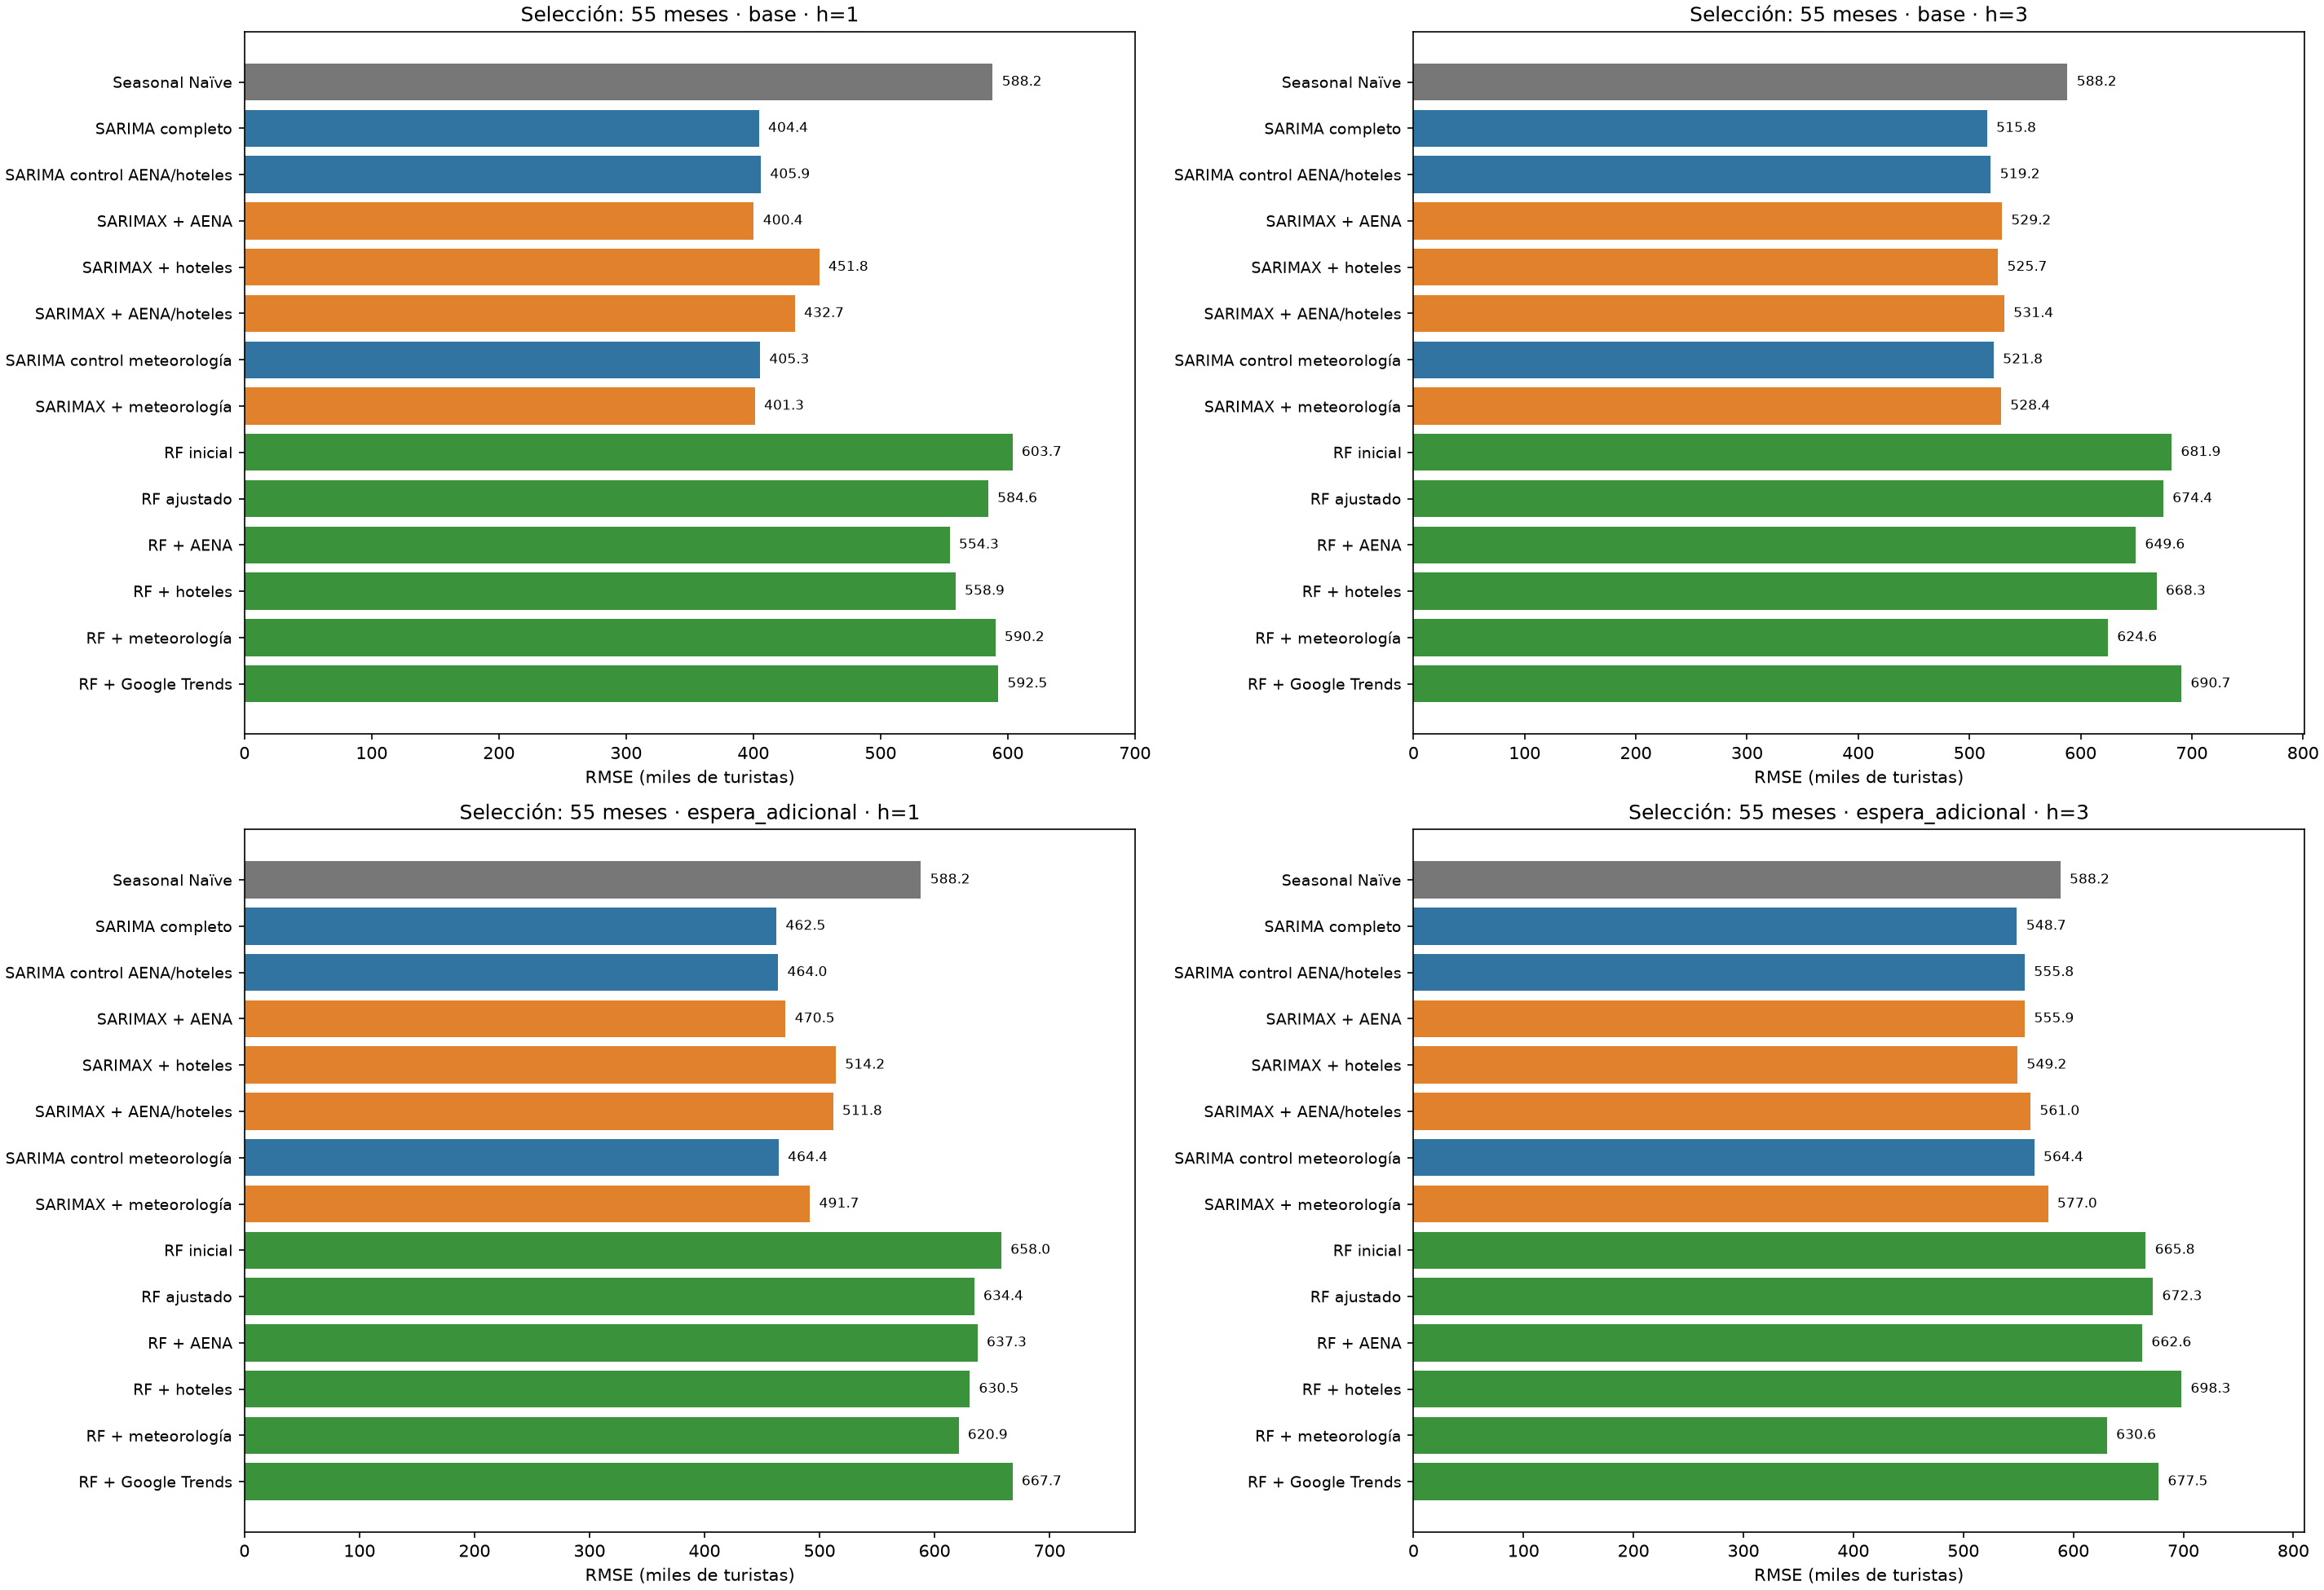

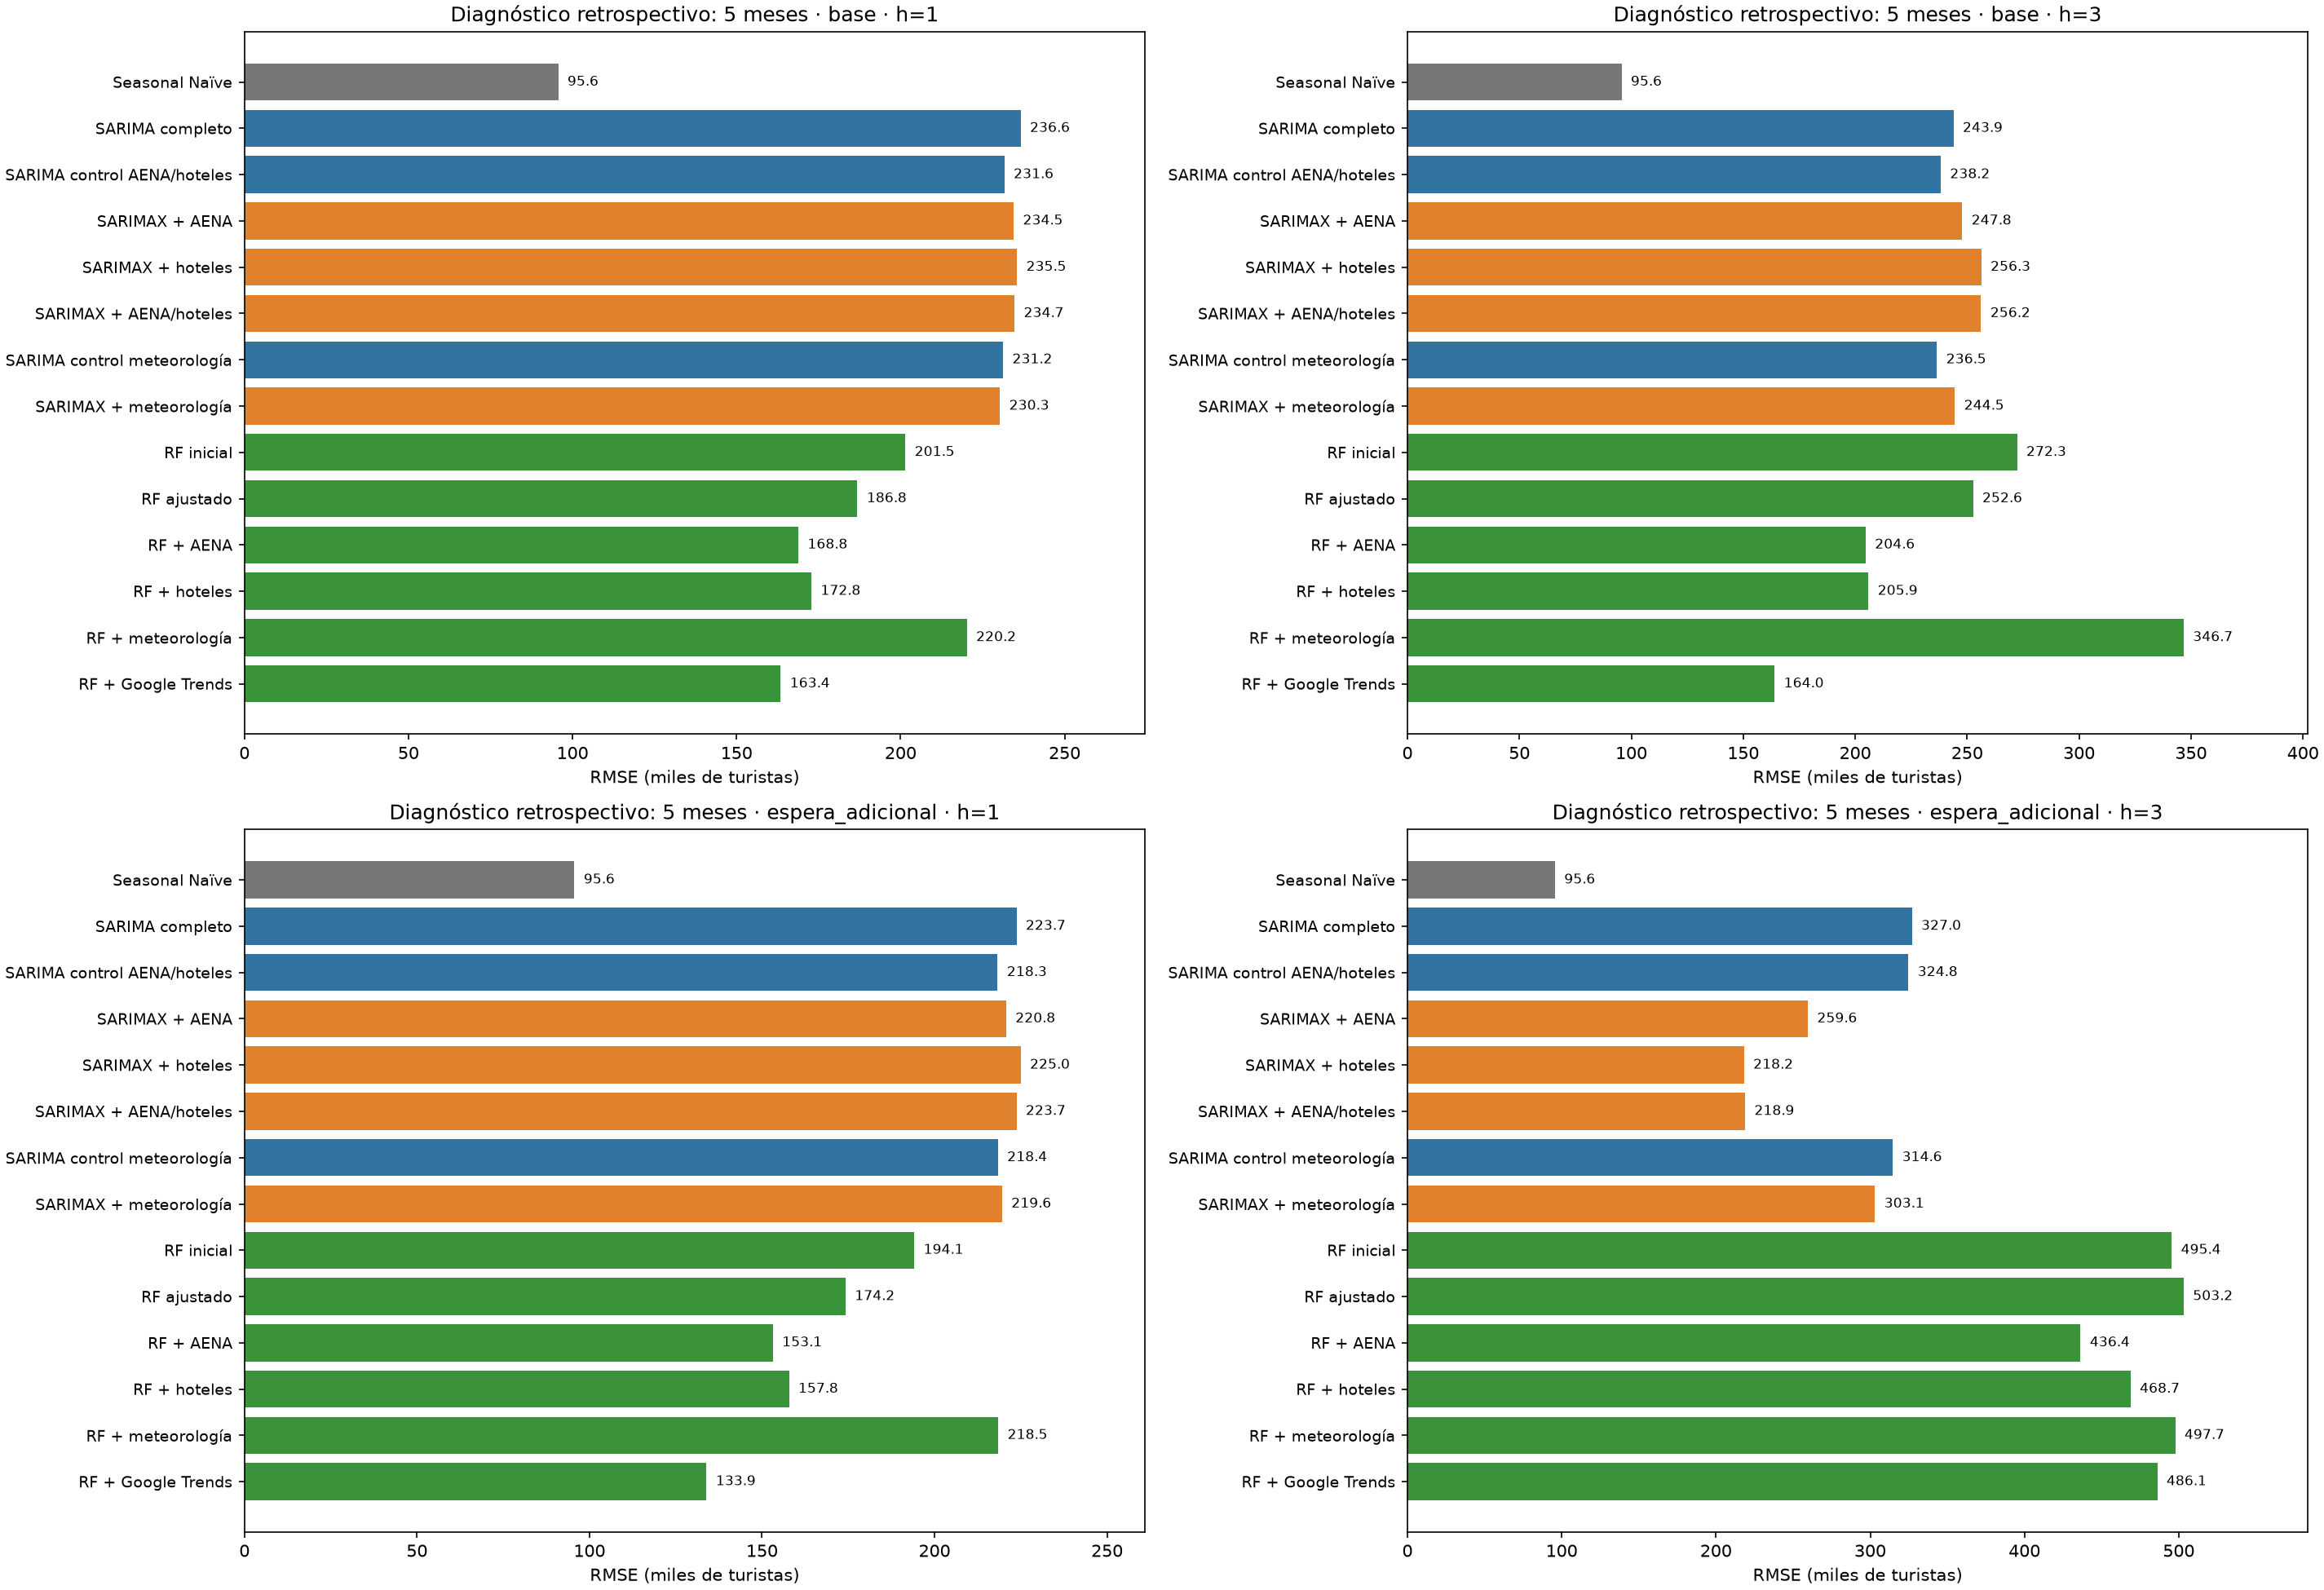

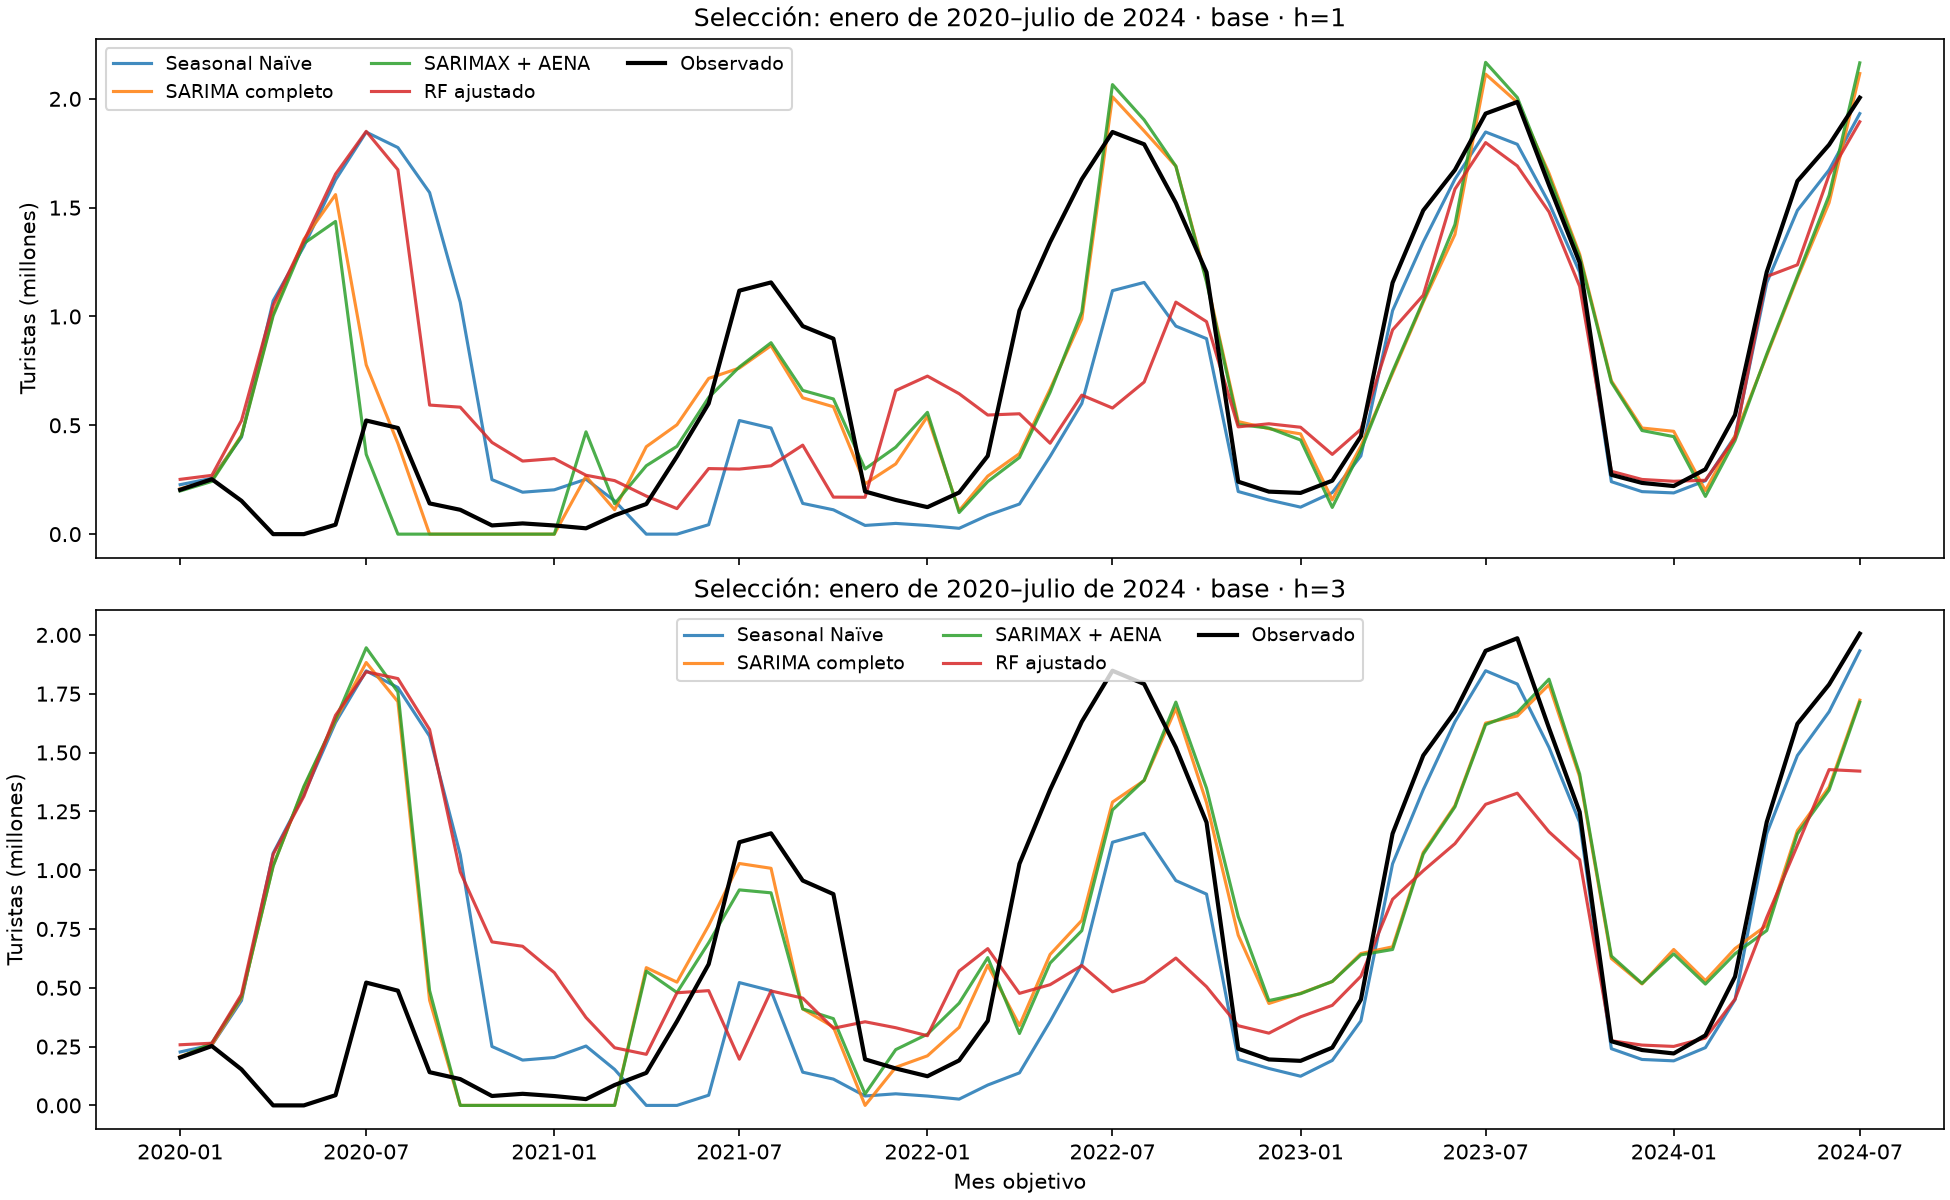

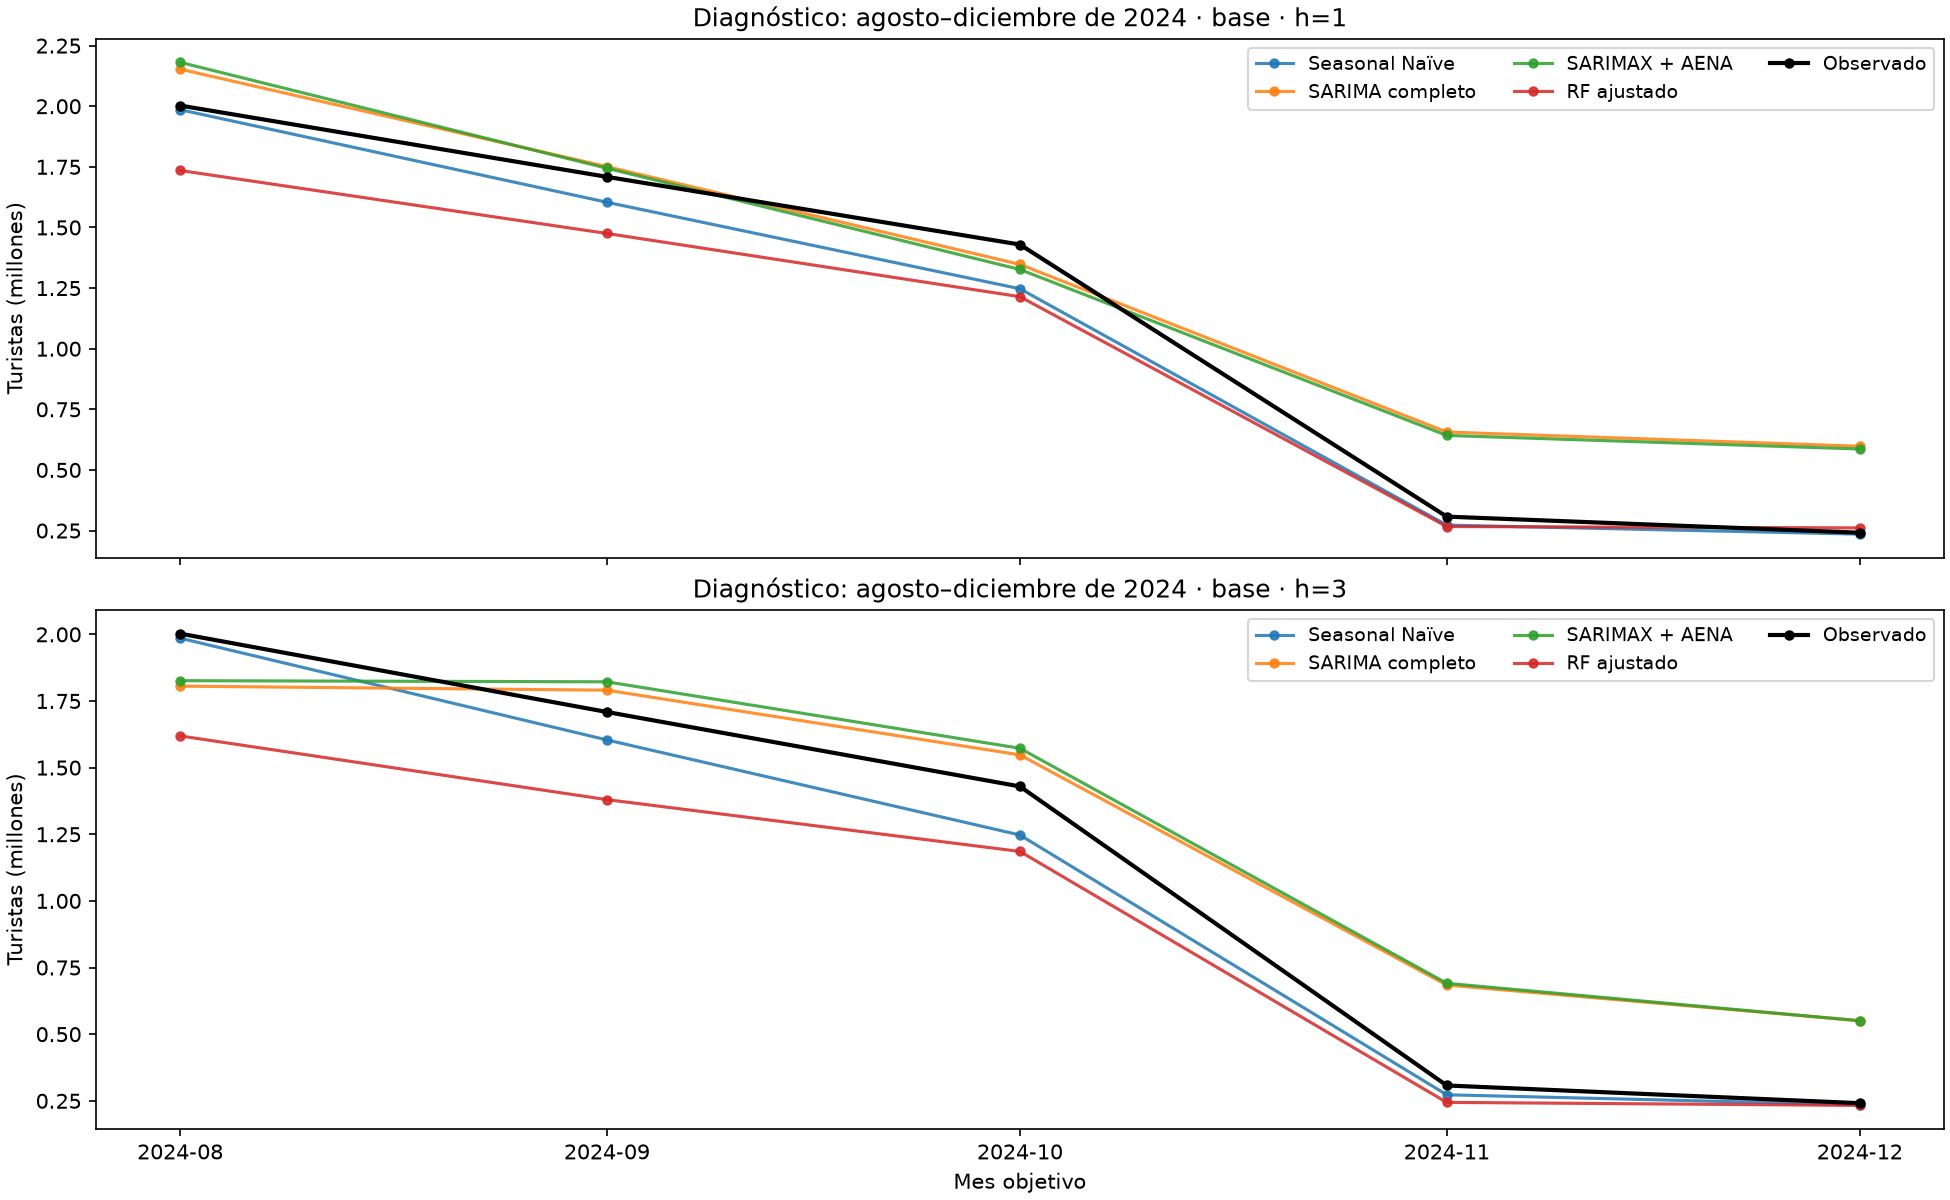


## 46. XGBoost con turistas y calendario

Se añade una referencia inicial de boosting con los mismos **14 predictores** del bosque: seis retardos de turistas, tres medias móviles, el mismo mes objetivo del año anterior y cuatro variables de calendario. Las listas proceden del catálogo por horizonte y escenario. Se utilizan exactamente los índices supervisados del protocolo y se conservan las 288 emisiones: 55 meses de selección, cinco de diagnóstico y doce de prueba por horizonte y escenario.

La predicción es directa, con ajustes separados para horizontes de uno y tres meses y ventanas expansivas. El objetivo supervisado empieza en abril de 2017 y cada ajuste exige al menos 24 filas con etiquetas ya publicadas y anteriores a 2025. Este inicio coincide con Random Forest y difiere de la historia secuencial de SARIMA. Comparar los mismos meses objetivo no iguala las longitudes de entrenamiento entre familias.

La configuración inicial es **fija, sin búsqueda de hiperparámetros**: 200 árboles, tasa de aprendizaje 0,05, profundidad máxima 3, peso mínimo por hijo 3, regularización L2 de 1 y L1 de 0. Se utilizan todas las filas y columnas (`subsample=1`, `colsample_bytree=1`), pérdida cuadrática, árboles `gbtree`, método `hist` en CPU, semilla 42 y un hilo. Profundidad y peso mínimo acotan la complejidad en una muestra mensual pequeña; no se consideran valores óptimos. La configuración se fija antes de observar sus métricas y se conserva en ambos escenarios. El significado de los parámetros se recoge en la [documentación oficial de XGBoost](https://xgboost.readthedocs.io/en/stable/parameter.html).

No se aplica escalado ni imputación, y se bloquean los ausentes inesperados aunque la librería pueda tratarlos internamente. Los ceros reales se conservan. No hay validación aleatoria, `eval_set` ni parada temprana que consulte los meses evaluados. El ajuste inicial de la librería se calcula con las etiquetas de su entrenamiento. Los pronósticos negativos se limitan a cero, como en SARIMA/SARIMAX, guardando también el valor bruto y la marca de corrección; no se fuerza el rango mínimo/máximo del bosque.

Durante 2025 se admiten retardos publicados como entradas, pero nunca etiquetas de ese año para entrenar. `EVALUATE_FINAL_2025=False` mantiene vacíos los valores observados, sus estados, errores y métricas finales. Selección y diagnóstico permanecen separados; el diagnóstico breve ya inspeccionado no se presenta como prueba independiente. Las versiones revisadas de datos y los cortes históricos incompletos siguen limitando la simulación. Las fuentes externas y la optimización de XGBoost se abordarán en experimentos posteriores.


In [30]:
from xgboost import XGBRegressor

XGB_DIR = PROJECT_ROOT / "outputs" / "modelos" / "xgboost"
XGB_DIR.mkdir(parents=True, exist_ok=True)
XGB_PARAMS = {"n_estimators":200,"learning_rate":0.05,"max_depth":3,
    "min_child_weight":3,"subsample":1.0,"colsample_bytree":1.0,"reg_lambda":1.0,
    "reg_alpha":0.0,"gamma":0.0,"objective":"reg:squarederror","booster":"gbtree",
    "tree_method":"hist","device":"cpu","random_state":42,"n_jobs":1,"verbosity":1}
xgb_columns, xgb_cache, xgb_fit_audit = {}, {}, []
for scenario,horizon in prediction_sets:
    wait=int(scenario=="espera_adicional")
    catalog=feature_catalog.loc[feature_catalog.horizonte.eq(horizon)&feature_catalog.espera_adicional.eq(wait)]
    xgb_columns[(scenario,horizon)]=catalog.loc[catalog.grupo.isin(["turistas","calendario"]),"predictor"].tolist()
    assert len(xgb_columns[(scenario,horizon)])==14


def xgb_prepare(data,row,dates=None):
    wait=int(row.escenario=="espera_adicional")
    if data is master and dates is None:
        X,meta=prediction_sets[(row.escenario,row.horizonte)]
    else:
        X,meta,_,_=build_prediction_features(data,row.horizonte,wait,verified_dates if dates is None else dates)
    cols=xgb_columns[(row.escenario,row.horizonte)]
    indices=training_indices.loc[training_indices.escenario.eq(row.escenario)
        &training_indices.horizonte.eq(row.horizonte)
        &training_indices.mes_origen_pronostico.eq(row.mes_origen)]
    origins=pd.DatetimeIndex(indices.mes_origen_entrenamiento)
    assert len(origins)==row.n_entrenamiento_supervisado and len(origins)>=MIN_TRAIN_ROWS
    labels=meta.loc[origins]
    assert labels.mes_objetivo.between(TRAIN_TARGET_START,TRAIN_TARGET_END).all()
    assert labels.fecha_publicacion_objetivo.le(row.fecha_corte).all()
    assert labels.mes_objetivo.lt(row.mes_objetivo).all() and (origins<row.mes_origen).all()
    assert labels.mes_objetivo.tolist()==indices.mes_objetivo_entrenamiento.tolist()
    train_X=X.loc[origins,cols].copy()
    train_y=labels.turistas_objetivo.astype(float).copy()
    forecast_X=X.loc[[row.mes_origen],cols].copy()
    if train_X.isna().any().any() or train_y.isna().any() or forecast_X.isna().any().any():
        raise ValueError("Entrada turística/calendario o etiqueta ausente: XGBoost no imputa ni elimina emisiones")
    assert np.isfinite(train_X.to_numpy()).all() and np.isfinite(train_y.to_numpy()).all()
    assert np.isfinite(forecast_X.to_numpy()).all() and train_y.ge(0).all()
    details={"n_entrenamiento":len(origins),"n_predictores":len(cols),
        "inicio_objetivos_entrenamiento":labels.mes_objetivo.min(),
        "ultimo_y_parametros":labels.mes_objetivo.max(),
        "ultima_publicacion_entrenamiento":labels.fecha_publicacion_objetivo.max(),
        "ceros_entrenamiento":int(train_y.eq(0).sum()),"predictores":json.dumps(cols,ensure_ascii=False)}
    return train_X,train_y,forecast_X,details


def xgb_forecast(data,row,dates=None,record_audit=True):
    train_X,train_y,forecast_X,details=xgb_prepare(data,row,dates)
    digest=hashlib.sha256(pd.util.hash_pandas_object(train_X,index=True).values.tobytes()
        +pd.util.hash_pandas_object(train_y,index=True).values.tobytes()
        +"|".join(train_X.columns).encode()+json.dumps(XGB_PARAMS,sort_keys=True).encode()).hexdigest()
    # Reutilizar solo el último ajuste por horizonte y escenario si datos y parámetros coinciden.
    key=(row.escenario,row.horizonte)
    reused=key in xgb_cache and xgb_cache[key][0]==digest
    if reused:
        model=xgb_cache[key][1]
    else:
        model=XGBRegressor(**XGB_PARAMS).fit(train_X,train_y)
        xgb_cache[key]=(digest,model)
    value=float(model.predict(forecast_X)[0])
    assert np.isfinite(value)
    details.update(hash_ajuste=digest,ajuste_reutilizado=reused,prediccion_bruta=value,
        limitada_a_cero=bool(value<0),prediccion=max(0.,value),estado_ejecucion="ok")
    if record_audit:
        xgb_fit_audit.append(dict(escenario=row.escenario,horizonte=row.horizonte,mes_origen=row.mes_origen,
            mes_objetivo=row.mes_objetivo,fecha_corte=row.fecha_corte,
            parametros=json.dumps(XGB_PARAMS,sort_keys=True),**details))
    return details


In [29]:
xgb_records=[]
for i,row in enumerate(evaluation_plan.itertuples(index=False)):
    enabled=row.uso=="validacion" or EVALUATE_FINAL_2025
    record=row._asdict()
    record.update(modelo="XGBoost",grupo_fuentes="turistas_calendario",evaluacion_habilitada=enabled,
        observado=float(master.at[row.mes_objetivo,"turistas"]) if enabled else np.nan,
        estado_objetivo=master.at[row.mes_objetivo,"turistas_estado"] if enabled else None)
    record.update(xgb_forecast(master,row))
    record["error"]=record["observado"]-record["prediccion"] if enabled else np.nan
    xgb_records.append(record)
    if (i+1)%72==0: print("XGBoost:",i+1,"/",len(evaluation_plan),"emisiones",flush=True)
xgb_predictions=pd.DataFrame(xgb_records)
xgb_metrics=summarize_forecast_errors(xgb_predictions,["modelo","escenario","horizonte","papel"])
xgb_annual=summarize_forecast_errors(xgb_predictions,["modelo","escenario","horizonte","fold"])
xgb_periods=summarize_forecast_errors(xgb_predictions.loc[xgb_predictions.uso.eq("validacion")],["modelo","escenario","horizonte","periodo"])
xgb_no_U=summarize_forecast_errors(xgb_predictions.loc[xgb_predictions.uso.eq("validacion")&~xgb_predictions.estado_objetivo.eq("U")],
    ["modelo","escenario","horizonte","papel"])
xgb_comparisons=[]
for name,folder in [("Seasonal Naive","seasonal_naive"),("SARIMA","sarima"),("Random Forest ajustado","random_forest_optimizado")]:
    reference=pd.read_csv(PROJECT_ROOT/"outputs"/"modelos"/folder/"metricas_bloques.csv")
    reference=reference[["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
    comparison=xgb_metrics.merge(reference,on=["escenario","horizonte","papel"],suffixes=("","_referencia"),validate="one_to_one")
    comparison["referencia"]=name
    complete=comparison.n_puntuados.eq(comparison.n_esperados)&comparison.n_puntuados.eq(comparison.n_puntuados_referencia)
    comparison["mejora_RMSE_porcentaje"]=np.where(complete,100*(1-comparison.RMSE/comparison.RMSE_referencia),np.nan)
    xgb_comparisons.append(comparison)
xgb_comparison=pd.concat(xgb_comparisons,ignore_index=True)
xgb_audit=pd.DataFrame(xgb_fit_audit)
xgb_catalog=feature_catalog.loc[feature_catalog.grupo.isin(["turistas","calendario"])].copy()
xgb_availability=feature_audit.loc[feature_audit.grupo.eq("turistas")].copy()
for name,table in {"predicciones":xgb_predictions,"metricas_bloques":xgb_metrics,"metricas_anuales":xgb_annual,
    "metricas_periodos":xgb_periods,"diagnostico_sin_objetivos_U":xgb_no_U,"comparacion_referencias":xgb_comparison,
    "auditoria_ajustes":xgb_audit,"catalogo_predictores":xgb_catalog,
    "disponibilidad_predictores":xgb_availability,"indices_entrenamiento":training_indices}.items():
    table.to_csv(XGB_DIR/(name+".csv"),index=False,encoding="utf-8-sig")
display(xgb_comparison.loc[xgb_comparison.escenario.eq("base"),
    ["horizonte","papel","referencia","n_puntuados","RMSE","RMSE_referencia","mejora_RMSE_porcentaje"]])


XGBoost: 72 / 288 emisiones


XGBoost: 144 / 288 emisiones


XGBoost: 216 / 288 emisiones


XGBoost: 288 / 288 emisiones


,horizonte,papel,referencia,n_puntuados,RMSE,RMSE_referencia,mejora_RMSE_porcentaje
0,1,diagnostico_fijo,Seasonal Naive,5,240485.883467,95635.506441,-151.460877
1,1,prueba_final,Seasonal Naive,0,NaN,NaN,NaN
2,1,seleccion,Seasonal Naive,55,568153.861618,588182.412138,3.405160
3,3,diagnostico_fijo,Seasonal Naive,5,180049.986524,95635.506441,-88.266882
4,3,prueba_final,Seasonal Naive,0,NaN,NaN,NaN
5,3,seleccion,Seasonal Naive,55,683127.323649,588182.412138,-16.142086
12,1,diagnostico_fijo,SARIMA,5,240485.883467,236589.029047,-1.647099
13,1,prueba_final,SARIMA,0,NaN,NaN,NaN
14,1,seleccion,SARIMA,55,568153.861618,404429.040817,-40.482954
15,3,diagnostico_fijo,SARIMA,5,180049.986524,243882.067768,26.173339


In [30]:
keys=["escenario","horizonte","mes_origen","mes_objetivo"]
assert len(xgb_predictions)==len(evaluation_plan)==288
pd.testing.assert_frame_equal(xgb_predictions[keys],evaluation_plan[keys])
assert xgb_predictions.estado_ejecucion.eq("ok").all() and xgb_predictions.prediccion.ge(0).all()
assert xgb_audit.ultimo_y_parametros.le(TRAIN_TARGET_END).all()
assert xgb_audit.ultima_publicacion_entrenamiento.le(xgb_audit.fecha_corte).all()
assert xgb_audit.n_entrenamiento.tolist()==evaluation_plan.n_entrenamiento_supervisado.tolist()
assert xgb_catalog.grupo.isin(["turistas","calendario"]).all()
assert not any(c.startswith(("meteo_","pasajeros_","viajeros_hoteles","gt_")) for cols in xgb_columns.values() for c in cols)
if not EVALUATE_FINAL_2025:
    final=xgb_predictions.loc[xgb_predictions.uso.eq("prueba_final")]
    assert final[["observado","error"]].isna().all().all() and final.estado_objetivo.isna().all()
    assert not final.evaluacion_habilitada.any()
    assert xgb_metrics.loc[xgb_metrics.papel.eq("prueba_final"),"n_puntuados"].eq(0).all()
# Perturbar etiquetas y retardos todavía no publicados no puede modificar entrenamiento o entradas.
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
        changed=master.copy(deep=True)
        wait=int(scenario=="espera_adicional")
        future=[d for d in changed.index if publication_date("turistas",d.to_period("M"),wait,verified_dates)>row.fecha_corte]
        changed.loc[future,"turistas"]=99_999_999.
        original=xgb_prepare(master,row)
        altered=xgb_prepare(changed,row)
        for a,b in zip(original[:3],altered[:3]):
            if isinstance(a,pd.DataFrame): pd.testing.assert_frame_equal(a,b)
            else: pd.testing.assert_series_equal(a,b)
        assert xgb_forecast(master,row,record_audit=False)["prediccion"]==xgb_forecast(changed,row,record_audit=False)["prediccion"]
        # Segunda estimación independiente con semilla fija: reproducibilidad numérica.
        repeated=XGBRegressor(**XGB_PARAMS).fit(original[0],original[1]).predict(original[2])[0]
        assert max(0.,float(repeated))==xgb_forecast(master,row,record_audit=False)["prediccion"]
        reference=row.mes_origen-pd.DateOffset(months=PUBLICATION_DELAYS["turistas"]+wait)
        dates=dict(verified_dates)
        dates[("turistas",reference)]=row.fecha_corte+pd.Timedelta(days=1)
        try: xgb_prepare(master,row,dates)
        except (ValueError,AssertionError): pass
        else: raise AssertionError("Una publicación tardía debe bloquear la emisión o una etiqueta requerida")
# En 2025 los valores publicados pueden entrar como retardos, pero jamás como etiquetas de ajuste.
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2025-12-01"))].itertuples(index=False))
        changed=master.copy(deep=True)
        changed.loc[changed.index.year==2025,"turistas"]=99_999_999.
        original=xgb_prepare(master,row)
        altered=xgb_prepare(changed,row)
        pd.testing.assert_frame_equal(original[0],altered[0])
        pd.testing.assert_series_equal(original[1],altered[1])
        assert not original[2].equals(altered[2]), "Los retardos publicados de 2025 pueden actualizar las entradas"
assert master.loc["2020-04-01":"2020-05-01","turistas"].eq(0).all()
assert xgb_audit.ceros_entrenamiento.max()==2
assert hashlib.sha256((OUTPUT_DIR/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()==feature_manifest["maestro_sha256"]
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    block=xgb_predictions.loc[xgb_predictions.escenario.eq("base")&xgb_predictions.horizonte.eq(horizon)&xgb_predictions.uso.eq("validacion")]
    ax.plot(block.mes_objetivo,block.observado/1e6,label="Observado",color="black",lw=2)
    ax.plot(block.mes_objetivo,block.prediccion/1e6,label="XGBoost",alpha=.9)
    for name,folder in [("Seasonal Naive","seasonal_naive"),("SARIMA","sarima"),("Random Forest ajustado","random_forest_optimizado")]:
        reference=pd.read_csv(PROJECT_ROOT/"outputs"/"modelos"/folder/"predicciones.csv",parse_dates=["mes_objetivo"])
        reference=reference.loc[reference.escenario.eq("base")&reference.horizonte.eq(horizon)&reference.uso.eq("validacion")]
        assert reference.mes_objetivo.tolist()==block.mes_objetivo.tolist()
        ax.plot(reference.mes_objetivo,reference.prediccion/1e6,label=name,alpha=.7)
    ax.axvline(SELECTION_TARGET_END+pd.DateOffset(months=1),color="gray",ls=":")
    ax.set(title=f"Turistas y calendario · horizonte {horizon} {'mes' if horizon==1 else 'meses'}",ylabel="Turistas (millones)")
    ax.legend(fontsize=9,ncol=2,loc="upper left")
axes[-1].set_xlabel("Mes objetivo")
fig.savefig(XGB_DIR/"validacion_xgboost.png",dpi=150)
plt.show()
plt.close(fig)
xgb_manifest={"modelo":"XGBRegressor","version_xgboost":importlib.metadata.version("xgboost"),"version_sklearn":importlib.metadata.version("scikit-learn"),
    "fecha_documentacion":"2026-10-12","parametros":XGB_PARAMS,"busqueda_hiperparametros":False,
    "grupos":["turistas","calendario"],"predictores":{str(k):v for k,v in xgb_columns.items()},
    "estrategia":"directa por horizonte, ventana expansiva e índices ML del protocolo",
    "inicio_objetivos_entrenamiento":str(TRAIN_TARGET_START.date()),"fin_etiquetas_ajuste":str(TRAIN_TARGET_END.date()),
    "imputacion":False,"escalado":False,"emisiones":len(xgb_predictions),"early_stopping":False,
    "limite_inferior_prediccion":0,"predicciones_limitadas_a_cero":int(xgb_predictions.limitada_a_cero.sum()),
    "fallos":int(xgb_predictions.estado_ejecucion.ne("ok").sum()),"evaluacion_final_2025_habilitada":EVALUATE_FINAL_2025,
    "controles":"superados","maestro_sha256":feature_manifest["maestro_sha256"],
    "limites":["configuración inicial fija, sin optimización","muestra mensual supervisada pequeña",
        "historia de entrenamiento distinta de modelos secuenciales","versiones revisadas y calendario histórico incompleto",
        "selección y diagnóstico retrospectivos, no prueba final independiente","boosting con extrapolación limitada; no se impone el rango de etiquetas del bosque"]}
(XGB_DIR/"ejecucion.json").write_text(json.dumps(xgb_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("XGBoost verificado:",len(xgb_predictions),"emisiones; 2025 sin puntuar:",not EVALUATE_FINAL_2025)

assert xgb_metrics.loc[xgb_metrics.papel.eq("seleccion"),"n_puntuados"].eq(55).all()
assert xgb_metrics.loc[xgb_metrics.papel.eq("diagnostico_fijo"),"n_puntuados"].eq(5).all()
assert xgb_audit.n_predictores.eq(14).all()
assert xgb_predictions.limitada_a_cero.eq(xgb_predictions.prediccion_bruta.lt(0)).all()
np.testing.assert_array_equal(xgb_predictions.prediccion, np.maximum(0,xgb_predictions.prediccion_bruta))
if not EVALUATE_FINAL_2025:
    assert len(final)==48
    assert xgb_metrics.loc[xgb_metrics.papel.eq("prueba_final"),["MAE","RMSE","sesgo_observado_menos_predicho"]].isna().all().all()
# Comprobar también las mismas fechas de corte y etiquetas que el bosque supervisado.
reference=pd.read_csv(PROJECT_ROOT/"outputs/modelos/random_forest/predicciones.csv",
    parse_dates=["mes_origen","mes_objetivo","fecha_corte"])
pd.testing.assert_frame_equal(xgb_predictions[keys+["fecha_corte"]],reference[keys+["fecha_corte"]])
np.testing.assert_allclose(xgb_predictions.observado,reference.observado,equal_nan=True)
print("Cobertura completa: 55 meses de selección y cinco de diagnóstico; 48 emisiones finales reservadas.")


XGBoost verificado: 288 emisiones; 2025 sin puntuar: True
Cobertura completa: 55 meses de selección y cinco de diagnóstico; 48 emisiones finales reservadas.


C:\Users\acort\AppData\Local\Temp\ipykernel_27176\1188522270.py:69: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


### Lectura de la referencia inicial de XGBoost

La ejecución completa las **288 emisiones sin fallos**, con 14 entradas y entre 28 y 93 filas de entrenamiento. Se realizan 258 ajustes y 30 reutilizaciones cuando los datos y parámetros del último ajuste coinciden. La actualización de entradas publicadas durante 2025 no añade etiquetas de ese año a los ajustes. No aparece ningún pronóstico negativo en esta ejecución, por lo que el límite inferior a cero no cambia sus valores.

Los RMSE del escenario base, en turistas y redondeados a la unidad, son:

| Modelo | Selección h=1 | Selección h=3 | Diagnóstico h=1 | Diagnóstico h=3 |
| --- | ---: | ---: | ---: | ---: |
| Seasonal Naïve | 588.182 | 588.182 | 95.636 | 95.636 |
| SARIMA | 404.429 | 515.841 | 236.589 | 243.882 |
| Random Forest ajustado | 584.641 | 674.365 | 186.841 | 252.611 |
| XGBoost inicial | 568.154 | 683.127 | 240.486 | 180.050 |

En los 55 meses de selección base, XGBoost obtiene menor RMSE a un mes que el bosque ajustado y la referencia estacional, pero SARIMA conserva un error menor. A tres meses, esta configuración de XGBoost tiene mayor RMSE que esas tres referencias. Las diferencias entre horizontes no permiten afirmar una ventaja general del boosting; estos parámetros son una referencia inicial y todavía no se han optimizado.

MAE aporta otra lectura: XGBoost obtiene 384.535 turistas a un mes y 512.522 a tres en selección base. En el segundo horizonte, su MAE es menor que el del bosque ajustado, aunque su RMSE es mayor. Esta discrepancia aconseja examinar los errores grandes y los desgloses por periodo, sin escoger una sola métrica porque favorezca a un modelo.

Con un mes adicional de espera, sus RMSE de selección son 610.287 y 664.047 turistas a uno y tres meses. En ese escenario ambos son menores que los del bosque ajustado, pero mayores que los de SARIMA y Seasonal Naïve. La comparación depende, por tanto, del horizonte, el escenario y la medida de error. Las tablas por año, periodo y objetivos sin marca U se conservan como diagnóstico complementario; los ceros reales permanecen en el análisis principal.

En los cinco meses de diagnóstico base, XGBoost tiene RMSE de 240.486 y 180.050 turistas. A tres meses mejora al bosque ajustado y a SARIMA en ese bloque, mientras Seasonal Naïve sigue obteniendo menor error. Es un periodo breve ya inspeccionado y no una prueba independiente. No se utilizan sus resultados para modificar la configuración ni se mezclan con los meses de selección.

Los controles confirman reproducibilidad con semilla fija, coincidencia con el calendario y las etiquetas del bosque, invariancia ante valores aún no publicados y bloqueo de publicaciones tardías. Alterar los turistas de 2025 no cambia las matrices ni etiquetas de entrenamiento, aunque sí puede cambiar las entradas publicadas de las emisiones posteriores. Las **48 predicciones finales de 2025 permanecen sin observaciones objetivo, estados, errores ni métricas**. Las fuentes, el maestro y los productos anteriores se conservan intactos.

Los resultados se guardan en `outputs/modelos/xgboost/`. Esta comparación específica se añade junto al nuevo modelo; la tabla conjunta de 14 series conserva su versión anterior hasta incorporar XGBoost en el paso correspondiente. La optimización y las fuentes externas quedan para los siguientes experimentos.

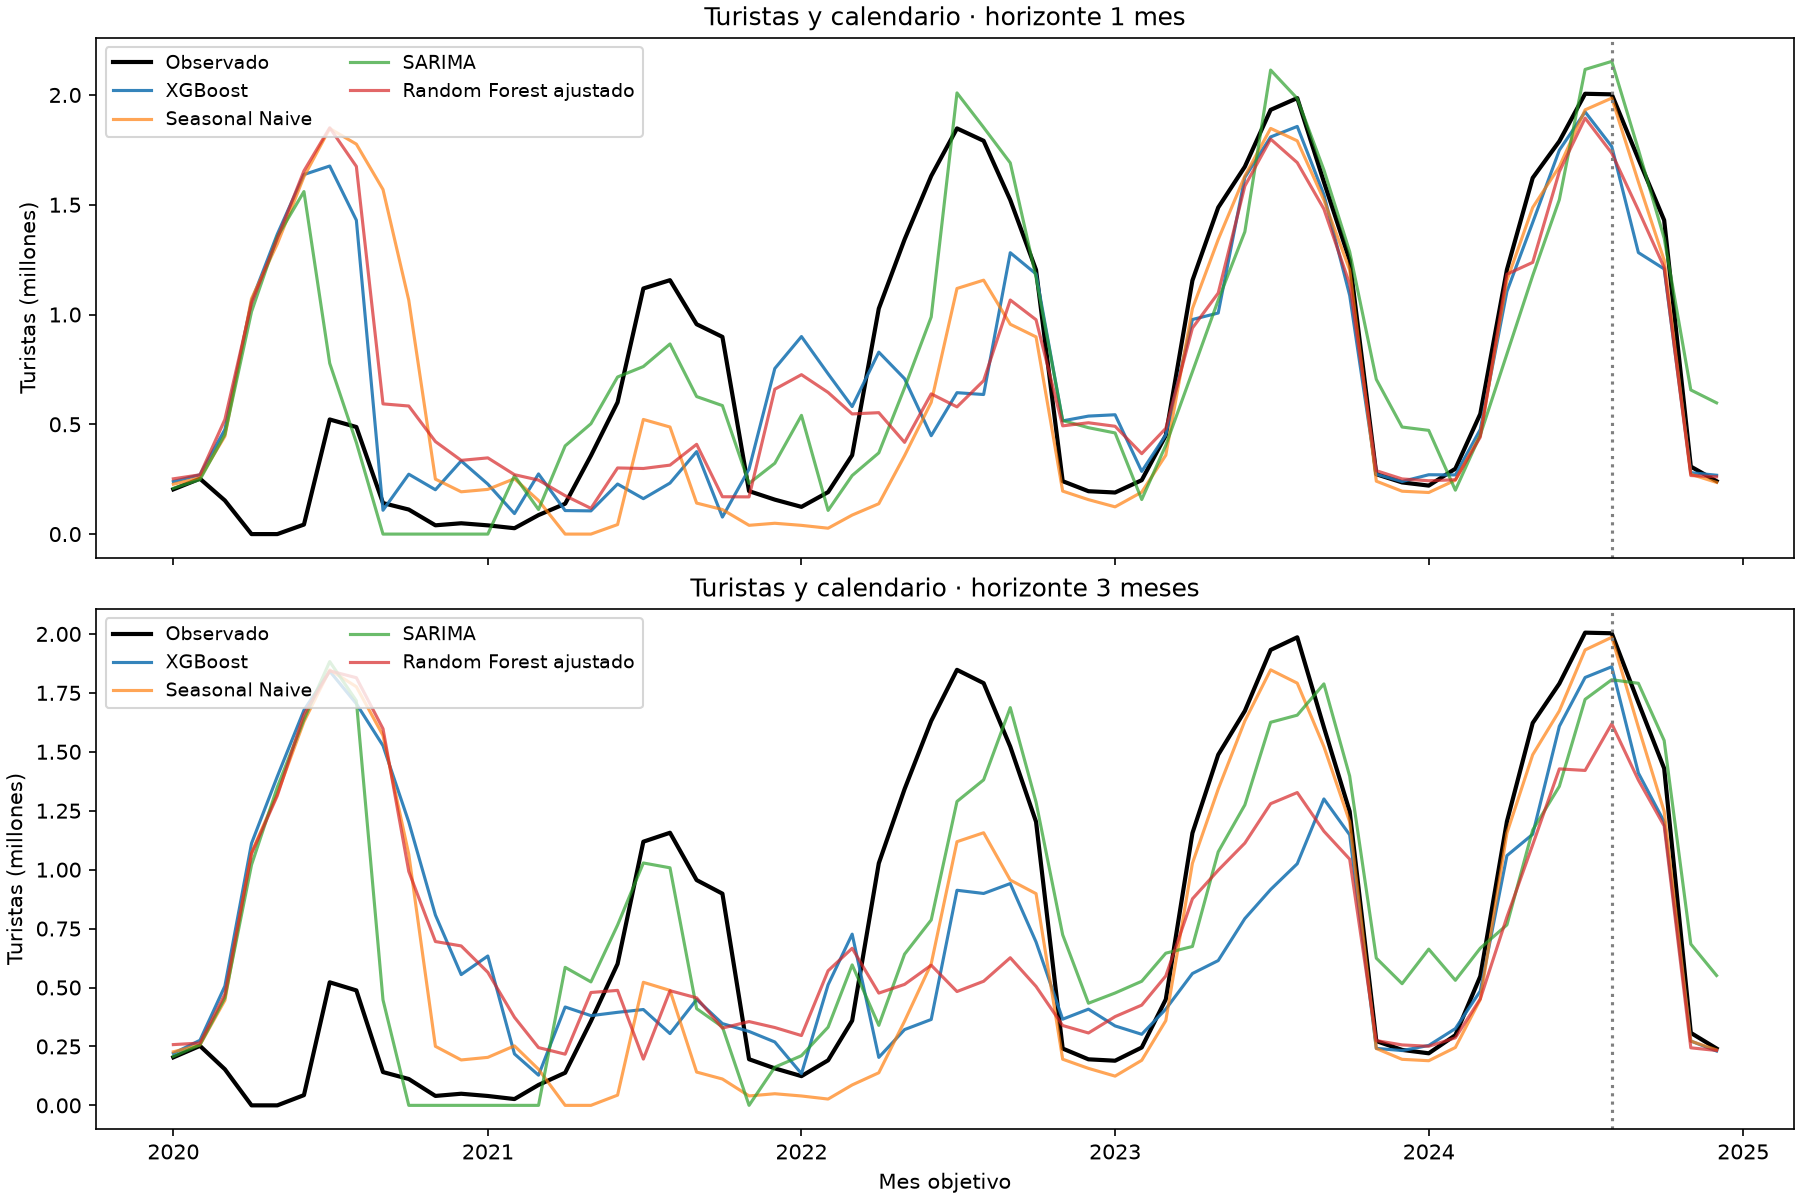


## 47. Búsqueda acotada de hiperparámetros de XGBoost

Se cruzan profundidades máximas de **2, 3 y 4** con **100 o 200 árboles**, seis configuraciones incluida la inicial (profundidad 3, 200 árboles). La rejilla se fija antes de medir los candidatos. Se mantienen los 14 predictores turísticos y de calendario, aprendizaje 0,05, peso mínimo por hijo 3, L2 de 1, L1 de 0, todas las filas y columnas, pérdida cuadrática, método `hist` en CPU, semilla 42 y un hilo. No se buscan a la vez fuentes externas ni todos los parámetros de la librería.

Para cada horizonte se elige una configuración **solo con los 55 meses de selección del escenario base**, hasta julio de 2024. Cada candidato utiliza las mismas filas supervisadas admisibles, ventanas expansivas y cortes de publicación del protocolo. Se minimiza RMSE entre candidatos con cobertura completa y métricas finitas; MAE, menor profundidad, menos árboles e identificador resuelven empates exactos. La configuración inicial se conserva y se comprueba su reproducción dentro de la búsqueda.

La configuración elegida por horizonte queda fija para diagnóstico, sensibilidad con un mes adicional de espera y las emisiones de 2025. No se vuelve a elegir usando estos bloques ni se hace una búsqueda específica para sensibilidad. Se pueden reestimar parámetros con etiquetas publicadas anteriores a 2025; las etiquetas de 2025 no participan en el ajuste. La congelación de octubre de 2024 es una regla retrospectiva, no la fecha real de ejecución de este trabajo.

Se mantienen la predicción directa, el bloqueo de ausentes y la ausencia de escalado o imputación. No se utiliza validación aleatoria, `eval_set` ni parada temprana con los meses evaluados. El límite inferior a cero guarda el pronóstico bruto y su marca. Las métricas finales continúan desactivadas; ninguna configuración se puntúa contra objetivos de 2025.

Los errores de selección sirven para elegir y contienen optimismo de selección. El diagnóstico breve ya se ha inspeccionado en otros experimentos y tampoco es una prueba independiente. Una búsqueda pequeña no garantiza el óptimo global de XGBoost. Se guardan aparte las seis configuraciones, 660 emisiones de búsqueda y 288 emisiones con configuración fija en `outputs/modelos/xgboost_optimizado/`; la referencia del bloque 46 y los modelos anteriores permanecen intactos.


In [31]:
XGBT_DIR = PROJECT_ROOT / "outputs" / "modelos" / "xgboost_optimizado"
XGBT_DIR.mkdir(parents=True, exist_ok=True)
XGBT_CANDIDATES = {}
for depth in [2,3,4]:
    for trees in [100,200]:
        name=f"profundidad{depth}_arboles{trees}"
        XGBT_CANDIDATES[name]={**XGB_PARAMS,"max_depth":depth,"n_estimators":trees}
xgbt_cache,xgbt_fit_audit={},[]


def xgbt_forecast(data,row,candidate,dates=None,record_audit=True,stage="evaluacion_fija"):
    train_X,train_y,forecast_X,details=xgb_prepare(data,row,dates)
    params=XGBT_CANDIDATES[candidate]
    digest=hashlib.sha256(pd.util.hash_pandas_object(train_X,index=True).values.tobytes()
        +pd.util.hash_pandas_object(train_y,index=True).values.tobytes()
        +"|".join(train_X.columns).encode()+json.dumps(params,sort_keys=True).encode()).hexdigest()
    key=(candidate,row.escenario,row.horizonte)
    reused=key in xgbt_cache and xgbt_cache[key][0]==digest
    if reused: model=xgbt_cache[key][1]
    else:
        model=XGBRegressor(**params).fit(train_X,train_y)
        xgbt_cache[key]=(digest,model)
    value=float(model.predict(forecast_X)[0])
    assert np.isfinite(value)
    details.update(configuracion=candidate,hash_ajuste=digest,ajuste_reutilizado=reused,
        prediccion=max(0.,value),prediccion_bruta=value,limitada_a_cero=bool(value<0),estado_ejecucion="ok")
    if record_audit:
        xgbt_fit_audit.append(dict(etapa=stage,escenario=row.escenario,horizonte=row.horizonte,
            mes_origen=row.mes_origen,mes_objetivo=row.mes_objetivo,fecha_corte=row.fecha_corte,
            parametros=json.dumps(params,sort_keys=True),**details))
    return details


def xgbt_record(row,candidate,stage):
    enabled=row.uso=="validacion" or EVALUATE_FINAL_2025
    record=row._asdict()
    record.update(modelo="XGBoost optimizado",grupo_fuentes="turistas_calendario",
        evaluacion_habilitada=enabled,
        observado=float(master.at[row.mes_objetivo,"turistas"]) if enabled else np.nan,
        estado_objetivo=master.at[row.mes_objetivo,"turistas_estado"] if enabled else None)
    record.update(xgbt_forecast(master,row,candidate,stage=stage))
    record["error"]=record["observado"]-record["prediccion"] if enabled else np.nan
    return record


def xgbt_select(predictions):
    subset=predictions.loc[predictions.escenario.eq("base")&predictions.papel.eq("seleccion")]
    assert subset.mes_objetivo.le(SELECTION_TARGET_END).all()
    assert not subset.duplicated(["configuracion","horizonte","mes_objetivo"]).any()
    metrics=summarize_forecast_errors(subset,["configuracion","horizonte"])
    metrics["elegible"]=metrics.n_esperados.eq(55)&metrics.n_pronosticos.eq(55)&metrics.n_puntuados.eq(55)
    metrics["elegible"] &= np.isfinite(metrics.RMSE) & np.isfinite(metrics.MAE)
    metrics["profundidad_desempate"]=metrics.configuracion.map(lambda c:XGBT_CANDIDATES[c]["max_depth"])
    metrics["arboles_desempate"]=metrics.configuracion.map(lambda c:XGBT_CANDIDATES[c]["n_estimators"])
    metrics["puesto_RMSE"]=metrics.loc[metrics.elegible].groupby("horizonte").RMSE.rank(method="min")
    selected=metrics.loc[metrics.elegible].sort_values(["horizonte","RMSE","MAE","profundidad_desempate","arboles_desempate","configuracion"])
    selected=selected.groupby("horizonte",as_index=False).head(1).reset_index(drop=True)
    assert selected.horizonte.tolist()==[1,3]
    selected["parametros"]=selected.configuracion.map(lambda c:json.dumps(XGBT_CANDIDATES[c],sort_keys=True))
    selected["escenario_seleccion"]="base"
    selected["ultimo_objetivo_seleccion"]=SELECTION_TARGET_END
    selected["fecha_congelacion_simulada"]=CONFIGURATION_FREEZE
    return metrics,selected


In [30]:
xgbt_selection_plan=evaluation_plan.loc[evaluation_plan.escenario.eq("base")&evaluation_plan.papel.eq("seleccion")]
assert len(xgbt_selection_plan)==110
xgbt_grid_records=[]
for candidate in XGBT_CANDIDATES:
    for row in xgbt_selection_plan.itertuples(index=False):
        xgbt_grid_records.append(xgbt_record(row,candidate,"busqueda_base"))
    print("Búsqueda terminada:",candidate,"· 110 emisiones",flush=True)
xgbt_grid_predictions=pd.DataFrame(xgbt_grid_records)
xgbt_grid_metrics,xgbt_selected=xgbt_select(xgbt_grid_predictions)
xgbt_selected_map={r.horizonte:r.configuracion for r in xgbt_selected.itertuples(index=False)}
assert len(xgbt_grid_predictions)==660
for name,table in {"busqueda_predicciones":xgbt_grid_predictions,"busqueda_metricas":xgbt_grid_metrics,
    "seleccion_configuraciones":xgbt_selected,
    "configuraciones":pd.DataFrame([dict(configuracion=k,parametros=json.dumps(v,sort_keys=True)) for k,v in XGBT_CANDIDATES.items()])}.items():
    table.to_csv(XGBT_DIR/(name+".csv"),index=False,encoding="utf-8-sig")
display(xgbt_grid_metrics[["configuracion","horizonte","n_puntuados","RMSE","MAE","elegible","puesto_RMSE"]])
display(xgbt_selected[["horizonte","configuracion","RMSE","MAE","ultimo_objetivo_seleccion"]])


Búsqueda terminada: profundidad2_arboles100 · 110 emisiones


Búsqueda terminada: profundidad2_arboles200 · 110 emisiones


Búsqueda terminada: profundidad3_arboles100 · 110 emisiones


Búsqueda terminada: profundidad3_arboles200 · 110 emisiones


Búsqueda terminada: profundidad4_arboles100 · 110 emisiones


Búsqueda terminada: profundidad4_arboles200 · 110 emisiones


,configuracion,horizonte,n_puntuados,RMSE,MAE,elegible,puesto_RMSE
0,profundidad2_arboles100,1,55,554394.328575,407481.277841,True,2.0
1,profundidad2_arboles100,3,55,671862.765354,503444.101349,True,2.0
2,profundidad2_arboles200,1,55,539205.410696,389525.368217,True,1.0
3,profundidad2_arboles200,3,55,665260.367626,487742.331250,True,1.0
4,profundidad3_arboles100,1,55,572610.612394,391123.480256,True,4.0
5,profundidad3_arboles100,3,55,686319.888673,519421.275000,True,4.0
6,profundidad3_arboles200,1,55,568153.861618,384535.295312,True,3.0
7,profundidad3_arboles200,3,55,683127.323649,512522.247159,True,3.0
8,profundidad4_arboles100,1,55,611561.050104,415147.145028,True,6.0
9,profundidad4_arboles100,3,55,700560.050178,521271.579403,True,6.0


,horizonte,configuracion,RMSE,MAE,ultimo_objetivo_seleccion
0,1,profundidad2_arboles200,539205.410696,389525.368217,2024-07-01
1,3,profundidad2_arboles200,665260.367626,487742.331250,2024-07-01


In [31]:
xgbt_records=[]
for i,row in enumerate(evaluation_plan.itertuples(index=False)):
    xgbt_records.append(xgbt_record(row,xgbt_selected_map[row.horizonte],"evaluacion_fija"))
    if (i+1)%72==0: print("Configuración fija:",i+1,"/",len(evaluation_plan),"emisiones",flush=True)
xgbt_predictions=pd.DataFrame(xgbt_records)
xgbt_metrics=summarize_forecast_errors(xgbt_predictions,["modelo","escenario","horizonte","papel"])
xgbt_annual=summarize_forecast_errors(xgbt_predictions,["modelo","escenario","horizonte","fold"])
xgbt_periods=summarize_forecast_errors(xgbt_predictions.loc[xgbt_predictions.uso.eq("validacion")],["modelo","escenario","horizonte","periodo"])
xgbt_no_U=summarize_forecast_errors(xgbt_predictions.loc[xgbt_predictions.uso.eq("validacion")&~xgbt_predictions.estado_objetivo.eq("U")],
    ["modelo","escenario","horizonte","papel"])
xgbt_comparisons=[]
for name,folder in [("XGBoost inicial","xgboost"),("Seasonal Naive","seasonal_naive"),("SARIMA","sarima"),("Random Forest ajustado","random_forest_optimizado")]:
    reference=pd.read_csv(PROJECT_ROOT/"outputs"/"modelos"/folder/"metricas_bloques.csv")
    reference=reference[["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
    comparison=xgbt_metrics.merge(reference,on=["escenario","horizonte","papel"],suffixes=("","_referencia"),validate="one_to_one")
    comparison["referencia"]=name
    complete=comparison.n_puntuados.eq(comparison.n_esperados)&comparison.n_puntuados.eq(comparison.n_puntuados_referencia)
    comparison["mejora_RMSE_porcentaje"]=np.where(complete,100*(1-comparison.RMSE/comparison.RMSE_referencia),np.nan)
    xgbt_comparisons.append(comparison)
xgbt_comparison=pd.concat(xgbt_comparisons,ignore_index=True)
xgbt_audit=pd.DataFrame(xgbt_fit_audit)
for name,table in {"predicciones":xgbt_predictions,"metricas_bloques":xgbt_metrics,"metricas_anuales":xgbt_annual,
    "metricas_periodos":xgbt_periods,"diagnostico_sin_objetivos_U":xgbt_no_U,"comparacion_referencias":xgbt_comparison,
    "auditoria_ajustes":xgbt_audit,"catalogo_predictores":xgb_catalog,
    "indices_entrenamiento":training_indices}.items():
    table.to_csv(XGBT_DIR/(name+".csv"),index=False,encoding="utf-8-sig")
display(xgbt_comparison.loc[xgbt_comparison.escenario.eq("base"),
    ["horizonte","papel","referencia","n_puntuados","RMSE","RMSE_referencia","mejora_RMSE_porcentaje"]])


Configuración fija: 72 / 288 emisiones


Configuración fija: 144 / 288 emisiones


Configuración fija: 216 / 288 emisiones


Configuración fija: 288 / 288 emisiones


,horizonte,papel,referencia,n_puntuados,RMSE,RMSE_referencia,mejora_RMSE_porcentaje
0,1,diagnostico_fijo,XGBoost inicial,5,166178.188276,240485.883467,30.898984
1,1,prueba_final,XGBoost inicial,0,NaN,NaN,NaN
2,1,seleccion,XGBoost inicial,55,539205.410696,568153.861618,5.095178
3,3,diagnostico_fijo,XGBoost inicial,5,196379.884417,180049.986524,-9.069647
4,3,prueba_final,XGBoost inicial,0,NaN,NaN,NaN
5,3,seleccion,XGBoost inicial,55,665260.367626,683127.323649,2.615465
12,1,diagnostico_fijo,Seasonal Naive,5,166178.188276,95635.506441,-73.762020
13,1,prueba_final,Seasonal Naive,0,NaN,NaN,NaN
14,1,seleccion,Seasonal Naive,55,539205.410696,588182.412138,8.326839
15,3,diagnostico_fijo,Seasonal Naive,5,196379.884417,95635.506441,-105.342024


In [32]:
keys=["escenario","horizonte","mes_origen","mes_objetivo"]
assert len(xgbt_predictions)==len(evaluation_plan)==288
pd.testing.assert_frame_equal(xgbt_predictions[keys],evaluation_plan[keys])
assert xgbt_predictions.estado_ejecucion.eq("ok").all() and xgbt_predictions.prediccion.ge(0).all()
assert xgbt_audit.ultimo_y_parametros.le(TRAIN_TARGET_END).all()
assert xgbt_audit.ultima_publicacion_entrenamiento.le(xgbt_audit.fecha_corte).all()
assert xgbt_grid_predictions.escenario.eq("base").all() and xgbt_grid_predictions.papel.eq("seleccion").all()
assert xgbt_grid_predictions.mes_objetivo.le(SELECTION_TARGET_END).all()
assert len(xgbt_grid_metrics)==12 and xgbt_grid_metrics.elegible.all()
for candidate in XGBT_CANDIDATES:
    block=xgbt_grid_predictions.loc[xgbt_grid_predictions.configuracion.eq(candidate)]
    pd.testing.assert_frame_equal(block[keys].reset_index(drop=True),xgbt_selection_plan[keys].reset_index(drop=True))
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        block=xgbt_predictions.loc[xgbt_predictions.escenario.eq(scenario)&xgbt_predictions.horizonte.eq(horizon)]
        assert block.configuracion.eq(xgbt_selected_map[horizon]).all()
        assert block.n_entrenamiento.tolist()==evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon),"n_entrenamiento_supervisado"].tolist()
# La configuración inicial debe reproducirse exactamente dentro de la búsqueda.
initial_grid=xgbt_grid_predictions.loc[xgbt_grid_predictions.configuracion.eq("profundidad3_arboles200")]
initial_reference=pd.read_csv(XGB_DIR/"predicciones.csv",parse_dates=["mes_origen","mes_objetivo"])
initial_reference=initial_reference.loc[initial_reference.escenario.eq("base")&initial_reference.papel.eq("seleccion")]
pd.testing.assert_frame_equal(initial_grid[keys+["prediccion"]].reset_index(drop=True),
    initial_reference[keys+["prediccion"]].reset_index(drop=True),check_exact=False,rtol=1e-12,atol=1e-7)
# La evaluación fija reproduce las predicciones de selección de la configuración ganadora.
for horizon,candidate in xgbt_selected_map.items():
    original=xgbt_grid_predictions.loc[xgbt_grid_predictions.horizonte.eq(horizon)&xgbt_grid_predictions.configuracion.eq(candidate),"prediccion"]
    fixed=xgbt_predictions.loc[xgbt_predictions.escenario.eq("base")&xgbt_predictions.horizonte.eq(horizon)&xgbt_predictions.papel.eq("seleccion"),"prediccion"]
    np.testing.assert_allclose(original.to_numpy(),fixed.to_numpy(),rtol=1e-12,atol=1e-7)
# Filtrar bloques excluidos antes de seleccionar: ni el diagnóstico ni 2025 cambian la elección.
excluded=xgbt_predictions.loc[~xgbt_predictions.papel.eq("seleccion")|~xgbt_predictions.escenario.eq("base")].copy()
excluded["observado"]=99_999_999.
excluded["error"]=-99_999_999.
_,unchanged=xgbt_select(pd.concat([xgbt_grid_predictions,excluded],ignore_index=True))
pd.testing.assert_frame_equal(xgbt_selected,unchanged)
if not EVALUATE_FINAL_2025:
    final=xgbt_predictions.loc[xgbt_predictions.uso.eq("prueba_final")]
    assert final[["observado","error"]].isna().all().all() and final.estado_objetivo.isna().all()
    assert not final.evaluacion_habilitada.any()
    assert xgbt_metrics.loc[xgbt_metrics.papel.eq("prueba_final"),"n_puntuados"].eq(0).all()
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
        candidate=xgbt_selected_map[horizon]
        changed=master.copy(deep=True)
        wait=int(scenario=="espera_adicional")
        future=[d for d in changed.index if publication_date("turistas",d.to_period("M"),wait,verified_dates)>row.fecha_corte]
        changed.loc[future,"turistas"]=99_999_999.
        a=xgbt_forecast(master,row,candidate,record_audit=False)
        b=xgbt_forecast(changed,row,candidate,record_audit=False)
        assert a["prediccion"]==b["prediccion"] and a["hash_ajuste"]==b["hash_ajuste"]
        train_X,train_y,forecast_X,_=xgb_prepare(master,row)
        repeated=XGBRegressor(**XGBT_CANDIDATES[candidate]).fit(train_X,train_y).predict(forecast_X)[0]
        assert max(0.,float(repeated))==a["prediccion"]
assert master.loc["2020-04-01":"2020-05-01","turistas"].eq(0).all()
assert xgbt_audit.ceros_entrenamiento.max()==2
assert hashlib.sha256((OUTPUT_DIR/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()==feature_manifest["maestro_sha256"]
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    block=xgbt_predictions.loc[xgbt_predictions.escenario.eq("base")&xgbt_predictions.horizonte.eq(horizon)&xgbt_predictions.uso.eq("validacion")]
    ax.plot(block.mes_objetivo,block.observado/1e6,label="Observado",color="black",lw=2)
    ax.plot(block.mes_objetivo,block.prediccion/1e6,label="XGBoost ajustado",alpha=.9)
    for name,folder in [("XGBoost inicial","xgboost"),("SARIMA","sarima")]:
        reference=pd.read_csv(PROJECT_ROOT/"outputs"/"modelos"/folder/"predicciones.csv",parse_dates=["mes_objetivo"])
        reference=reference.loc[reference.escenario.eq("base")&reference.horizonte.eq(horizon)&reference.uso.eq("validacion")]
        assert reference.mes_objetivo.tolist()==block.mes_objetivo.tolist()
        ax.plot(reference.mes_objetivo,reference.prediccion/1e6,label=name,alpha=.75)
    ax.axvline(SELECTION_TARGET_END+pd.DateOffset(months=1),color="gray",ls=":")
    ax.set(title=f"XGBoost · configuración fija · horizonte {horizon} {'mes' if horizon==1 else 'meses'}",ylabel="Turistas (millones)")
    ax.legend(fontsize=9,ncol=2,loc="upper left")
axes[-1].set_xlabel("Mes objetivo")
fig.savefig(XGBT_DIR/"validacion_xgboost_optimizado.png",dpi=150)
plt.show()
plt.close(fig)
xgbt_manifest={"modelo":"XGBRegressor","version_xgboost":importlib.metadata.version("xgboost"),"version_sklearn":importlib.metadata.version("scikit-learn"),
    "fecha_documentacion":"2026-10-12","configuraciones":XGBT_CANDIDATES,
    "seleccion":{str(h):{"configuracion":c,"parametros":XGBT_CANDIDATES[c]} for h,c in xgbt_selected_map.items()},
    "criterio":"RMSE, desempate MAE, menor profundidad, menos árboles e identificador",
    "escenario_seleccion":"base","seleccion_hasta":str(SELECTION_TARGET_END.date()),
    "congelacion_simulada":str(CONFIGURATION_FREEZE.date()),"espera_adicional":"mismas configuraciones, sin nueva selección",
    "predictores":"14 de turistas y calendario; índices supervisados del protocolo",
    "busqueda_emisiones":len(xgbt_grid_predictions),"evaluacion_emisiones":len(xgbt_predictions),
    "fallos":int(xgbt_predictions.estado_ejecucion.ne("ok").sum()),
    "evaluacion_final_2025_habilitada":EVALUATE_FINAL_2025,"controles":"superados",
    "maestro_sha256":feature_manifest["maestro_sha256"],"referencia_inicial_conservada":True,"early_stopping":False,"evaluacion_aleatoria":False,
    "limite_inferior_prediccion":0,"predicciones_limitadas_a_cero":int(xgbt_predictions.limitada_a_cero.sum()),
    "limites":["búsqueda pequeña, no óptimo global","selección optimista: mismos meses usados para elegir y resumir",
        "diagnóstico retrospectivo ya inspeccionado, no prueba independiente","2025 sin puntuar",
        "historia supervisada más corta que SARIMA","versiones revisadas y calendario histórico incompleto"]}
(XGBT_DIR/"ejecucion.json").write_text(json.dumps(xgbt_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("Búsqueda y evaluación verificadas:",len(xgbt_grid_predictions),"+",len(xgbt_predictions),"emisiones; 2025 sin puntuar.")

assert xgbt_metrics.loc[xgbt_metrics.papel.eq("seleccion"),"n_puntuados"].eq(55).all()
assert xgbt_metrics.loc[xgbt_metrics.papel.eq("diagnostico_fijo"),"n_puntuados"].eq(5).all()
np.testing.assert_array_equal(xgbt_predictions.prediccion,np.maximum(0,xgbt_predictions.prediccion_bruta))
assert xgbt_predictions.limitada_a_cero.eq(xgbt_predictions.prediccion_bruta.lt(0)).all()
assert xgbt_audit.n_predictores.eq(14).all()
assert xgbt_audit.loc[xgbt_audit.etapa.eq("busqueda_base"),"n_entrenamiento"].tolist()==evaluation_plan.loc[evaluation_plan.escenario.eq("base")&evaluation_plan.papel.eq("seleccion"),"n_entrenamiento_supervisado"].tolist()*6
if not EVALUATE_FINAL_2025:
    assert len(final)==48
    assert xgbt_metrics.loc[xgbt_metrics.papel.eq("prueba_final"),["RMSE","MAE","sesgo_observado_menos_predicho"]].isna().all().all()
# El tratamiento de una entrada turística no publicada sigue bloqueando el ajuste.
for horizon in [1,3]:
    row=next(evaluation_plan.loc[evaluation_plan.escenario.eq("base")&evaluation_plan.horizonte.eq(horizon)&evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
    reference=row.mes_origen-pd.DateOffset(months=PUBLICATION_DELAYS["turistas"])
    dates=dict(verified_dates)
    dates[("turistas",reference)]=row.fecha_corte+pd.Timedelta(days=1)
    try:xgbt_forecast(master,row,xgbt_selected_map[horizon],dates=dates,record_audit=False)
    except (ValueError,AssertionError):pass
    else:raise AssertionError("Una publicación tardía debe bloquear una entrada requerida")
# Etiquetas de 2025 excluidas incluso si se alteran en el maestro.
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)&evaluation_plan.mes_objetivo.eq(pd.Timestamp("2025-12-01"))].itertuples(index=False))
        changed=master.copy(deep=True)
        changed.loc[changed.index.year==2025,"turistas"]=99_999_999.
        original=xgb_prepare(master,row)
        altered=xgb_prepare(changed,row)
        pd.testing.assert_frame_equal(original[0],altered[0])
        pd.testing.assert_series_equal(original[1],altered[1])
        assert not original[2].equals(altered[2])
print("Configuración inicial reproducida; selección independiente de diagnóstico y 2025; cortes de publicación comprobados.")


C:\Users\acort\AppData\Local\Temp\ipykernel_23532\3171307517.py:73: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Búsqueda y evaluación verificadas: 660 + 288 emisiones; 2025 sin puntuar.


Configuración inicial reproducida; selección independiente de diagnóstico y 2025; cortes de publicación comprobados.


### Lectura de la búsqueda de XGBoost

Se completan **660 emisiones de búsqueda** (seis configuraciones por 55 meses y dos horizontes) y **288 emisiones de evaluación fija**, sin fallos. Las 948 entradas de auditoría incluyen 918 ajustes y 30 reutilizaciones. La búsqueda reproduce la referencia inicial y la evaluación fija reproduce los pronósticos de selección de cada configuración elegida.

Las opciones seleccionadas únicamente por RMSE base son:

| Horizonte | Profundidad máxima | Árboles | RMSE de selección | Reducción frente al inicial |
| --- | ---: | ---: | ---: | ---: |
| 1 | 2 | 200 | 539.205 | 5,10 % |
| 3 | 2 | 200 | 665.260 | 2,62 % |

Se conserva la tasa de aprendizaje 0,05 y el resto de los parámetros iniciales. La rejilla elige profundidad 2 y 200 árboles en ambos horizontes. El RMSE de selección base baja un 5,10 % a un mes y un 2,62 % a tres. Estas opciones son las mejores de la rejilla ensayada; no se consideran óptimos globales. Las cifras de selección han intervenido en la elección y no son una estimación independiente de generalización.

A un mes, el MAE base de selección pasa de 384.535 a 389.525 turistas, aunque el RMSE disminuye. A tres meses, el MAE baja de 512.522 a 487.742. La elección se mantiene conforme al criterio RMSE fijado antes de la búsqueda y se informa de la discrepancia con MAE. SARIMA conserva menor RMSE de selección en ambos horizontes; el ajuste mejora al bosque ajustado, pero no establece una superioridad general entre familias.

La comparación con el XGBoost inicial distingue los bloques y escenarios. Un porcentaje positivo indica reducción del RMSE y uno negativo, aumento:

| Escenario | Bloque | Horizonte | RMSE inicial | RMSE ajustado | Reducción |
| --- | --- | ---: | ---: | ---: | ---: |
| base | seleccion | 1 | 568.154 | 539.205 | 5,10 % |
| base | seleccion | 3 | 683.127 | 665.260 | 2,62 % |
| base | diagnostico_fijo | 1 | 240.486 | 166.178 | 30,90 % |
| base | diagnostico_fijo | 3 | 180.050 | 196.380 | -9,07 % |
| espera_adicional | seleccion | 1 | 610.287 | 605.683 | 0,75 % |
| espera_adicional | seleccion | 3 | 664.047 | 648.531 | 2,34 % |
| espera_adicional | diagnostico_fijo | 1 | 219.791 | 134.727 | 38,70 % |
| espera_adicional | diagnostico_fijo | 3 | 250.718 | 277.971 | -10,87 % |

La espera adicional utiliza las mismas opciones elegidas en la base, sin una nueva búsqueda. El RMSE de selección también disminuye en ese escenario. En diagnóstico, el ajuste reduce el RMSE a un mes, pero lo aumenta un 9,07 % a tres en la base y un 10,87 % con espera adicional. La mejora de selección no se mantiene en todos los bloques.

El diagnóstico conserva los cinco objetivos de agosto–diciembre de 2024 y no participa en la selección. Su tamaño y su inspección previa limitan la interpretación; tampoco se utiliza para cambiar las opciones después de observar la tabla. Las métricas por año, periodo y sin objetivos con marca U permiten examinar el comportamiento antes de la prueba final, conservando los ceros en el análisis principal.

Los controles comprueban el mismo calendario, los índices admisibles, los cortes de publicación y la reproducibilidad con semilla fija. Añadir resultados alterados de diagnóstico, sensibilidad y 2025 al conjunto que recibe la función de selección no cambia las opciones elegidas, porque esos bloques se excluyen antes de puntuar. Alterar observaciones aún no publicadas tampoco cambia los ajustes ni los pronósticos. Una publicación tardía bloquea las entradas requeridas.

Las etiquetas de 2025 siguen excluidas del entrenamiento. Se pueden actualizar sus retardos publicados sin volver a seleccionar ni estimar con objetivos de ese año. Las **48 emisiones finales** no contienen observaciones objetivo, estados, errores ni métricas. La referencia inicial, las fuentes, el maestro y los resultados anteriores permanecen intactos.

Las comparaciones con Seasonal Naïve, SARIMA y Random Forest ajustado se guardan en `comparacion_referencias.csv`; permiten contextualizar el cambio sin atribuir una superioridad general al ajuste. Las variables externas y la incorporación a la comparación conjunta siguen pendientes. Los productos completos de esta búsqueda se guardan en `outputs/modelos/xgboost_optimizado/`.

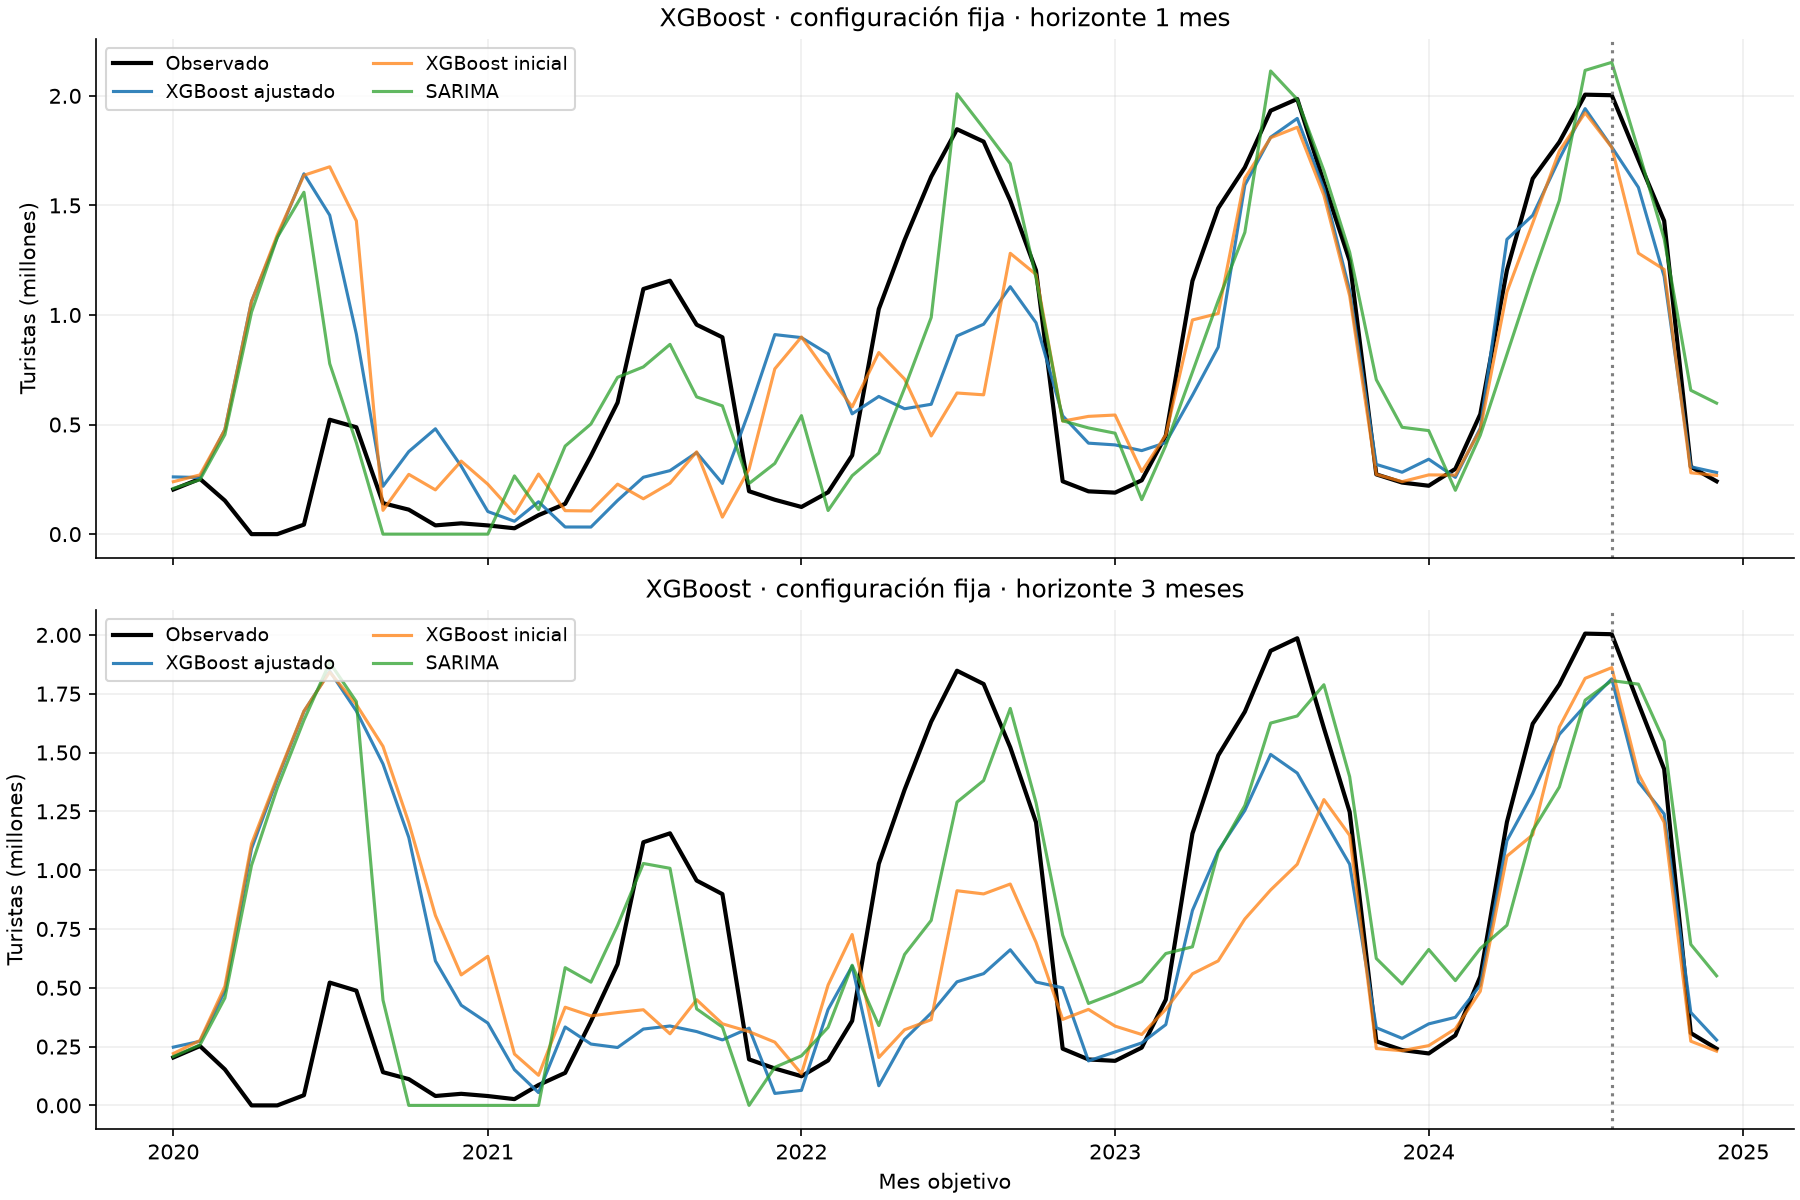


## 48. Aportación de las fuentes externas a XGBoost

Se comparan cinco variantes: turistas y calendario como control, y ese conjunto ampliado **por separado** con AENA, hoteles, temperatura y precipitación, o Google Trends. Cada variante conserva los parámetros elegidos en el bloque 47 por horizonte: profundidad 2, 200 árboles y tasa de aprendizaje 0,05, con el resto de las opciones iniciales. No se vuelven a seleccionar parámetros por fuente, escenario ni bloque de diagnóstico.

Cada grupo aporta los tres retardos del catálogo: primer mes permitido, un mes adicional y un año adicional. AENA incorpora pasajeros y operaciones; hoteles, seis indicadores; meteorología, temperatura media y precipitación total completas de B278; Google Trends, cuatro series de Alemania y Reino Unido. Las ocho variables meteorológicas secundarias permanecen fuera. El control utiliza 14 columnas; AENA y meteorología, 20; Trends, 26; hoteles, 32 entradas más 18 marcas de ausencia, 50 en total.

Los primeros retardos desde el origen son t−1 para AENA, hoteles y Trends, y t−2 para turistas y meteorología. El escenario de sensibilidad añade un mes de espera a cada grupo. Respecto al objetivo, el primer retardo externo es h+1 o h+2 según esa disponibilidad. Las fechas conocidas de publicación restringen la regla si son posteriores. Los plazos mensuales de AEMET y Trends contienen supuestos explícitos y no acreditan las primeras publicaciones históricas. Trends procede de descargas retrospectivas normalizadas para 2015–2025, sin versiones por origen.

Cada variante utiliza las mismas filas supervisadas y 288 emisiones del protocolo, con etiquetas publicadas anteriores a 2025. **Solo se imputan entradas hoteleras**, con la mediana calculada en ese entrenamiento y marcas de ausencia estables. Una publicación hotelera posterior al corte deja una entrada ausente: se utiliza la mediana admisible y su marca, sin recuperar el dato no publicado. Las otras fuentes bloquean ausentes inesperados; no se delega ese tratamiento a la gestión interna de ausentes de XGBoost. Se conservan los valores observados y los ceros.

No se escalan las entradas, se eliminan meses ni se utilizan `eval_set`, validación aleatoria o parada temprana. Las predicciones negativas se limitan a cero, conservando el valor bruto y su marca. La comparación cambia el número de entradas aunque mantiene los parámetros, por lo que no demuestra efectos causales. Los grupos se prueban individualmente; las combinaciones de fuentes quedan fuera de este experimento.

La clasificación utiliza solo los 55 meses de selección base. Diagnóstico y sensibilidad se presentan por separado y no se utilizan para cambiar parámetros. Inspeccionar varias fuentes añade optimismo de selección, y el diagnóstico breve ya visto tampoco es una prueba independiente. `EVALUATE_FINAL_2025=False` mantiene 2025 sin observar sus errores: sus datos publicados pueden actualizar retardos, pero no etiquetas de ajuste ni medianas de entrenamiento.

`outputs/modelos/xgboost_externas/` conserva las 1.440 emisiones, métricas por bloque, año y periodo, diagnóstico sin objetivos U, diferencias frente al control, clasificación base, catálogo, índices y auditorías de disponibilidad, ajustes e imputación. La referencia inicial, la búsqueda y los resultados anteriores se mantienen separados.


In [32]:
XGBX_DIR=PROJECT_ROOT/"outputs"/"modelos"/"xgboost_externas"
XGBX_DIR.mkdir(parents=True,exist_ok=True)
XGBX_VARIANTS={"turistas_calendario":None,"aena":"aena","hoteles":"hoteles",
    "meteorologia":"meteorologia","google_trends":"google_trends"}
xgbx_columns,xgbx_hotel_columns,xgbx_catalog_parts={},{},[]
for scenario,horizon in prediction_sets:
    wait=int(scenario=="espera_adicional")
    catalog=feature_catalog.loc[feature_catalog.horizonte.eq(horizon)&feature_catalog.espera_adicional.eq(wait)]
    for variant,group in XGBX_VARIANTS.items():
        selected=catalog.loc[catalog.grupo.isin(["turistas","calendario"]+([] if group is None else [group]))].copy()
        columns=xgb_columns[(scenario,horizon)]+selected.loc[selected.grupo.eq(group),"predictor"].tolist()
        assert len(columns)==len(set(columns))
        xgbx_columns[(scenario,horizon,variant)]=columns
        xgbx_hotel_columns[(scenario,horizon,variant)]=selected.loc[selected.grupo.eq("hoteles"),"predictor"].tolist()
        selected["variante"]=variant
        selected["escenario"]=scenario
        xgbx_catalog_parts.append(selected)
xgbx_catalog=pd.concat(xgbx_catalog_parts,ignore_index=True)
xgbx_cache,xgbx_fit_audit={},[]


def xgbx_prepare(row,variant,feature_frame=None,label_frame=None):
    X,meta=prediction_sets[(row.escenario,row.horizonte)]
    if feature_frame is not None:
        assert feature_frame.index.equals(X.index) and feature_frame.columns.equals(X.columns)
        X=feature_frame
    if label_frame is not None:
        assert label_frame.index.equals(meta.index) and label_frame.columns.equals(meta.columns)
        meta=label_frame
    indices=training_indices.loc[training_indices.escenario.eq(row.escenario)&training_indices.horizonte.eq(row.horizonte)
        &training_indices.mes_origen_pronostico.eq(row.mes_origen)]
    origins=pd.DatetimeIndex(indices.mes_origen_entrenamiento)
    labels=meta.loc[origins]
    assert len(origins)==row.n_entrenamiento_supervisado and len(origins)>=MIN_TRAIN_ROWS
    assert labels.mes_objetivo.between(TRAIN_TARGET_START,TRAIN_TARGET_END).all()
    assert labels.fecha_publicacion_objetivo.le(row.fecha_corte).all()
    assert labels.mes_objetivo.tolist()==indices.mes_objetivo_entrenamiento.tolist()
    assert labels.mes_objetivo.lt(row.mes_objetivo).all() and (origins<row.mes_origen).all()
    columns=xgbx_columns[(row.escenario,row.horizonte,variant)]
    hotels=xgbx_hotel_columns[(row.escenario,row.horizonte,variant)]
    raw_train=X.loc[origins,columns].copy()
    raw_forecast=X.loc[[row.mes_origen],columns].copy()
    imputer=HotelMedianImputer().fit(raw_train,hotels)
    train_X=imputer.transform(raw_train)
    forecast_X=imputer.transform(raw_forecast)
    train_y=labels.turistas_objetivo.astype(float).copy()
    assert train_X.columns.equals(forecast_X.columns) and train_X.index.equals(train_y.index)
    assert np.isfinite(train_X.to_numpy()).all() and np.isfinite(forecast_X.to_numpy()).all()
    assert np.isfinite(train_y.to_numpy()).all() and train_y.ge(0).all()
    for column in columns:
        for raw,prepared in [(raw_train,train_X),(raw_forecast,forecast_X)]:
            observed=raw[column].notna()
            pd.testing.assert_series_equal(raw.loc[observed,column],prepared.loc[observed,column])
    details={"n_entrenamiento":len(origins),"n_predictores_originales":len(columns),"n_predictores_preparados":len(train_X.columns),
        "inicio_objetivos_entrenamiento":labels.mes_objetivo.min(),"ultimo_y_parametros":labels.mes_objetivo.max(),
        "ultima_publicacion_entrenamiento":labels.fecha_publicacion_objetivo.max(),
        "ceros_entrenamiento":int(train_y.eq(0).sum()),"predictores":json.dumps(train_X.columns.tolist(),ensure_ascii=False),
        "columnas_hoteleras":json.dumps(hotels),"medianas":json.dumps(imputer.medians_.to_dict(),ensure_ascii=False),
        "observados_por_columna_hotelera":json.dumps(imputer.observed_counts_.to_dict()),
        "sustituciones_entrenamiento":int(raw_train[hotels].isna().sum().sum()),
        "sustituciones_pronostico":int(raw_forecast[hotels].isna().sum().sum())}
    return train_X,train_y,forecast_X,details,imputer


def xgbx_forecast(row,variant,feature_frame=None,label_frame=None,record_audit=True):
    train_X,train_y,forecast_X,details,_=xgbx_prepare(row,variant,feature_frame,label_frame)
    candidate=xgbt_selected_map[row.horizonte]
    params=XGBT_CANDIDATES[candidate]
    digest=hashlib.sha256(pd.util.hash_pandas_object(train_X,index=True).values.tobytes()
        +pd.util.hash_pandas_object(train_y,index=True).values.tobytes()
        +"|".join(train_X.columns).encode()+json.dumps(params,sort_keys=True).encode()).hexdigest()
    key=(variant,row.escenario,row.horizonte)
    reused=key in xgbx_cache and xgbx_cache[key][0]==digest
    if reused: model=xgbx_cache[key][1]
    else:
        model=XGBRegressor(**params).fit(train_X,train_y)
        xgbx_cache[key]=(digest,model)
    value=float(model.predict(forecast_X)[0])
    assert np.isfinite(value)
    details.update(configuracion=candidate,hash_ajuste=digest,ajuste_reutilizado=reused,
        prediccion=max(0.,value),prediccion_bruta=value,limitada_a_cero=bool(value<0),estado_ejecucion="ok")
    if record_audit:
        xgbx_fit_audit.append(dict(escenario=row.escenario,horizonte=row.horizonte,variante=variant,
            mes_origen=row.mes_origen,mes_objetivo=row.mes_objetivo,fecha_corte=row.fecha_corte,
            parametros=json.dumps(params,sort_keys=True),**details))
    return details


In [33]:
xgbx_records=[]
for variant in XGBX_VARIANTS:
    for i,row in enumerate(evaluation_plan.itertuples(index=False)):
        enabled=row.uso=="validacion" or EVALUATE_FINAL_2025
        record=row._asdict()
        record.update(modelo="XGBoost",variante=variant,grupo_fuentes="turistas_calendario" if variant=="turistas_calendario" else "turistas_calendario+"+variant,
            evaluacion_habilitada=enabled,observado=float(master.at[row.mes_objetivo,"turistas"]) if enabled else np.nan,
            estado_objetivo=master.at[row.mes_objetivo,"turistas_estado"] if enabled else None)
        record.update(xgbx_forecast(row,variant))
        record["error"]=record["observado"]-record["prediccion"] if enabled else np.nan
        xgbx_records.append(record)
        if (i+1)%72==0: print("Fuente",variant,":",i+1,"/",len(evaluation_plan),"emisiones",flush=True)
xgbx_predictions=pd.DataFrame(xgbx_records)
xgbx_metrics=summarize_forecast_errors(xgbx_predictions,["variante","escenario","horizonte","papel"])
xgbx_annual=summarize_forecast_errors(xgbx_predictions,["variante","escenario","horizonte","fold"])
xgbx_periods=summarize_forecast_errors(xgbx_predictions.loc[xgbx_predictions.uso.eq("validacion")],["variante","escenario","horizonte","periodo"])
xgbx_no_U=summarize_forecast_errors(xgbx_predictions.loc[xgbx_predictions.uso.eq("validacion")&~xgbx_predictions.estado_objetivo.eq("U")],
    ["variante","escenario","horizonte","papel"])
xgbx_control=xgbx_metrics.loc[xgbx_metrics.variante.eq("turistas_calendario"),["escenario","horizonte","papel","RMSE","MAE","n_puntuados"]]
xgbx_comparison=xgbx_metrics.merge(xgbx_control,on=["escenario","horizonte","papel"],suffixes=("","_control"),validate="many_to_one")
complete=xgbx_comparison.n_puntuados.eq(xgbx_comparison.n_esperados)&xgbx_comparison.n_puntuados.eq(xgbx_comparison.n_puntuados_control)
xgbx_comparison["mejora_RMSE_porcentaje"]=np.where(complete,100*(1-xgbx_comparison.RMSE/xgbx_comparison.RMSE_control),np.nan)
xgbx_comparison["mejora_MAE_porcentaje"]=np.where(complete,100*(1-xgbx_comparison.MAE/xgbx_comparison.MAE_control),np.nan)
xgbx_ranking=xgbx_metrics.loc[xgbx_metrics.escenario.eq("base")&xgbx_metrics.papel.eq("seleccion")].copy()
xgbx_ranking["elegible"]=xgbx_ranking.n_pronosticos.eq(55)&xgbx_ranking.n_puntuados.eq(55)
xgbx_ranking["elegible"] &= np.isfinite(xgbx_ranking.RMSE) & np.isfinite(xgbx_ranking.MAE)
xgbx_ranking["puesto_RMSE"]=xgbx_ranking.loc[xgbx_ranking.elegible].groupby("horizonte").RMSE.rank(method="min")
xgbx_audit=pd.DataFrame(xgbx_fit_audit)
# La disponibilidad por referencia ya se documenta en el catálogo y auditoría originales.
xgbx_availability=feature_audit.copy()
for name,table in {"predicciones":xgbx_predictions,"metricas_bloques":xgbx_metrics,"metricas_anuales":xgbx_annual,
    "metricas_periodos":xgbx_periods,"diagnostico_sin_objetivos_U":xgbx_no_U,"comparacion_control":xgbx_comparison,
    "clasificacion_seleccion_base":xgbx_ranking,"auditoria_ajustes_imputacion":xgbx_audit,
    "catalogo_variantes":xgbx_catalog,"disponibilidad_predictores":xgbx_availability,
    "indices_entrenamiento":training_indices}.items():
    table.to_csv(XGBX_DIR/(name+".csv"),index=False,encoding="utf-8-sig")
display(xgbx_comparison.loc[xgbx_comparison.escenario.eq("base"),
    ["variante","horizonte","papel","n_puntuados","RMSE","RMSE_control","mejora_RMSE_porcentaje"]])


Fuente turistas_calendario : 72 / 288 emisiones


Fuente turistas_calendario : 144 / 288 emisiones


Fuente turistas_calendario : 216 / 288 emisiones


Fuente turistas_calendario : 288 / 288 emisiones


Fuente aena : 72 / 288 emisiones


...

Fuente google_trends : 72 / 288 emisiones


Fuente google_trends : 144 / 288 emisiones


Fuente google_trends : 216 / 288 emisiones


Fuente google_trends : 288 / 288 emisiones


,variante,horizonte,papel,n_puntuados,RMSE,RMSE_control,mejora_RMSE_porcentaje
0,aena,1,diagnostico_fijo,5,170344.716736,166178.188276,-2.507266
1,aena,1,prueba_final,0,NaN,NaN,NaN
2,aena,1,seleccion,55,531833.350088,539205.410696,1.367208
3,aena,3,diagnostico_fijo,5,158539.141040,196379.884417,19.269155
4,aena,3,prueba_final,0,NaN,NaN,NaN
5,aena,3,seleccion,55,645506.662353,665260.367626,2.969319
12,google_trends,1,diagnostico_fijo,5,154209.930425,166178.188276,7.202063
13,google_trends,1,prueba_final,0,NaN,NaN,NaN
14,google_trends,1,seleccion,55,501443.421100,539205.410696,7.003266
15,google_trends,3,diagnostico_fijo,5,136202.803477,196379.884417,30.643200


In [34]:
keys=["escenario","horizonte","mes_origen","mes_objetivo"]
assert len(xgbx_predictions)==5*len(evaluation_plan)==1440
assert xgbx_predictions.estado_ejecucion.eq("ok").all() and xgbx_predictions.prediccion.ge(0).all()
for variant in XGBX_VARIANTS:
    block=xgbx_predictions.loc[xgbx_predictions.variante.eq(variant)]
    pd.testing.assert_frame_equal(block[keys].reset_index(drop=True),evaluation_plan[keys].reset_index(drop=True))
    assert block.n_entrenamiento.tolist()==evaluation_plan.n_entrenamiento_supervisado.tolist()
assert xgbx_audit.ultimo_y_parametros.le(TRAIN_TARGET_END).all()
assert xgbx_audit.ultima_publicacion_entrenamiento.le(xgbx_audit.fecha_corte).all()
for horizon,candidate in xgbt_selected_map.items():
    assert xgbx_predictions.loc[xgbx_predictions.horizonte.eq(horizon),"configuracion"].eq(candidate).all()
# Reproducir el control optimizado en todas las emisiones, también las reservadas.
control=xgbx_predictions.loc[xgbx_predictions.variante.eq("turistas_calendario")]
reference=pd.read_csv(XGBT_DIR/"predicciones.csv",parse_dates=["mes_origen","mes_objetivo"])
pd.testing.assert_frame_equal(control[keys+["prediccion"]].reset_index(drop=True),reference[keys+["prediccion"]].reset_index(drop=True),
    check_exact=False,rtol=1e-12,atol=1e-7)
for variant,expected in {"turistas_calendario":14,"aena":20,"hoteles":50,"meteorologia":20,"google_trends":26}.items():
    assert xgbx_predictions.loc[xgbx_predictions.variante.eq(variant),"n_predictores_preparados"].eq(expected).all()
if not EVALUATE_FINAL_2025:
    final=xgbx_predictions.loc[xgbx_predictions.uso.eq("prueba_final")]
    assert final[["observado","error"]].isna().all().all() and final.estado_objetivo.isna().all()
    assert not final.evaluacion_habilitada.any()
    assert xgbx_metrics.loc[xgbx_metrics.papel.eq("prueba_final"),"n_puntuados"].eq(0).all()
assert xgbx_ranking.elegible.all()
# Comparar matrices y pronósticos después de alterar datos aún no publicados de todas las fuentes.
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)
            &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
        wait=int(scenario=="espera_adicional")
        changed=master.copy(deep=True)
        for group,variables in GROUP_VARIABLES.items():
            future=[d for d in changed.index if publication_date(group,d.to_period("M"),wait,verified_dates)>row.fecha_corte]
            changed.loc[future,variables]=99_999_999.
        altered_X,altered_meta,_,_=build_prediction_features(changed,horizon,wait,verified_dates)
        for variant in XGBX_VARIANTS:
            a=xgbx_prepare(row,variant)
            b=xgbx_prepare(row,variant,altered_X,altered_meta)
            pd.testing.assert_frame_equal(a[0],b[0])
            pd.testing.assert_series_equal(a[1],b[1])
            pd.testing.assert_frame_equal(a[2],b[2])
            pd.testing.assert_series_equal(a[4].medians_,b[4].medians_)
            original=xgbx_forecast(row,variant,record_audit=False)
            perturbed=xgbx_forecast(row,variant,altered_X,altered_meta,record_audit=False)
            assert original["prediccion"]==perturbed["prediccion"] and original["hash_ajuste"]==perturbed["hash_ajuste"]
        X,meta=prediction_sets[(scenario,horizon)]
        train,y,forecast,info,imputer=xgbx_prepare(row,"hoteles")
        pd.testing.assert_series_equal(imputer.medians_,X.loc[train.index,imputer.hotel_columns_].median())
        # Modificar hoteles fuera de las filas de entrenamiento no altera las medianas.
        excluded=X.copy(deep=True)
        outside=~excluded.index.isin(train.index)
        excluded.loc[outside,imputer.hotel_columns_]=99_999_999.
        _,_,_,_,other=xgbx_prepare(row,"hoteles",excluded)
        pd.testing.assert_series_equal(imputer.medians_,other.medians_)
# Publicación tardía: hoteles usa solo medianas de entrenamiento y marca; otras fuentes bloquean.
row=next(evaluation_plan.loc[evaluation_plan.escenario.eq("base")&evaluation_plan.horizonte.eq(1)
    &evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
for variant,group in XGBX_VARIANTS.items():
    if group is None: continue
    dates=dict(verified_dates)
    ref=row.mes_origen-pd.DateOffset(months=PUBLICATION_DELAYS[group])
    dates[(group,ref)]=row.fecha_corte+pd.Timedelta(days=1)
    late_X,late_meta,_,_=build_prediction_features(master,row.horizonte,0,dates)
    if group=="hoteles":
        _,_,forecast,_,imputer=xgbx_prepare(row,variant,late_X,late_meta)
        impacted=[c for c in imputer.hotel_columns_ if late_X.at[row.mes_origen,c]!=late_X.at[row.mes_origen,c]]
        assert impacted and forecast[[c+"__ausente" for c in impacted]].eq(1).all().all()
        for c in impacted: assert forecast.iloc[0][c]==imputer.medians_[c]
    else:
        try: xgbx_prepare(row,variant,late_X,late_meta)
        except ValueError: pass
        else: raise AssertionError("Una fuente no hotelera tardía debe bloquearse, no imputarse")
assert master.loc["2020-04-01":"2020-05-01","turistas"].eq(0).all()
assert xgbx_audit.ceros_entrenamiento.max()==2
assert xgbx_audit.loc[~xgbx_audit.variante.eq("hoteles"),["sustituciones_entrenamiento","sustituciones_pronostico"]].eq(0).all().all()
assert hashlib.sha256((OUTPUT_DIR/"dataset_maestro_mallorca.csv").read_bytes()).hexdigest()==feature_manifest["maestro_sha256"]
fig,axes=plt.subplots(2,1,figsize=(12,8),sharex=True,constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    for variant in XGBX_VARIANTS:
        block=xgbx_predictions.loc[xgbx_predictions.escenario.eq("base")&xgbx_predictions.horizonte.eq(horizon)
            &xgbx_predictions.variante.eq(variant)&xgbx_predictions.uso.eq("validacion")]
        ax.plot(block.mes_objetivo,block.prediccion/1e6,label=variant,alpha=.75)
    ax.plot(block.mes_objetivo,block.observado/1e6,label="Observado",color="black",lw=2)
    ax.axvline(SELECTION_TARGET_END+pd.DateOffset(months=1),color="gray",ls=":")
    ax.set(title=f"XGBoost · fuentes por separado · horizonte {horizon} {'mes' if horizon==1 else 'meses'}",ylabel="Turistas (millones)")
    ax.legend(fontsize=8,ncol=3,loc="upper left")
axes[-1].set_xlabel("Mes objetivo")
fig.savefig(XGBX_DIR/"validacion_fuentes_externas.png",dpi=150)
plt.show()
plt.close(fig)
fig,axes=plt.subplots(1,2,figsize=(13,5),constrained_layout=True)
for ax,horizon in zip(axes,[1,3]):
    block=xgbx_comparison.loc[xgbx_comparison.escenario.eq("base")&xgbx_comparison.horizonte.eq(horizon)&xgbx_comparison.papel.eq("seleccion")]
    ax.barh(block.variante,block.RMSE/1e3)
    ax.axvline(block.RMSE_control.iloc[0]/1e3,color="black",ls=":",label="Control")
    ax.set(title=f"Selección base · h={horizon}",xlabel="RMSE (miles de turistas)")
    ax.legend()
fig.savefig(XGBX_DIR/"rmse_seleccion_fuentes.png",dpi=150)
plt.show()
plt.close(fig)
xgbx_manifest={"modelo":"XGBRegressor","version_xgboost":importlib.metadata.version("xgboost"),"version_sklearn":importlib.metadata.version("scikit-learn"),
    "fecha_documentacion":"2026-10-12","variantes":XGBX_VARIANTS,
    "parametros_fijos":{str(h):XGBT_CANDIDATES[c] for h,c in xgbt_selected_map.items()},
    "seleccion_hiperparametros":"bloque 47, solo turistas/calendario, selección base; sin nueva búsqueda por fuente",
    "variables_por_fuente":{g:(METEO_CORE if g=="meteorologia" else GROUP_VARIABLES[g]) for g in XGBX_VARIANTS.values() if g},
    "retardos":"catálogo: primer mes permitido, +1 y +12 desde origen; espera adicional en todos los grupos",
    "politica_disponibilidad":availability_policy,"imputacion":"mediana hotelera por entrenamiento y marcas; otras fuentes bloquean",
    "escalado":False,"mismos_indices_entrenamiento":True,"early_stopping":False,
    "limite_inferior_prediccion":0,"predicciones_limitadas_a_cero":int(xgbx_predictions.limitada_a_cero.sum()),"emisiones":len(xgbx_predictions),
    "fallos":int(xgbx_predictions.estado_ejecucion.ne("ok").sum()),"evaluacion_final_2025_habilitada":EVALUATE_FINAL_2025,
    "controles":"superados","maestro_sha256":feature_manifest["maestro_sha256"],
    "limites":["fuentes por separado, sin combinaciones","diferente dimensionalidad por fuente","sin inferencia causal",
        "Google Trends retrospectivo normalizado en 2015-2025, no versiones por origen",
        "meteorología mensual con plazo supuesto y datos revisados","selección de fuentes exploratoria, diagnóstico ya inspeccionado",
        "2025 sin puntuar"]}
(XGBX_DIR/"ejecucion.json").write_text(json.dumps(xgbx_manifest,ensure_ascii=False,indent=2),encoding="utf-8")
print("Fuentes externas verificadas:",len(xgbx_predictions),"emisiones; 2025 sin puntuar.")

assert xgbx_metrics.loc[xgbx_metrics.papel.eq("seleccion"),"n_puntuados"].eq(55).all()
assert xgbx_metrics.loc[xgbx_metrics.papel.eq("diagnostico_fijo"),"n_puntuados"].eq(5).all()
np.testing.assert_array_equal(xgbx_predictions.prediccion,np.maximum(0,xgbx_predictions.prediccion_bruta))
assert xgbx_predictions.limitada_a_cero.eq(xgbx_predictions.prediccion_bruta.lt(0)).all()
if not EVALUATE_FINAL_2025:
    assert len(final)==240
    assert xgbx_metrics.loc[xgbx_metrics.papel.eq("prueba_final"),["MAE","RMSE","sesgo_observado_menos_predicho"]].isna().all().all()
# Repetir de forma independiente un ajuste por fuente, incluyendo hoteles con marcas estables.
row=next(evaluation_plan.loc[evaluation_plan.escenario.eq("base")&evaluation_plan.horizonte.eq(1)&evaluation_plan.mes_objetivo.eq(pd.Timestamp("2024-07-01"))].itertuples(index=False))
for variant in XGBX_VARIANTS:
    train,y,forecast,_,_=xgbx_prepare(row,variant)
    repeated=float(XGBRegressor(**XGBT_CANDIDATES[xgbt_selected_map[row.horizonte]]).fit(train,y).predict(forecast)[0])
    assert max(0.,repeated)==xgbx_forecast(row,variant,record_audit=False)["prediccion"]
# Las observaciones publicadas de 2025 pueden actualizar entradas; jamás etiquetas ni medianas.
for scenario in ["base","espera_adicional"]:
    for horizon in [1,3]:
        row=next(evaluation_plan.loc[evaluation_plan.escenario.eq(scenario)&evaluation_plan.horizonte.eq(horizon)&evaluation_plan.mes_objetivo.eq(pd.Timestamp("2025-12-01"))].itertuples(index=False))
        wait=int(scenario=="espera_adicional")
        changed=master.copy(deep=True)
        for variables in GROUP_VARIABLES.values():
            changed.loc[changed.index.year==2025,variables]=99_999_999.
        altered_X,altered_meta,_,_=build_prediction_features(changed,horizon,wait,verified_dates)
        for variant in XGBX_VARIANTS:
            original=xgbx_prepare(row,variant)
            altered=xgbx_prepare(row,variant,altered_X,altered_meta)
            pd.testing.assert_frame_equal(original[0],altered[0])
            pd.testing.assert_series_equal(original[1],altered[1])
            pd.testing.assert_series_equal(original[4].medians_,altered[4].medians_)
            assert not original[2].equals(altered[2])
print("Control ajustado reproducido; disponibilidad e imputación por entrenamiento comprobadas; 240 emisiones finales sin puntuar.")


C:\Users\acort\AppData\Local\Temp\ipykernel_15220\4089188486.py:89: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
C:\Users\acort\AppData\Local\Temp\ipykernel_15220\4089188486.py:99: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


Fuentes externas verificadas: 1440 emisiones; 2025 sin puntuar.


Control ajustado reproducido; disponibilidad e imputación por entrenamiento comprobadas; 240 emisiones finales sin puntuar.


### Lectura de las fuentes externas en XGBoost

Las cinco variantes completan **1.440 emisiones sin fallos**, con 1290 ajustes y 150 reutilizaciones. El control reproduce los 288 pronósticos del XGBoost ajustado anterior dentro de la tolerancia comprobada. Todas las variantes conservan sus parámetros por horizonte, índices de entrenamiento, meses objetivo y cortes de información.

En 6 emisiones se obtiene un pronóstico bruto negativo y se aplica el límite inferior a cero. Se conservan ambos valores y la marca de corrección; esta regla no sustituye los ceros observados ni modifica las etiquetas.

La comparación en los **55 meses de selección base** es:

| Fuente añadida | RMSE h=1 | Reducción h=1 | RMSE h=3 | Reducción h=3 |
| --- | ---: | ---: | ---: | ---: |
| Control: turistas y calendario | 539.205 | 0,00 % | 665.260 | 0,00 % |
| AENA | 531.833 | 1,37 % | 645.507 | 2,97 % |
| Hoteles | 524.645 | 2,70 % | 674.979 | -1,46 % |
| Temperatura y precipitación | 562.520 | -4,32 % | 596.571 | 10,33 % |
| Google Trends | 501.443 | 7,00 % | 651.588 | 2,06 % |

El RMSE se expresa en turistas. Un porcentaje positivo indica reducción frente al control y uno negativo, aumento. El menor RMSE de selección base corresponde a Google Trends a 1 mes y Temperatura y precipitación a 3 meses. Esta clasificación describe el conjunto de fuentes y opciones ensayadas; no identifica un efecto causal ni una configuración óptima de cada fuente.

AENA reduce el RMSE base un 1,37 % a un mes y un 2,97 % a tres. Hoteles mejora un 2,70 % a un mes, pero empeora un 1,46 % a tres. Temperatura y precipitación empeoran un 4,32 % a un mes y mejoran un 10,33 % a tres; Google Trends mejora un 7,00 % y un 2,06 %, respectivamente. Las mejoras pequeñas no siempre coinciden con MAE: AENA a un mes y Trends a tres tienen menor RMSE, pero mayor MAE que el control.

Los restantes bloques se presentan por separado. La tabla siguiente muestra la reducción del RMSE frente al control, manteniendo fijos los parámetros elegidos en el escenario base:

| Fuente | Diagnóstico base h=1 | Diagnóstico base h=3 | Selección con espera h=1 | Selección con espera h=3 | Diagnóstico con espera h=1 | Diagnóstico con espera h=3 |
| --- | ---: | ---: | ---: | ---: | ---: | ---: |
| AENA | -2,51 % | 19,27 % | -2,35 % | -1,90 % | 6,65 % | -6,58 % |
| Hoteles | -4,55 % | -2,75 % | -1,70 % | -3,37 % | -21,70 % | -27,88 % |
| Temperatura y precipitación | -49,93 % | -62,71 % | 1,76 % | 6,00 % | -52,18 % | -47,76 % |
| Google Trends | 7,20 % | 30,64 % | -4,23 % | 1,42 % | 18,30 % | -8,65 % |

No hay una fuente que reduzca el RMSE del control en todos los horizontes, bloques y disponibilidades. Los cinco meses de diagnóstico ya se han inspeccionado y no se utilizan para cambiar parámetros o escoger de nuevo los retardos. La sensibilidad no tiene una nueva búsqueda. Estas comprobaciones permiten detectar inestabilidad, pero no sustituyen la prueba final. El archivo de comparación incluye también MAE y su reducción, junto con los desgloses por año, periodo y objetivos sin marca U.

La meteorología aumenta el RMSE de diagnóstico base un 49,93 % a un mes y un 62,71 % a tres, pese a su mejora en selección a tres meses. Google Trends reduce el RMSE de diagnóstico base, pero con espera adicional empeora la selección a un mes y el diagnóstico a tres. AENA y hoteles también cambian de comportamiento entre bloques. Estas discrepancias impiden trasladar la clasificación base a una afirmación general de utilidad de las fuentes.

En hoteles, 32 de las 288 emisiones necesitan completar entradas del pronóstico, con 120 sustituciones de celdas. Los entrenamientos expansivos registran 6.440 sustituciones acumuladas. Son recuentos repetidos por emisión y por retardo, no nuevos huecos del dataset original. Cada sustitución emplea la mediana de las filas de ese entrenamiento y conserva una marca. Las demás fuentes no requieren imputación; los valores observados y los ceros permanecen intactos.

Los controles comprueban que modificar observaciones aún no publicadas no cambie matrices, medianas, ajustes ni pronósticos. La publicación tardía de hoteles utiliza mediana admisible y marca, mientras las otras fuentes bloquean la entrada. Se repite un ajuste independiente por fuente para comprobar reproducibilidad. Alterar los valores de 2025 mantiene las matrices de entrenamiento, las etiquetas y las medianas, aunque cambie las entradas publicadas de emisiones posteriores.

Se conservan las cinco variantes para la comparación posterior. Los parámetros proceden del modelo con turistas y calendario, y el número de entradas cambia de 14 a 50. No se ha optimizado cada fuente ni se han probado combinaciones. Inspeccionar varios grupos sobre los mismos meses añade selección y obliga a interpretar con cautela pequeñas mejoras o resultados concentrados en unos pocos meses.

La meteorología representa una estación local, con datos mensuales revisados y plazo de publicación supuesto. Google Trends utiliza índices retrospectivos normalizados para el periodo completo 2015–2025, sin versiones históricas por origen. Respetar los retardos no elimina esas limitaciones ni demuestra que los índices habrían sido idénticos en un servicio real.

Las **240 emisiones finales de 2025** (cinco variantes, dos horizontes y dos escenarios) permanecen sin observaciones objetivo, estados, errores ni métricas. No se ajustan modelos o medianas con etiquetas de ese año. Las fuentes, el maestro, la referencia inicial, la búsqueda y los resultados anteriores se mantienen intactos. Los productos se guardan en `outputs/modelos/xgboost_externas/`; la actualización de la comparación conjunta corresponde al siguiente paso.

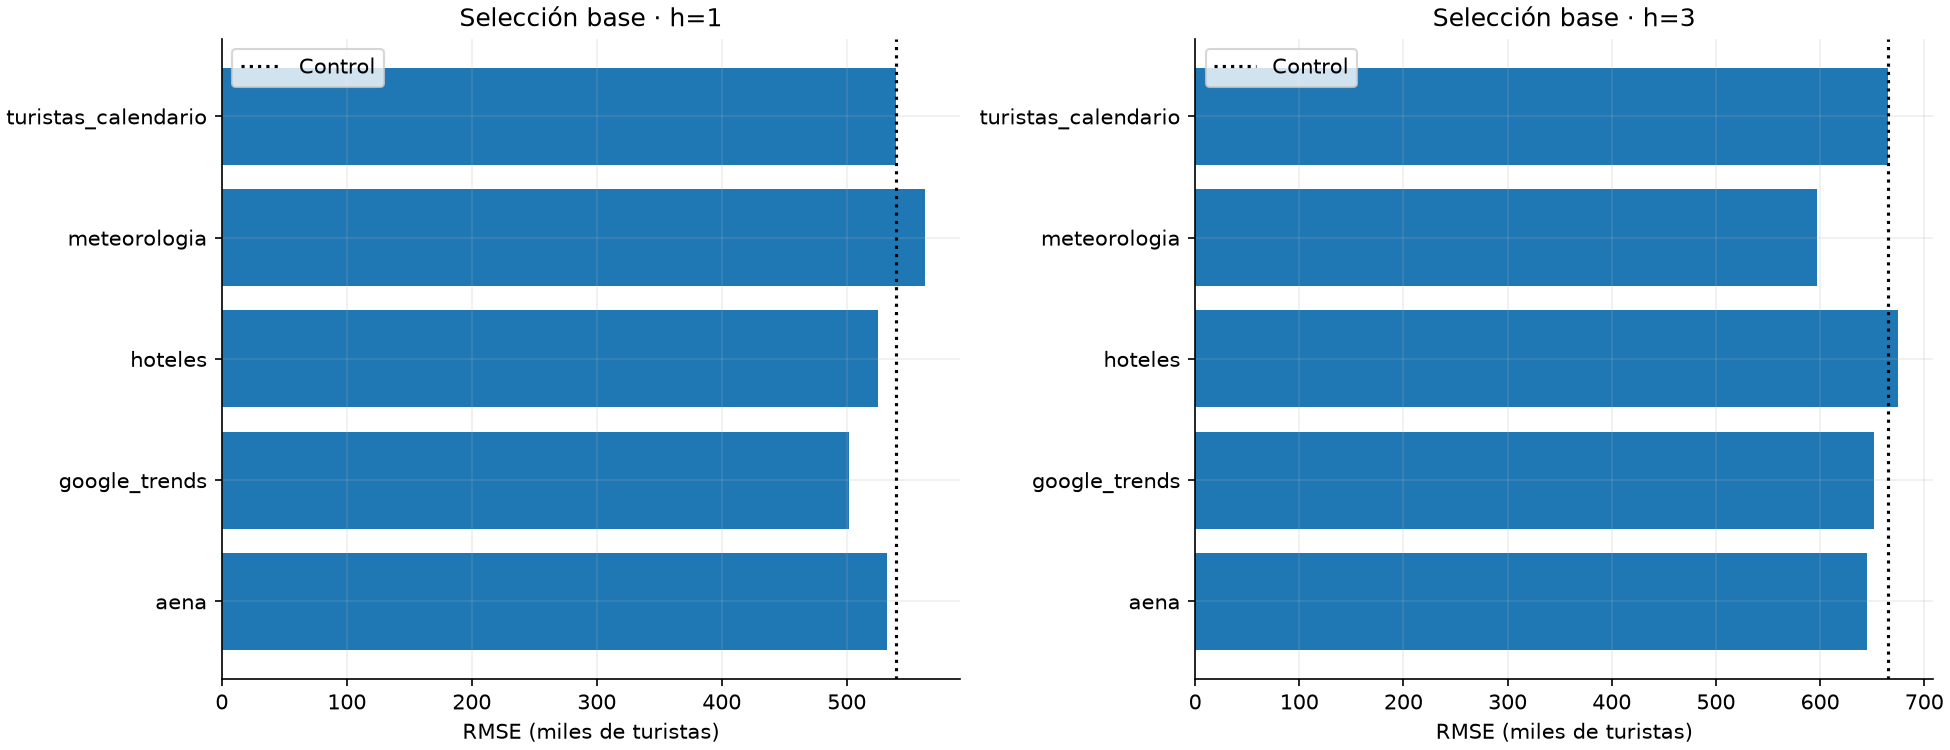

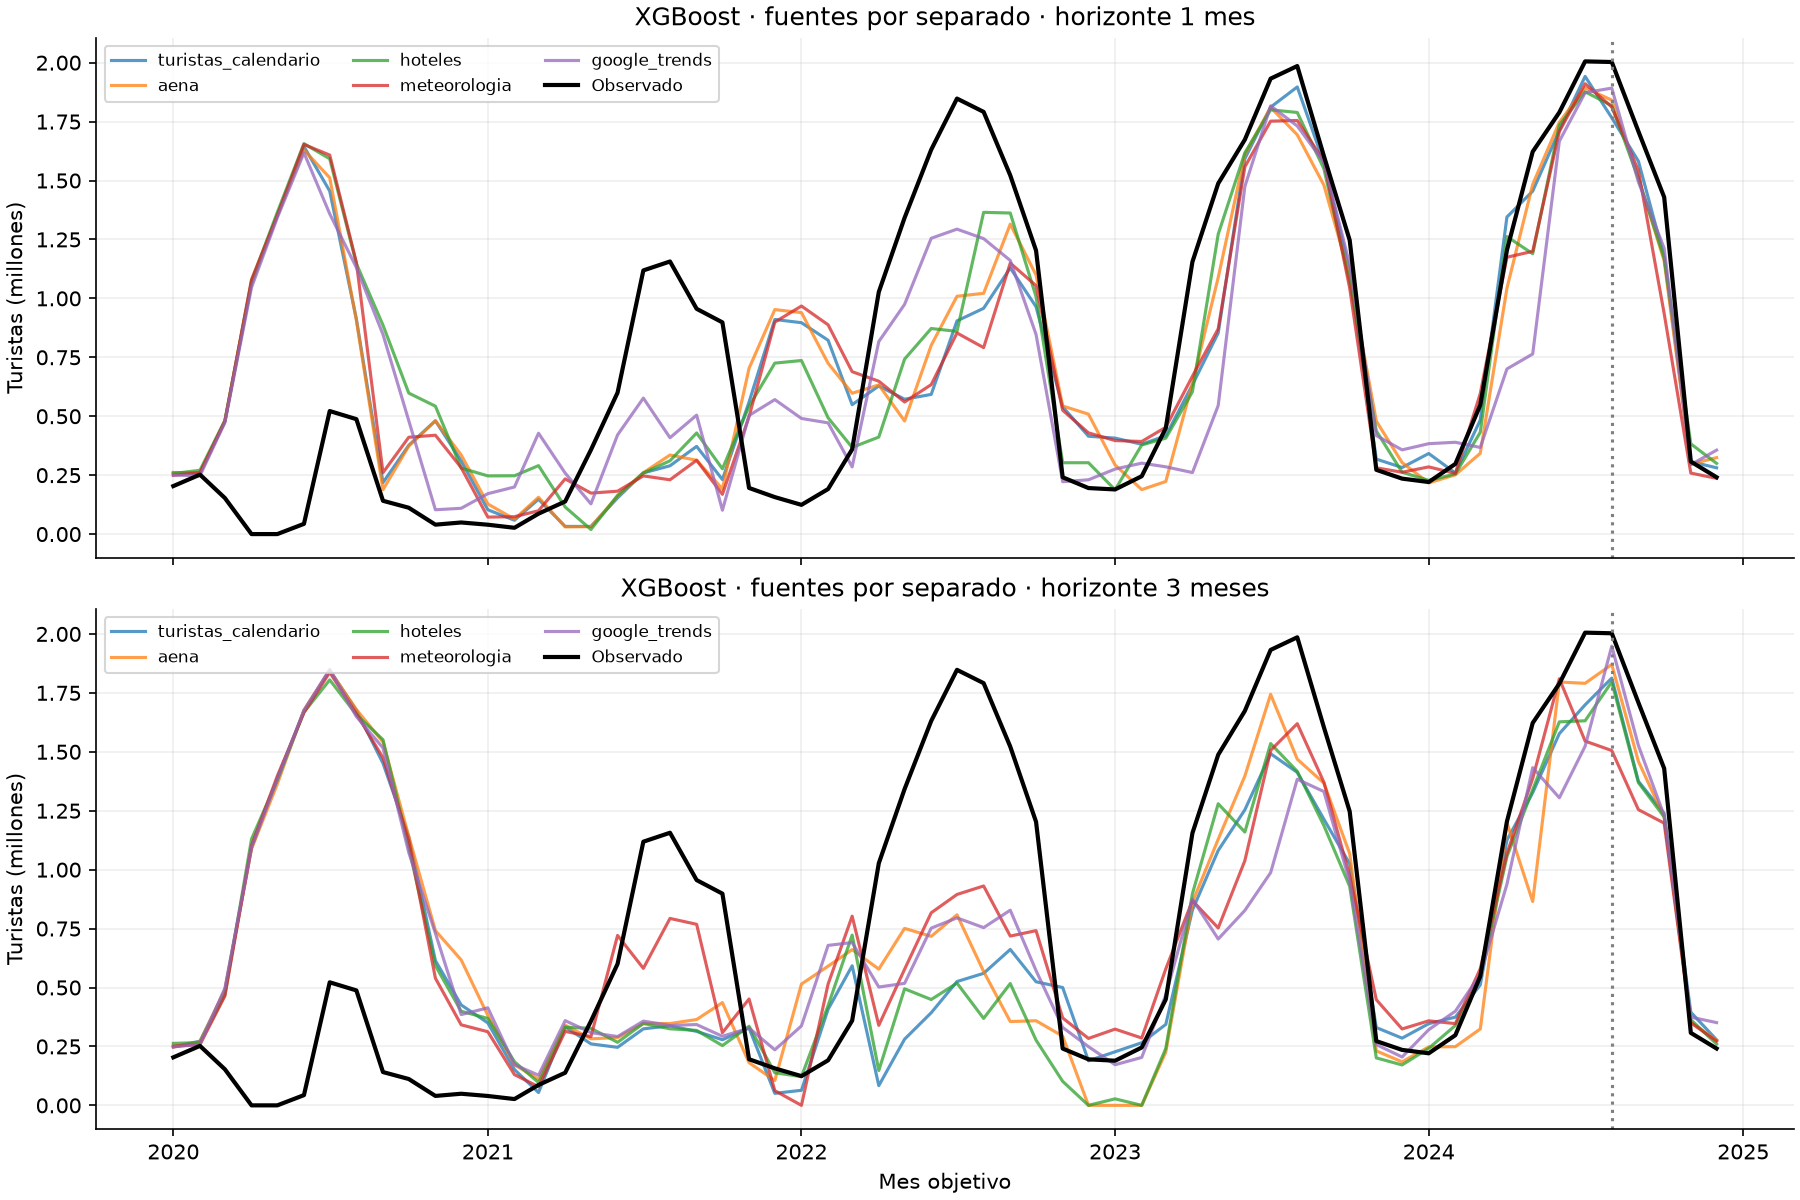
